# ВКР, часть 2: итоговый пайплайн классификации

Три сценария: базовый набор признаков; признаки кластеризации, редкости и аномальности; разделение выборки по единицам измерения. В конце расчёт экономического эффекта.


In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, shapiro, normaltest, skew, kurtosis, jarque_bera, anderson
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelBinarizer, PowerTransformer, OrdinalEncoder, LabelEncoder
from sklearn.cluster import DBSCAN
from sklearn.metrics import (silhouette_score, 
                             classification_report, 
                             confusion_matrix, 
                             f1_score, 
                             precision_score, 
                             recall_score, 
                             accuracy_score,
                             roc_auc_score,
                             calinski_harabasz_score,
                             davies_bouldin_score,
                             adjusted_rand_score,
                             normalized_mutual_info_score,
                             pairwise_distances)
import gower
import hdbscan
from sklearn.decomposition import PCA
import plotly.express as px
import plotly.graph_objects as go
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_predict, StratifiedKFold, ParameterGrid, KFold
from imblearn.over_sampling import RandomOverSampler
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier,
                              GradientBoostingClassifier,
                              AdaBoostClassifier,
                              IsolationForest,
                              HistGradientBoostingClassifier,
                              ExtraTreesClassifier)
from catboost import CatBoostClassifier
from collections import Counter
from tqdm import tqdm
import networkx as nx
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.pipeline import Pipeline
import time
from ctgan import CTGAN
from sklearn.base import BaseEstimator
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from hdbscan import approximate_predict
import itertools
from itertools import product
from sklearn.inspection import permutation_importance
from category_encoders import BinaryEncoder, CountEncoder, CatBoostEncoder
from scipy.spatial.distance import pdist, squareform
from sklearn.feature_selection import mutual_info_regression, mutual_info_classif, f_classif
from scikeras.wrappers import KerasClassifier
from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier
import shap
import os
from matplotlib.ticker import FuncFormatter

In [3]:
# исходный датасет конфиденциален и в репозиторий не включён
df = pd.read_excel('data/data.xlsx', sheet_name='data')
df.head()

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12659 entries, 0 to 12658
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Регион        12659 non-null  object 
 1   Организация   12659 non-null  object 
 2   Родитель      12659 non-null  object 
 3   Наименование  12659 non-null  object 
 4   Свойство      12659 non-null  object 
 5   ед. изм.      12659 non-null  object 
 6   Лет           12659 non-null  int64  
 7   Стоимость     12659 non-null  float64
 8   Значение      11030 non-null  float64
dtypes: float64(2), int64(1), object(6)
memory usage: 890.2+ KB


# Предобработка

In [5]:
df.columns = df.columns.str.strip()

Думаю стоит начать с засекречивания конфиденциальной информации, о чем меня и просили руководители. Среди преобразований в эксель можно выделить - создание признака "Лет", так как с этой информацией легче работать в дальнейшем. Также стоимость основных средств была умножена на коэффициент, что не поменяет само распределние этого признака. Уже в самом пайтоне я решил создать признак "Федеральный округ", чтобы укрупнить признак "Регион", пока не уверен, что он мне понадобится для моделирования, но сейчас и не могу это проверить. Признаки "Федеральный округ", "Регион" и "Организация" были обезличены. Это существенно сужает именно экономический анализ, но без этого данные мне бы никто не предоставил.

> **Обезличивание.** Регионы сгруппированы в федеральные округа, затем регионы, округа и эксплуатирующие организации заменены условными кодами. Код обезличивания не публикуется.


In [11]:
df.head()

,Регион,Организация,Родитель,Наименование,Свойство,ед. изм.,Лет,Стоимость,Значение,Округ
0,Регион_35,Организация_14,Родитель_188,Система управления технологическими процессами...,количество точек подключения,шт,1,8.625357e+08,1.0,Округ_1
1,Регион_35,Организация_14,Родитель_190,Система управления технологическими процессами...,количество точек подключения,шт,1,4.181210e+08,NaN,Округ_1
2,Регион_2,Организация_14,Родитель_194,Система управления технологическими процессами...,количество точек подключения,шт,1,3.693608e+08,NaN,Округ_1
3,Регион_35,Организация_14,Родитель_190,Система управления энергоснабжением автоматизи...,количество контролируемых параметров,шт,1,4.423769e+07,NaN,Округ_1
4,Регион_35,Организация_14,Родитель_188,"Система пожарной сигнализации, контроля загазо...",количество точек мониторинга,шт,1,9.558990e+07,NaN,Округ_1


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12659 entries, 0 to 12658
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Регион        12659 non-null  object 
 1   Организация   12659 non-null  object 
 2   Родитель      12659 non-null  object 
 3   Наименование  12659 non-null  object 
 4   Свойство      12659 non-null  object 
 5   ед. изм.      12659 non-null  object 
 6   Лет           12659 non-null  int64  
 7   Стоимость     12659 non-null  float64
 8   Значение      11030 non-null  float64
 9   Округ         12659 non-null  object 
dtypes: float64(2), int64(1), object(7)
memory usage: 989.1+ KB


Видно, что датасет имеет 12659 наблюдений и 9 столбцов. Тип данных ненарушен, что меня сильно радует. На этом этапе заметно, что пропуски есть в столбце "Значение". Далее придется решить, что сделать с ними.

Хоть типы данных и не нарушены, но сами категориальные признаки проверить не будет лишним. Признак "Наименование" я проверил в экселе, так как тут не отображается полный массив. 

In [13]:
cat_cols = df.select_dtypes(include=["object", "category", "string"]).columns

for col in cat_cols:
    
    series = df[col]
    
    try:
        uniques = series.unique()
    except TypeError:
        uniques = series.apply(
            lambda x: tuple(x) if isinstance(x, list) else x
        ).unique()
    
    print(f"\n{col} ({len(uniques)} уникальных): {uniques}")


Регион (50 уникальных): ['Регион_35' 'Регион_2' 'Регион_23' 'Регион_14' 'Регион_48' 'Регион_17'
 'Регион_34' 'Регион_5' 'Регион_46' 'Регион_13' 'Регион_8' 'Регион_29'
... (вывод сокращён: 353 строк) ...
 'объем огнетушащего вещества' 'производительность суточная (массовая)'
 'производительность годовая (объемная)' 'длина причального фронта'
 'площадь поверхности теплообмена' 'количество приемопередающих станций'
 'производительность']

ед. изм. (24 уникальных): ['шт' 'МВт (1000 кВт)' 'м3/ч' 'м2' 'кВ*А' 'м' 'м3' 'МБит/сек' 'Вт/м' 'мм'
 'кВт' '1000 м3/ч' 'кВ' 'Гкал/ч' 'маш./сут' 'кг' 'м3/сут' 'л/с'
 '1 000 000 м3/сут' 'л/ч' 'т/ч' 'т/сут' '1 000 000 000 м3/г' 'кг/ч']

Округ (9 уникальных): ['Округ_1' 'Округ_6' 'Округ_9' 'Округ_7' 'Округ_4' 'Округ_3' 'Округ_8'
 'Округ_5' 'Округ_2']


Как видно ниже, пропуски в столбце "Значение" составляют 12,87% от всего датасета. Считаю, что на данном этапе избыточно заполнять пропуски через модель, а в тупую заполнить их средним или даже медианой неправильно. Поэтому я решил заполнить пропуски через группировку по самым важным признакам, которые как раз и отображают структуру значений. В качестве таких признаков я выбрал - "Свойство", "Эксплуатирующую организацию", "Регион" и "Федеральный округ".

In [14]:
df.isna().sum()

Регион             0
Организация        0
Родитель           0
Наименование       0
Свойство           0
ед. изм.           0
Лет                0
Стоимость          0
Значение        1629
Округ              0
dtype: int64

In [15]:
round(df['Значение'].isna().sum() / df.shape[0] * 100, 2)

12.87

In [16]:
def fill_by_group_median(df):

    df = df.copy()

    df["Значение"] = df["Значение"].fillna(
        df.groupby(
            ["Свойство", "ед. изм.", "Организация", "Регион", "Округ"]
        )["Значение"].transform("median")
    )

    df["Значение"] = df["Значение"].fillna(
        df.groupby(
            ["Свойство", "ед. изм.", "Организация", "Регион"]
        )["Значение"].transform("median")
    )
    
    df["Значение"] = df["Значение"].fillna(
        df.groupby(
            ["Свойство", "ед. изм.", "Организация"]
        )["Значение"].transform("median")
    )

    df["Значение"] = df["Значение"].fillna(
        df.groupby(
            ["Свойство", "ед. изм."]
        )["Значение"].transform("median")
    )
    
    df["Значение"] = df["Значение"].fillna(
        df.groupby(
            ["Свойство"]
        )["Значение"].transform("median")
    )

    return df

После заполнения через группировку остался только 51 пропуск, что составляет несчастные 0,4% от датасета. Их я уже не могу заполнить, так как это как раз те основные свойства, которые не получилось заполнить в течение проекта. Само заполнение происходило через описание характеристик основного средства. К сожалению, бухгалтеры, которые заполняют эти характеристики, не знают, какая информация в дальнейшем точно понадобится остальным подразделениям. Этот 51 пропуск я смело удалил.

In [17]:
df = fill_by_group_median(df)

In [18]:
df.isna().sum()

Регион           0
Организация      0
Родитель         0
Наименование     0
Свойство         0
ед. изм.         0
Лет              0
Стоимость        0
Значение        51
Округ            0
dtype: int64

In [19]:
round(df['Значение'].isna().sum() / df.shape[0] * 100, 2)

0.4

In [20]:
df[df['Значение'].isna()]

,Регион,Организация,Родитель,Наименование,Свойство,ед. изм.,Лет,Стоимость,Значение,Округ
2429,Регион_35,Организация_14,Родитель_189,Установка пожаротушения газового,расчетное количество огнетушащего вещества,кг,4,8.715102e+06,NaN,Округ_1
2430,Регион_35,Организация_14,Родитель_191,Установка пожаротушения газового,расчетное количество огнетушащего вещества,кг,4,6.947068e+06,NaN,Округ_1
2431,Регион_2,Организация_14,Родитель_193,Установка пожаротушения газового,расчетное количество огнетушащего вещества,кг,4,6.896347e+06,NaN,Округ_1
2572,Регион_49,Организация_18,Родитель_118,Сети связи и радиофикации,количество радиоканалов,шт,4,3.738133e+05,NaN,Округ_7
2574,Регион_49,Организация_18,Родитель_118,Установка пожаротушения газового,расчетное количество огнетушащего вещества,кг,4,6.297894e+05,NaN,Округ_7
2792,Регион_5,Организация_16,Родитель_165,Установка пожаротушения газового,расчетное количество огнетушащего вещества,кг,5,4.185682e+07,NaN,Округ_9
3638,Регион_21,Организация_10,Родитель_156,Установка пожаротушения газового,расчетное количество огнетушащего вещества,кг,7,2.566848e+06,NaN,Округ_4
3965,Регион_37,Организация_6,Родитель_185,Установка пожаротушения газового,расчетное количество огнетушащего вещества,кг,9,1.035320e+08,NaN,Округ_9
4650,Регион_33,Организация_16,Родитель_136,Система контроля и управления доступом,количество защищаемых помещений,шт,9,3.006007e+05,NaN,Округ_4
4651,Регион_37,Организация_6,Родитель_185,Система контроля и управления доступом,количество защищаемых помещений,шт,9,3.257691e+07,NaN,Округ_9


In [21]:
df = df.dropna()

In [22]:
df.isna().sum()

Регион          0
Организация     0
Родитель        0
Наименование    0
Свойство        0
ед. изм.        0
Лет             0
Стоимость       0
Значение        0
Округ           0
dtype: int64

На первый взгляд может показаться, что в датасете целый 461 дубликат, но на самом деле это не так. Каждое основное средство имеет свой инвентарный номер, которые мне пришлось удалить из-за конфиденциональности.  Сами инвентарные номера я проверил, среди них дубликатов не было обнаружено.

In [23]:
df.duplicated().sum()

459

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12608 entries, 0 to 12658
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Регион        12608 non-null  object 
 1   Организация   12608 non-null  object 
 2   Родитель      12608 non-null  object 
 3   Наименование  12608 non-null  object 
 4   Свойство      12608 non-null  object 
 5   ед. изм.      12608 non-null  object 
 6   Лет           12608 non-null  int64  
 7   Стоимость     12608 non-null  float64
 8   Значение      12608 non-null  float64
 9   Округ         12608 non-null  object 
dtypes: float64(2), int64(1), object(7)
memory usage: 1.1+ MB


In [25]:
df.shape

(12608, 10)

In [26]:
df['Наименование'].nunique()

379

In [27]:
df['Наименование'].value_counts().reset_index()

,Наименование,count
0,Площадка производственная,635
1,Мачта прожекторная с молниеотводом,612
2,Подъездная автодорога,494
3,Установка газотурбинных агрегатов,440
4,Сети канализации внутриплощадочные,401
...,...,...
374,Сооружение гражданской обороны защитное,1
375,Трубопровод отпарного газа,1
376,Склад хранения конденсата газового стабильного,1
377,Здание станции насосной ШФЛУ,1


In [28]:
df[df['Наименование'] == 'Площадка производственная'].head()

,Регион,Организация,Родитель,Наименование,Свойство,ед. изм.,Лет,Стоимость,Значение,Округ
165,Регион_35,Организация_14,Родитель_190,Площадка производственная,площадь общая,м2,1,5.006241e+07,6927.4,Округ_1
166,Регион_35,Организация_14,Родитель_188,Площадка производственная,площадь общая,м2,1,6.264951e+08,49390.6,Округ_1
167,Регион_35,Организация_14,Родитель_190,Площадка производственная,площадь общая,м2,1,2.135553e+09,53279.8,Округ_1
168,Регион_2,Организация_14,Родитель_194,Площадка производственная,площадь общая,м2,1,2.581099e+09,50471.9,Округ_1
169,Регион_35,Организация_14,Родитель_190,Площадка производственная,площадь общая,м2,1,2.142006e+09,75880.7,Округ_1


In [29]:
df[df['Наименование'] == 'Подъездная автодорога'].head()

,Регион,Организация,Родитель,Наименование,Свойство,ед. изм.,Лет,Стоимость,Значение,Округ
183,Регион_35,Организация_14,Родитель_190,Подъездная автодорога,протяженность,м,1,7.035615e+08,1634.0,Округ_1
184,Регион_35,Организация_14,Родитель_190,Подъездная автодорога,протяженность,м,1,8.769837e+08,1351.0,Округ_1
292,Регион_34,Организация_8,Родитель_13,Подъездная автодорога,протяженность,м,1,1.799930e+07,355.0,Округ_3
293,Регион_34,Организация_8,Родитель_13,Подъездная автодорога,протяженность,м,1,4.612275e+07,403.0,Округ_3
316,Регион_17,Организация_10,Родитель_56,Подъездная автодорога,протяженность,м,1,1.205048e+07,1824.0,Округ_4


In [36]:
df[df['Наименование'] == 'Объектовая охранная сигнализация'].head()

,Регион,Организация,Родитель,Наименование,Свойство,ед. изм.,Лет,Стоимость,Значение,Округ
120,Регион_35,Организация_14,Родитель_190,Объектовая охранная сигнализация,количество точек мониторинга,шт,1,2.721367e+07,279.0,Округ_1
121,Регион_35,Организация_14,Родитель_188,Объектовая охранная сигнализация,количество точек мониторинга,шт,1,2.151801e+08,279.0,Округ_1
122,Регион_35,Организация_14,Родитель_190,Объектовая охранная сигнализация,количество точек мониторинга,шт,1,5.940134e+08,279.0,Округ_1
123,Регион_2,Организация_14,Родитель_194,Объектовая охранная сигнализация,количество точек мониторинга,шт,1,5.763902e+08,279.0,Округ_1
124,Регион_35,Организация_14,Родитель_190,Объектовая охранная сигнализация,количество точек мониторинга,шт,1,7.448152e+08,279.0,Округ_1


In [37]:
df[df['Наименование'] == 'Установка газораспределительная'].head()

,Регион,Организация,Родитель,Наименование,Свойство,ед. изм.,Лет,Стоимость,Значение,Округ
311,Регион_34,Организация_8,Родитель_13,Установка газораспределительная,пропускная способность (объемная),1000 м3/ч,1,1.378785e+08,10.00,Округ_3
338,Регион_17,Организация_10,Родитель_56,Установка газораспределительная,пропускная способность (объемная),1000 м3/ч,1,1.013231e+08,2.00,Округ_4
373,Регион_5,Организация_16,Родитель_18,Установка газораспределительная,пропускная способность (объемная),1000 м3/ч,1,4.526062e+08,50.00,Округ_9
399,Регион_48,Организация_18,Родитель_84,Установка газораспределительная,пропускная способность (объемная),1000 м3/ч,1,1.435758e+08,5.00,Округ_7
416,Регион_2,Организация_14,Родитель_34,Установка газораспределительная,пропускная способность (объемная),1000 м3/ч,1,8.997995e+07,1.05,Округ_1


In [32]:
df[df['Наименование'] == 'Установка очистки газа'].head()

,Регион,Организация,Родитель,Наименование,Свойство,ед. изм.,Лет,Стоимость,Значение,Округ
263,Регион_35,Организация_14,Родитель_188,Установка очистки газа,производительность (объемная),м3/ч,1,7.059885e+08,16.666667,Округ_1
264,Регион_35,Организация_14,Родитель_190,Установка очистки газа,производительность (объемная),м3/ч,1,7.598487e+08,16.666667,Округ_1
265,Регион_2,Организация_14,Родитель_194,Установка очистки газа,производительность (объемная),м3/ч,1,6.159381e+08,620833.333333,Округ_1
781,Регион_35,Организация_14,Родитель_191,Установка очистки газа,производительность (объемная),м3/ч,2,7.705709e+08,641666.666667,Округ_1
782,Регион_35,Организация_14,Родитель_192,Установка очистки газа,производительность (объемная),м3/ч,2,8.151013e+08,16.666667,Округ_1


In [33]:
df[df['Наименование'] == 'Склад материально-технических ценностей'].head()

,Регион,Организация,Родитель,Наименование,Свойство,ед. изм.,Лет,Стоимость,Значение,Округ
3354,Регион_28,Организация_6,Родитель_152,Склад материально-технических ценностей,вместимость суммарная,м3,7,3.513975e+07,2328.1,Округ_9
3514,Регион_28,Организация_6,Родитель_152,Склад материально-технических ценностей,вместимость суммарная,м3,7,3.578322e+07,582.6,Округ_9
3642,Регион_21,Организация_10,Родитель_156,Склад материально-технических ценностей,вместимость суммарная,м3,7,2.747367e+07,441.6,Округ_4
5172,Регион_43,Организация_12,Родитель_137,Склад материально-технических ценностей,вместимость суммарная,м3,10,3.823294e+07,568.5,Округ_5
6075,Регион_14,Организация_6,Родитель_144,Склад материально-технических ценностей,вместимость суммарная,м3,11,5.876458e+07,5336.4,Округ_9


In [41]:
df[df['Наименование'] == 'Система связи совещаний'].head()

,Регион,Организация,Родитель,Наименование,Свойство,ед. изм.,Лет,Стоимость,Значение,Округ
6693,Регион_33,Организация_16,Родитель_159,Система связи совещаний,количество точек подключения,шт,11,1.210627e+06,2.0,Округ_4
6694,Регион_3,Организация_16,Родитель_164,Система связи совещаний,количество точек подключения,шт,11,9.509416e+05,3.0,Округ_4
6695,Регион_33,Организация_16,Родитель_153,Система связи совещаний,количество точек подключения,шт,11,1.587876e+05,2.0,Округ_4
6696,Регион_33,Организация_16,Родитель_153,Система связи совещаний,количество точек подключения,шт,11,1.569355e+05,4.0,Округ_4
7005,Регион_6,Организация_16,Родитель_165,Система связи совещаний,количество точек подключения,шт,11,1.299815e+06,3.0,Округ_4


In [42]:
df[df['Наименование'] == 'Водовод магистральный'].head()

,Регион,Организация,Родитель,Наименование,Свойство,ед. изм.,Лет,Стоимость,Значение,Округ
12641,Регион_28,Организация_6,Родитель_152,Водовод магистральный,протяженность,м,58,5.299037e+06,844.0,Округ_9


# Исследовательский анализ данных

Первое, что меня заинтересовало, это география в данных. Жаль, что данные закодированы и нельзя привнести экономический смысл в этот анализ. Сперва мне хотелось вывести топы по доле наблюдений по Федеральным округам, Регионам и Эксплуатирующим организациям. Также последние два признака я группировал по Федеральным округам для укрупнения.

In [30]:
fo_counts = df['Округ'].value_counts().reset_index()
fo_counts.columns = ['Округ', 'Количество']

total = len(df)
fo_counts['Процент'] = (fo_counts['Количество'] / total * 100).round(2)

fo_counts

,Округ,Количество,Процент
0,Округ_4,4188,33.22
1,Округ_9,1998,15.85
2,Округ_1,1970,15.62
3,Округ_7,1497,11.87
4,Округ_8,933,7.40
5,Округ_3,854,6.77
6,Округ_6,563,4.47
7,Округ_5,304,2.41
8,Округ_2,301,2.39


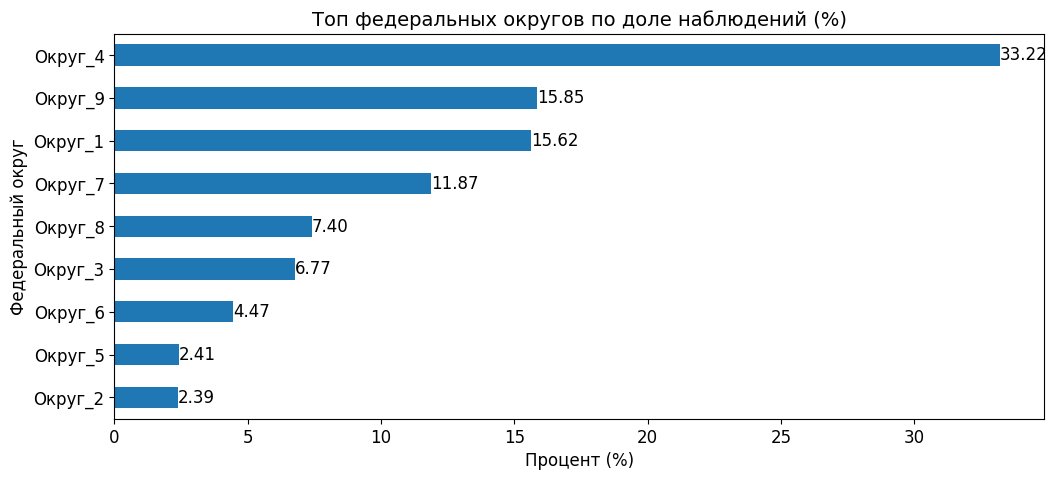

In [31]:
plt.figure(figsize=(12, 5))

ax = (
    df['Округ']
    .value_counts(normalize=True)
    .mul(100)
    .sort_values(ascending=True)
    .plot(
        kind='barh',
        title='Доля наблюдений по Федеральным округам (%)'
    )
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    fontsize=12
)

plt.xlabel("Процент (%)", fontsize=12)
plt.ylabel("Федеральный округ", fontsize=12)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.title(
    'Топ федеральных округов по доле наблюдений (%)',
    fontsize=14
)

plt.show()

Видно, что абсолютный лидер - Округ 4, он занимает треть всего датасета (33,22%). Например, второе и третье место в сумме не даеют такую долю, про остальные округи можно промолчать. Думаю, что Округ 4 - это какой-то крупный газовый кластер. После него следуют Округи в следующем порядке - 9 (15,85%), 1 (15,62%), 7 (11,87%), 8 (7,40%), 3 (6,77%), 6 (4,47%), 5 (2,41%) и 2 (2,39%).

In [32]:
region_counts = df['Регион'].value_counts().reset_index()
region_counts.columns = ['Регион', 'Количество']

region_counts['Процент'] = (region_counts['Количество'] / total * 100).round(2)

region_counts.head(10)

,Регион,Количество,Процент
0,Регион_33,2498,19.81
1,Регион_35,1209,9.59
2,Регион_49,1184,9.39
3,Регион_14,850,6.74
4,Регион_6,701,5.56
5,Регион_5,686,5.44
6,Регион_2,559,4.43
7,Регион_37,361,2.86
8,Регион_39,354,2.81
9,Регион_17,345,2.74


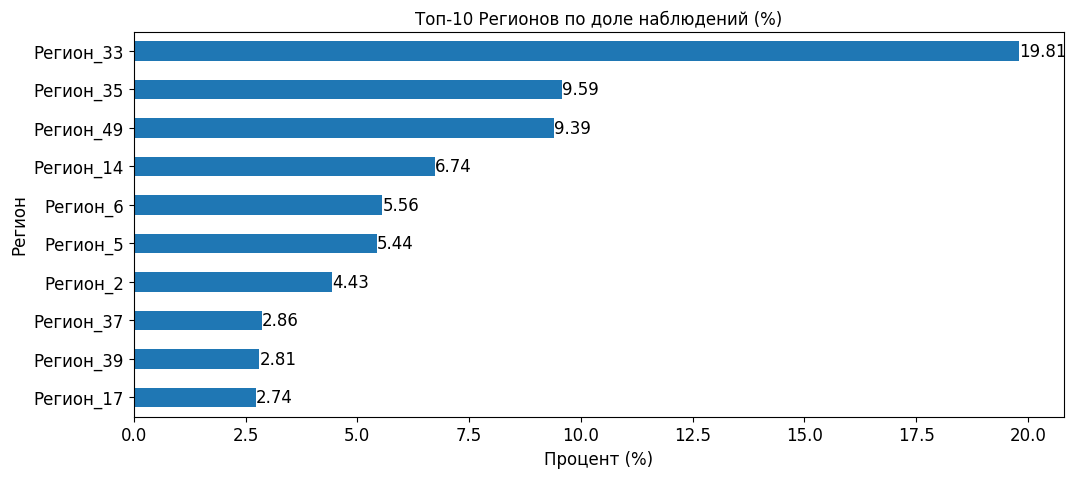

In [33]:
plt.figure(figsize=(12, 5))

ax = (
    df['Регион']
    .value_counts(normalize=True)
    .mul(100)
    .sort_values(ascending=True)
    .tail(10)
    .plot(kind='barh', title='Топ-10 Регионов по доле наблюдений (%)', fontsize=14)
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    fontsize=12
)

plt.xlabel("Процент (%)", fontsize=12)
plt.ylabel("Регион", fontsize=12)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.show()

Похожая ситуация наблюдается и среди Регионов. Лидер среди Регионов - Регион 33 (19,81%). Только на этот раз второе и третье место в сумме хотя бы могут немного обогнать его. Разница между остальными Регионами по доле уже не такая большая. После Региона 33 идут 35 (9,59%), 49 (9,39%), 14 (6,74%), 6 (5,56%), 5 (5,44%), 2 (4,43%), 37 (2,86%), 39 (2,81%), 17 (2,74%).

In [34]:
counts = (
    df.groupby(["Округ", "Регион"])
      .size()
      .reset_index(name="Количество")
)

total = len(df)

counts["Процент"] = (counts["Количество"] / total) * 100
counts["Процент"] = counts["Процент"].round(2)

counts = counts.sort_values("Процент", ascending=False)
counts.head(10)

,Округ,Регион,Количество,Процент
19,Округ_4,Регион_33,2498,19.81
2,Округ_1,Регион_35,1209,9.59
32,Округ_7,Регион_49,1184,9.39
45,Округ_9,Регион_14,850,6.74
20,Округ_4,Регион_6,701,5.56
49,Округ_9,Регион_5,686,5.44
0,Округ_1,Регион_2,559,4.43
48,Округ_9,Регион_37,361,2.86
12,Округ_3,Регион_39,354,2.81
14,Округ_4,Регион_17,345,2.74


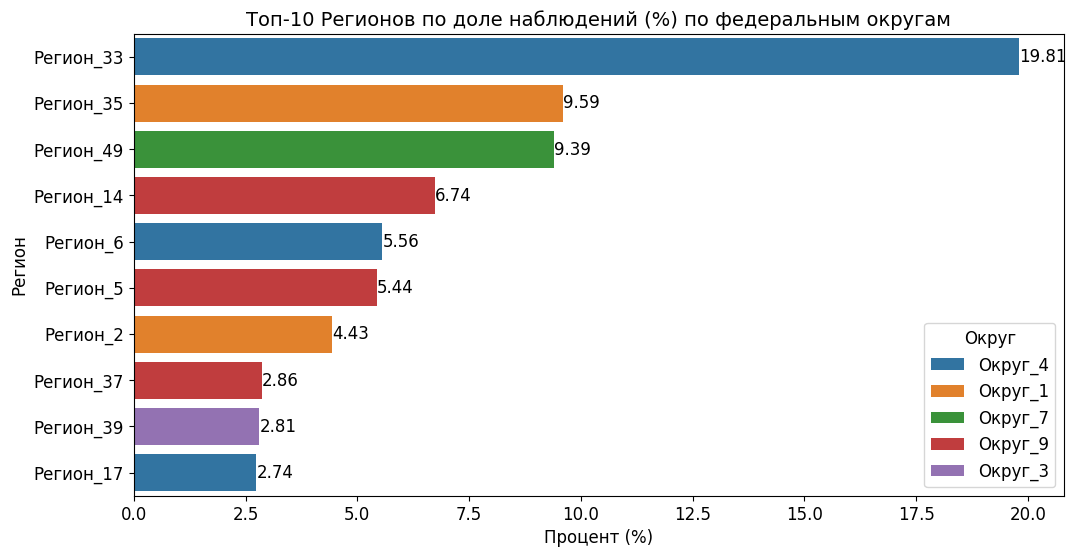

In [35]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=counts.head(10),
    x="Процент",
    y="Регион",
    hue="Округ",
    dodge=False
)

for container in ax.containers:
    ax.bar_label(
    container,
    fmt="%.2f",
    fontsize=12
)

plt.xlabel("Процент (%)", fontsize=12)
plt.ylabel("Регион", fontsize=12)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.legend(
    title="Округ",
    fontsize=12,
    title_fontsize=12
)

plt.title("Топ-10 Регионов по доле наблюдений (%) по федеральным округам", fontsize=14)
plt.show()

Теперь понятно, чем вызван такой отрыв Округа 4 от остальных (в него входит абсолютный топ 1 - Регион 33, также Регионы 6 и 17). Также в топе Регионы 35, 37 и 2 (Округ 1), 14 и 2 (Округ 1), Регион 49 (округ 7) и Регион 39 (Округ 3).

In [36]:
total = len(df)

org_counts = df['Организация'].value_counts().reset_index()
org_counts.columns = ['Организация', 'Количество']

org_counts['Процент'] = (org_counts['Количество'] / total * 100).round(2)

org_counts.head(10)

,Организация,Количество,Процент
0,Организация_16,4568,36.23
1,Организация_14,2533,20.09
2,Организация_6,1199,9.51
3,Организация_10,788,6.25
4,Организация_3,542,4.30
5,Организация_13,478,3.79
6,Организация_8,440,3.49
7,Организация_12,405,3.21
8,Организация_7,404,3.20
9,Организация_11,354,2.81


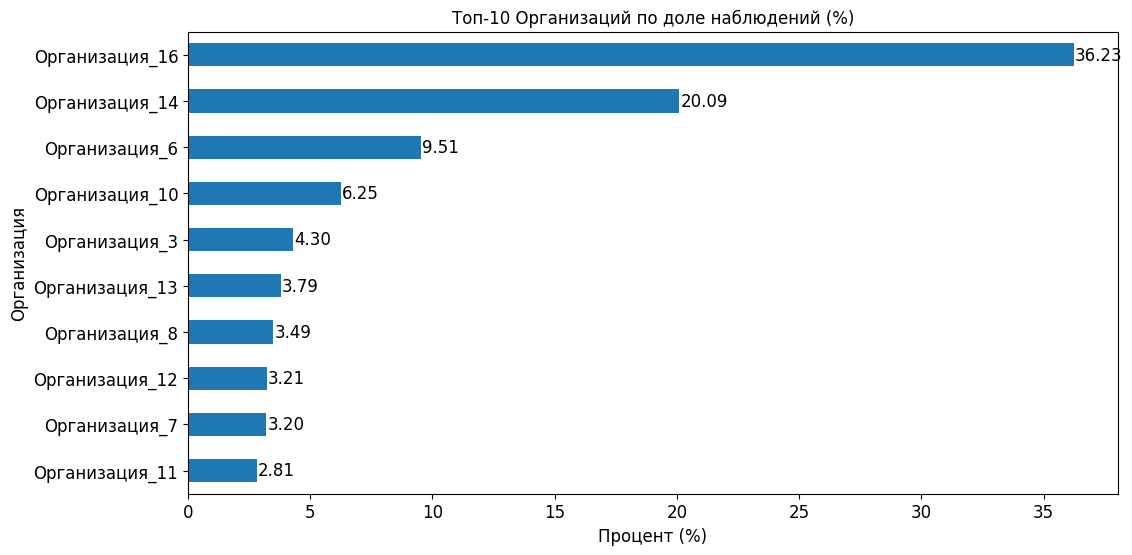

In [37]:
plt.figure(figsize=(12,6))

ax = (
    df['Организация']
    .value_counts(normalize=True)
    .mul(100)
    .sort_values(ascending=True)
    .tail(10)
    .plot(
        kind='barh',
        title='Топ-10 Организаций по доле наблюдений (%)', fontsize=14,
        legend=False
    )
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=1,
    fontsize=12
)

plt.xlabel("Процент (%)", fontsize=12)
plt.ylabel("Организация", fontsize=12)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.show()

По Организациям наблюдаем похожую картину, есть абсолютный лидер - Огранизация 16 (36,23%). Только теперь второе и третье место не идут вровень. Начиная с 4 места разница между организациями еще вовсе небольшая. После Организации 16 следуют 14 (20,09%), 6 (9,51%), 10 (6,25%), 3 (4,3%), 13 (3,79%), 8 (3,49%), 12 (3,21%), 7 (3,20%) и 11 (2,81%).

In [38]:
counts_org = (
    df.groupby(["Округ", "Организация"])
      .size()
      .reset_index(name="Количество")
)

total = len(df)
counts_org["Процент"] = (counts_org["Количество"] / total) * 100
counts_org["Процент"] = counts_org["Процент"].round(2)

counts_org = counts_org.sort_values("Процент", ascending=False)

counts_org.head(10)

,Округ,Организация,Количество,Процент
9,Округ_4,Организация_16,3483,27.63
0,Округ_1,Организация_14,1970,15.62
24,Округ_9,Организация_6,1199,9.51
8,Округ_4,Организация_10,705,5.59
14,Округ_7,Организация_16,668,5.30
11,Округ_6,Организация_14,563,4.47
23,Округ_9,Организация_3,542,4.30
13,Округ_7,Организация_13,478,3.79
19,Округ_8,Организация_7,404,3.20
2,Округ_3,Организация_11,354,2.81


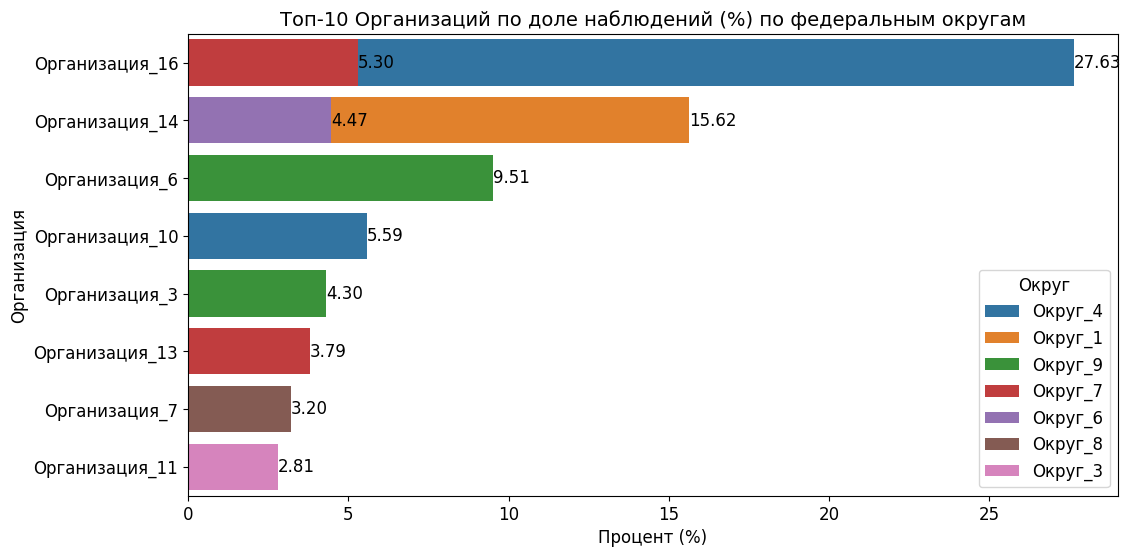

In [39]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=counts_org.head(10),
    x="Процент",
    y="Организация",
    hue="Округ",
    dodge=False
)

for container in ax.containers:
    ax.bar_label(
    container,
    fmt="%.2f",
    fontsize=12
)

plt.xlabel("Процент (%)", fontsize=12)
plt.ylabel("Организация", fontsize=12)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.legend(
    title="Округ",
    fontsize=12,
    title_fontsize=12
)

plt.title("Топ-10 Организаций по доле наблюдений (%) по федеральным округам", fontsize=14)
plt.show()

При укрупнении по Федеральным округам такая же картина. Абсолютный лидер Организация 16 задействована в Округе 4 и не только. Интересно, что первые 2 организации сосредоточены в нескольких округах. Лидеры среди округов входят Организации 16 и 10 (Округ 4), Организации 6 и 3 (Округ 9), Организация 14 (Округ 1), Организации 16, 13 и 18 (Округ 7), остальные более малочисленные для описания.

In [40]:
counts_name = (
    df.groupby("Наименование")
      .size()
      .reset_index(name="Количество")
)

total = len(df)
counts_name["Процент"] = (counts_name["Количество"] / total) * 100
counts_name["Процент"] = counts_name["Процент"].round(2)

top_name = counts_name.sort_values("Процент", ascending=False).head(10)
top_name

,Наименование,Количество,Процент
168,Площадка производственная,635,5.04
149,Мачта прожекторная с молниеотводом,612,4.85
178,Подъездная автодорога,494,3.92
295,Установка газотурбинных агрегатов,440,3.49
204,Сети канализации внутриплощадочные,401,3.18
142,Линия связи кабельная,350,2.78
138,Комплекс технических средств охраны,324,2.57
145,Линия электропередачи кабельная,317,2.51
144,Линия электропередачи воздушная,315,2.50
153,Объектовая охранная сигнализация,264,2.09


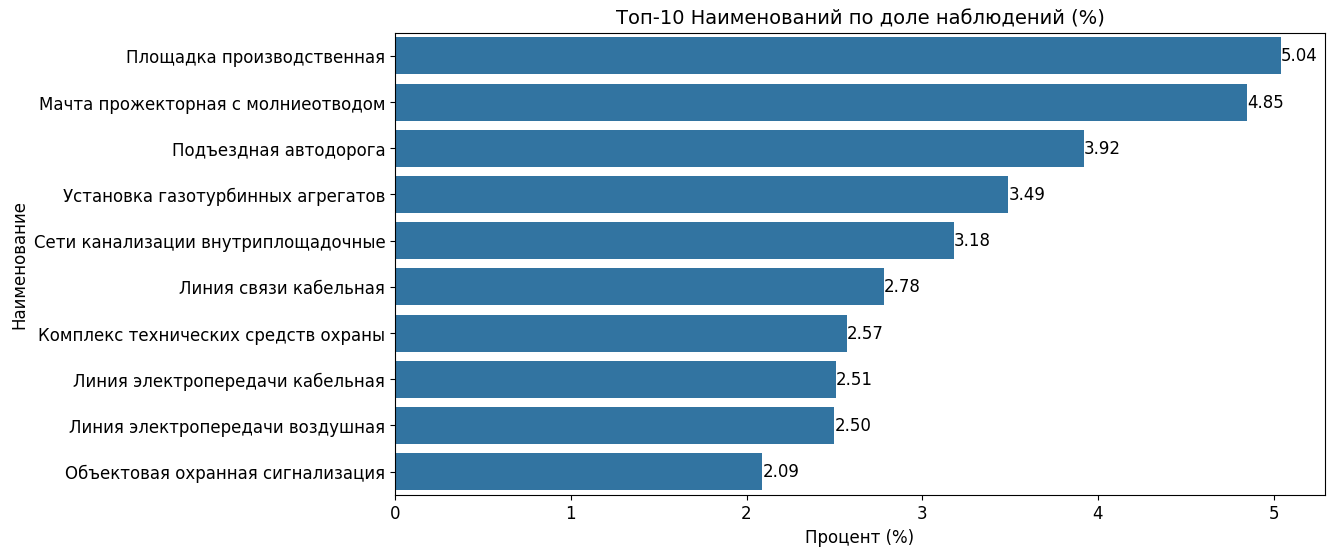

In [41]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_name.sort_values("Процент", ascending=False),
    x="Процент",
    y="Наименование",
    dodge=False
)

for container in ax.containers:
    ax.bar_label(
    container,
    fmt="%.2f",
    fontsize=12
)

plt.xlabel("Процент (%)", fontsize=12)
plt.ylabel("Наименование", fontsize=12)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.title("Топ-10 Наименований по доле наблюдений (%)", fontsize=14)
plt.show()

Видно, что в ранжировании Наименований нет абсолютного лидера. Все идет ровно - Наименования от 4 до 5, от 3 до 4, от 2 до 3 и меньше двух.

In [42]:
down_name = counts_name.sort_values("Процент", ascending=False).tail(10)

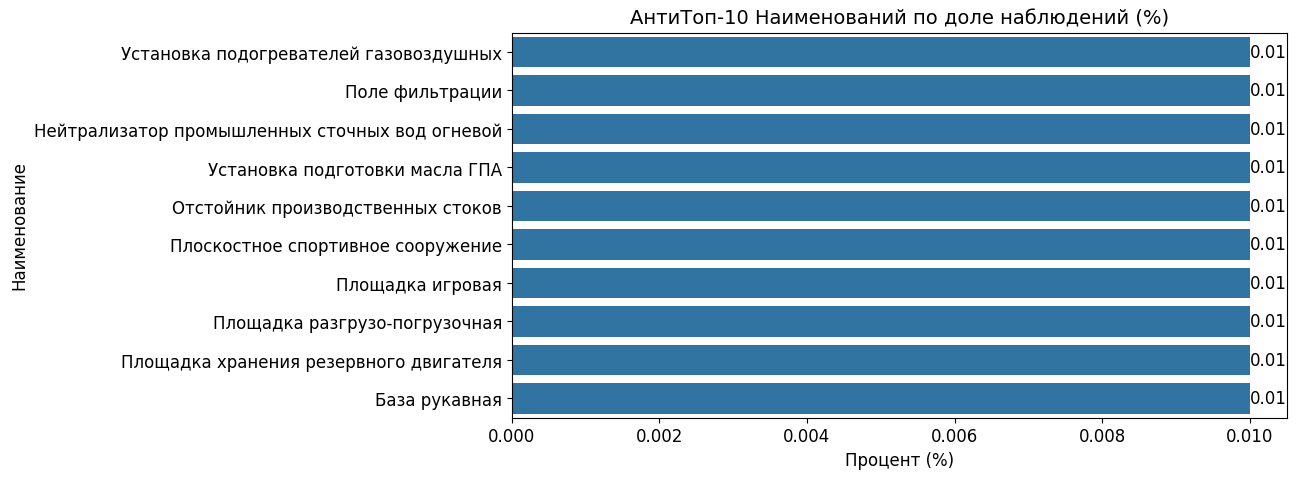

In [43]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=down_name.sort_values("Процент", ascending=False),
    x="Процент",
    y="Наименование",
    dodge=False
)

for container in ax.containers:
    ax.bar_label(
    container,
    fmt="%.2f",
    fontsize=12
)

plt.xlabel("Процент (%)", fontsize=12)
plt.ylabel("Наименование", fontsize=12)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.title("АнтиТоп-10 Наименований по доле наблюдений (%)", fontsize=14)
plt.show()

Больше меня смущает ситуация а антирейтингом. Последние 20 Наименований имеют меньше 0,01% (1 наблюдление). Это плохо скажется на дальнейшем моделировании. Такие случаи придется удалить, но тогда какой допустимый объем объектов?

In [44]:
counts_units = (
    df.groupby("ед. изм.")
      .size()
      .reset_index(name="Количество")
)

total = len(df)
counts_units["Процент"] = (counts_units["Количество"] / total) * 100
counts_units["Процент"] = counts_units["Процент"].round(2)

counts_units = counts_units.sort_values("Процент", ascending=False)

counts_units.head(10)

,ед. изм.,Количество,Процент
12,м,5357,42.49
13,м2,1887,14.97
21,шт,1414,11.22
16,м3/ч,1128,8.95
14,м3,846,6.71
8,кВ*А,705,5.59
6,МВт (1000 кВт),610,4.84
9,кВт,221,1.75
2,1000 м3/ч,168,1.33
7,кВ,65,0.52


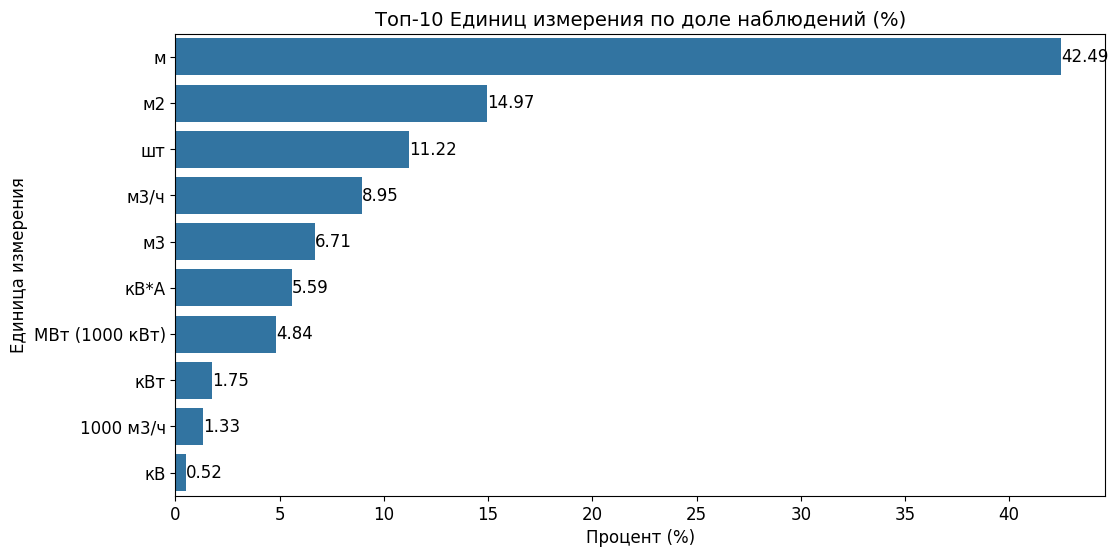

In [45]:
top15_units = counts_units.head(10).sort_values("Процент", ascending=False)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=top15_units,
    x="Процент",
    y="ед. изм."
)

for container in ax.containers:
    ax.bar_label(
    container,
    fmt="%.2f",
    fontsize=12
)

plt.xlabel("Процент (%)", fontsize=12)
plt.ylabel("Единица измерения", fontsize=12)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.title("Топ-10 Единиц измерения по доле наблюдений (%)", fontsize=14)
plt.show()

Вот пока самая неприятная ситуация в датасете, потому что я планировал создавать классу внутри единиц измерений. А как бы уже даже 5% от датасета - это 632 наблюдения. Единица измерения "м" занимает больше, чем места 2-5 в сумме (42,49%). Но радует, что тут есть уже хоть какой-то анализ. Видно, что на балансе организаций много разных протяженных основных средств - различные трубы, ограждения и линии электропередач, но это сугубо моя гипотеза. Больше, чем в 2,5 раза (14,97%) меньше помещений и зданий. Еще меньше основных средств которые можно посчитать (11,22%), оценить производительность (8,95%), объем (6,71%) и прочее. 

In [46]:
counts_units = (
    df.groupby(['Округ', "Родитель"])
      .size()
      .reset_index(name="Количество")
)

total = len(df)
counts_units["Процент"] = (counts_units["Количество"] / total) * 100
counts_units["Процент"] = counts_units["Процент"].round(2)

counts_units = counts_units.sort_values("Процент", ascending=False)

counts_units.head(10)

,Округ,Родитель,Количество,Процент
130,Округ_7,Родитель_187,361,2.86
71,Округ_4,Родитель_180,329,2.61
58,Округ_4,Родитель_143,328,2.60
73,Округ_4,Родитель_182,303,2.40
55,Округ_4,Родитель_136,302,2.40
54,Округ_4,Родитель_135,279,2.21
129,Округ_7,Родитель_174,276,2.19
5,Округ_1,Родитель_192,259,2.05
60,Округ_4,Родитель_153,254,2.01
3,Округ_1,Родитель_190,249,1.97


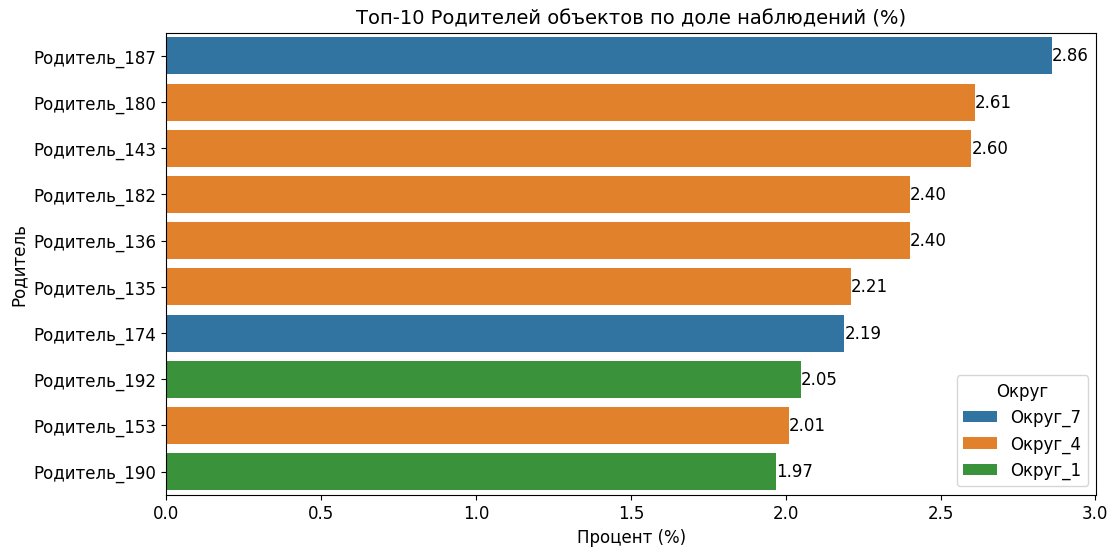

In [47]:
top10_units = counts_units.head(10).sort_values("Процент", ascending=False)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=top10_units,
    x="Процент",
    y="Родитель",
    hue="Округ"
)

for container in ax.containers:
    ax.bar_label(
    container,
    fmt="%.2f",
    fontsize=12
)

plt.xlabel("Процент (%)", fontsize=12)
plt.ylabel("Родитель", fontsize=12)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.legend(
    title="Округ",
    fontsize=12,
    title_fontsize=12
)

plt.title("Топ-10 Родителей объектов по доле наблюдений (%)", fontsize=14)
plt.show()

In [48]:
counts_prop = (
    df.groupby(["Свойство", "ед. изм."])
      .size()
      .reset_index(name="Количество")
)

total = len(df)
counts_prop["Процент"] = (counts_prop["Количество"] / total) * 100
counts_prop["Процент"] = counts_prop["Процент"].round(2)

counts_prop = counts_prop.sort_values("Процент", ascending=False)

counts_prop.head(10)

,Свойство,ед. изм.,Количество,Процент
49,протяженность,м,3959,31.40
36,площадь общая,м2,1858,14.74
39,производительность (объемная),м3/ч,904,7.17
2,высота,м,872,6.92
30,объем,м3,655,5.20
26,мощность установки суммарная,МВт (1000 кВт),478,3.79
34,периметр защищаемых объектов,м,361,2.86
15,количество точек мониторинга,шт,354,2.81
16,количество точек подключения,шт,297,2.36
21,мощность подстанции,кВ*А,287,2.28


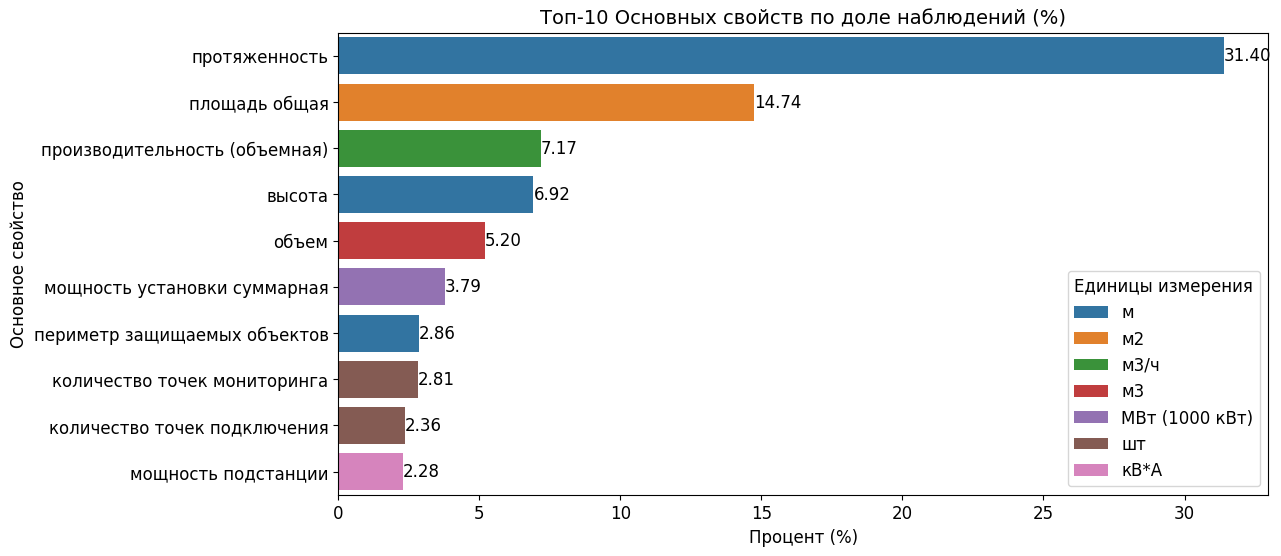

In [49]:
top_prop = counts_prop.head(10).sort_values("Процент", ascending=False)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_prop,
    x="Процент",
    y="Свойство",
    hue="ед. изм."
)

for container in ax.containers:
    ax.bar_label(
    container,
    fmt="%.2f",
    fontsize=12
)

plt.xlabel("Процент (%)", fontsize=12)
plt.ylabel("Основное свойство", fontsize=12)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.legend(
    title="Единицы измерения",
    fontsize=12,
    title_fontsize=12
)

plt.title("Топ-10 Основных свойств по доле наблюдений (%)", fontsize=14)
plt.show()

Как говорилось раньше, "м" отвечают за протяженность, высоту и периметр, "м2" - за площадь, "м3/ч" - за производительность, а вот за "шт" - множество мелких совновных средств.

In [50]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns
cat_cols = df.select_dtypes(include=["object", "category", "string"]).columns

Выбросы хотелось только посмотреть, удалять я их ни в коем случае не буду, так как пропадет вся структура данных. Это совершенно нормально, что огромная компания имеет как и дешевую мышку, так и дорогой заво; как немощную установку, так и длинную трубу.

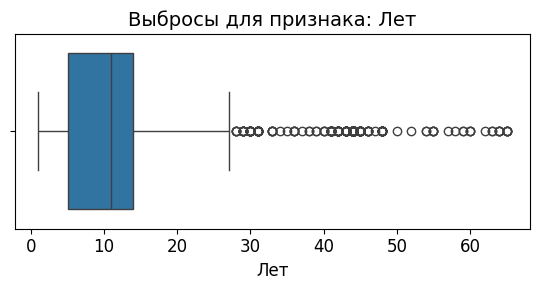

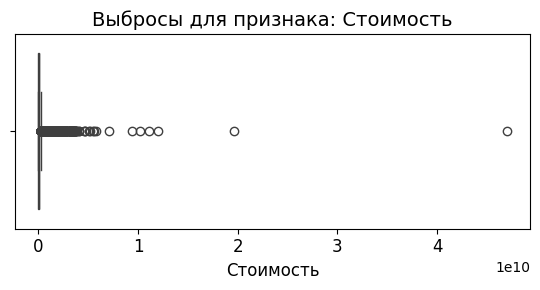

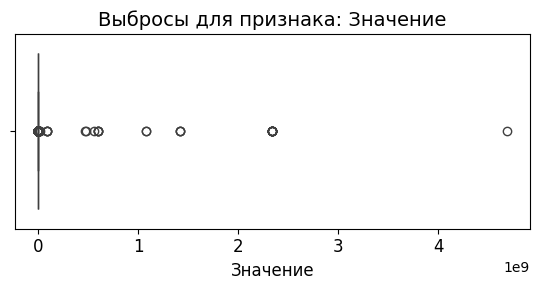

In [51]:
for col in num_cols:

    plt.figure(figsize=(5.5, 3))

    sns.boxplot(x=df[col])

    plt.title(
        f"Выбросы для признака: {col}",
        fontsize=14
    )

    plt.xlabel(col, fontsize=12)

    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)

    plt.tight_layout()
    plt.show()

Распределения я смотрел, чтобы убедиться, что корреляция Пирсона нам не подойдет. Стоимость и значение свойств имеют скошенное распределение, а "Лет в эксплуации" за счет меньше размаха можно увидеть сами стобики и правый хвост.

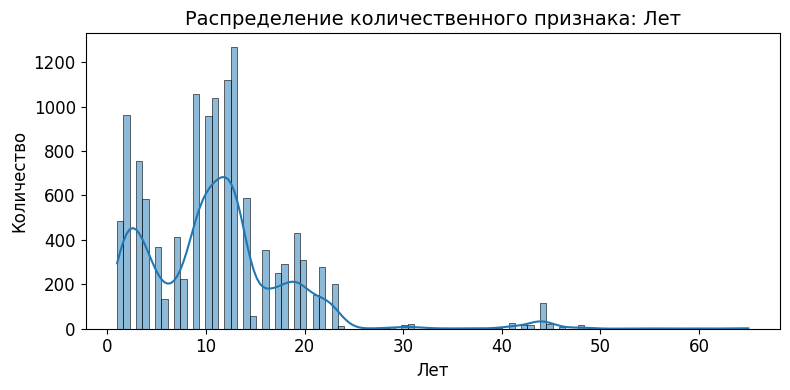

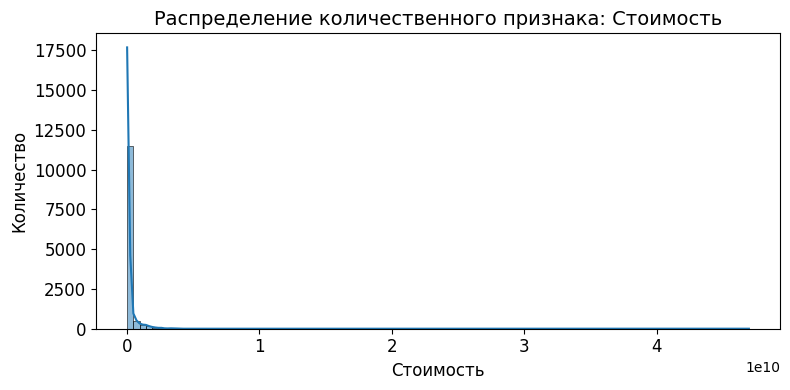

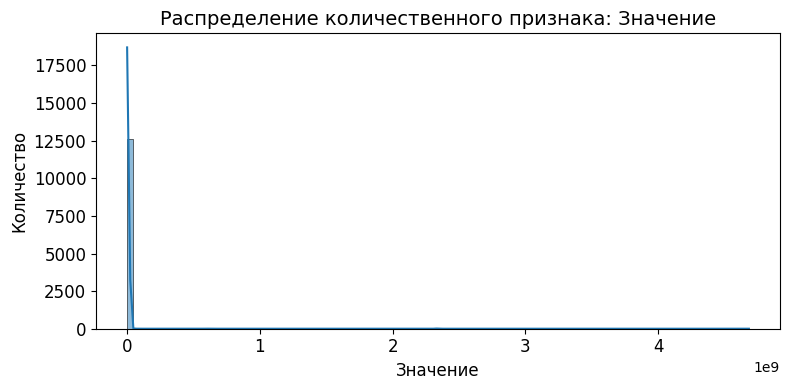

In [52]:
for col in num_cols:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        df[col],
        bins=100,
        kde=True
    )

    plt.title(
        f"Распределение количественного признака: {col}",
        fontsize=14
    )

    plt.xlabel(col, fontsize=12)
    plt.ylabel("Количество", fontsize=12)

    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)

    plt.tight_layout()
    plt.show()

Диаграмму рассеяния тоже смотрел для выбора метода Корреляции. Размеется, никакой линейно связи не наблюдается.

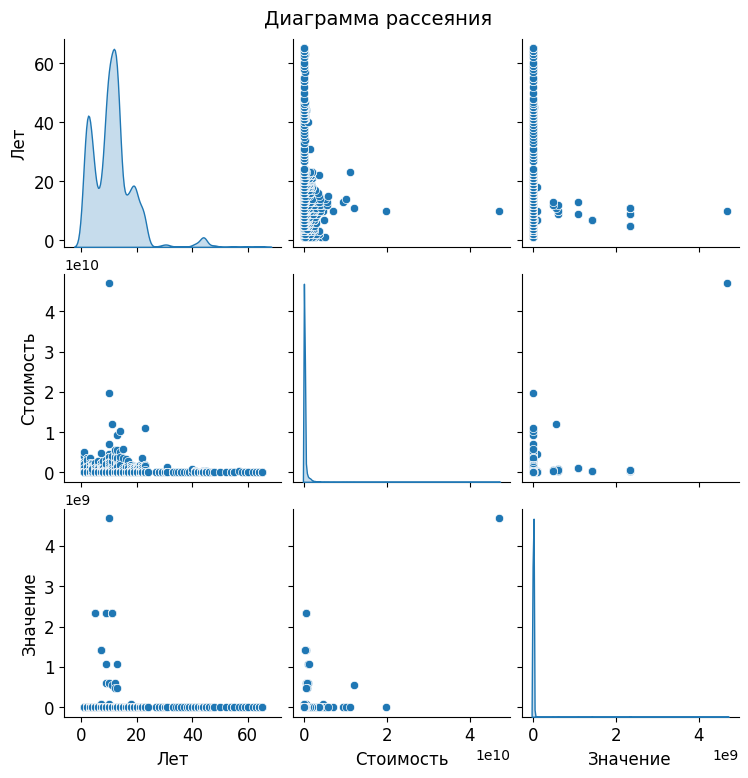

In [53]:
g = sns.pairplot(
    df[num_cols],
    diag_kind="kde"
)

g.fig.suptitle(
    "Диаграмма рассеяния",
    fontsize=14,
    y=1.02
)

for ax in g.axes.flatten():
    if ax is not None:
        ax.tick_params(axis='both', labelsize=12)

        ax.set_xlabel(ax.get_xlabel(), fontsize=12)
        ax.set_ylabel(ax.get_ylabel(), fontsize=12)

plt.show()

Из матрицы корреляции видно, что между признаками наблюдаются только слабые связи, что не страшно, так как машинное обучение может справиться и без этого.

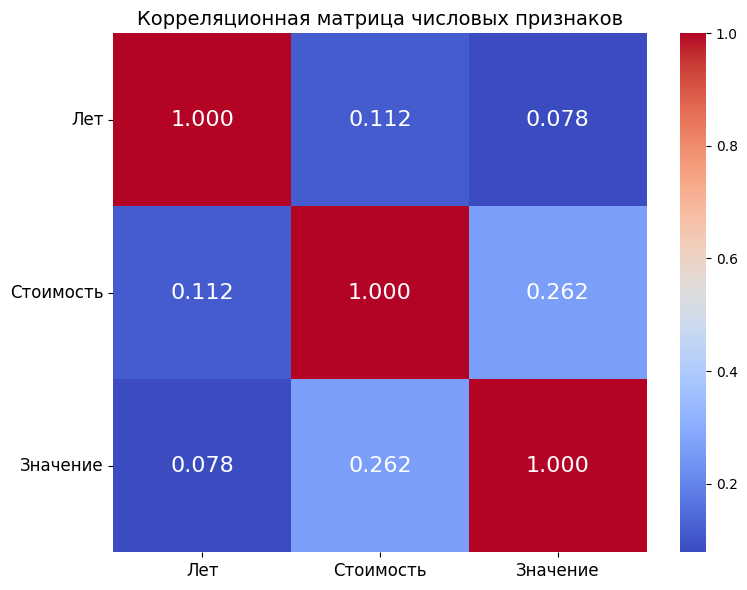

In [54]:
df_corr = df[num_cols].copy()

corr_spearman = df_corr.corr(method="spearman")

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_spearman,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    annot_kws={"size": 16}  # числа внутри клеток
)

plt.title(
    "Корреляционная матрица числовых признаков",
    fontsize=14
)

plt.xticks(
    fontsize=12,
)

plt.yticks(
    fontsize=12,
    rotation=0
)

plt.tight_layout()

plt.show()

Матрица корреляций для категориальных признаков меня обрадовала. Есть сильная связь между Регионами, Округами и Организациями (Регионы и Округи все-таки я объединил). Также сильная связь между Наименованием, Основынм свойством и единицами измерения.

In [55]:
def cramers_v(x, y):
    confusion = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion)[0]
    n = confusion.sum().sum()

    if n == 0:
        return 0

    phi2 = chi2 / n
    r, k = confusion.shape

    if min(k-1, r-1) == 0:
        return 0

    return np.sqrt(phi2 / min(k-1, r-1))

In [56]:
corr_matrix = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)

for col1 in cat_cols:
    for col2 in cat_cols:
        if col1 == col2:
            corr_matrix.loc[col1, col2] = 1.0
        else:
            corr_matrix.loc[col1, col2] = cramers_v(df[col1], df[col2])

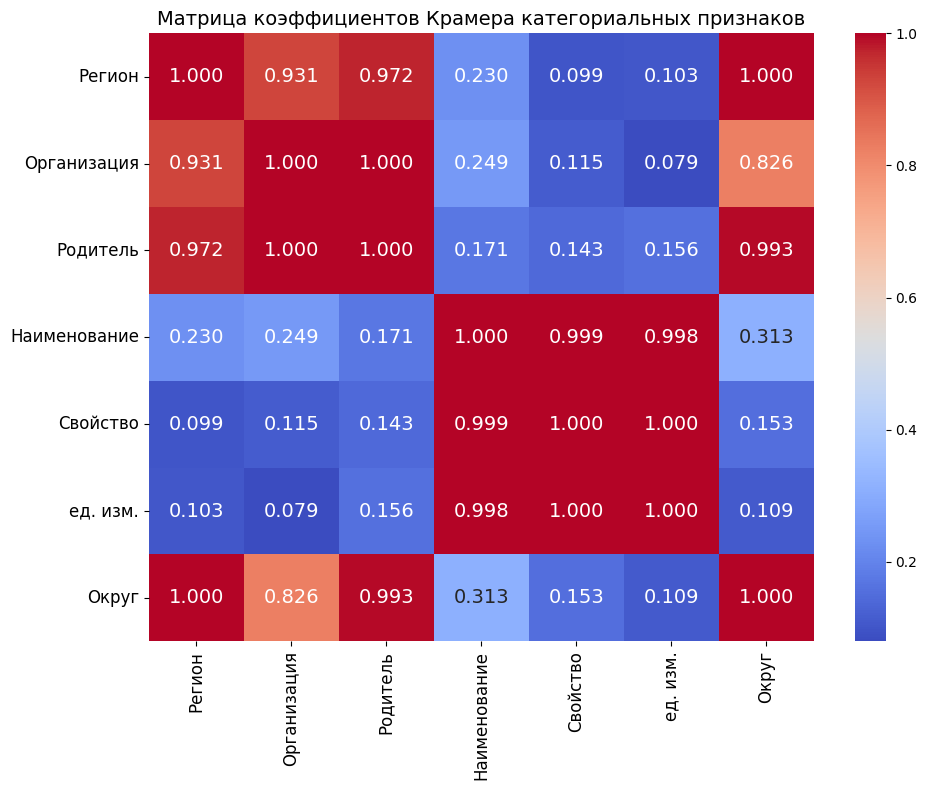

In [ ]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    annot_kws={"size": 14}
)

plt.title(
    "Матрица коэффициентов Крамера категориальных признаков",
    fontsize=14
)

plt.xticks(
    fontsize=12,
)

plt.yticks(
    fontsize=12,
    rotation=0
)

plt.tight_layout()

plt.show()

# Сценарий 3: классификация с разделением по единицам измерения

## кластеризация, детектирование, преобразование и отбор

In [57]:
RANDOM_STATE = 123

class_counts = df['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
df['Наименование'] = df['Наименование'].where(
    ~df['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(df['Наименование'] == 'редкий').sum()}")

unit_map = {'м': 'м', 'м2': 'м2', 'м3': 'м3', 'шт': 'шт'}
groups = {}
for unit, name in unit_map.items():
    groups[name] = df[df['ед. изм.'] == unit].copy()
groups['прочие'] = df[~df['ед. изм.'].isin(unit_map.keys())].copy()

Единичных классов заменено: 67
Объектов с меткой 'редкий': 67


In [58]:
PARAM_GRID = {
    'min_cluster_size': np.arange(2, 21, 1),
    'min_samples':      np.arange(1, 21, 1)
}

results = {}

for group, subset in groups.items():

    print(
        f'\nПодвыборка: {group} | '
        f'объектов: {len(subset)}'
    )

    df_sub = subset.copy()

    feature_cols = [
        'Регион',
        'Организация',
        'Родитель',
        'Наименование',
        'Свойство',
        'Лет',
        'Стоимость',
        'Значение',
        'Округ'
    ]

    if group == 'прочие':
        feature_cols.append('ед. изм.')

    X = df_sub[feature_cols].copy()

    print('Расчет матрицы Гауэра')

    gower_matrix = gower.gower_matrix(X)
    gower_matrix = np.asarray(
        gower_matrix,
        dtype=np.float64
    )

    best_score = -np.inf
    best_params = None
    best_labels = None

    for min_cluster_size, min_samples in product(
        PARAM_GRID['min_cluster_size'],
        PARAM_GRID['min_samples']
    ):

        try:

            clusterer = hdbscan.HDBSCAN(
                metric='precomputed',
                min_cluster_size=min_cluster_size,
                min_samples=min_samples
            )

            labels = clusterer.fit_predict(
                gower_matrix
            )

            cluster_mask = labels != -1

            n_noise = (labels == -1).sum()
            n_cluster = cluster_mask.sum()

            if n_cluster < 2:
                continue

            unique_clusters = np.unique(
                labels[cluster_mask]
            )

            if len(unique_clusters) < 2:
                continue

            score = silhouette_score(
                gower_matrix[
                    np.ix_(cluster_mask, cluster_mask)
                ],
                labels[cluster_mask],
                metric='precomputed'
            )

            if score > best_score:

                best_score = score

                best_params = {
                    'min_cluster_size': min_cluster_size,
                    'min_samples': min_samples
                }

                best_labels = labels

        except Exception as e:

            print(
                f'Ошибка: '
                f'min_cluster_size='
                f'{min_cluster_size}, '
                f'min_samples='
                f'{min_samples}'
            )

            print(e)

    if best_labels is None:

        print('Подходящая конфигурация не найдена')

        df_sub['hdbscan_label'] = 0

        results[group] = {
            'normal': df_sub.copy(),
            'rare': pd.DataFrame(
                columns=df_sub.columns
            )
        }

        continue

    df_sub['hdbscan_label'] = best_labels

    df_normal = (
        df_sub[df_sub['hdbscan_label'] != -1]
        .drop(columns='hdbscan_label')
        .reset_index(drop=True)
    )

    df_rare = (
        df_sub[df_sub['hdbscan_label'] == -1]
        .drop(columns='hdbscan_label')
        .reset_index(drop=True)
    )

    n_clusters = len(
        np.unique(
            best_labels[best_labels != -1]
        )
    )

    noise_count = (
        best_labels == -1
    ).sum()

    normal_count = (
        best_labels != -1
    ).sum()

    noise_share = (
        noise_count / len(best_labels)
    ) * 100

    print(
        f'  Лучший силуэт: '
        f'{best_score:.4f}'
    )

    print(
        f'  Лучшие параметры: '
        f'{best_params}'
    )

    print(
        f'  Количество кластеров: '
        f'{n_clusters}'
    )

    print(
        f'  Шумовых объектов: '
        f'{noise_count}'
    )

    print(
        f'  Доля шума: '
        f'{noise_share:.2f}%'
    )

    print(
        f'  Нормальных объектов: '
        f'{normal_count}'
    )

    print(
        f'  Классов в нормальных: '
        f'{df_normal["Наименование"].nunique()}'
    )

    print(
        f'  Классов в редких: '
        f'{df_rare["Наименование"].nunique()}'
    )

    results[group] = {
        'normal': df_normal,
        'rare': df_rare
    }


Подвыборка: м | объектов: 5357
Расчет матрицы Гауэра
... (вывод сокращён: 41 строк) ...

Подвыборка: прочие | объектов: 3104
Расчет матрицы Гауэра
  Лучший силуэт: 0.7194
  Лучшие параметры: {'min_cluster_size': np.int64(2), 'min_samples': np.int64(1)}
  Количество кластеров: 929
  Шумовых объектов: 286
  Доля шума: 9.21%
  Нормальных объектов: 2818
  Классов в нормальных: 86
  Классов в редких: 71


In [60]:
RANDOM_STATE = 123

PARAM_GRID = {
    'n_estimators':  np.arange(1, 6, 1),
    'contamination': ['auto'],
    'max_features':  np.arange(0.1, 1.1, 0.1),
    'max_samples':   np.arange(0.1, 1.1, 0.1),
    'bootstrap': [True, False]
}

def prepare_for_if(df, group):

    X = df.copy()

    categorical_cols = [
        'Регион',
        'Организация',
        'Родитель',
        'Свойство',
        'Округ'
    ]

    if group == 'прочие':

        categorical_cols.append('ед. изм.')

    numeric_cols = [
        'Лет',
        'Стоимость',
        'Значение'
    ]

    encoder = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )

    X[categorical_cols] = encoder.fit_transform(
        X[categorical_cols]
    )

    feature_cols = (
        categorical_cols +
        numeric_cols
    )

    return X[feature_cols]

results_if = {}

for group, group_data in results.items():

    results_if[group] = {}

    for subset_name, subset in group_data.items():

        print(
            f'\nПодвыборка: {group} | '
            f'{subset_name} | '
            f'объектов: {len(subset)}'
        )

        df_sub = subset.copy()

        X = prepare_for_if(
            df_sub,
            group
        )

        best_score = -np.inf
        best_params = None
        best_labels = None

        for n_est, cont, max_f, max_s, b in product(
            PARAM_GRID['n_estimators'],
            PARAM_GRID['contamination'],
            PARAM_GRID['max_features'],
            PARAM_GRID['max_samples'],
            PARAM_GRID['bootstrap']
        ):

            try:

                iso = IsolationForest(
                    n_estimators=n_est,
                    contamination=cont,
                    max_features=max_f,
                    max_samples=max_s,
                    bootstrap=b,
                    random_state=RANDOM_STATE,
                    n_jobs=-1
                )

                labels = iso.fit_predict(X)

                n_anomaly = (
                    labels == -1
                ).sum()

                n_normal = (
                    labels == 1
                ).sum()

                if n_anomaly < 2 or n_normal < 2:
                    continue

                score = silhouette_score(
                    X,
                    labels
                )

                if score > best_score:

                    best_score = score

                    best_params = {
                        'n_estimators': n_est,
                        'contamination': cont,
                        'max_features': max_f,
                        'max_samples': max_s,
                        'bootstrap': b
                    }

                    best_labels = labels

            except Exception as e:

                print(
                    f'Ошибка: '
                    f'n_estimators={n_est}, '
                    f'contamination={cont}, '
                    f'max_features={max_f}, '
                    f'max_samples={max_s}, '
                    f'bootstrap={b}'
                )

                print(e)

        if best_labels is None:

            print(
                'Подходящая конфигурация '
                'не найдена'
            )

            df_sub['if_anomaly'] = 0

        else:

            df_sub['if_anomaly'] = (
                best_labels == -1
            ).astype(int)

            anomaly_count = (
                df_sub['if_anomaly'] == 1
            ).sum()

            normal_count = (
                df_sub['if_anomaly'] == 0
            ).sum()

            anomaly_share = (
                anomaly_count / len(df_sub)
            )

            print(
                f'Лучший силуэт: '
                f'{best_score:.4f}'
            )

            print(
                f'Лучшие параметры: '
                f'{best_params}'
            )

            print(
                f'Аномальных объектов: '
                f'{anomaly_count}'
            )

            print(
                f'Доля аномалий: '
                f'{anomaly_share:.2%}'
            )

            print(
                f'Нормальных объектов: '
                f'{normal_count}'
            )

        results_if[group][subset_name] = df_sub


Подвыборка: м | normal | объектов: 4684
Лучший силуэт: 0.6533
... (вывод сокращён: 56 строк) ...
Лучшие параметры: {'n_estimators': np.int64(5), 'contamination': 'auto', 'max_features': np.float64(0.1), 'max_samples': np.float64(1.0), 'bootstrap': False}
Аномальных объектов: 53
Доля аномалий: 1.88%
Нормальных объектов: 2765

Подвыборка: прочие | rare | объектов: 286
Лучший силуэт: 0.8064
Лучшие параметры: {'n_estimators': np.int64(3), 'contamination': 'auto', 'max_features': np.float64(0.1), 'max_samples': np.float64(1.0), 'bootstrap': False}
Аномальных объектов: 19
Доля аномалий: 6.64%
Нормальных объектов: 267


import pickle

with open('results_hdbscan.pkl', 'wb') as f:
    pickle.dump(results, f)

with open('results_if.pkl', 'wb') as f:
    pickle.dump(results_if, f)

print('Сохранено')

In [307]:
import pickle

with open('results_hdbscan.pkl', 'rb') as f:
    results = pickle.load(f)

with open('results_if.pkl', 'rb') as f:
    results_if = pickle.load(f)

print('Загружено')

Загружено


In [308]:
def compute_vif(X):
    X = X.copy()
    X = X.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
    if X.shape[1] < 2:
        return pd.DataFrame({"feature": X.columns, "VIF": [1.0] * X.shape[1]})
    vif_data = pd.DataFrame()
    vif_data["feature"] = X.columns
    vif_data["VIF"] = [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
    return vif_data.sort_values("VIF", ascending=False).reset_index(drop=True)

def cramers_v(x, y):
    confusion = pd.crosstab(x, y)
    if confusion.shape[0] < 2 or confusion.shape[1] < 2:
        return 0.0
    chi2 = chi2_contingency(confusion)[0]
    n = confusion.to_numpy().sum()
    if n == 0:
        return 0.0
    r, k = confusion.shape
    phi2 = chi2 / n
    denom = max(min(k - 1, r - 1), 1)
    return np.sqrt(phi2 / denom)

def chi2_y_score(x, y):
    confusion = pd.crosstab(x, y)
    if confusion.shape[0] < 2 or confusion.shape[1] < 2:
        return 0.0, 1.0
    chi2, p, _, _ = chi2_contingency(confusion)
    return chi2, p

In [309]:
num_feature_priority = {
    "Стоимость": 0,
    "Значение": 0,
    "Лет": 0,
    
    "if_anomaly": 1,
    "износ": 1,
    "удельная стоимость": 1,
    "стоимость_transformed": 1,
    "значение_transformed": 1,

    "freq_Регион": 2,
    "freq_Свойство": 2,
    "freq_ед. изм.": 2,
    "freq_Родитель": 2,

    "freq_Организация": 3,
    "freq_категории стоимости": 3,
    "freq_категории возраста": 3,

    "freq_Округ": 4,

    "Лет_2": 2,
    "Лет_3": 2,
    "стоимость_transformed_2": 2,
    "стоимость_transformed_3": 2,
    "значение_transformed_2": 2,
    "значение_transformed_3": 2,
    
    "Лет_0.5": 2,
    "Лет_0.33": 2,
    "стоимость_transformed_0.5": 2,
    "стоимость_transformed_0.33": 2,
    "значение_transformed_0.5": 2,
    "значение_transformed_0.33": 2,
}


cat_feature_priority = {
    "Наименование": 0,
    
    "Регион": 1,
    "Свойство": 1,
    "ед. изм.": 1,
    "Родитель": 1,
    
    "Организация": 2,
    
    "категории стоимости": 3,
    "категории возраста": 3,

    "Округ": 4,
}

In [310]:
def greedy_numeric_select(
    X_num,
    y,
    feature_priority,
    vif_threshold=10.0,
    corr_threshold=0.95,
    protected_priority=0
):
    X = X_num.copy()
    X = X.loc[:, X.nunique(dropna=True) > 1]

    if X.shape[1] <= 1:
        return X.columns.tolist()

    y_le = LabelEncoder().fit_transform(y)
    F_vals, p_vals = f_classif(X, y_le)
    anova_dict = {col: (F, p) for col, F, p in zip(X.columns, F_vals, p_vals)}

    step = 0
    while True:
        step += 1
        if X.shape[1] <= 1:
            break

        X_vif = X.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
        if X_vif.shape[1] < 2:
            break

        vif_df = compute_vif(X_vif)
        corr = X.corr(method="spearman").abs()

        pairs = []
        cols = corr.columns.tolist()
        for i in range(len(cols)):
            for j in range(i + 1, len(cols)):
                c1, c2 = cols[i], cols[j]
                val = corr.loc[c1, c2]
                if pd.notna(val) and val >= corr_threshold:
                    pairs.append((c1, c2, val))

        high_vif_feats = set(vif_df.loc[vif_df["VIF"] >= vif_threshold, "feature"])

        if not pairs and not high_vif_feats:
            break

        candidates = set(high_vif_feats)
        for c1, c2, _ in pairs:
            candidates.add(c1)
            candidates.add(c2)

        mi_vals = mutual_info_classif(X[list(candidates)], y_le, random_state=42)
        mi_dict = {feat: mi for feat, mi in zip(candidates, mi_vals)}
        spearman_y = X[list(candidates)].corrwith(pd.Series(y_le, index=X.index), method="spearman").abs().to_dict()

        rows = []
        for feat in candidates:
            vif_val = float(vif_df.loc[vif_df["feature"] == feat, "VIF"].values[0]) if feat in vif_df["feature"].values else 1.0
            max_corr = corr[feat].drop(feat).max() if feat in corr.columns else 0.0
            mi_val = mi_dict.get(feat, 0.0)
            sp_y = float(spearman_y.get(feat, 0.0))
            F_val, p_val = anova_dict.get(feat, (0.0, 1.0))
            prio = feature_priority.get(feat, 999)

            rows.append({
                "feature": feat,
                "VIF": vif_val,
                "max_corr": max_corr,
                "MI": mi_val,
                "spearman_y": sp_y,
                "anova_F": F_val,
                "anova_p": p_val,
                "priority": prio
            })

        cand_df = pd.DataFrame(rows)
        if cand_df.empty:
            break

        mi_max = cand_df["MI"].max()
        F_max = cand_df["anova_F"].max()

        cand_df["MI_norm"] = cand_df["MI"] / mi_max if mi_max > 0 else 0.0
        cand_df["sp_norm"] = cand_df["spearman_y"].fillna(0.0).abs()
        cand_df["anova_norm"] = cand_df["anova_F"] / F_max if F_max > 0 else 0.0

        prio_min = cand_df["priority"].min()
        prio_max = cand_df["priority"].max()
        if prio_max > prio_min:
            cand_df["prio_norm"] = (cand_df["priority"] - prio_min) / (prio_max - prio_min)
        else:
            cand_df["prio_norm"] = 0.0

        cand_df["relevance"] = (
            0.4 * cand_df["MI_norm"] +
            0.3 * cand_df["sp_norm"] +
            0.3 * cand_df["anova_norm"]
        )

        vif_max = cand_df["VIF"].max()
        cand_df["VIF_norm"] = cand_df["VIF"] / vif_max if vif_max > 0 else 0.0

        cand_df["score"] = (
            0.55 * cand_df["VIF_norm"] +
            0.30 * cand_df["max_corr"] -
            0.80 * cand_df["relevance"] +
            0.20 * cand_df["prio_norm"]
        )

        unprotected = cand_df[cand_df["priority"] > protected_priority]
        if not unprotected.empty:
            drop_row = unprotected.sort_values("score", ascending=False).iloc[0]
        else:
            drop_row = cand_df.sort_values("score", ascending=False).iloc[0]

        drop_feat = drop_row["feature"]

        print(
            f"[NUM step {step}] drop={drop_feat} | VIF={drop_row['VIF']:.2f} "
            f"| max_corr={drop_row['max_corr']:.3f} | MI={drop_row['MI']:.4f} "
            f"| F={drop_row['anova_F']:.2f} | prio={drop_row['priority']}"
        )

        X = X.drop(columns=[drop_feat])

    return X.columns.tolist()

In [311]:
def greedy_categorical_select(
    X_cat,
    y,
    feature_priority,
    cv_threshold=0.95,
    dominant_freq_threshold=0.95,
    protected_priority=0
):
    df = X_cat.copy()
    df = df.loc[:, df.nunique(dropna=True) > 1]

    if df.shape[1] <= 1:
        return df.columns.tolist()

    y_le = LabelEncoder().fit_transform(y)

    le_df = pd.DataFrame(index=df.index)
    for col in df.columns:
        le = LabelEncoder()
        le_df[col] = le.fit_transform(df[col].astype(str))

    mi_vals = mutual_info_classif(le_df[df.columns], y_le, random_state=123)
    mi_dict = {col: mi for col, mi in zip(df.columns, mi_vals)}

    chi_scores = {}
    for col in df.columns:
        _, p_val = chi2_y_score(df[col], y)
        chi_scores[col] = -np.log10(max(p_val, 1e-12))

    mi_max = max(mi_dict.values()) if mi_dict else 0.0
    chi_max = max(chi_scores.values()) if chi_scores else 0.0

    step = 0
    while True:
        step += 1
        cols = df.columns.tolist()
        if len(cols) <= 1:
            break

        pairs = []
        for i in range(len(cols)):
            for j in range(i + 1, len(cols)):
                c1, c2 = cols[i], cols[j]
                cv = cramers_v(df[c1], df[c2])
                if cv >= cv_threshold:
                    pairs.append((c1, c2, cv))

        if not pairs:
            break

        rows = []
        involved = set()
        for c1, c2, cv in pairs:
            involved.add(c1)
            involved.add(c2)

        for feat in involved:
            mi = mi_dict.get(feat, 0.0)
            chi_score = chi_scores.get(feat, 0.0)
            prio = feature_priority.get(feat, 999)
            rows.append({
                "feature": feat,
                "MI": mi,
                "chi_score": chi_score,
                "priority": prio
            })

        cand_df = pd.DataFrame(rows)
        if cand_df.empty:
            break

        cand_df["MI_norm"] = cand_df["MI"] / mi_max if mi_max > 0 else 0.0
        cand_df["chi_norm"] = cand_df["chi_score"] / chi_max if chi_max > 0 else 0.0

        prio_min = cand_df["priority"].min()
        prio_max = cand_df["priority"].max()
        cand_df["prio_norm"] = (cand_df["priority"] - prio_min) / (prio_max - prio_min) if prio_max > prio_min else 0.0

        cand_df["relevance"] = 0.5 * cand_df["MI_norm"] + 0.5 * cand_df["chi_norm"]

        cand_df["score"] = (
            -0.90 * cand_df["relevance"] +
            0.10 * cand_df["prio_norm"]
        )

        unprotected = cand_df[cand_df["priority"] > protected_priority]
        if not unprotected.empty:
            drop_row = unprotected.sort_values("score", ascending=False).iloc[0]
        else:
            drop_row = cand_df.sort_values("score", ascending=False).iloc[0]

        drop_feat = drop_row["feature"]

        max_cv = 0.0
        max_pair = None
        for c1, c2, cv in pairs:
            if drop_feat in (c1, c2) and cv > max_cv:
                max_cv = cv
                max_pair = (c1, c2)

        pair_str = f"{max_pair[0]} vs {max_pair[1]}" if max_pair else "N/A"

        print(
            f"[CAT step {step}] drop={drop_feat} | pair={pair_str} | CV={max_cv:.3f} "
            f"| MI={drop_row['MI']:.4f} | chi_score={drop_row['chi_score']:.2f} "
            f"| prio={drop_row['priority']}"
        )

        df = df.drop(columns=[drop_feat])

        for col in df.columns.tolist():
            freq = df[col].value_counts(normalize=True, dropna=False).iloc[0]
            if freq >= dominant_freq_threshold:
                print(f"[CAT const] drop={col} | freq={freq:.3f}")
                df = df.drop(columns=[col])

    return df.columns.tolist()

In [312]:
def build_features(df_input, target_col='Наименование'):
    df = df_input.copy()
    y = df[target_col]

    pt = PowerTransformer(method='yeo-johnson')

    df['стоимость_transformed'] = pt.fit_transform(df[['Стоимость']])
    df['значение_transformed']  = pt.fit_transform(df[['Значение']])

    df['категории стоимости'] = pd.qcut(
        df['Стоимость'], q=5,
        labels=['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
        duplicates='drop'
    )

    bins_age = [-1, 5, 11, 14, np.inf]
    labels_age = ['новое', 'среднее', 'старое', 'очень старое']
    df['категории возраста'] = pd.cut(df['Лет'], bins=bins_age, labels=labels_age)

    df['удельная стоимость'] = df['Стоимость'] / df['Значение'].replace(0, np.nan)
    df['износ'] = df['Стоимость'] / df['Лет'].replace(0, np.nan)

    for col in ['стоимость_transformed', 'значение_transformed', 'Лет']:
        df[f'{col}_2'] = df[col] ** 2
        df[f'{col}_3'] = df[col] ** 3

    cat_cols_freq = [
        c for c in df.select_dtypes(include=['object', 'category']).columns
        if c != target_col
    ]

    for col in cat_cols_freq:
        freq_map = df[col].astype(str).value_counts(normalize=True, dropna=False)
        df[f'freq_{col}'] = df[col].astype(str).map(freq_map).fillna(0.0).astype(float)

    num_cols = [
        c for c in df.select_dtypes(exclude=['object', 'category']).columns
        if c != target_col
    ]
    cat_cols = [
        c for c in df.select_dtypes(include=['object', 'category']).columns
        if c != target_col
    ]

    X_num = df[num_cols]
    X_cat = df[cat_cols]

    selected_num = greedy_numeric_select(
        X_num=X_num,
        y=y,
        feature_priority=num_feature_priority,
        vif_threshold=10,
        corr_threshold=0.95,
        protected_priority=0
    )

    selected_cat = greedy_categorical_select(
        X_cat=X_cat,
        y=y,
        feature_priority=cat_feature_priority,
        cv_threshold=0.95,
        dominant_freq_threshold=0.95,
        protected_priority=0
    )

    df_out = df[selected_num + selected_cat + [target_col]]
    return df_out, selected_num, selected_cat

processed = {}

for group in ['м', 'м2', 'м3', 'шт', 'прочие']:
    for split in ['normal', 'rare']:
        key = (group, split)
        raw = results_if[group][split]

        if len(raw) < 10:
            print(f"\n[{group} | {split}] слишком мало объектов ({len(raw)}), пропускаем")
            processed[key] = raw.copy()
            continue

        print(f"[{group} | {split}] объектов: {len(raw)}, классов: {raw['Наименование'].nunique()}")

        try:
            df_proc, sel_num, sel_cat = build_features(raw)
            processed[key] = df_proc

            print(f"  Числовых признаков после отбора:     {len(sel_num)}")
            print(f"  Категориальных признаков после отбора: {len(sel_cat)}")
            print(f"  Итоговых признаков:                  {len(sel_num) + len(sel_cat)}")

        except Exception as e:
            print(f"  ОШИБКА: {e}")
            processed[key] = raw.copy()

[м | normal] объектов: 4684, классов: 61
[NUM step 1] drop=Лет_2 | VIF=124.60 | max_corr=1.000 | MI=0.2963 | F=7.45 | prio=2
[NUM step 2] drop=freq_категории стоимости | VIF=108.45 | max_corr=0.742 | MI=0.2308 | F=6.41 | prio=3
... (вывод сокращён: 145 строк) ...
[NUM step 6] drop=Лет_3 | VIF=2.44 | max_corr=1.000 | MI=0.3999 | F=1.70 | prio=2
[NUM step 7] drop=значение_transformed_3 | VIF=7.90 | max_corr=1.000 | MI=1.4078 | F=13.97 | prio=2
[NUM step 8] drop=стоимость_transformed | VIF=1.47 | max_corr=1.000 | MI=0.6768 | F=6.40 | prio=1
[NUM step 9] drop=значение_transformed | VIF=1.42 | max_corr=1.000 | MI=1.5056 | F=13.24 | prio=1
[NUM step 10] drop=Значение | VIF=23.86 | max_corr=0.857 | MI=1.3467 | F=77.47 | prio=0
[CAT step 1] drop=Родитель | pair=Организация vs Родитель | CV=1.000 | MI=0.2875 | chi_score=0.00 | prio=1
[CAT step 2] drop=Регион | pair=Регион vs Округ | CV=1.000 | MI=0.2798 | chi_score=0.61 | prio=1
[CAT step 3] drop=ед. изм. | pair=Свойство vs ед. изм. | CV=1.000 

In [313]:
import warnings
warnings.filterwarnings("ignore")

In [314]:
def run_experiment(model, model_name, preprocessor, balancers_dict,
                   X_train, X_test, y_train, y_test):
    
    results = []

    for bal_name, bal_func in balancers_dict.items():
        print(f"Запуск: {model_name} + {bal_name}")
        
        try:
            if preprocessor is not None:
                X_train_prep = preprocessor.fit_transform(X_train, y_train)
                X_test_prep = preprocessor.transform(X_test)

                if hasattr(X_train_prep, "toarray"):
                    X_train_prep = X_train_prep.toarray()
                    X_test_prep = X_test_prep.toarray()
            else:
                X_train_prep = X_train.copy()
                X_test_prep = X_test.copy()

            start_bal = time.time()
            X_train_bal, y_train_bal = bal_func.fit_resample(X_train_prep, y_train)
            bal_time = time.time() - start_bal

            start_train = time.time()
            model.fit(X_train_bal, y_train_bal)
            train_time = time.time() - start_train

            start_pred = time.time()
            y_pred = model.predict(X_test_prep)
            pred_time = time.time() - start_pred

            acc = accuracy_score(y_test, y_pred)

            results.append({
                "model": model_name,
                "balancing": bal_name,
                "accuracy": round(acc, 4),
                "balancing_time_sec": round(bal_time, 3),
                "train_time_sec": round(train_time, 3),
                "predict_time_sec": round(pred_time, 3)
            })

        except Exception as e:
            print(f"Ошибка в {model_name} + {bal_name}: {e}")
            continue

    return pd.DataFrame(results).sort_values(by="accuracy", ascending=False)

In [315]:
class GaussianNoiseSampler(BaseEstimator):
    def __init__(self, noise_level=0.05, random_state=123):
        self.noise_level = noise_level
        self.random_state = random_state

    def fit_resample(self, X, y):
        rng = np.random.default_rng(self.random_state)

        X = np.asarray(X)
        y = np.asarray(y)

        X_res = X.copy()
        y_res = y.copy()

        classes, counts = np.unique(y, return_counts=True)
        max_count = counts.max()

        for cls, count in zip(classes, counts):
            X_cls = X[y == cls]
            n_to_add = max_count - count

            if n_to_add <= 0:
                continue

            mean = X_cls.mean(axis=0)
            std = X_cls.std(axis=0)
            std = np.where(std == 0, 1e-8, std)

            X_new = rng.normal(
                loc=mean,
                scale=std * self.noise_level,
                size=(n_to_add, X.shape[1])
            )

            y_new = np.full(n_to_add, cls)

            X_res = np.vstack([X_res, X_new])
            y_res = np.concatenate([y_res, y_new])

        return X_res, y_res

In [316]:
balancers = {
    "ros": RandomOverSampler(random_state=123),
    "ros_shrinkage_005": RandomOverSampler(random_state=123, shrinkage=0.05),
    "ros_shrinkage_01": RandomOverSampler(random_state=123, shrinkage=0.1),
    "ros_shrinkage_02": RandomOverSampler(random_state=123, shrinkage=0.2),
    "gaussian_noise": GaussianNoiseSampler(noise_level=0.05, random_state=123),
}

## Подвыборка «м»: нормальные классы

In [497]:
target_col = "Наименование"

class_counts = processed[('м', 'normal')]['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
processed[('м', 'normal')]['Наименование'] = processed[('м', 'normal')]['Наименование'].where(
    ~processed[('м', 'normal')]['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(processed[('м', 'normal')]['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 2
Объектов с меткой 'редкий': 6


In [498]:
X = processed[('м', 'normal')].drop(columns=[target_col])
y = processed[('м', 'normal')][target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.33,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (3138, 17) y_train: (3138,)
X_test: (1546, 17) y_test: (1546,)


In [499]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [500]:
X_train.columns

Index(['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация', 'freq_Родитель', 'freq_Свойство',
       'freq_Округ', 'Родитель', 'Свойство', 'категории стоимости',
       'категории возраста'],
      dtype='object')

In [501]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация',
       'freq_Округ', 'Родитель', 'Свойство', 'категории стоимости',
       'категории возраста']

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
                       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
                       'freq_Регион', 'freq_Организация', 'freq_Округ']
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Родитель', 'Свойство']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [856]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,svm,gaussian_noise,0.4224,0.276,3.221,1.497
2,svm,ros_shrinkage_01,0.3700,0.085,5.585,3.207
1,svm,ros_shrinkage_005,0.3693,0.094,4.890,3.117
3,svm,ros_shrinkage_02,0.3680,0.084,5.852,3.337
0,svm,ros,0.3668,0.015,4.649,2.711


In [857]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 8 candidates, totalling 80 fits


In [858]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'rbf'}
Лучшая CV accuracy: 0.4216173867035673
Время (сек): 62.972362995147705
Test accuracy: 0.42238033635187583


In [864]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(
        kernel='rbf',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': np.arange(10, 60, 10),
    'clf__gamma': [1e-1, 1e-2, 1e-3, 1e-4],
    'clf__tol': [1e-1, 1e-2, 1e-3, 1e-4],          
    'clf__max_iter': np.arange(100, 600, 100)
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 400 candidates, totalling 800 fits


In [865]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)
y_pred_test = grid_svm2.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_acc)
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': np.int64(20), 'clf__gamma': 0.01, 'clf__max_iter': np.int64(200), 'clf__tol': 0.1}
Лучшая CV accuracy: 0.4149139579349904
Test accuracy: 0.43919793014230274
Время обучения (сек): 320.3103759288788


In [866]:
pipe = grid_svm2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
})

feat_imp = feat_imp.sort_values(
    "importance",
    ascending=False
)

feat_imp.head(10)

,feature,importance
11,freq_Свойство,0.225097
15,категории стоимости,0.064036
7,значение_transformed_2,0.059940
10,freq_Родитель,0.043769
14,Свойство,0.043122
2,Значение,0.034929
6,стоимость_transformed_2,0.026304
0,Лет,0.024364
13,Родитель,0.022208
1,Стоимость,0.020483


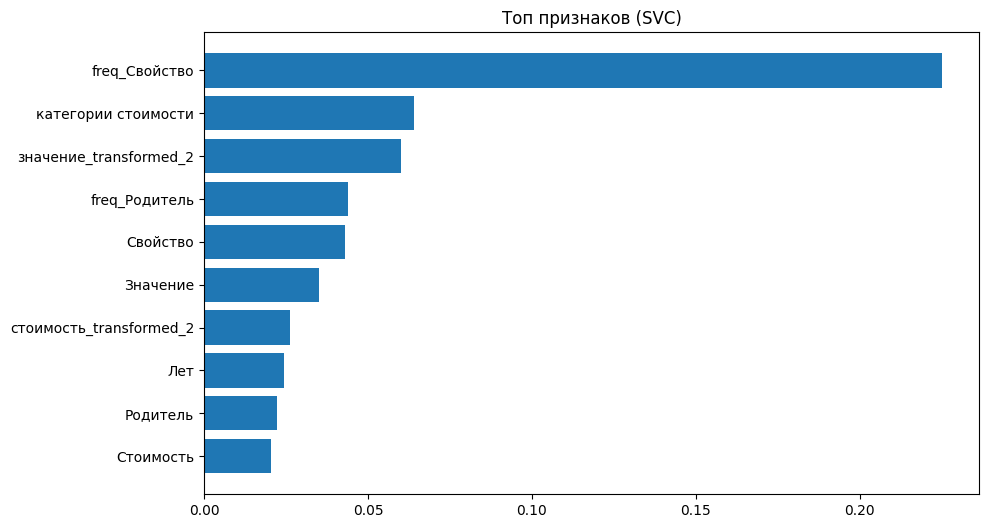

In [867]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [868]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,knn,gaussian_noise,0.3803,0.344,0.006,0.093
0,knn,ros,0.3596,0.022,0.006,0.071
2,knn,ros_shrinkage_01,0.3525,0.082,0.002,0.056
1,knn,ros_shrinkage_005,0.3512,0.088,0.007,0.062
3,knn,ros_shrinkage_02,0.3499,0.094,0.002,0.054


In [874]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [875]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'distance'}
Лучшая CV accuracy: 0.3954748247291268
Test accuracy: 0.4055627425614489
Время: 4.626905918121338


In [878]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='distance',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(1, 36, 5),
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__leaf_size': np.arange(1, 36, 5)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 98 candidates, totalling 294 fits


In [879]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(1), 'clf__metric': 'manhattan', 'clf__n_neighbors': np.int64(16)}
Лучшая CV accuracy: 0.4123645634161887
Test accuracy: 0.41461836998706336
Время: 58.188271045684814


In [880]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,freq_Свойство,0.076326
14,Свойство,0.057568
7,значение_transformed_2,0.054118
15,категории стоимости,0.040319
16,категории возраста,0.022639
6,стоимость_transformed_2,0.020699
10,freq_Родитель,0.019621
2,Значение,0.018111
9,freq_Организация,0.016171
3,if_anomaly,0.014230


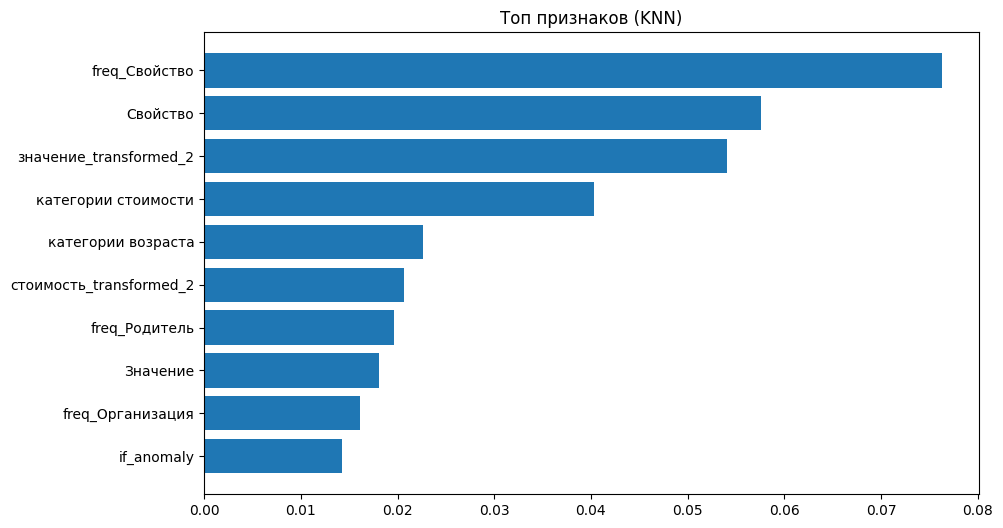

In [881]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [882]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,tree,gaussian_noise,0.4340,0.017,0.734,0.000
0,tree,ros,0.4308,0.005,0.127,0.001
2,tree,ros_shrinkage_01,0.4263,0.011,0.785,0.001
3,tree,ros_shrinkage_02,0.4263,0.013,0.828,0.001
1,tree,ros_shrinkage_005,0.4159,0.011,0.719,0.001


In [885]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 6 candidates, totalling 18 fits


In [886]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.40822179732313574
Test accuracy: 0.43402328589909445
Время: 5.716308832168579


In [890]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='gini',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': np.arange(1, 36, 5),
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 11, 2)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1750 candidates, totalling 3500 fits

















In [891]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': np.int64(26), 'clf__max_features': np.float64(0.7000000000000001), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.41395793499043976
Test accuracy: 0.42884864165588615
Время: 73.47660708427429


In [892]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
4,num__удельная стоимость,0.130626
0,num__Лет,0.123570
8,num__freq_Регион,0.112111
6,num__стоимость_transformed_2,0.071591
7,num__значение_transformed_2,0.070369
14,ord__категории возраста,0.067871
5,num__износ,0.063156
2,num__Значение,0.061257
12,num__freq_Округ,0.059038
11,num__freq_Свойство,0.055025


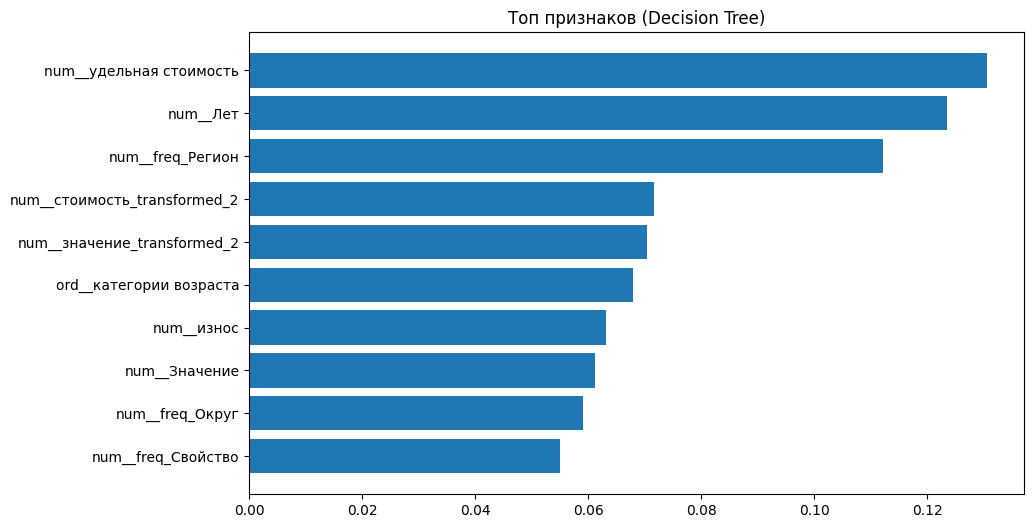

In [893]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [848]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,rf,gaussian_noise,0.4974,0.019,1.462,0.046
0,rf,ros,0.4929,0.010,0.398,0.029
2,rf,ros_shrinkage_01,0.4897,0.010,1.681,0.046
1,rf,ros_shrinkage_005,0.4851,0.010,1.388,0.027
3,rf,ros_shrinkage_02,0.4838,0.015,1.686,0.038


In [849]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 3 candidates, totalling 9 fits


In [850]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini'}
Лучшая CV accuracy: 0.4767367750159337
Test accuracy: 0.4974126778783959
Время: 8.843118906021118


In [ ]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': [50, 100, 200],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.3, 1.2, 0.3),
    'clf__max_samples': np.arange(0.3, 1.2, 0.3),
    'clf__min_samples_split': np.arange(2, 9, 3),
    'clf__min_samples_leaf': np.arange(1, 8, 3)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1875 candidates, totalling 3750 fits


In [853]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.4), 'clf__max_samples': np.float64(0.8), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4), 'clf__n_estimators': 300}
Лучшая CV accuracy: 0.4894837476099426
Test accuracy: 0.5122897800776197
Время: 5358.4307861328125


In [854]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
0,num__Лет,0.106194
4,num__удельная стоимость,0.103701
2,num__Значение,0.075090
7,num__значение_transformed_2,0.072898
6,num__стоимость_transformed_2,0.070171
5,num__износ,0.067812
1,num__Стоимость,0.063095
14,ord__категории возраста,0.052850
12,num__freq_Округ,0.052439
8,num__freq_Регион,0.052053


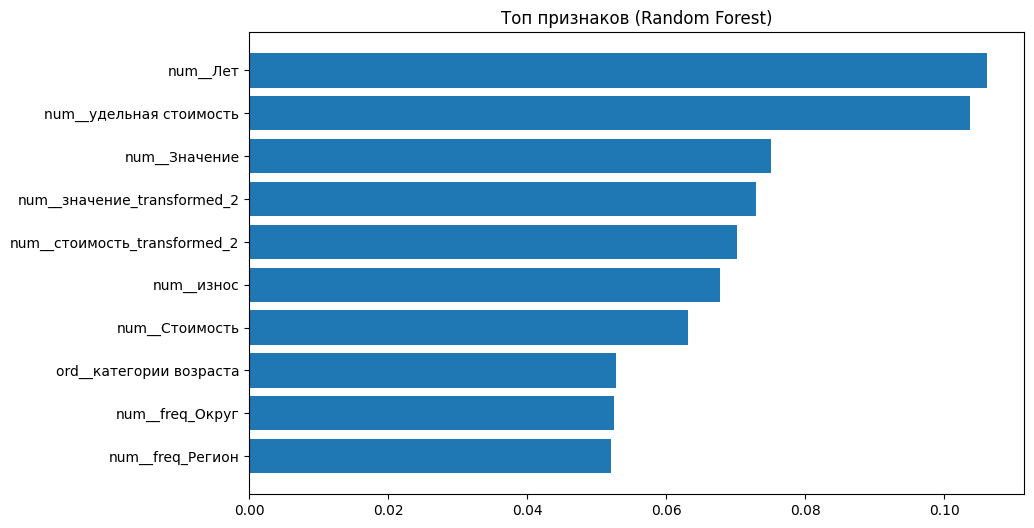

In [855]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [502]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,rtf,gaussian_noise,0.4909,0.008,18.678,0.147
0,rtf,ros,0.4903,0.004,5.245,0.141
1,rtf,ros_shrinkage_005,0.4787,0.009,21.718,0.149
2,rtf,ros_shrinkage_01,0.4728,0.009,20.840,0.160
3,rtf,ros_shrinkage_02,0.4722,0.009,20.583,0.150


In [507]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best", "random"],
    "model__pca_solver": ["auto", "full", "randomized"],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 18 candidates, totalling 36 fits


In [508]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'entropy', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'randomized'}
Лучшая CV accuracy: 0.46972594008922886
Test accuracy: 0.49288486416558863
Время: 57.36913204193115


In [516]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='entropy',
                                              splitter='best',
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.25, 1.25, 0.25), 
    'model__base_estimator__min_samples_split': np.arange(2, 11, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 100 candidates, totalling 200 fits


In [517]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(0.75), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(4)}
Лучшая CV accuracy: 0.4716379859783302
Test accuracy: 0.49159120310478654
Время: 274.8065960407257


In [519]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='entropy',
                                              splitter='best',
                                              max_features=0.75,
                                              max_depth=None,
                                              min_samples_leaf=1,
                                              min_samples_split=4,
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": np.arange(100, 600, 100),
    "model__min_group": [1, 2],
    "model__max_group": [1, 2, 3],
    "model__remove_proportion": np.arange(0.2, 1.2, 0.2),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 150 candidates, totalling 300 fits


In [906]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 2, 'model__min_group': 2, 'model__n_estimators': np.int64(500), 'model__remove_proportion': np.float64(0.5)}
Лучшая CV accuracy: 0.4964945825366476
Test accuracy: 0.5239327296248383
Время: 3226.82110786438


In [907]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
14,Свойство,0.185425
11,freq_Свойство,0.094222
2,Значение,0.051315
4,удельная стоимость,0.043984
7,значение_transformed_2,0.037301
10,freq_Родитель,0.029754
8,freq_Регион,0.018974
0,Лет,0.018111
15,категории стоимости,0.016171
5,износ,0.015093


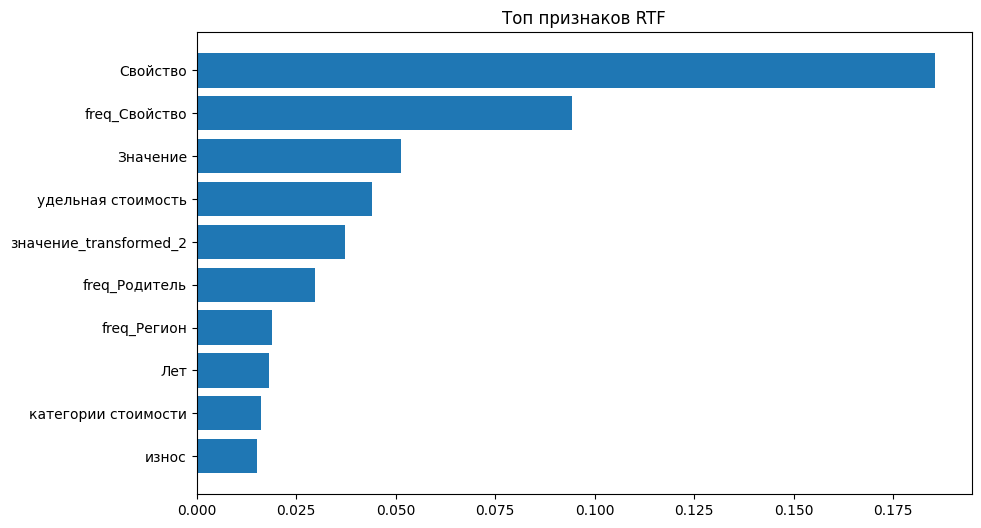

In [908]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [909]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,extra,gaussian_noise,0.4664,0.009,0.137,0.013
1,extra,ros_shrinkage_005,0.4586,0.013,0.165,0.027
0,extra,ros,0.4521,0.005,0.205,0.027
2,extra,ros_shrinkage_01,0.4502,0.011,0.201,0.026
3,extra,ros_shrinkage_02,0.4463,0.009,0.246,0.027


In [910]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 6 candidates, totalling 60 fits


In [911]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': True, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.48213609816650055
Test accuracy: 0.4683053040103493
Время: 8.483936071395874


In [912]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=True,
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": [100, 200, 300, 400, 500],
    "model__max_depth": [None],
    'model__max_features': np.arange(0.1, 1.1, 0.1),
    'model__max_samples': [None],
    'model__min_samples_split': np.arange(2, 11, 2),
    'model__min_samples_leaf': np.arange(1, 10, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1250 candidates, totalling 2500 fits


In [913]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(1.0), 'model__max_samples': None, 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(6), 'model__n_estimators': 500}
Лучшая CV accuracy: 0.48565965583174
Test accuracy: 0.4961190168175938
Время: 397.73135209083557


In [914]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
0,num__Лет,0.105676
14,ord__категории возраста,0.088317
4,num__удельная стоимость,0.087792
9,num__freq_Организация,0.074706
8,num__freq_Регион,0.070757
12,num__freq_Округ,0.068981
7,num__значение_transformed_2,0.063567
13,ord__категории стоимости,0.058935
10,num__freq_Родитель,0.058569
3,num__if_anomaly,0.054564


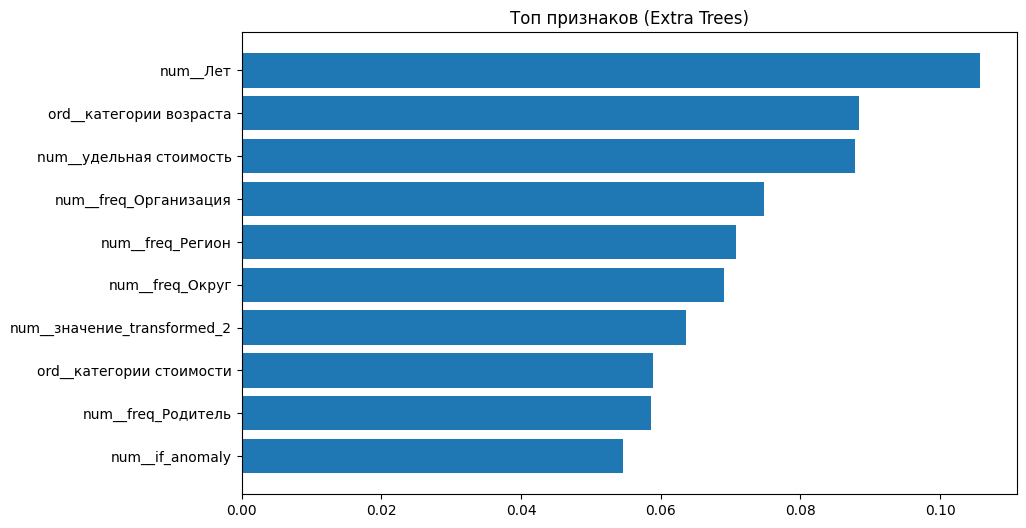

In [915]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [916]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
2,easy_ensemble,ros_shrinkage_01,0.4431,0.010,1.000,0.150
1,easy_ensemble,ros_shrinkage_005,0.4340,0.011,1.082,0.154
4,easy_ensemble,gaussian_noise,0.4295,0.008,0.983,0.144
3,easy_ensemble,ros_shrinkage_02,0.4288,0.011,1.006,0.158
0,easy_ensemble,ros,0.4185,0.003,3.307,0.199


In [917]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.1, random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 12 candidates, totalling 60 fits


In [918]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'gini', 'model__estimator__splitter': 'best', 'model__replacement': True}
Лучшая CV accuracy: 0.4486890358496124
Test accuracy: 0.44372574385511
Время: 21.048554182052612


In [919]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.1, random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='gini',
                                         splitter='best',
                                         random_state=123),
        replacement=True,
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": [25, 50, 75, 100],
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.1, 1.1, 0.1),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1000 candidates, totalling 2000 fits


In [920]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(0.2), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(8), 'model__n_estimators': 75}
Лучшая CV accuracy: 0.46653919694072654
Test accuracy: 0.4948253557567917
Время: 2289.993824005127


In [921]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
14,Свойство,0.119664
11,freq_Свойство,0.045925
2,Значение,0.037947
7,значение_transformed_2,0.033420
4,удельная стоимость,0.033204
10,freq_Родитель,0.024364
9,freq_Организация,0.021130
8,freq_Регион,0.017464
0,Лет,0.015955
5,износ,0.014446


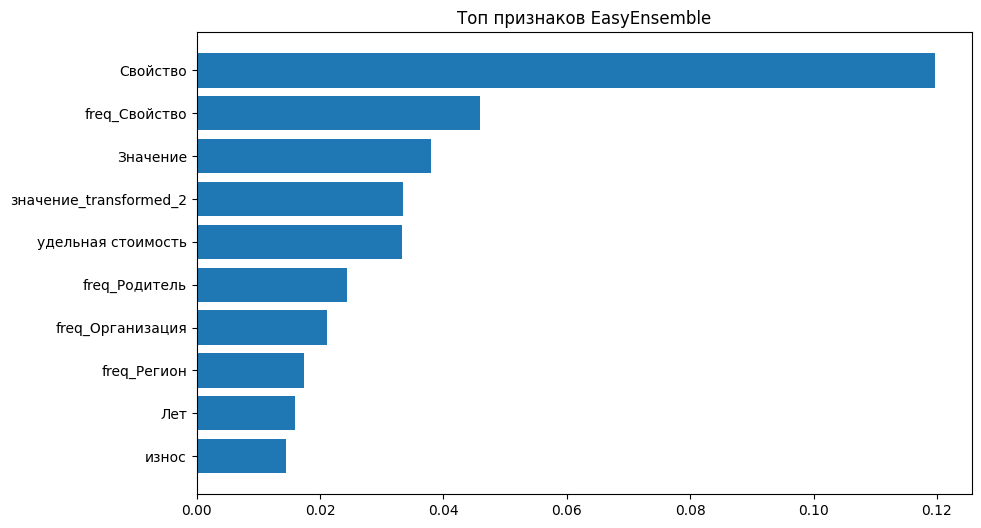

In [922]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [923]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,hgb,ros_shrinkage_005,0.4767,0.010,44.481,0.298
2,hgb,ros_shrinkage_01,0.4702,0.010,46.727,0.274
4,hgb,gaussian_noise,0.4696,0.010,12.775,0.080
3,hgb,ros_shrinkage_02,0.4677,0.010,43.394,0.249
0,hgb,ros,0.4521,0.003,39.790,0.168


In [926]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 3 candidates, totalling 9 fits


In [927]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.4518801784576163
Test accuracy: 0.4760672703751617
Время: 57.24127912521362


In [928]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': [100, 200, 300, 400, 500],
    'clf__learning_rate': [0.01, 0.1],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}

grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 300 candidates, totalling 600 fits


In [929]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__max_depth': None, 'clf__max_features': np.float64(0.1), 'clf__max_iter': 500, 'clf__min_samples_leaf': np.int64(1)}
Лучшая CV accuracy: 0.47291268323773106
Test accuracy: 0.49029754204398446
Время: 1584.8794968128204


In [930]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
12,Свойство,0.210867
4,удельная стоимость,0.065977
2,Значение,0.046141
8,freq_Регион,0.024795
7,значение_transformed_2,0.022639
11,Родитель,0.017680
0,Лет,0.017033
5,износ,0.009487
9,freq_Организация,0.007546
10,freq_Округ,0.007546


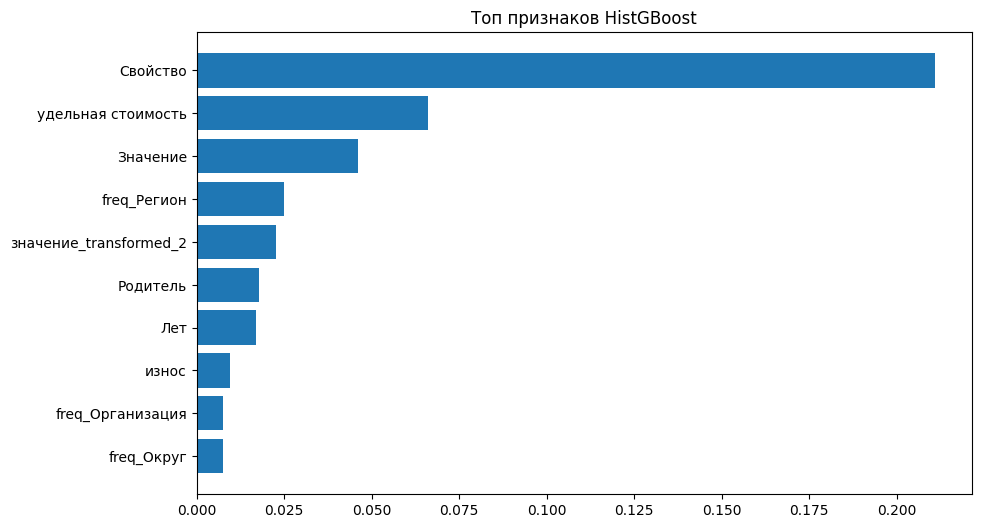

In [931]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [932]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,ada,gaussian_noise,0.4314,0.011,0.679,0.001
0,ada,ros,0.4069,0.005,0.135,0.004
3,ada,ros_shrinkage_02,0.4062,0.008,0.755,0.001
2,ada,ros_shrinkage_01,0.3984,0.008,0.734,0.001
1,ada,ros_shrinkage_005,0.3913,0.011,0.695,0.001


In [939]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best', 'random'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 6 candidates, totalling 60 fits


In [940]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'gini', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.3961081378075334
Test accuracy: 0.4217335058214748
Время: 3.858231782913208


In [941]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__estimator__min_samples_split': np.arange(2, 11, 1),
    'clf__estimator__min_samples_leaf': np.arange(1, 10, 1)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 810 candidates, totalling 1620 fits


In [942]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(0.8), 'clf__estimator__min_samples_leaf': np.int64(1), 'clf__estimator__min_samples_split': np.int64(4)}
Лучшая CV accuracy: 0.47259400892288084
Test accuracy: 0.49547218628719275
Время: 1677.5593888759613


In [944]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            max_features=0.8,
            max_depth=None,
            min_samples_leaf=1,
            min_samples_split=4,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(100, 600, 100),
    'clf__learning_rate': [0.001, 0.05, 0.1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 15 candidates, totalling 30 fits


In [945]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.1, 'clf__n_estimators': np.int64(400)}
Лучшая CV accuracy: 0.46685787125557676
Test accuracy: 0.5064683053040103
Время: 629.7098519802094


In [946]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
5,num__износ,0.168578
2,num__Значение,0.115072
4,num__удельная стоимость,0.109136
14,cat__Свойство,0.094335
13,cat__Родитель,0.088063
1,num__Стоимость,0.066127
7,num__значение_transformed_2,0.062826
0,num__Лет,0.061766
6,num__стоимость_transformed_2,0.060938
10,num__freq_Округ,0.056430


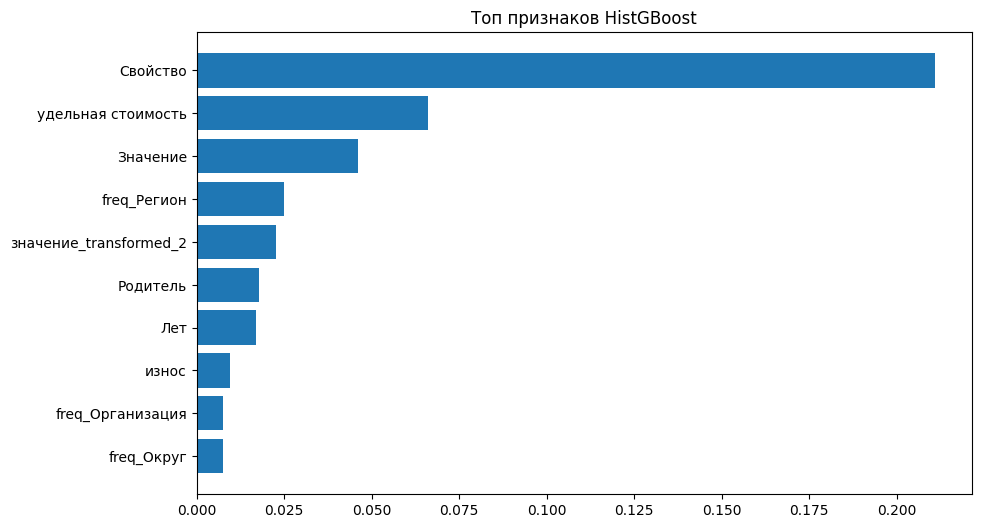

In [947]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### Keras (MLP)

In [948]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [949]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [950]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 744us/step
  acc=0.4043 | t=19.6s
keras+ros_shrinkage_005
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 795us/step
  acc=0.3719 | t=18.8s
keras+ros_shrinkage_01
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 670us/step
  acc=0.3907 | t=19.4s
keras+ros_shrinkage_02
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 702us/step
  acc=0.3726 | t=19.8s
keras+gaussian_noise
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 745us/step
  acc=0.3972 | t=19.6s

Лучшая балансировка: ros


In [962]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 10 folds for each of 9 candidates, totalling 90 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [963]:
best_activation = grid_strings.best_params_["clf__model__activation"]
best_optimizer  = grid_strings.best_params_["clf__model__optimizer"]

print(f"\nStrings grid time: {time.time() - start:.1f}s")
print("Best string params:", grid_strings.best_params_)

cv_strings_df = (pd.DataFrame(grid_strings.cv_results_)
                   .sort_values("rank_test_score")
                   .reset_index(drop=True))
cv_strings_df[["params", "mean_test_score", "std_test_score", "rank_test_score"]].head(10)


Strings grid time: 394.2s
Best string params: {'clf__model__activation': 'sigmoid', 'clf__model__optimizer': 'adam'}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'clf__model__activation': 'sigmoid', 'clf__mo...",0.386236,0.013865,1
1,"{'clf__model__activation': 'sigmoid', 'clf__mo...",0.385603,0.013327,2
2,"{'clf__model__activation': 'tanh', 'clf__model...",0.366159,0.018026,3
3,"{'clf__model__activation': 'tanh', 'clf__model...",0.365839,0.017484,4
4,"{'clf__model__activation': 'relu', 'clf__model...",0.365530,0.024030,5
5,"{'clf__model__activation': 'relu', 'clf__model...",0.333653,0.015946,6
6,"{'clf__model__activation': 'relu', 'clf__model...",0.325689,0.025198,7
7,"{'clf__model__activation': 'tanh', 'clf__model...",0.300826,0.020396,8
8,"{'clf__model__activation': 'sigmoid', 'clf__mo...",0.072335,0.015910,9


In [964]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'sigmoid', 'clf__model__optimizer': 'adam'}
Лучшая CV accuracy: 0.3862355263425653
Test accuracy: 0.38421733505821476
Время: 629.7098519802094


In [965]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation=best_activation,
        model__optimizer=best_optimizer,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [128, 256, 512],
    "clf__model__learning_rate": [0.001, 0.005, 0.01],
    "clf__batch_size":           [64, 128, 256],
    "clf__epochs":               [50, 100, 200],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 2 folds for each of 81 candidates, totalling 162 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [64, 128, ...], 'clf__epochs': [50, 100, ...], 'clf__model__learning_rate': [0.001, 0.005, ...], 'clf__model__n_size': [128, 256, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [966]:
print(f"\nNumeric grid time: {time.time() - start:.1f}s")
print("Best numeric params:", grid_numeric.best_params_)

cv_numeric_df = (pd.DataFrame(grid_numeric.cv_results_)
                   .sort_values("rank_test_score")
                   .reset_index(drop=True))
print(cv_numeric_df[["params", "mean_test_score", "std_test_score", "rank_test_score"]].head(10))

y_pred_final = grid_numeric.best_estimator_.predict(X_test)
print(f"accuracy : {accuracy_score(y_test, y_pred_final):.4f}")


Numeric grid time: 1250.9s
Best numeric params: {'clf__batch_size': 256, 'clf__epochs': 200, 'clf__model__learning_rate': 0.005, 'clf__model__n_size': 512}
... (вывод сокращён: 13 строк) ...
0        0.010198                1  
1        0.001912                2  
2        0.001912                3  
3        0.003187                4  
4        0.007648                5  
5        0.004143                6  
6        0.002868                7  
7        0.003187                8  
8        0.002549                9  
9        0.009242               10  
accuracy : 0.4276


In [967]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 256, 'clf__epochs': 200, 'clf__model__learning_rate': 0.005, 'clf__model__n_size': 512}
Лучшая CV accuracy: 0.4117272147864882
Test accuracy: 0.42755498059508407
Время: 629.7098519802094


In [968]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
14,Свойство,0.153083
7,значение_transformed_2,0.098965
11,freq_Свойство,0.074817
6,стоимость_transformed_2,0.072229
13,Родитель,0.062527
15,категории стоимости,0.055412
0,Лет,0.049159
16,категории возраста,0.043553
2,Значение,0.041613
4,удельная стоимость,0.031910


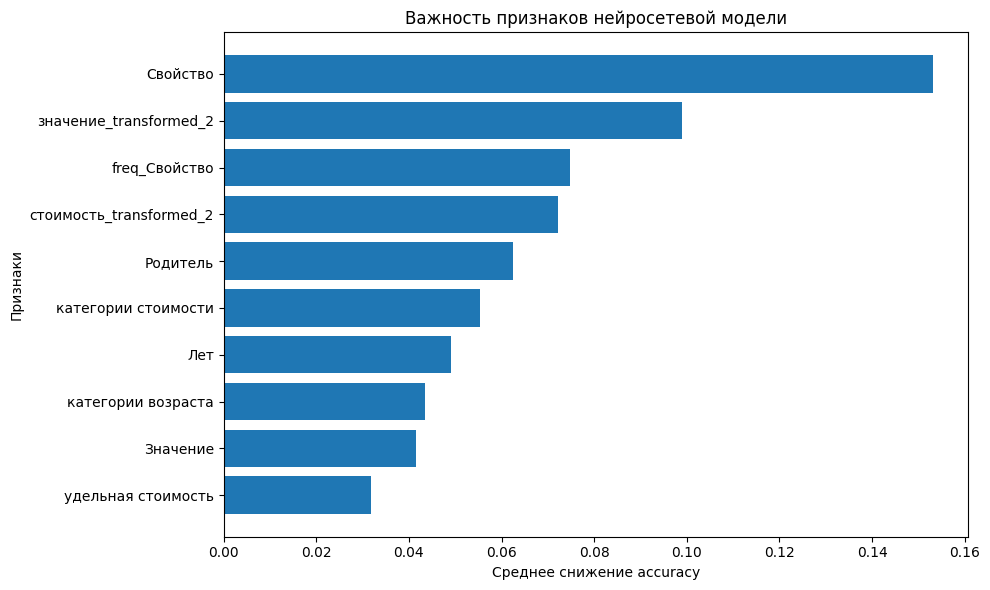

In [969]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

## Подвыборка «м»: редкие классы

In [272]:
target_col = "Наименование"

class_counts = processed[('м', 'rare')]['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
processed[('м', 'rare')]['Наименование'] = processed[('м', 'rare')]['Наименование'].where(
    ~processed[('м', 'rare')]['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(processed[('м', 'rare')]['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 0
Объектов с меткой 'редкий': 11


In [273]:
X = processed[('м', 'rare')].drop(columns=[target_col])
y = processed[('м', 'rare')][target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.3,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (471, 18) y_train: (471,)
X_test: (202, 18) y_test: (202,)


In [274]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [275]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = [
    'Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость', 'износ',
    'стоимость_transformed_2', 'значение_transformed_2', 'freq_Регион',
    'freq_Родитель', 'Организация', 'Свойство', 'Округ', 'категории стоимости',
    'категории возраста'
]

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'удельная стоимость', 'износ',
                       'стоимость_transformed_2', 'значение_transformed_2', 'freq_Регион',
                       'freq_Родитель']
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Организация', 'Свойство', 'Округ']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [291]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,svm,ros,0.2574,0.002,0.055,0.022
4,svm,gaussian_noise,0.2327,0.003,0.045,0.019
1,svm,ros_shrinkage_005,0.1980,0.007,0.059,0.027
2,svm,ros_shrinkage_01,0.1881,0.004,0.061,0.026
3,svm,ros_shrinkage_02,0.1832,0.003,0.067,0.027


In [292]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 8 candidates, totalling 80 fits


In [293]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'linear'}
Лучшая CV accuracy: 0.23980496453900707
Время (сек): 0.9505228996276855
Test accuracy: 0.21782178217821782


In [299]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123)),  
    ('clf', SVC(
        kernel='linear',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': np.arange(1, 51, 2),    
    'clf__tol': [1e-1, 1e-2, 1e-3, 1e-4],          
    'clf__max_iter': np.arange(1, 51, 2),
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 2500 candidates, totalling 5000 fits


... (вывод сокращён: 17 строк) ...













In [300]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)
y_pred_test = grid_svm2.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_acc)
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': np.int64(7), 'clf__max_iter': np.int64(49), 'clf__tol': 0.1}
Лучшая CV accuracy: 0.24844031734583483
Test accuracy: 0.22772277227722773
Время обучения (сек): 18.89622211456299


In [301]:
pipe = grid_svm2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

importances = np.abs(model.coef_).mean(axis=0)

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
7,num__значение_transformed_2,0.273459
10,num__freq_Родитель,0.264856
4,num__удельная стоимость,0.260750
0,num__Лет,0.222722
8,num__freq_Регион,0.209913
2,num__Значение,0.205786
9,num__freq_Организация,0.195839
6,num__стоимость_transformed_2,0.195414
49,cat__категории возраста_среднее,0.195068
46,cat__категории стоимости_средняя,0.193707


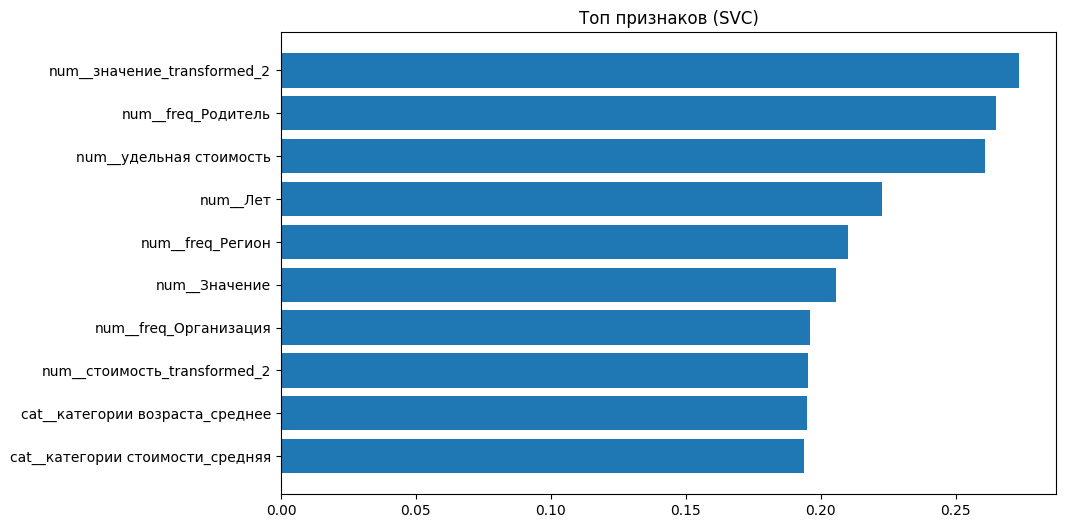

In [302]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [303]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,knn,gaussian_noise,0.1931,0.004,0.0,0.002
1,knn,ros_shrinkage_005,0.1881,0.006,0.0,0.004
0,knn,ros,0.1832,0.002,0.0,0.009
2,knn,ros_shrinkage_01,0.1832,0.004,0.0,0.002
3,knn,ros_shrinkage_02,0.1733,0.004,0.0,0.004


In [306]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [307]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'distance'}
Лучшая CV accuracy: 0.2059953119365308
Test accuracy: 0.22772277227722773
Время: 0.2436659336090088


In [315]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='distance',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(1, 31, 1),
    'clf__metric': ['euclidean', 'manhattan', 'chebyshev'],
    'clf__leaf_size': np.arange(1, 31, 1)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 2700 candidates, totalling 5400 fits


... (вывод сокращён: 12 строк) ...













In [316]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(1), 'clf__metric': 'manhattan', 'clf__n_neighbors': np.int64(4)}
Лучшая CV accuracy: 0.24844031734583483
Test accuracy: 0.24257425742574257
Время: 11.856273889541626


In [317]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
8,freq_Регион,0.031353
10,freq_Родитель,0.028053
7,значение_transformed_2,0.021452
14,Свойство,0.019802
11,freq_Свойство,0.016502
16,категории стоимости,0.013201
6,стоимость_transformed_2,0.011551
3,if_anomaly,0.009901
0,Лет,0.008251
2,Значение,0.008251


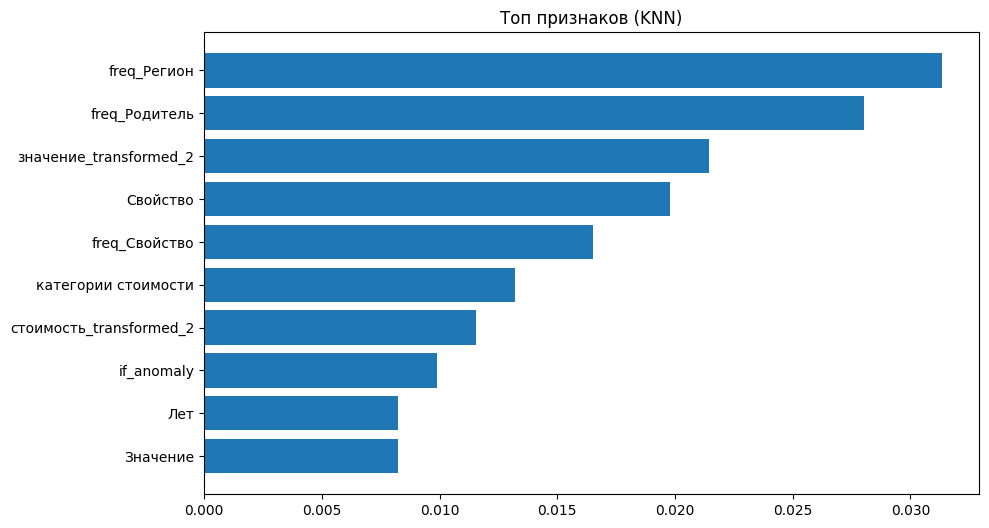

In [318]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [319]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,tree,ros_shrinkage_02,0.2673,0.003,0.037,0.0
2,tree,ros_shrinkage_01,0.2525,0.003,0.038,0.0
0,tree,ros,0.2475,0.004,0.014,0.0
1,tree,ros_shrinkage_005,0.2277,0.003,0.037,0.0
4,tree,gaussian_noise,0.2277,0.003,0.039,0.0


In [324]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 6 candidates, totalling 30 fits


In [325]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.24201567749160136
Test accuracy: 0.26732673267326734
Время: 0.32308292388916016


In [357]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='gini',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': [1, 3, 5, 10, 20, 30],
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 11, 2)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 1500 candidates, totalling 4500 fits


... (вывод сокращён: 19 строк) ...













In [358]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': 20, 'clf__max_features': np.float64(0.5), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.24416135881104037
Test accuracy: 0.24257425742574257
Время: 9.973797798156738


In [359]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
10,num__freq_Родитель,0.118772
2,num__Значение,0.100076
7,num__значение_transformed_2,0.094784
0,num__Лет,0.094641
4,num__удельная стоимость,0.084490
5,num__износ,0.072990
16,cat__Свойство,0.067138
1,num__Стоимость,0.054478
8,num__freq_Регион,0.046677
9,num__freq_Организация,0.040822


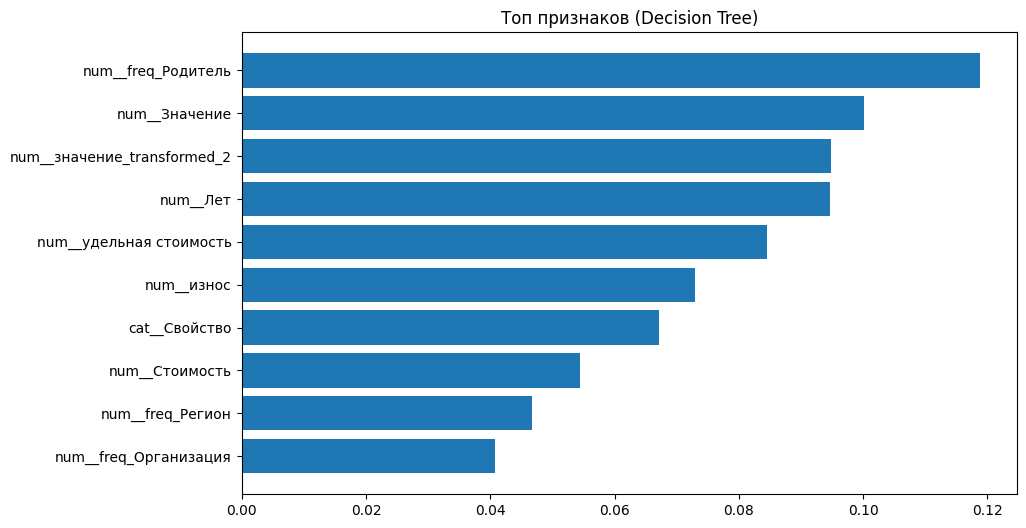

In [360]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [361]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,rf,gaussian_noise,0.3218,0.003,0.143,0.013
0,rf,ros,0.3119,0.002,0.089,0.015
3,rf,ros_shrinkage_02,0.3119,0.003,0.155,0.015
1,rf,ros_shrinkage_005,0.2970,0.003,0.113,0.015
2,rf,ros_shrinkage_01,0.2822,0.003,0.139,0.015


In [364]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 3 candidates, totalling 9 fits


In [ ]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini'}
Лучшая CV accuracy: 0.31422505307855625
Test accuracy: 0.3217821782178218
Время: 3.157012939453125


In [367]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': [100, 200, 300],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__max_samples': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 1875 candidates, totalling 5625 fits









In [368]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.2), 'clf__max_samples': np.float64(0.8), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(8), 'clf__n_estimators': 300}
Лучшая CV accuracy: 0.31422505307855625
Test accuracy: 0.32673267326732675
Время: 714.9568088054657


In [369]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
4,num__удельная стоимость,0.087699
2,num__Значение,0.085924
0,num__Лет,0.081738
1,num__Стоимость,0.072377
5,num__износ,0.068095
7,num__значение_transformed_2,0.065160
9,num__freq_Организация,0.053192
13,ord__категории стоимости,0.052629
10,num__freq_Родитель,0.051953
14,ord__категории возраста,0.050510


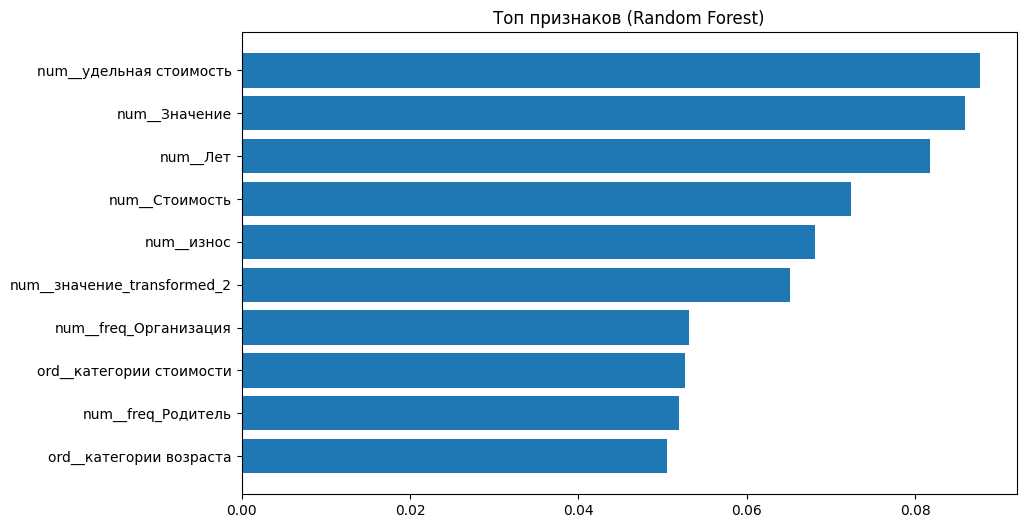

In [370]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [373]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,rtf,ros_shrinkage_005,0.3119,0.003,1.791,0.103
2,rtf,ros_shrinkage_01,0.3069,0.003,1.648,0.102
3,rtf,ros_shrinkage_02,0.3069,0.003,1.641,0.103
4,rtf,gaussian_noise,0.3069,0.002,2.087,0.104
0,rtf,ros,0.2970,0.002,1.483,0.112


In [381]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best", "random"],
    "model__pca_solver": ["auto", "full", "randomized"],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 18 candidates, totalling 36 fits


In [382]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'entropy', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'auto'}
Лучшая CV accuracy: 0.3057428777497295
Test accuracy: 0.3118811881188119
Время: 16.32701086997986


In [383]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              random_state=123),
        pca_solver='auto',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.1, 1.1, 0.1), 
    'model__base_estimator__min_samples_split': np.arange(2, 11, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 250 candidates, totalling 500 fits


In [384]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(0.2), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.3015326361341507
Test accuracy: 0.32673267326732675
Время: 160.23922419548035


In [401]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='entropy',
                                              splitter='best',
                                              max_features=0.2,
                                              max_depth=None,
                                              min_samples_leaf=1,
                                              min_samples_split=2,
                                              random_state=123),
        pca_solver='auto',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": np.arange(25, 125, 25),
    "model__min_group": [1, 2, 3, 4, 5],
    "model__max_group": [1, 2, 3, 4, 5],
    "model__remove_proportion": np.arange(0.1, 1.0, 0.1),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 900 candidates, totalling 2700 fits









In [402]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 3, 'model__min_group': 3, 'model__n_estimators': np.int64(50), 'model__remove_proportion': np.float64(0.6000000000000001)}
Лучшая CV accuracy: 0.32696390658174096
Test accuracy: 0.30198019801980197
Время: 158.07630610466003


In [398]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=6
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
10,freq_Родитель,0.044554
16,категории стоимости,0.041254
2,Значение,0.034653
12,freq_Округ,0.031353
7,значение_transformed_2,0.029703
11,freq_Свойство,0.029703
4,удельная стоимость,0.028053
6,стоимость_transformed_2,0.021452
8,freq_Регион,0.021452
15,Округ,0.019802


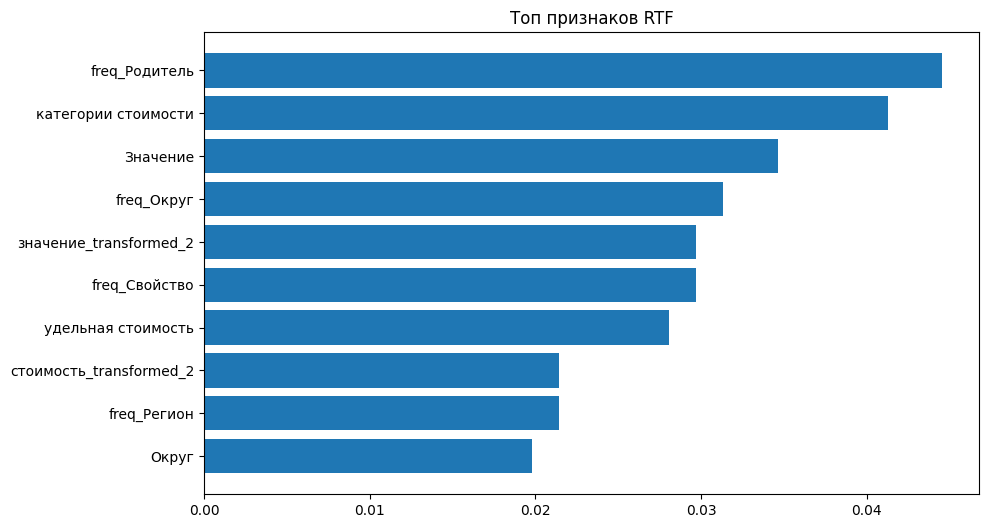

In [399]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [408]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,extra,gaussian_noise,0.2723,0.002,0.079,0.015
0,extra,ros,0.2673,0.002,0.118,0.014
1,extra,ros_shrinkage_005,0.2624,0.003,0.078,0.016
2,extra,ros_shrinkage_01,0.2574,0.003,0.084,0.014
3,extra,ros_shrinkage_02,0.2376,0.003,0.080,0.014


In [409]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 6 candidates, totalling 18 fits


In [410]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': True, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.29936305732484075
Test accuracy: 0.31683168316831684
Время: 0.7111108303070068


In [415]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=True,
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": [100, 200, 300, 400],
    "model__max_depth": [None],
    'model__max_features': np.arange(0.1, 1.1, 0.1),
    'model__max_samples': np.arange(0.1, 1.1, 0.1),
    'model__min_samples_split': np.arange(2, 11, 2),
    'model__min_samples_leaf': np.arange(1, 10, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 10000 candidates, totalling 30000 fits


... (вывод сокращён: 14 строк) ...













In [416]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(0.5), 'model__max_samples': np.float64(0.9), 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(6), 'model__n_estimators': 100}
Лучшая CV accuracy: 0.31634819532908703
Test accuracy: 0.30198019801980197
Время: 1250.863472700119


In [417]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
4,num__удельная стоимость,0.081246
0,num__Лет,0.074623
14,ord__категории возраста,0.072106
13,ord__категории стоимости,0.070779
9,num__freq_Организация,0.068105
2,num__Значение,0.061486
10,num__freq_Родитель,0.056844
1,num__Стоимость,0.055402
8,num__freq_Регион,0.053140
12,num__freq_Округ,0.050312


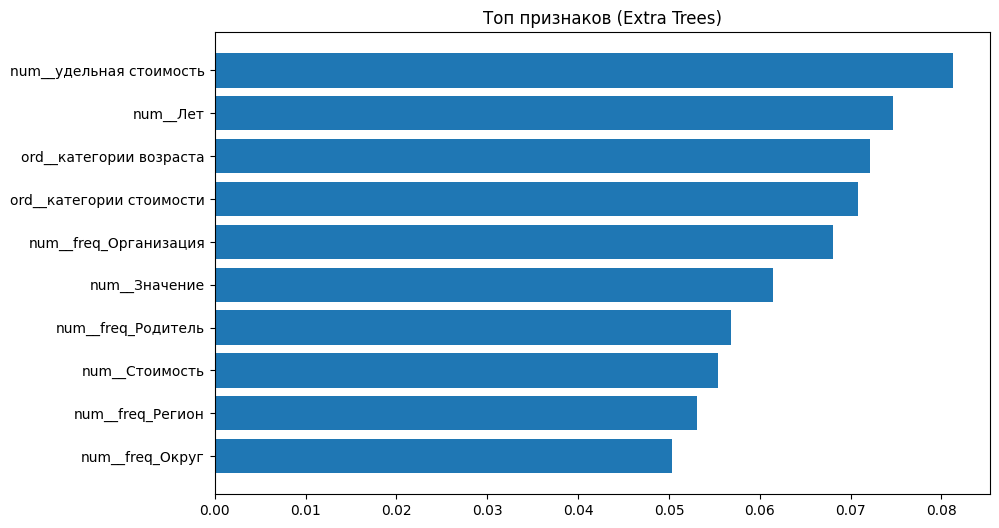

In [418]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [420]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
2,easy_ensemble,ros_shrinkage_01,0.2574,0.003,0.098,0.013
3,easy_ensemble,ros_shrinkage_02,0.2525,0.003,0.073,0.024
0,easy_ensemble,ros,0.2475,0.002,0.075,0.025
4,easy_ensemble,gaussian_noise,0.2426,0.002,0.099,0.013
1,easy_ensemble,ros_shrinkage_005,0.2376,0.003,0.102,0.025


In [425]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.1, random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 12 candidates, totalling 60 fits


In [426]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'entropy', 'model__estimator__splitter': 'best', 'model__replacement': True}
Лучшая CV accuracy: 0.29715565509518477
Test accuracy: 0.28217821782178215
Время: 4.576627969741821


In [427]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.1, random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='entropy',
                                         splitter='best',
                                         random_state=123),
        replacement=True,
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": [25, 50, 75, 100],
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.1, 1.1, 0.1),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1000 candidates, totalling 2000 fits






In [428]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(0.2), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(2), 'model__n_estimators': 50}
Лучшая CV accuracy: 0.29300396682293545
Test accuracy: 0.29207920792079206
Время: 136.24173283576965


In [429]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
4,удельная стоимость,0.051155
14,Свойство,0.036304
11,freq_Свойство,0.028053
2,Значение,0.026403
10,freq_Родитель,0.019802
7,значение_transformed_2,0.018152
9,freq_Организация,0.011551
6,стоимость_transformed_2,0.011551
0,Лет,0.011551
16,категории стоимости,0.009901


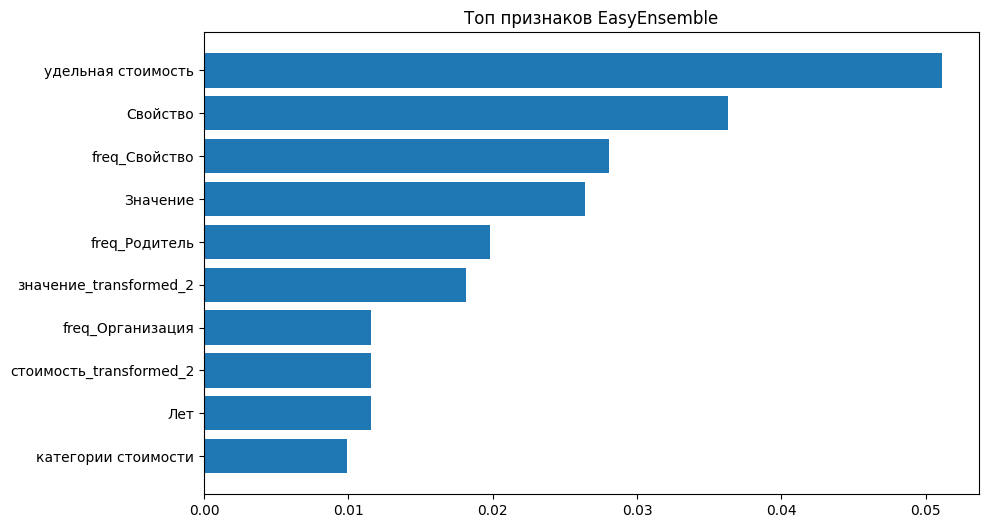

In [430]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [433]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
2,hgb,ros_shrinkage_01,0.2822,0.003,64.269,0.516
1,hgb,ros_shrinkage_005,0.2723,0.003,57.604,0.383
0,hgb,ros,0.2624,0.002,59.436,0.584
3,hgb,ros_shrinkage_02,0.2624,0.003,56.984,0.526
4,hgb,gaussian_noise,0.2376,0.002,23.051,0.202


In [436]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.1, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto', 'binary_crossentropy', 'categorical_crossentropy'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 5 candidates, totalling 15 fits


In [437]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.25902335456475584
Test accuracy: 0.30198019801980197
Время: 47.763017892837524


In [441]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': [200, 300, 400, 500],
    'clf__learning_rate': [0.01, 0.1],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}

grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 240 candidates, totalling 480 fits


In [442]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__max_depth': None, 'clf__max_features': np.float64(0.1), 'clf__max_iter': 200, 'clf__min_samples_leaf': np.int64(5)}
Лучшая CV accuracy: 0.2717634331049405
Test accuracy: 0.30198019801980197
Время: 549.0604741573334


In [443]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
9,freq_Родитель,0.049505
4,удельная стоимость,0.039604
11,Свойство,0.033003
2,Значение,0.029703
13,категории стоимости,0.028053
1,Стоимость,0.024752
5,износ,0.021452
0,Лет,0.018152
12,Округ,0.006601
6,стоимость_transformed_2,0.004950


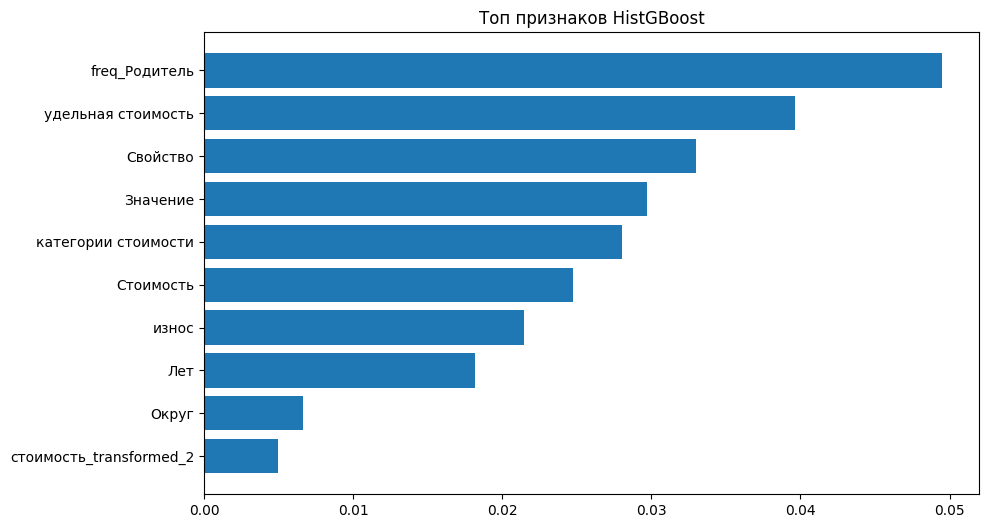

In [444]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [445]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,ada,gaussian_noise,0.2624,0.002,0.038,0.000
3,ada,ros_shrinkage_02,0.2228,0.003,0.040,0.000
1,ada,ros_shrinkage_005,0.2129,0.003,0.035,0.000
0,ada,ros,0.2079,0.015,0.033,0.000
2,ada,ros_shrinkage_01,0.2079,0.003,0.043,0.001


In [459]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best', 'random'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 6 candidates, totalling 18 fits


In [460]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'gini', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.2016985138004246
Test accuracy: 0.2079207920792079
Время: 0.2689962387084961


In [465]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__estimator__min_samples_split': np.arange(2, 11, 1),
    'clf__estimator__min_samples_leaf': np.arange(1, 10, 1)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 810 candidates, totalling 1620 fits


In [466]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(0.9), 'clf__estimator__min_samples_leaf': np.int64(1), 'clf__estimator__min_samples_split': np.int64(5)}
Лучшая CV accuracy: 0.29300396682293545
Test accuracy: 0.3069306930693069
Время: 105.39520812034607


In [471]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            max_features=0.9,
            max_depth=None,
            min_samples_leaf=1,
            min_samples_split=5,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(100, 1100, 100),
    'clf__learning_rate': [0.001, 0.05, 0.1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 30 candidates, totalling 60 fits


In [472]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.05, 'clf__n_estimators': np.int64(900)}
Лучшая CV accuracy: 0.27811034980165883
Test accuracy: 0.3069306930693069
Время: 154.46335124969482


In [473]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
6,num__значение_transformed_2,0.132312
3,num__удельная стоимость,0.116166
11,cat__Организация,0.106505
12,cat__Свойство,0.105018
4,num__износ,0.083241
2,num__Значение,0.074814
13,cat__Округ,0.071423
1,num__Стоимость,0.070945
5,num__стоимость_transformed_2,0.067421
8,num__freq_Родитель,0.066174


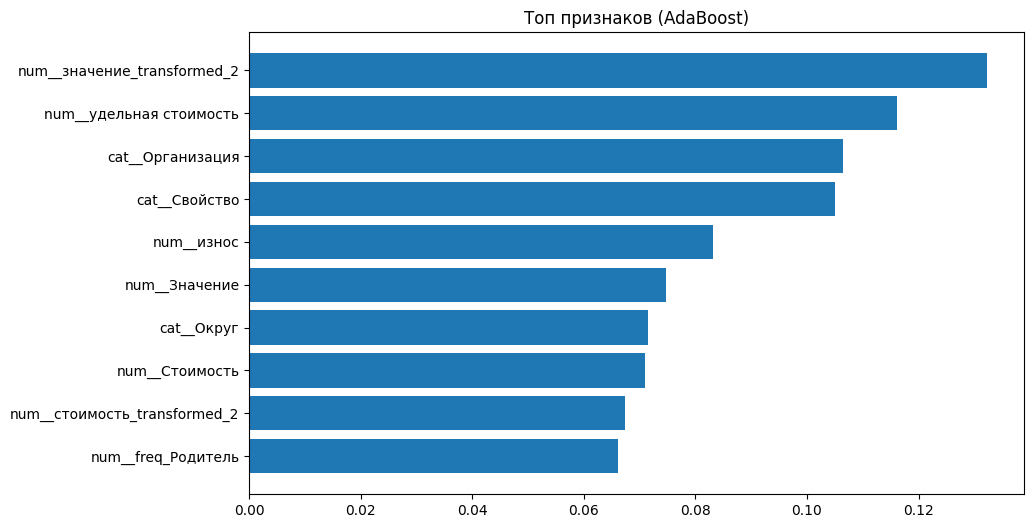

In [474]:
top_n = 10
top_features = feat_imp_ada.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (AdaBoost)")
plt.show()

### Keras (MLP)

In [476]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [477]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [478]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
  acc=0.1980 | t=3.5s
... (вывод сокращён: 5 строк) ...
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
  acc=0.1881 | t=2.9s
keras+ros_shrinkage_02
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
  acc=0.2277 | t=2.9s
keras+gaussian_noise
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
  acc=0.2228 | t=2.9s

Лучшая балансировка: ros_shrinkage_02


In [482]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(shrinkage=0.2, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 3 folds for each of 9 candidates, totalling 27 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [480]:
best_activation = grid_strings.best_params_["clf__model__activation"]
best_optimizer  = grid_strings.best_params_["clf__model__optimizer"]

print(f"\nStrings grid time: {time.time() - start:.1f}s")
print("Best string params:", grid_strings.best_params_)

cv_strings_df = (pd.DataFrame(grid_strings.cv_results_)
                   .sort_values("rank_test_score")
                   .reset_index(drop=True))
cv_strings_df[["params", "mean_test_score", "std_test_score", "rank_test_score"]].head(10)


Strings grid time: 48.7s
Best string params: {'clf__model__activation': 'tanh', 'clf__model__optimizer': 'adam'}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'clf__model__activation': 'tanh', 'clf__model...",0.246304,0.009016,1
1,"{'clf__model__activation': 'relu', 'clf__model...",0.242021,0.007979,2
2,"{'clf__model__activation': 'sigmoid', 'clf__mo...",0.235656,0.005869,3
3,"{'clf__model__activation': 'tanh', 'clf__model...",0.229327,0.013226,4
4,"{'clf__model__activation': 'sigmoid', 'clf__mo...",0.201740,0.019537,5
5,"{'clf__model__activation': 'relu', 'clf__model...",0.199594,0.008916,6
6,"{'clf__model__activation': 'relu', 'clf__model...",0.123179,0.017247,7
7,"{'clf__model__activation': 'tanh', 'clf__model...",0.104030,0.001902,8
8,"{'clf__model__activation': 'sigmoid', 'clf__mo...",0.029688,0.016922,9


In [483]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'tanh', 'clf__model__optimizer': 'adam'}
Лучшая CV accuracy: 0.23566878980891723
Test accuracy: 0.2524752475247525
Время: 154.46335124969482


In [488]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(shrinkage=0.2, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation=best_activation,
        model__optimizer=best_optimizer,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [128, 256, 512],
    "clf__model__learning_rate": [0.001, 0.005, 0.01],
    "clf__batch_size":           [64, 128, 256],
    "clf__epochs":               [50, 100, 200],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 2 folds for each of 81 candidates, totalling 162 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [64, 128, ...], 'clf__epochs': [50, 100, ...], 'clf__model__learning_rate': [0.001, 0.005, ...], 'clf__model__n_size': [128, 256, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [489]:
print(f"\nNumeric grid time: {time.time() - start:.1f}s")
print("Best numeric params:", grid_numeric.best_params_)

cv_numeric_df = (pd.DataFrame(grid_numeric.cv_results_)
                   .sort_values("rank_test_score")
                   .reset_index(drop=True))
print(cv_numeric_df[["params", "mean_test_score", "std_test_score", "rank_test_score"]].head(10))

y_pred_final = grid_numeric.best_estimator_.predict(X_test)
print(f"accuracy : {accuracy_score(y_test, y_pred_final):.4f}")


Numeric grid time: 302.4s
Best numeric params: {'clf__batch_size': 128, 'clf__epochs': 200, 'clf__model__learning_rate': 0.01, 'clf__model__n_size': 128}
... (вывод сокращён: 13 строк) ...
0        0.021809                1  
1        0.004814                2  
2        0.001560                3  
3        0.004805                4  
4        0.019663                5  
5        0.006924                6  
6        0.009043                7  
7        0.009043                7  
8        0.009043                7  
9        0.019654               10  
accuracy : 0.2673


In [490]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 128, 'clf__epochs': 200, 'clf__model__learning_rate': 0.01, 'clf__model__n_size': 128}
Лучшая CV accuracy: 0.27180851063829786
Test accuracy: 0.26732673267326734
Время: 154.46335124969482


In [492]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
16,категории стоимости,0.066007
11,freq_Свойство,0.061056
10,freq_Родитель,0.047855
12,freq_Округ,0.034653
0,Лет,0.033003
2,Значение,0.033003
8,freq_Регион,0.033003
1,Стоимость,0.031353
4,удельная стоимость,0.026403
17,категории возраста,0.024752


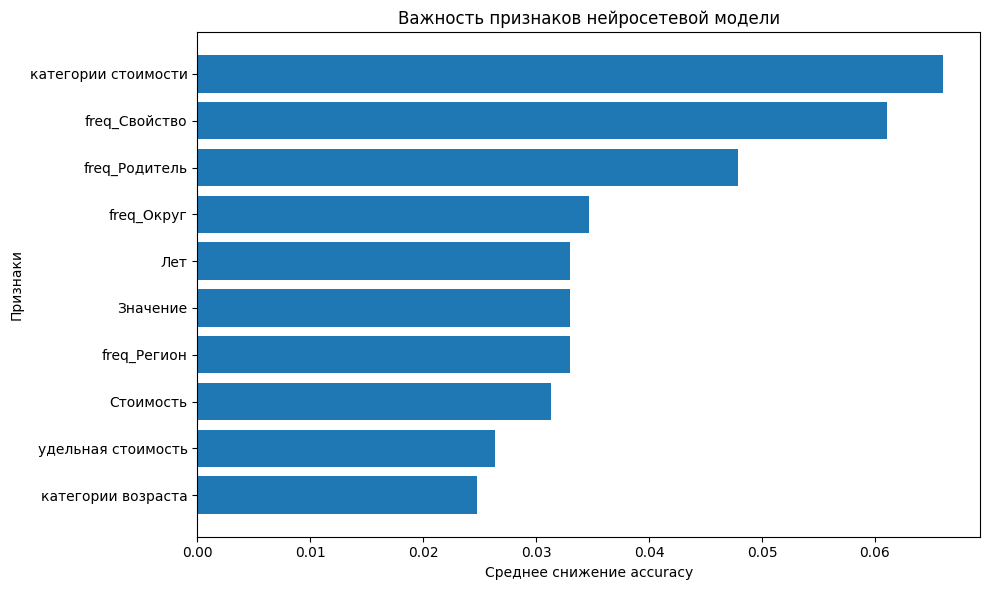

In [494]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

## Подвыборка «м²»: нормальные классы

In [478]:
target_col = "Наименование"

class_counts = processed[('м2', 'normal')]['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
processed[('м2', 'normal')]['Наименование'] = processed[('м2', 'normal')]['Наименование'].where(
    ~processed[('м2', 'normal')]['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(processed[('м2', 'normal')]['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 11
Объектов с меткой 'редкий': 29


In [479]:
X = processed[('м2', 'normal')].drop(columns=[target_col])
y = processed[('м2', 'normal')][target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.3,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (941, 15) y_train: (941,)
X_test: (404, 15) y_test: (404,)


In [480]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [481]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = [
    'Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Организация', 'freq_Родитель', 'freq_Округ',
       'Регион', 'категории стоимости', 'категории возраста'
]

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Организация', 'freq_Родитель', 'freq_Округ']
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Регион']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [498]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,svm,gaussian_noise,0.5099,0.097,0.954,0.196
0,svm,ros,0.4480,0.018,1.669,0.773
1,svm,ros_shrinkage_005,0.4381,0.038,1.982,0.965
2,svm,ros_shrinkage_01,0.4356,0.047,2.148,0.969
3,svm,ros_shrinkage_02,0.4233,0.035,2.495,1.072


In [499]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 8 candidates, totalling 80 fits


In [500]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'rbf'}
Лучшая CV accuracy: 0.490929451287794
Время (сек): 20.067059993743896
Test accuracy: 0.5099009900990099


In [501]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(
        kernel='rbf',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': np.arange(1, 51, 10),
    'clf__gamma': [1e-1, 1e-2, 1e-3, 1e-4],
    'clf__tol': [1e-1, 1e-2, 1e-3, 1e-4],          
    'clf__max_iter': np.arange(1, 51, 10),
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 400 candidates, totalling 800 fits



In [502]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)
y_pred_test = grid_svm2.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_acc)
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': np.int64(31), 'clf__gamma': 0.1, 'clf__max_iter': np.int64(31), 'clf__tol': 0.1}
Лучшая CV accuracy: 0.4739553688394995
Test accuracy: 0.5198019801980198
Время обучения (сек): 98.26647400856018


In [505]:
pipe = grid_svm2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
})

feat_imp = feat_imp.sort_values(
    "importance",
    ascending=False
)

feat_imp.head(10)

,feature,importance
7,значение_transformed_2,0.096535
4,удельная стоимость,0.085809
0,Лет,0.039604
13,категории стоимости,0.037954
6,стоимость_transformed_2,0.024752
3,if_anomaly,0.018977
2,Значение,0.014851
9,freq_Организация,0.008251
1,Стоимость,0.006601
10,freq_Родитель,0.006601


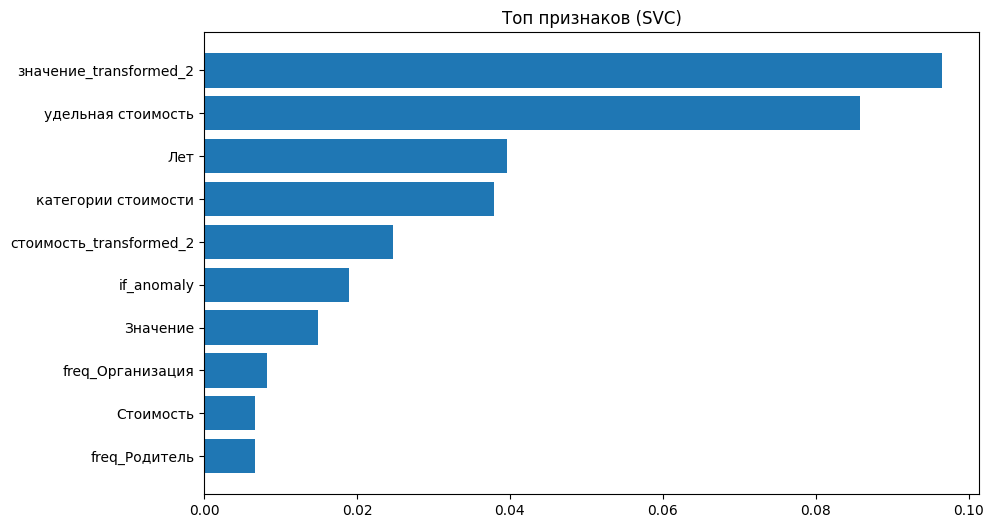

In [506]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [507]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,knn,gaussian_noise,0.4307,0.090,0.003,0.015
0,knn,ros,0.3787,0.010,0.004,0.020
1,knn,ros_shrinkage_005,0.3713,0.042,0.002,0.016
2,knn,ros_shrinkage_01,0.3688,0.036,0.002,0.015
3,knn,ros_shrinkage_02,0.3639,0.036,0.002,0.015


In [510]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [511]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'distance'}
Лучшая CV accuracy: 0.46227861324216707
Test accuracy: 0.48514851485148514
Время: 1.3996002674102783


In [515]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='distance',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(1, 31, 2),
    'clf__metric': ['euclidean', 'manhattan', 'chebyshev'],
    'clf__leaf_size': np.arange(1, 31, 2)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 675 candidates, totalling 2025 fits






In [516]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(1), 'clf__metric': 'manhattan', 'clf__n_neighbors': np.int64(7)}
Лучшая CV accuracy: 0.4845953480800147
Test accuracy: 0.5
Время: 71.98546504974365


In [ ]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
7,значение_transformed_2,0.075908
4,удельная стоимость,0.052805
13,категории стоимости,0.051155
0,Лет,0.032178
2,Значение,0.029703
6,стоимость_transformed_2,0.028053
9,freq_Организация,0.023927
14,категории возраста,0.022277
10,freq_Родитель,0.018152
3,if_anomaly,0.016502


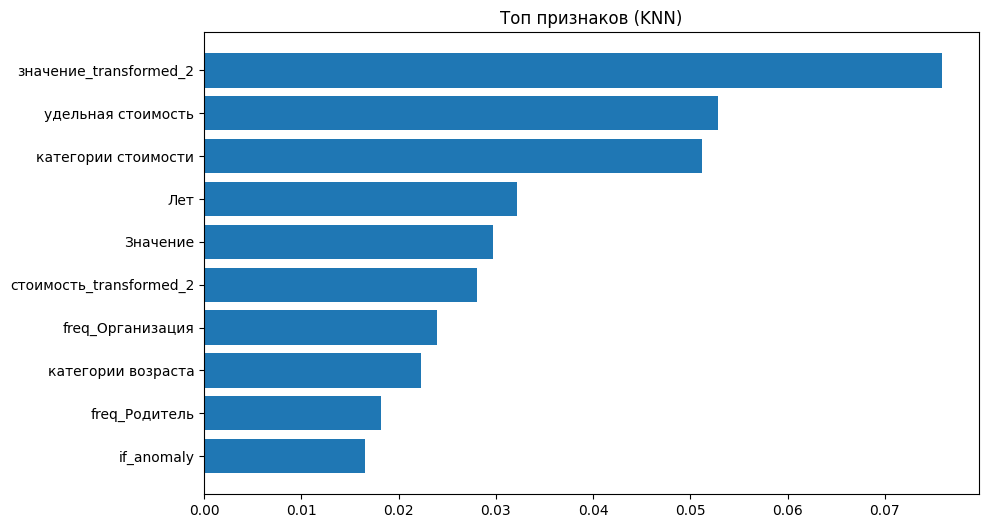

In [518]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [519]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,tree,ros,0.5347,0.004,0.080,0.0
3,tree,ros_shrinkage_02,0.5173,0.012,1.144,0.0
1,tree,ros_shrinkage_005,0.5025,0.016,1.064,0.0
4,tree,gaussian_noise,0.5025,0.015,1.073,0.0
2,tree,ros_shrinkage_01,0.4851,0.015,1.106,0.0


In [526]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [527]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.46758594208790716
Test accuracy: 0.5346534653465347
Время: 0.17457890510559082


In [534]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='gini',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': [1, 3, 5, 10, 20, 30, 50],
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_split': np.arange(2, 11, 1),
    'clf__min_samples_leaf': np.arange(1, 11, 1)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6300 candidates, totalling 12600 fits


... (вывод сокращён: 48 строк) ...













In [535]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': 30, 'clf__max_features': np.float64(0.7000000000000001), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.46864525455120387
Test accuracy: 0.5371287128712872
Время: 38.84269118309021


In [536]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
1,num__Стоимость,0.130951
7,num__значение_transformed_2,0.124104
5,num__износ,0.119720
6,num__стоимость_transformed_2,0.118254
2,num__Значение,0.101784
4,num__удельная стоимость,0.094463
0,num__Лет,0.077721
8,num__freq_Регион,0.053332
10,num__freq_Родитель,0.052347
9,num__freq_Организация,0.043008


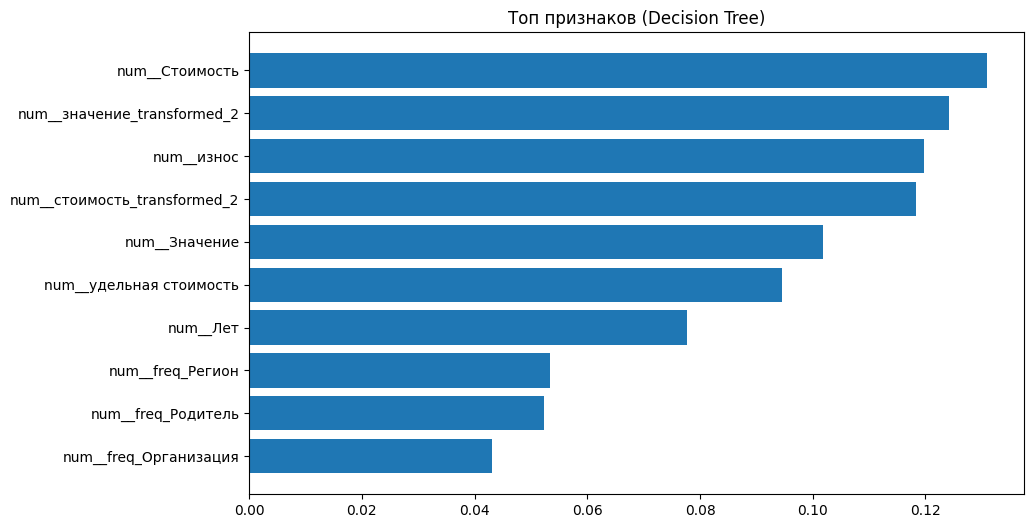

In [537]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [482]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rf,ros,0.5866,0.006,0.281,0.015
4,rf,gaussian_noise,0.5743,0.018,1.321,0.014
1,rf,ros_shrinkage_005,0.5693,0.012,1.701,0.014
3,rf,ros_shrinkage_02,0.5668,0.011,1.391,0.014
2,rf,ros_shrinkage_01,0.5644,0.011,1.362,0.014


In [483]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 3 candidates, totalling 6 fits


In [484]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'entropy'}
Лучшая CV accuracy: 0.5324117992501243
Test accuracy: 0.5866336633663366
Время: 0.7080297470092773


In [485]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='entropy',
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': [200, 300, 400, 500],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__max_samples': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 2500 candidates, totalling 5000 fits





In [546]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.2), 'clf__max_samples': np.float64(1.0), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4), 'clf__n_estimators': 300}
Лучшая CV accuracy: 0.5409156615620906
Test accuracy: 0.594059405940594
Время: 2470.4640510082245


In [547]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
2,num__Значение,0.121063
7,num__значение_transformed_2,0.115187
1,num__Стоимость,0.103306
4,num__удельная стоимость,0.102625
5,num__износ,0.101606
6,num__стоимость_transformed_2,0.099390
0,num__Лет,0.073300
10,num__freq_Родитель,0.062968
9,num__freq_Организация,0.050792
8,num__freq_Регион,0.042041


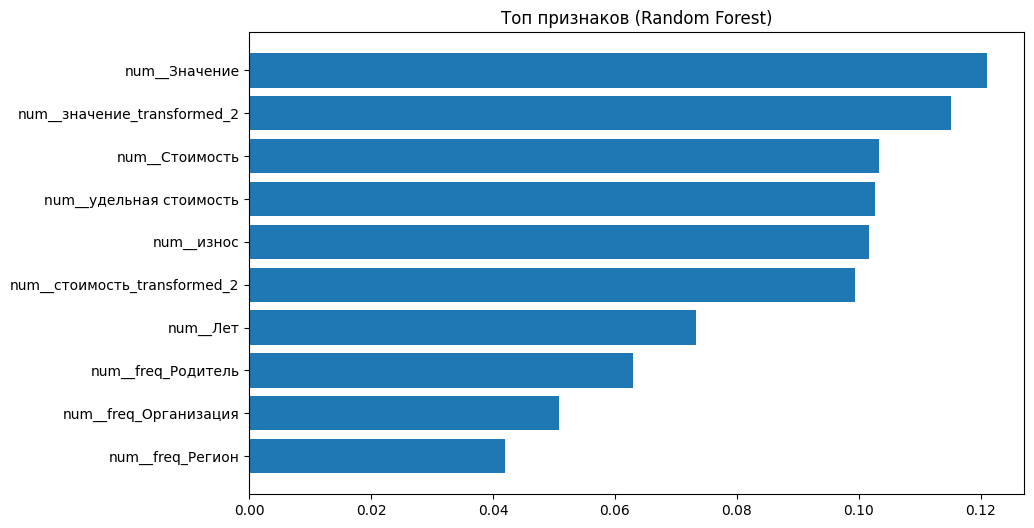

In [548]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [549]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,rtf,ros_shrinkage_005,0.5668,0.014,47.230,0.124
4,rtf,gaussian_noise,0.5668,0.023,44.023,0.116
0,rtf,ros,0.5644,0.006,4.972,0.113
2,rtf,ros_shrinkage_01,0.5644,0.020,48.908,0.158
3,rtf,ros_shrinkage_02,0.5594,0.015,47.629,0.129


In [554]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best", "random"],
    "model__pca_solver": ["auto", "full", "randomized"],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 18 candidates, totalling 36 fits


In [555]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'entropy', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'auto'}
Лучшая CV accuracy: 0.5356078059357636
Test accuracy: 0.5693069306930693
Время: 236.08683919906616


In [558]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='entropy',
                                              splitter='best',
                                              random_state=123),
        pca_solver='auto',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.2, 1.2, 0.2), 
    'model__base_estimator__min_samples_split': np.arange(2, 11, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 125 candidates, totalling 250 fits


In [559]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(0.8), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.5377332068482631
Test accuracy: 0.5668316831683168
Время: 1383.1338639259338


In [986]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='entropy',
                                              splitter='best',
                                              max_features=0.8,
                                              max_depth=None,
                                              min_samples_leaf=1,
                                              min_samples_split=2,
                                              random_state=123),
        pca_solver='auto',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": np.arange(50, 250, 50),
    "model__min_group": [1, 2, 3],
    "model__max_group": [1, 2, 3, 5],
    "model__remove_proportion": np.arange(0.1, 1.0, 0.1),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 432 candidates, totalling 864 fits



In [988]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 3, 'model__min_group': 3, 'model__n_estimators': np.int64(50), 'model__remove_proportion': np.float64(0.7000000000000001)}
Лучшая CV accuracy: 0.5451732393729954
Test accuracy: 0.5668316831683168
Время: 2852.592833995819


In [989]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
2,Значение,0.117162
7,значение_transformed_2,0.063531
0,Лет,0.022277
13,категории стоимости,0.013201
4,удельная стоимость,0.012376
3,if_anomaly,0.012376
11,freq_Округ,0.012376
14,категории возраста,0.009901
6,стоимость_transformed_2,0.006601
9,freq_Организация,0.004950


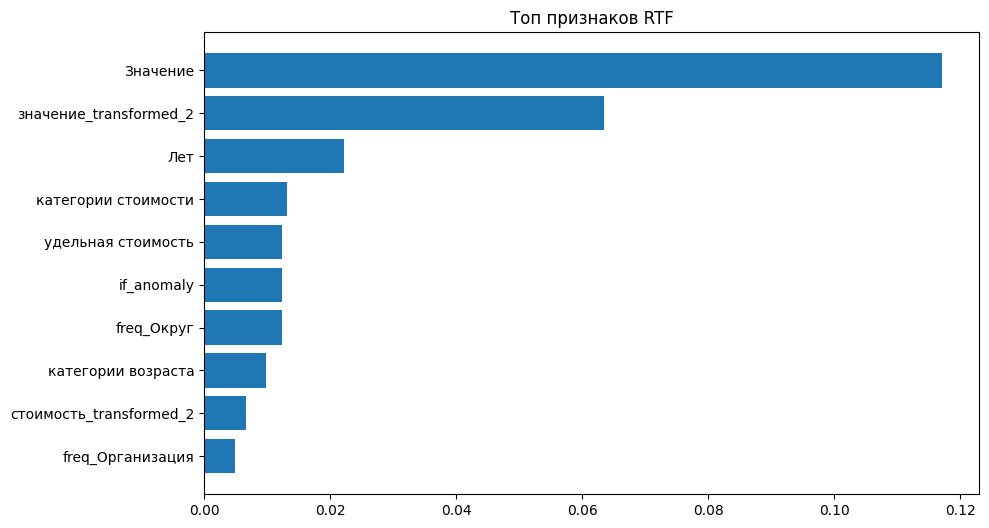

In [990]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [563]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,extra,gaussian_noise,0.5470,0.016,0.211,0.026
2,extra,ros_shrinkage_01,0.5446,0.013,0.264,0.015
1,extra,ros_shrinkage_005,0.5396,0.013,0.209,0.028
0,extra,ros,0.5322,0.012,0.189,0.033
3,extra,ros_shrinkage_02,0.5322,0.013,0.335,0.027


In [570]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 6 candidates, totalling 60 fits


In [571]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': False, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.5397872340425531
Test accuracy: 0.5470297029702971
Время: 6.708586931228638


In [573]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=False,
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": [100, 200, 300, 400, 500],
    "model__max_depth": [None],
    'model__max_features': np.arange(0.1, 1.1, 0.1),
    'model__max_samples': [None],
    'model__min_samples_split': np.arange(2, 11, 2),
    'model__min_samples_leaf': np.arange(1, 10, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1250 candidates, totalling 2500 fits



In [574]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(0.8), 'model__max_samples': None, 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(6), 'model__n_estimators': 200}
Лучшая CV accuracy: 0.5324140579120928
Test accuracy: 0.5668316831683168
Время: 600.013592004776


In [575]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
4,num__удельная стоимость,0.101684
7,num__значение_transformed_2,0.091102
0,num__Лет,0.079443
12,ord__категории стоимости,0.077032
9,num__freq_Организация,0.075223
11,num__freq_Округ,0.074032
13,ord__категории возраста,0.066619
8,num__freq_Регион,0.062823
10,num__freq_Родитель,0.061546
5,num__износ,0.060955


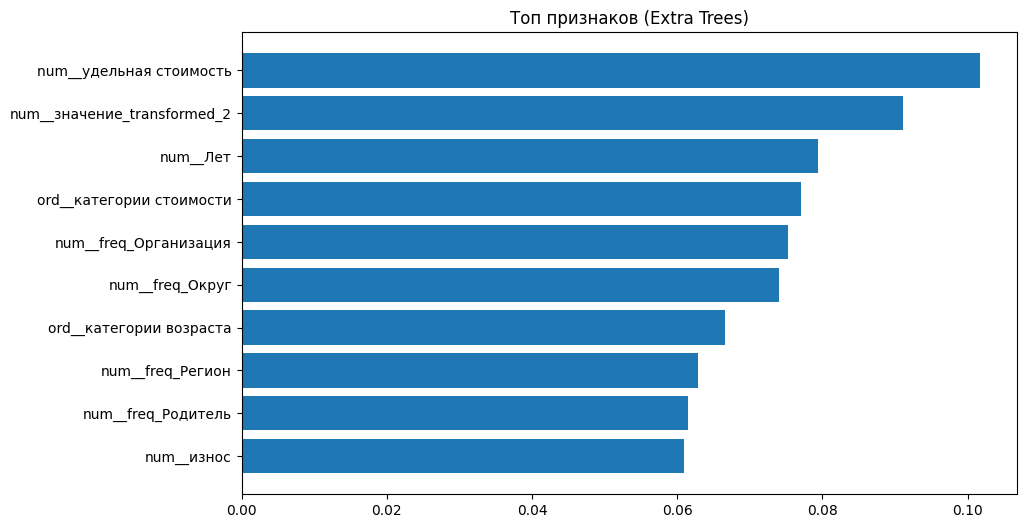

In [576]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [577]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,easy_ensemble,ros,0.5297,0.007,1.213,0.027
4,easy_ensemble,gaussian_noise,0.5223,0.012,2.012,0.036
1,easy_ensemble,ros_shrinkage_005,0.5149,0.012,1.977,0.156
3,easy_ensemble,ros_shrinkage_02,0.5074,0.014,2.097,0.160
2,easy_ensemble,ros_shrinkage_01,0.4926,0.013,2.311,0.154


In [578]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 12 candidates, totalling 60 fits


In [579]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'gini', 'model__estimator__splitter': 'random', 'model__replacement': False}
Лучшая CV accuracy: 0.5526061015422716
Test accuracy: 0.551980198019802
Время: 7.105924844741821


In [580]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='gini',
                                         splitter='random',
                                         random_state=123),
        replacement=False,
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": [25, 50, 75, 100],
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.1, 1.1, 0.1),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1000 candidates, totalling 2000 fits


In [581]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(0.8), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(10), 'model__n_estimators': 75}
Лучшая CV accuracy: 0.5249740253873605
Test accuracy: 0.5668316831683168
Время: 257.0057590007782


In [582]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
7,значение_transformed_2,0.066832
3,if_anomaly,0.032178
2,Значение,0.027228
4,удельная стоимость,0.026403
14,категории возраста,0.009901
9,freq_Организация,0.008251
0,Лет,0.004950
11,freq_Округ,0.001650
13,категории стоимости,0.000000
8,freq_Регион,-0.003300


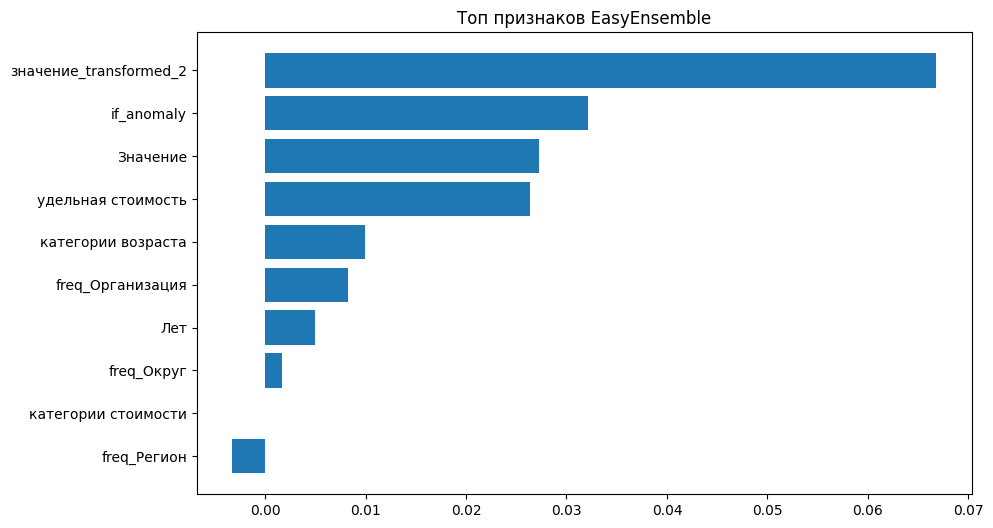

In [583]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [584]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,hgb,ros_shrinkage_005,0.5198,0.016,8.639,0.032
0,hgb,ros,0.4827,0.005,3.600,0.013
2,hgb,ros_shrinkage_01,0.4827,0.014,8.475,0.050
3,hgb,ros_shrinkage_02,0.4653,0.013,6.539,0.037
4,hgb,gaussian_noise,0.4653,0.018,5.713,0.036


In [595]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto', 'binary_crossentropy', 'categorical_crossentropy'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 5 candidates, totalling 15 fits


In [596]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.42076541652252364
Test accuracy: 0.5123762376237624
Время: 6.3863561153411865


In [609]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': [100, 200, 300, 400, 500],
    'clf__learning_rate': [0.01, 0.1],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}

grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 300 candidates, totalling 600 fits


In [610]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__max_depth': None, 'clf__max_features': np.float64(0.1), 'clf__max_iter': 100, 'clf__min_samples_leaf': np.int64(1)}
Лучшая CV accuracy: 0.5281609974251253
Test accuracy: 0.5767326732673267
Время: 1397.647518157959


In [611]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
2,Значение,0.051980
4,удельная стоимость,0.046205
7,значение_transformed_2,0.021452
0,Лет,0.010726
10,freq_Округ,0.009901
5,износ,0.004125
8,freq_Организация,0.002475
3,if_anomaly,0.001650
6,стоимость_transformed_2,0.001650
9,freq_Родитель,0.001650


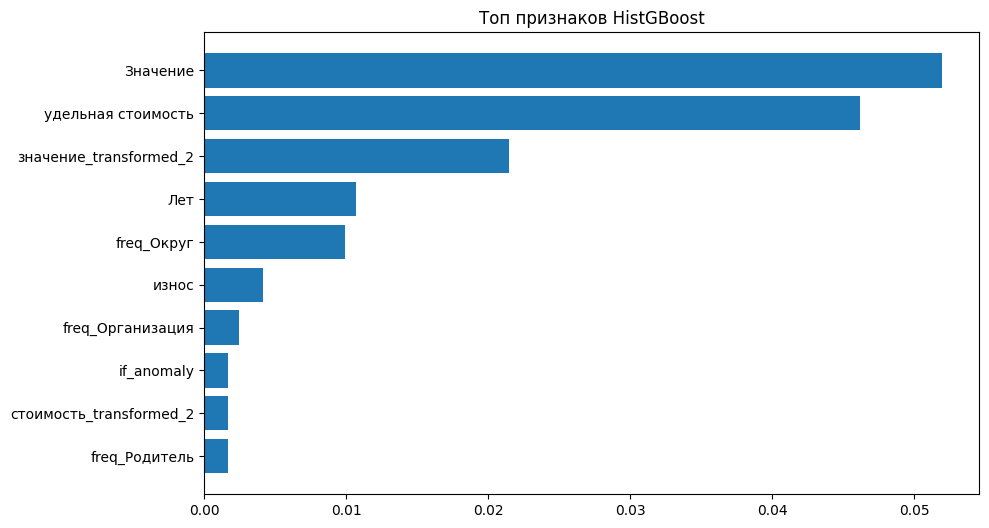

In [612]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [597]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,ada,ros_shrinkage_02,0.5297,0.012,1.048,0.000
0,ada,ros,0.5099,0.014,0.097,0.001
1,ada,ros_shrinkage_005,0.5000,0.013,0.989,0.000
2,ada,ros_shrinkage_01,0.4975,0.012,1.125,0.000
4,ada,gaussian_noise,0.4950,0.021,1.150,0.000


In [604]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best', 'random'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 6 candidates, totalling 60 fits


In [605]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'gini', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.47396416573348255
Test accuracy: 0.5123762376237624
Время: 6.055052995681763


In [613]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__estimator__min_samples_split': np.arange(2, 11, 1),
    'clf__estimator__min_samples_leaf': np.arange(1, 10, 1)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 810 candidates, totalling 1620 fits


In [614]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(0.9), 'clf__estimator__min_samples_leaf': np.int64(4), 'clf__estimator__min_samples_split': np.int64(9)}
Лучшая CV accuracy: 0.5419817500112933
Test accuracy: 0.5792079207920792
Время: 1576.3477041721344


In [622]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            max_features=0.9,
            max_depth=None,
            min_samples_leaf=4,
            min_samples_split=9,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(100, 600, 100),
    'clf__learning_rate': [0.05, 0.1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 10 candidates, totalling 20 fits


In [623]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.1, 'clf__n_estimators': np.int64(100)}
Лучшая CV accuracy: 0.537739982834169
Test accuracy: 0.5866336633663366
Время: 363.14913177490234


In [624]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
13,cat__Регион,0.140939
9,num__freq_Родитель,0.096775
2,num__Значение,0.094740
7,num__значение_transformed_2,0.086592
8,num__freq_Организация,0.082387
0,num__Лет,0.076971
4,num__удельная стоимость,0.076849
6,num__стоимость_transformed_2,0.071058
11,ord__категории стоимости,0.059952
10,num__freq_Округ,0.058351


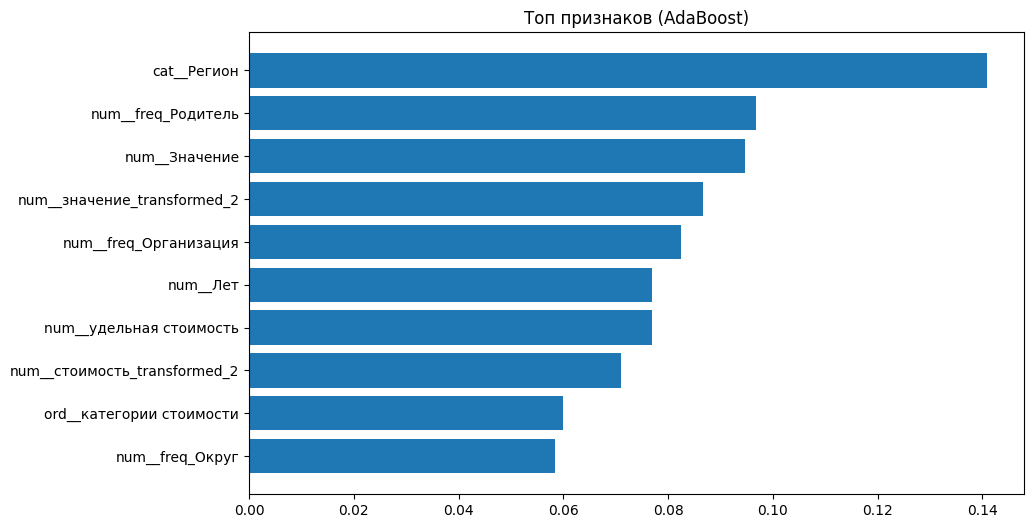

In [625]:
top_n = 10
top_features = feat_imp_ada.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (AdaBoost)")
plt.show()

### Keras (MLP)

In [606]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [607]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [608]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
  acc=0.4950 | t=28.6s
keras+ros_shrinkage_005
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
  acc=0.4851 | t=29.0s
keras+ros_shrinkage_01
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
  acc=0.4876 | t=29.7s
keras+ros_shrinkage_02
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
  acc=0.4703 | t=26.4s
keras+gaussian_noise
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
  acc=0.5000 | t=24.1s

Лучшая балансировка: gaussian_noise


In [633]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 2 folds for each of 9 candidates, totalling 18 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [634]:
best_activation = grid_strings.best_params_["clf__model__activation"]
best_optimizer  = grid_strings.best_params_["clf__model__optimizer"]

print(f"\nStrings grid time: {time.time() - start:.1f}s")
print("Best string params:", grid_strings.best_params_)

cv_strings_df = (pd.DataFrame(grid_strings.cv_results_)
                   .sort_values("rank_test_score")
                   .reset_index(drop=True))
cv_strings_df[["params", "mean_test_score", "std_test_score", "rank_test_score"]].head(10)


Strings grid time: 93.8s
Best string params: {'clf__model__activation': 'tanh', 'clf__model__optimizer': 'rmsprop'}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'clf__model__activation': 'tanh', 'clf__model...",0.464385,0.013322,1
1,"{'clf__model__activation': 'sigmoid', 'clf__mo...",0.455875,0.021832,2
2,"{'clf__model__activation': 'sigmoid', 'clf__mo...",0.451647,0.000583,3
3,"{'clf__model__activation': 'relu', 'clf__model...",0.448451,0.008025,4
4,"{'clf__model__activation': 'relu', 'clf__model...",0.445268,0.002715,5
5,"{'clf__model__activation': 'tanh', 'clf__model...",0.432511,0.006979,6
6,"{'clf__model__activation': 'relu', 'clf__model...",0.335802,0.010270,7
7,"{'clf__model__activation': 'tanh', 'clf__model...",0.249745,0.009830,8
8,"{'clf__model__activation': 'sigmoid', 'clf__mo...",0.046768,0.008551,9


In [635]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'tanh', 'clf__model__optimizer': 'rmsprop'}
Лучшая CV accuracy: 0.4643854180783304
Test accuracy: 0.4801980198019802
Время: 363.14913177490234


In [636]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation=best_activation,
        model__optimizer=best_optimizer,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [128, 256, 512],
    "clf__model__learning_rate": [0.001, 0.005, 0.01],
    "clf__batch_size":           [64, 128, 256],
    "clf__epochs":               [50, 100, 200],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 2 folds for each of 81 candidates, totalling 162 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [64, 128, ...], 'clf__epochs': [50, 100, ...], 'clf__model__learning_rate': [0.001, 0.005, ...], 'clf__model__n_size': [128, 256, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [637]:
print(f"\nNumeric grid time: {time.time() - start:.1f}s")
print("Best numeric params:", grid_numeric.best_params_)

cv_numeric_df = (pd.DataFrame(grid_numeric.cv_results_)
                   .sort_values("rank_test_score")
                   .reset_index(drop=True))
print(cv_numeric_df[["params", "mean_test_score", "std_test_score", "rank_test_score"]].head(10))

y_pred_final = grid_numeric.best_estimator_.predict(X_test)
print(f"accuracy : {accuracy_score(y_test, y_pred_final):.4f}")


Numeric grid time: 1240.3s
Best numeric params: {'clf__batch_size': 64, 'clf__epochs': 200, 'clf__model__learning_rate': 0.005, 'clf__model__n_size': 512}
... (вывод сокращён: 13 строк) ...
0        0.016472                1  
1        0.007975                2  
2        0.001604                3  
3        0.007980                4  
4        0.010105                5  
5        0.011169                6  
6        0.007982                7  
7        0.007982                7  
8        0.014358                9  
9        0.006921               10  
accuracy : 0.5322


In [638]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 64, 'clf__epochs': 200, 'clf__model__learning_rate': 0.005, 'clf__model__n_size': 512}
Лучшая CV accuracy: 0.4994511451416181
Test accuracy: 0.5321782178217822
Время: 363.14913177490234


In [639]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
4,удельная стоимость,0.143564
7,значение_transformed_2,0.142739
0,Лет,0.065182
13,категории стоимости,0.043729
2,Значение,0.042079
6,стоимость_transformed_2,0.041254
1,Стоимость,0.037954
12,Регион,0.034653
11,freq_Округ,0.030528
3,if_anomaly,0.021452


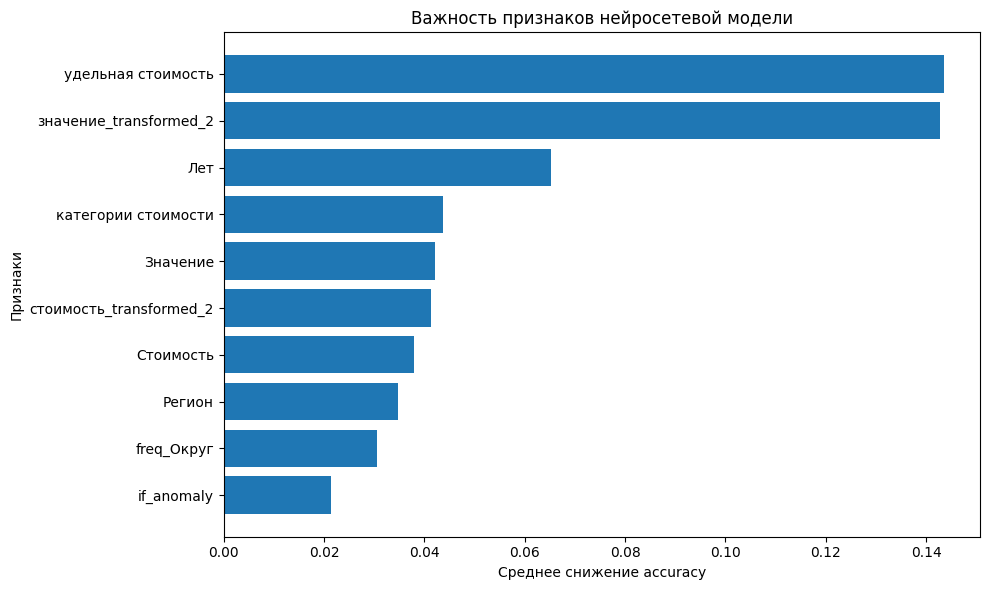

In [640]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

## Подвыборка «м²»: редкие классы

In [276]:
target_col = "Наименование"

class_counts = processed[('м2', 'rare')]['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
processed[('м2', 'rare')]['Наименование'] = processed[('м2', 'rare')]['Наименование'].where(
    ~processed[('м2', 'rare')]['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(processed[('м2', 'rare')]['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 0
Объектов с меткой 'редкий': 29


In [277]:
X = processed[('м2', 'rare')].drop(columns=[target_col])
y = processed[('м2', 'rare')][target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.33,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (363, 15) y_train: (363,)
X_test: (179, 15) y_test: (179,)


In [278]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [279]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'значение_transformed_2',
       'freq_Родитель', 'freq_Свойство', 'Регион', 'Организация',
       'категории стоимости', 'категории возраста']

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'значение_transformed_2',
       'freq_Родитель', 'freq_Свойство',]
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Регион', 'Организация']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [646]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,svm,gaussian_noise,0.3073,0.008,0.071,0.030
0,svm,ros,0.2793,0.005,0.092,0.039
1,svm,ros_shrinkage_005,0.2626,0.010,0.101,0.045
2,svm,ros_shrinkage_01,0.2626,0.007,0.105,0.045
3,svm,ros_shrinkage_02,0.2626,0.006,0.112,0.046


In [664]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 8 candidates, totalling 80 fits


In [665]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'rbf'}
Лучшая CV accuracy: 0.27800300300300307
Время (сек): 10.891435146331787
Test accuracy: 0.30726256983240224


In [677]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(
        kernel='rbf',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': np.arange(1, 55, 5),
    'clf__gamma': [1e-1, 1e-2, 1e-3],
    'clf__tol': [1e-1, 1e-2, 1e-3, 1e-4],          
    'clf__max_iter': np.arange(1, 55, 5),
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1452 candidates, totalling 2904 fits















In [678]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)
y_pred_test = grid_svm2.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_acc)
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': np.int64(41), 'clf__gamma': 0.1, 'clf__max_iter': np.int64(16), 'clf__tol': 0.01}
Лучшая CV accuracy: 0.26997450063748407
Test accuracy: 0.329608938547486
Время обучения (сек): 20.12142324447632


In [679]:
pipe = grid_svm2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
})

feat_imp = feat_imp.sort_values(
    "importance",
    ascending=False
)

feat_imp.head(10)

,feature,importance
9,freq_Родитель,0.094972
6,значение_transformed_2,0.072626
13,категории стоимости,0.061453
0,Лет,0.037244
10,freq_Свойство,0.033520
8,freq_Организация,0.027933
4,удельная стоимость,0.026071
3,if_anomaly,0.020484
2,Значение,0.018622
1,Стоимость,0.013035


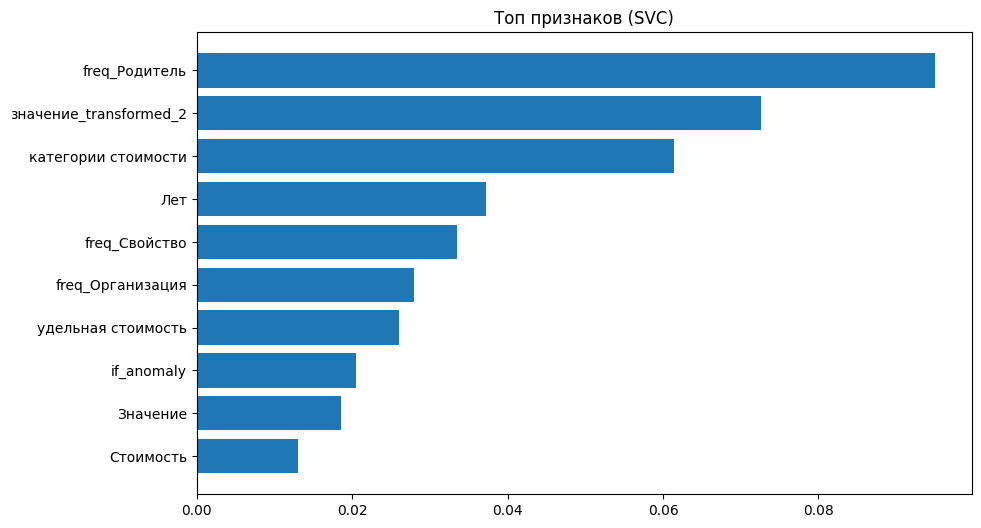

In [680]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [681]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,knn,ros_shrinkage_02,0.2235,0.009,0.0,0.008
4,knn,gaussian_noise,0.2235,0.007,0.0,0.006
0,knn,ros,0.2179,0.004,0.0,0.010
2,knn,ros_shrinkage_01,0.2179,0.006,0.0,0.002
1,knn,ros_shrinkage_005,0.2123,0.007,0.0,0.002


In [686]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [687]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'distance'}
Лучшая CV accuracy: 0.2699724517906336
Test accuracy: 0.2681564245810056
Время: 0.1798241138458252


In [688]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='distance',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(1, 31, 2),
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__leaf_size': np.arange(1, 31, 2)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 450 candidates, totalling 1350 fits



In [689]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(1), 'clf__metric': 'euclidean', 'clf__n_neighbors': np.int64(1)}
Лучшая CV accuracy: 0.2699724517906336
Test accuracy: 0.27932960893854747
Время: 3.509793996810913


In [690]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
6,значение_transformed_2,0.067039
13,категории стоимости,0.039106
10,freq_Свойство,0.031657
8,freq_Организация,0.022346
9,freq_Родитель,0.022346
3,if_anomaly,0.020484
1,Стоимость,0.018622
14,категории возраста,0.014898
4,удельная стоимость,0.014898
2,Значение,0.013035


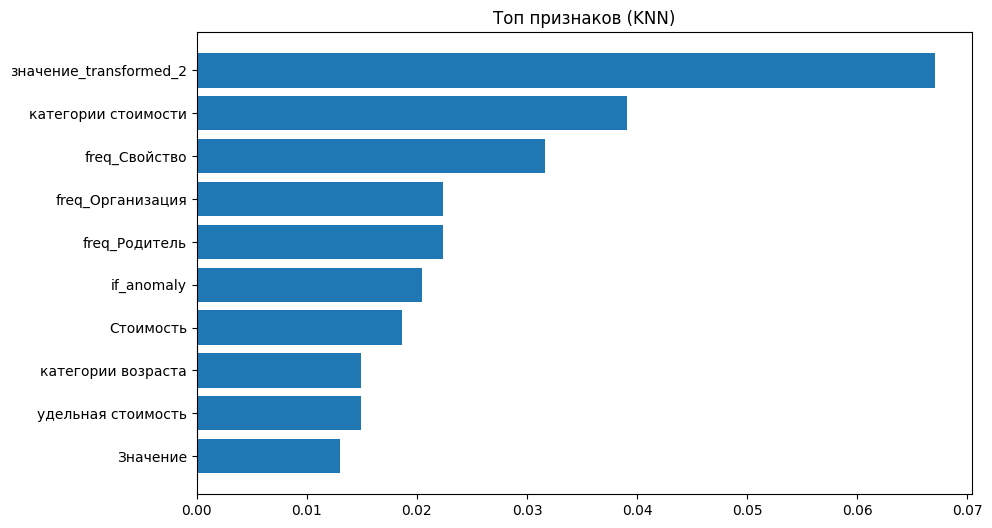

In [691]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [692]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
2,tree,ros_shrinkage_01,0.4749,0.006,0.049,0.0
3,tree,ros_shrinkage_02,0.4581,0.004,0.049,0.0
1,tree,ros_shrinkage_005,0.4246,0.004,0.050,0.0
0,tree,ros,0.3799,0.003,0.008,0.0
4,tree,gaussian_noise,0.3575,0.003,0.055,0.0


In [699]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.1, random_state=123)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 6 candidates, totalling 30 fits


In [700]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.3471461187214612
Test accuracy: 0.4748603351955307
Время: 0.2551121711730957


In [723]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.1, random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='gini',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': np.arange(5, 35, 5),
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_split': np.arange(2, 11, 1),
    'clf__min_samples_leaf': np.arange(1, 11, 1)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 5400 candidates, totalling 10800 fits


... (вывод сокращён: 35 строк) ...













In [724]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': np.int64(25), 'clf__max_features': np.float64(0.6000000000000001), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4)}
Лучшая CV accuracy: 0.341570032177767
Test accuracy: 0.441340782122905
Время: 29.281924962997437


In [725]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
2,num__Значение,0.156363
6,num__значение_transformed_2,0.124099
5,num__износ,0.102614
7,num__freq_Регион,0.088588
0,num__Лет,0.085753
1,num__Стоимость,0.083530
4,num__удельная стоимость,0.078395
12,ord__категории возраста,0.057960
9,num__freq_Родитель,0.056276
13,cat__Регион,0.047402


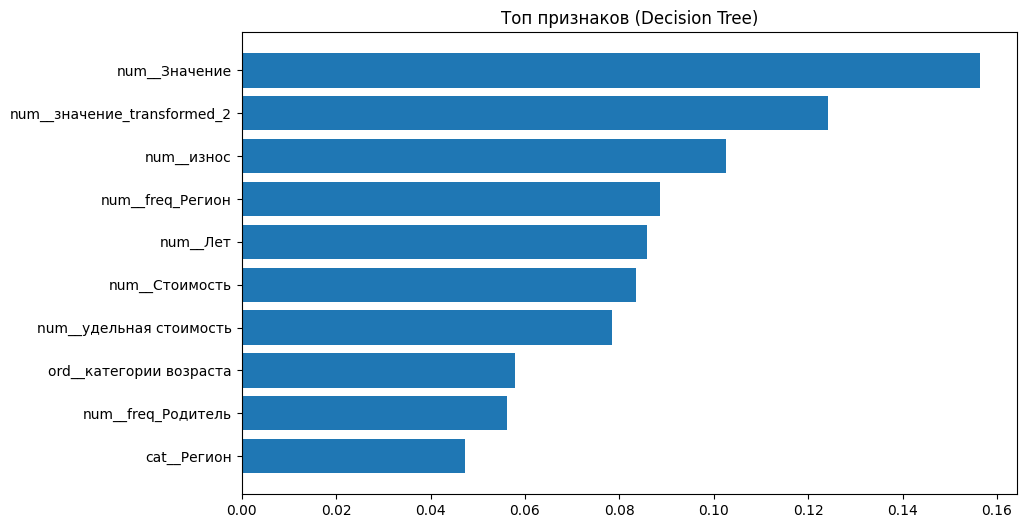

In [726]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [647]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,rf,ros_shrinkage_005,0.5028,0.004,0.179,0.015
2,rf,ros_shrinkage_01,0.4804,0.004,0.154,0.014
0,rf,ros,0.4693,0.002,0.114,0.014
3,rf,ros_shrinkage_02,0.4637,0.004,0.142,0.015
4,rf,gaussian_noise,0.4525,0.003,0.172,0.014


In [654]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 3 candidates, totalling 30 fits


In [655]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini'}
Лучшая CV accuracy: 0.38843843843843845
Test accuracy: 0.5027932960893855
Время: 3.299316167831421


In [ ]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': [300, 400, 500],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__max_samples': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 768 candidates, totalling 7680 fits

















In [661]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.2), 'clf__max_samples': np.float64(0.8), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4), 'clf__n_estimators': 400}
Лучшая CV accuracy: 0.3857537490134175
Test accuracy: 0.5027932960893855
Время: 913.9767401218414


In [662]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
2,num__Значение,0.125639
6,num__значение_transformed_2,0.114637
4,num__удельная стоимость,0.105277
1,num__Стоимость,0.095408
5,num__износ,0.089880
0,num__Лет,0.077800
9,num__freq_Родитель,0.069527
7,num__freq_Регион,0.063646
13,cat__Регион,0.055351
12,ord__категории возраста,0.045268


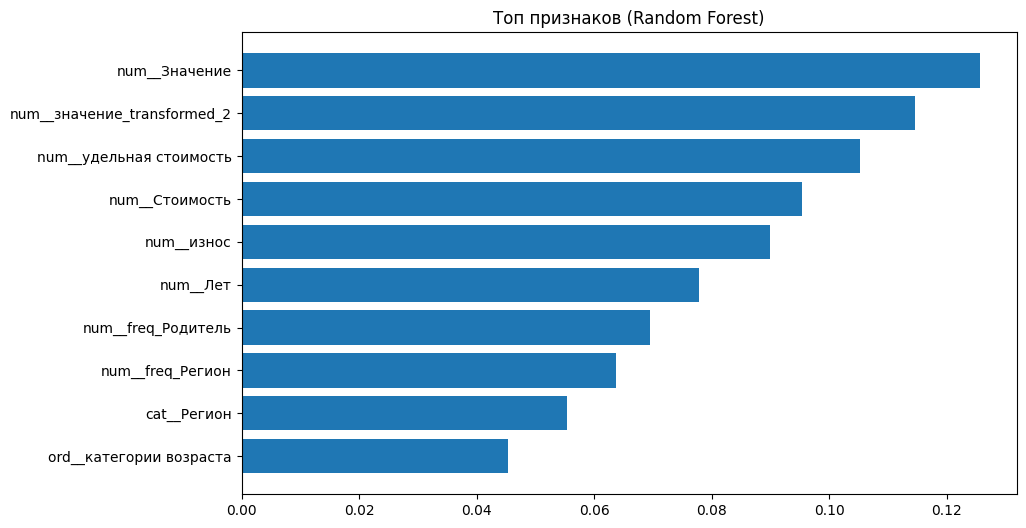

In [663]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [257]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rtf,ros,0.4860,0.002,0.897,0.107
1,rtf,ros_shrinkage_005,0.4749,0.004,1.815,0.093
4,rtf,gaussian_noise,0.4749,0.002,1.992,0.080
2,rtf,ros_shrinkage_01,0.4693,0.003,1.792,0.092
3,rtf,ros_shrinkage_02,0.4637,0.003,1.688,0.089


In [258]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best", "random"],
    "model__pca_solver": ["auto", "full", "randomized"],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 18 candidates, totalling 36 fits


In [259]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'entropy', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'auto'}
Лучшая CV accuracy: 0.37197195070123246
Test accuracy: 0.49162011173184356
Время: 9.014127969741821


In [264]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='entropy',
                                              splitter='best',
                                              random_state=123),
        pca_solver='auto',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None, 5, 10, 20],
    'model__base_estimator__max_features':np.arange(0.2, 1.2, 0.2), 
    'model__base_estimator__min_samples_split': np.arange(2, 9, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 8, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 320 candidates, totalling 640 fits


In [265]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': 10, 'model__base_estimator__max_features': np.float64(0.8), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(6)}
Лучшая CV accuracy: 0.38573857082144375
Test accuracy: 0.4860335195530726
Время: 109.36745190620422


In [737]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(0.8), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(6)}
Лучшая CV accuracy: 0.38297613988221724
Test accuracy: 0.5083798882681564
Время: 104.86694002151489


In [270]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='entropy',
                                              splitter='best',
                                              max_features=0.8,
                                              max_depth=10,
                                              min_samples_leaf=1,
                                              min_samples_split=6,
                                              random_state=123),
        pca_solver='auto',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": [25, 100, 200, 300],
    "model__min_group": [1, 2, 3],
    "model__max_group": [1, 2, 3],
    "model__remove_proportion": np.arange(0.1, 1.0, 0.1),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 324 candidates, totalling 648 fits



In [741]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 3, 'model__min_group': 1, 'model__n_estimators': np.int64(25), 'model__remove_proportion': np.float64(0.8)}
Лучшая CV accuracy: 0.3857537490134175
Test accuracy: 0.5195530726256983
Время: 84.43081212043762


In [742]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=6
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
6,значение_transformed_2,0.150838
2,Значение,0.134078
7,freq_Регион,0.065177
13,категории стоимости,0.055866
4,удельная стоимость,0.052142
9,freq_Родитель,0.046555
12,Организация,0.044693
14,категории возраста,0.040968
8,freq_Организация,0.033520
5,износ,0.031657


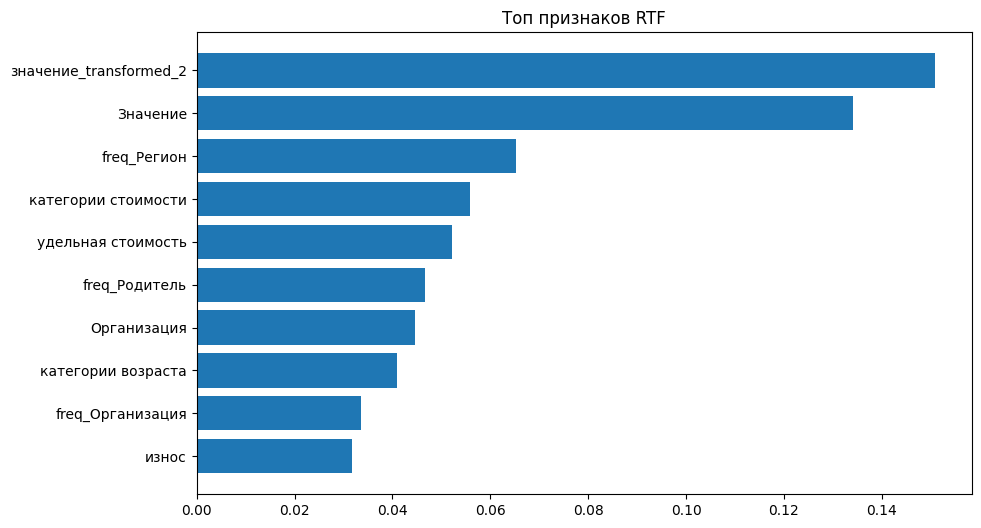

In [743]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [744]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,extra,gaussian_noise,0.4246,0.003,0.063,0.015
0,extra,ros,0.4078,0.002,0.075,0.014
1,extra,ros_shrinkage_005,0.4078,0.004,0.075,0.014
2,extra,ros_shrinkage_01,0.4022,0.004,0.087,0.014
3,extra,ros_shrinkage_02,0.4022,0.003,0.071,0.014


In [759]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [760]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': False, 'model__criterion': 'entropy'}
Лучшая CV accuracy: 0.3251472284621456
Test accuracy: 0.39106145251396646
Время: 0.38753199577331543


In [769]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", ExtraTreesClassifier(
        criterion='entropy',
        bootstrap=False,
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": np.arange(25, 125, 25),
    "model__max_depth": [None],
    'model__max_features': np.arange(0.1, 1.1, 0.1),
    'model__max_samples': [None],
    'model__min_samples_split': np.arange(2, 11, 2),
    'model__min_samples_leaf': np.arange(1, 10, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1000 candidates, totalling 2000 fits


In [771]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(0.5), 'model__max_samples': None, 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(6), 'model__n_estimators': np.int64(25)}
Лучшая CV accuracy: 0.3471100722481938
Test accuracy: 0.4301675977653631
Время: 29.508797883987427


In [772]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
11,ord__категории стоимости,0.182714
7,num__freq_Регион,0.127556
6,num__значение_transformed_2,0.096190
8,num__freq_Организация,0.089182
12,ord__категории возраста,0.086017
4,num__удельная стоимость,0.067396
9,num__freq_Родитель,0.056049
0,num__Лет,0.051034
5,num__износ,0.049840
1,num__Стоимость,0.047155


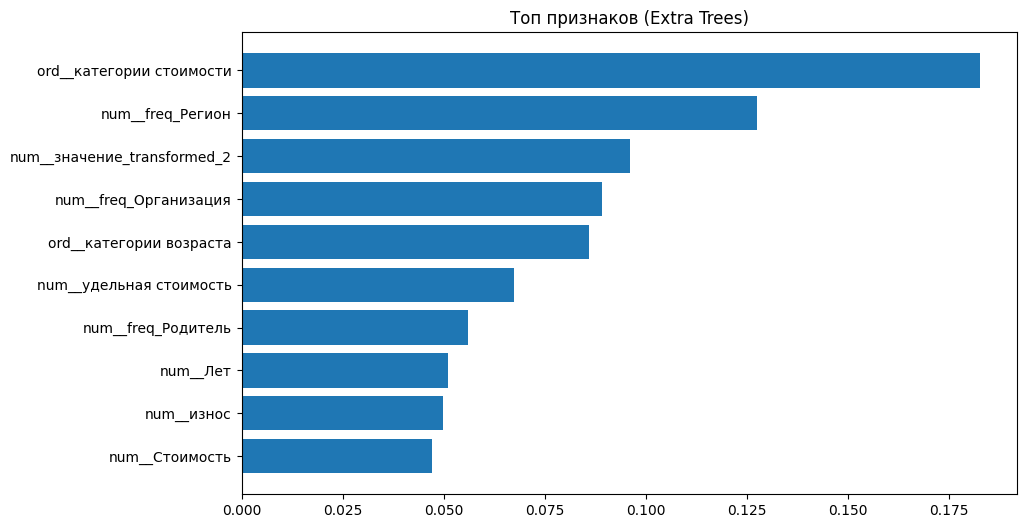

In [773]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [774]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,easy_ensemble,ros_shrinkage_005,0.4749,0.006,0.131,0.014
2,easy_ensemble,ros_shrinkage_01,0.4749,0.004,0.134,0.013
3,easy_ensemble,ros_shrinkage_02,0.4749,0.004,0.127,0.014
4,easy_ensemble,gaussian_noise,0.3799,0.003,0.139,0.014
0,easy_ensemble,ros,0.3631,0.002,3.613,0.074


In [785]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 12 candidates, totalling 120 fits



In [786]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'gini', 'model__estimator__splitter': 'best', 'model__replacement': True}
Лучшая CV accuracy: 0.3743243243243243
Test accuracy: 0.4692737430167598
Время: 6.20087194442749


In [787]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='gini',
                                         splitter='best',
                                         random_state=123),
        replacement=True,
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": np.arange(25, 125, 25),
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.1, 1.1, 0.1),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1000 candidates, totalling 2000 fits




In [788]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(0.2), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(4), 'model__n_estimators': np.int64(50)}
Лучшая CV accuracy: 0.3747192034484852
Test accuracy: 0.48044692737430167
Время: 166.8120608329773


In [789]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
2,Значение,0.134078
6,значение_transformed_2,0.098696
4,удельная стоимость,0.046555
10,freq_Свойство,0.031657
9,freq_Родитель,0.029795
13,категории стоимости,0.029795
7,freq_Регион,0.018622
0,Лет,0.014898
5,износ,0.013035
3,if_anomaly,0.011173


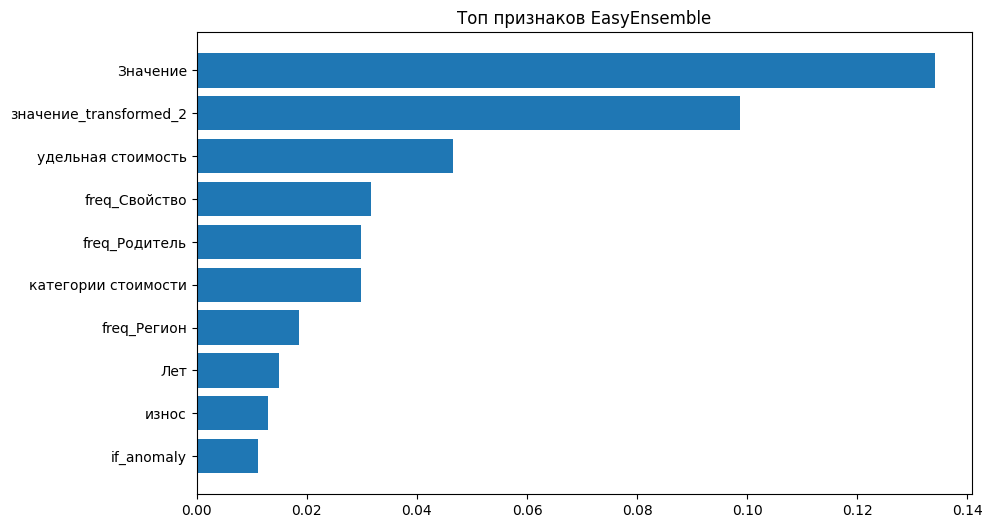

In [790]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [791]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,hgb,ros_shrinkage_02,0.4860,0.004,70.213,0.818
2,hgb,ros_shrinkage_01,0.4469,0.004,69.457,0.741
1,hgb,ros_shrinkage_005,0.4413,0.004,73.619,0.747
0,hgb,ros,0.4190,0.003,76.505,0.831
4,hgb,gaussian_noise,0.3911,0.003,65.922,0.836


In [800]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 3 candidates, totalling 6 fits


In [801]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.35544289964179465
Test accuracy: 0.441340782122905
Время: 77.18475818634033


In [805]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': np.arange(100, 600, 100),
    'clf__learning_rate': [0.01, 0.1],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}

grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 300 candidates, totalling 600 fits


In [806]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__max_depth': None, 'clf__max_features': np.float64(0.2), 'clf__max_iter': np.int64(400), 'clf__min_samples_leaf': np.int64(1)}
Лучшая CV accuracy: 0.40496934005221297
Test accuracy: 0.49162011173184356
Время: 1113.482162952423


In [807]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
2,Значение,0.119181
7,freq_Родитель,0.094972
6,значение_transformed_2,0.070764
4,удельная стоимость,0.068901
10,Организация,0.048417
11,категории стоимости,0.037244
5,износ,0.035382
0,Лет,0.031657
9,Регион,0.031657
12,категории возраста,0.031657


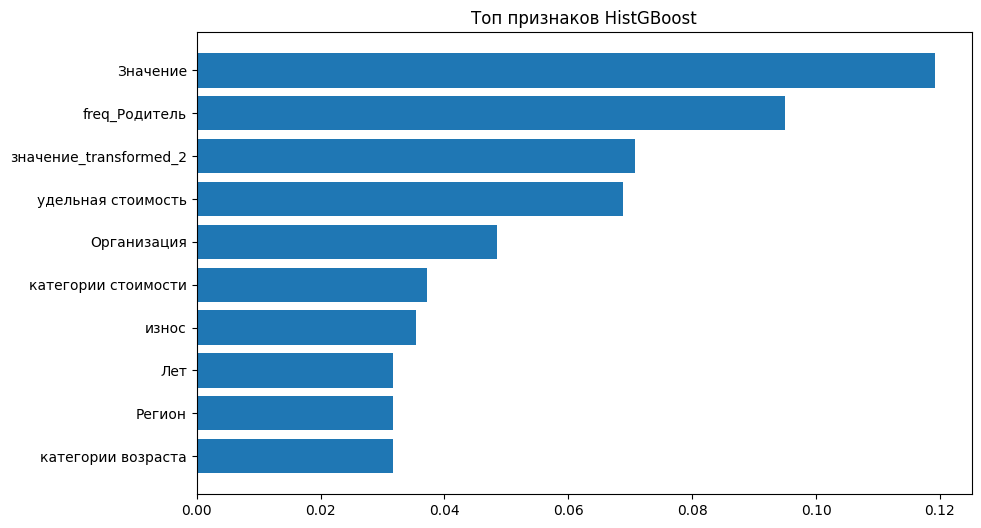

In [808]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [809]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,ada,ros_shrinkage_02,0.3966,0.004,0.045,0.001
0,ada,ros,0.3799,0.003,0.012,0.000
4,ada,gaussian_noise,0.3743,0.004,0.059,0.000
1,ada,ros_shrinkage_005,0.3520,0.004,0.049,0.000
2,ada,ros_shrinkage_01,0.3240,0.005,0.044,0.000


In [810]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best', 'random'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 6 candidates, totalling 60 fits


In [811]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'gini', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.2944444444444444
Test accuracy: 0.39664804469273746
Время: 2.600358009338379


In [812]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__estimator__min_samples_split': np.arange(2, 11, 1),
    'clf__estimator__min_samples_leaf': np.arange(1, 10, 1)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 810 candidates, totalling 1620 fits




In [813]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(1.0), 'clf__estimator__min_samples_leaf': np.int64(6), 'clf__estimator__min_samples_split': np.int64(8)}
Лучшая CV accuracy: 0.4076558800315706
Test accuracy: 0.43575418994413406
Время: 111.3491861820221


In [828]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            max_features=1.0,
            max_depth=None,
            min_samples_leaf=6,
            min_samples_split=8,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(50, 300, 50),
    'clf__learning_rate': [0.05, 0.1, 1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 15 candidates, totalling 30 fits


In [829]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.05, 'clf__n_estimators': np.int64(150)}
Лучшая CV accuracy: 0.39120271993200173
Test accuracy: 0.45251396648044695
Время: 19.35909104347229


In [830]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
2,num__Значение,0.124107
7,num__freq_Родитель,0.113291
11,cat__Регион,0.110008
4,num__удельная стоимость,0.109477
12,cat__Организация,0.101510
6,num__значение_transformed_2,0.099441
0,num__Лет,0.098859
1,num__Стоимость,0.055027
5,num__износ,0.047831
9,ord__категории стоимости,0.045750


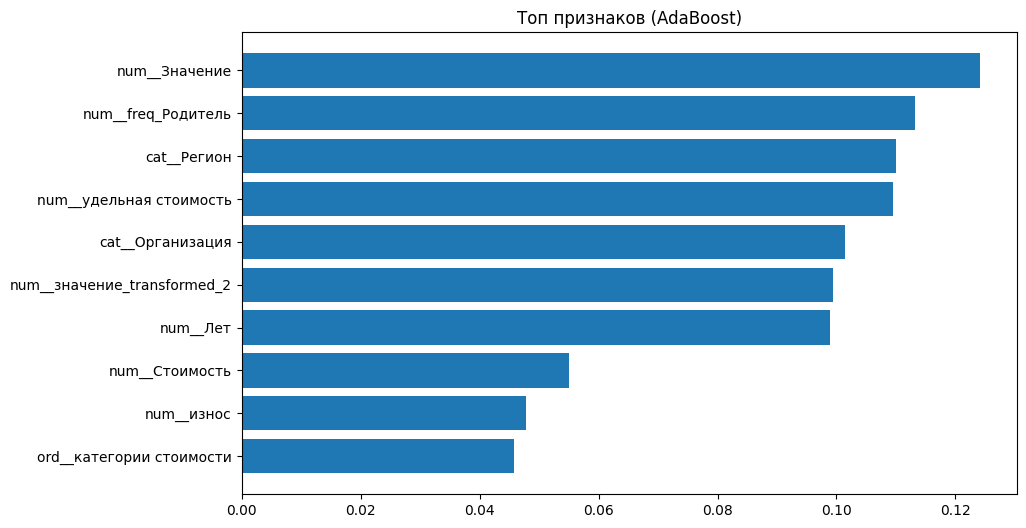

In [831]:
top_n = 10
top_features = feat_imp_ada.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (AdaBoost)")
plt.show()

### Keras (MLP)

In [832]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [833]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [836]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
  acc=0.3073 | t=4.7s
keras+ros_shrinkage_005
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
  acc=0.3240 | t=4.0s
keras+ros_shrinkage_01
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
  acc=0.3184 | t=4.3s
keras+ros_shrinkage_02
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
  acc=0.2961 | t=4.3s
keras+gaussian_noise
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
  acc=0.3240 | t=4.6s

Лучшая балансировка: ros_shrinkage_005


In [837]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 2 folds for each of 9 candidates, totalling 18 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [838]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'relu', 'clf__model__optimizer': 'adam'}
Лучшая CV accuracy: 0.311335073766013
Test accuracy: 0.3240223463687151
Время: 19.35909104347229


In [839]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation=best_activation,
        model__optimizer=best_optimizer,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [128, 256, 512],
    "clf__model__learning_rate": [0.001, 0.005, 0.01],
    "clf__batch_size":           [64, 128, 256],
    "clf__epochs":               [50, 100, 200],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 2 folds for each of 81 candidates, totalling 162 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [64, 128, ...], 'clf__epochs': [50, 100, ...], 'clf__model__learning_rate': [0.001, 0.005, ...], 'clf__model__n_size': [128, 256, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [840]:
print(f"\nNumeric grid time: {time.time() - start:.1f}s")
print("Best numeric params:", grid_numeric.best_params_)

cv_numeric_df = (pd.DataFrame(grid_numeric.cv_results_)
                   .sort_values("rank_test_score")
                   .reset_index(drop=True))
print(cv_numeric_df[["params", "mean_test_score", "std_test_score", "rank_test_score"]].head(10))

y_pred_final = grid_numeric.best_estimator_.predict(X_test)
print(f"accuracy : {accuracy_score(y_test, y_pred_final):.4f}")


Numeric grid time: 205.3s
Best numeric params: {'clf__batch_size': 64, 'clf__epochs': 100, 'clf__model__learning_rate': 0.001, 'clf__model__n_size': 256}
... (вывод сокращён: 13 строк) ...
0        0.022919                1  
1        0.031176                2  
2        0.033923                3  
3        0.028414                4  
4        0.022904                5  
5        0.011885                6  
6        0.000865                7  
7        0.009122                8  
8        0.001897                9  
9        0.001897                9  
accuracy : 0.3464


In [841]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 64, 'clf__epochs': 100, 'clf__model__learning_rate': 0.001, 'clf__model__n_size': 256}
Лучшая CV accuracy: 0.3196223665836926
Test accuracy: 0.3463687150837989
Время: 19.35909104347229


In [842]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
9,freq_Родитель,0.087523
4,удельная стоимость,0.081937
6,значение_transformed_2,0.081937
0,Лет,0.061453
13,категории стоимости,0.055866
1,Стоимость,0.040968
10,freq_Свойство,0.033520
7,freq_Регион,0.016760
3,if_anomaly,0.014898
12,Организация,0.013035


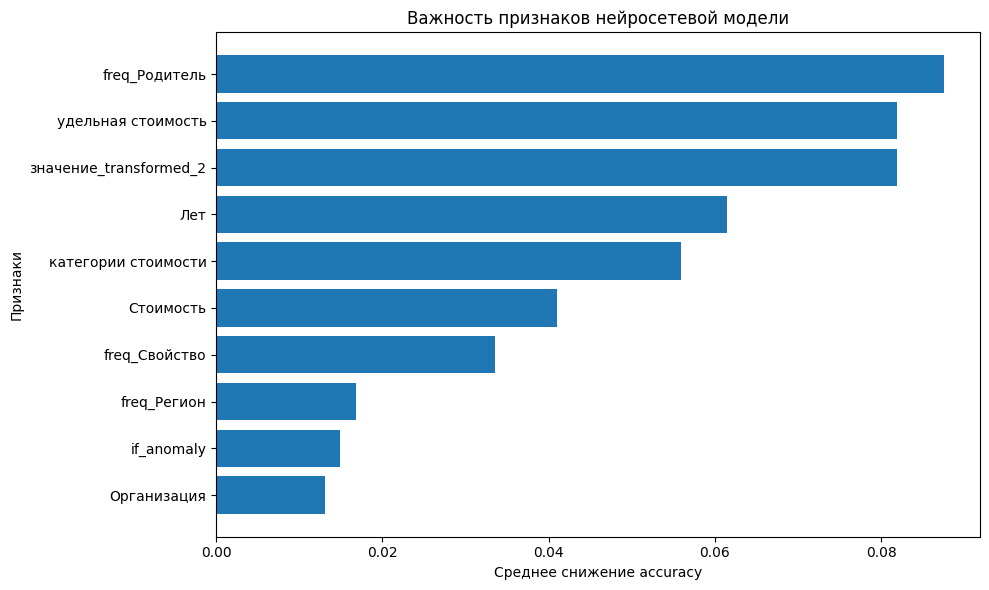

In [843]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

## Подвыборка «м³»: нормальные классы

In [328]:
target_col = "Наименование"

class_counts = processed[('м3', 'normal')]['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
processed[('м3', 'normal')]['Наименование'] = processed[('м3', 'normal')]['Наименование'].where(
    ~processed[('м3', 'normal')]['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(processed[('м3', 'normal')]['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 0
Объектов с меткой 'редкий': 22


In [329]:
X = processed[('м3', 'normal')].drop(columns=[target_col])
y = processed[('м3', 'normal')][target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.3,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (503, 15) y_train: (503,)
X_test: (216, 15) y_test: (216,)


In [330]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [331]:
X_test.columns

Index(['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'значение_transformed_2', 'freq_Регион', 'freq_Организация',
       'freq_Свойство', 'freq_Округ', 'Регион', 'Свойство',
       'категории стоимости', 'категории возраста'],
      dtype='object')

In [342]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'значение_transformed_2', 'freq_Организация',
       'freq_Округ', 'Регион', 'Свойство',
       'категории стоимости', 'категории возраста']

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'значение_transformed_2', 'freq_Организация',
       'freq_Округ']
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Регион', 'Свойство']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [334]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,svm,gaussian_noise,0.4954,0.003,0.041,0.015
0,svm,ros,0.3935,0.001,0.087,0.028
3,svm,ros_shrinkage_02,0.3843,0.003,0.064,0.030
1,svm,ros_shrinkage_005,0.3796,0.004,0.060,0.030
2,svm,ros_shrinkage_01,0.3750,0.003,0.060,0.031


In [996]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 8 candidates, totalling 80 fits


In [997]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'rbf'}
Лучшая CV accuracy: 0.490929451287794
Время (сек): 14.025017023086548
Test accuracy: 0.5099009900990099


In [998]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(
        kernel='rbf',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': np.arange(1, 55, 5),
    'clf__gamma': [1e-1, 1e-2, 1e-3],
    'clf__tol': [1e-1, 1e-2, 1e-3, 1e-4],          
    'clf__max_iter': np.arange(1, 55, 5),
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1452 candidates, totalling 2904 fits





In [999]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)
y_pred_test = grid_svm2.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_acc)
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': np.int64(26), 'clf__gamma': 0.1, 'clf__max_iter': np.int64(36), 'clf__tol': 0.1}
Лучшая CV accuracy: 0.4750169399647649
Test accuracy: 0.5222772277227723
Время обучения (сек): 189.60649585723877


In [1000]:
pipe = grid_svm2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
})

feat_imp = feat_imp.sort_values(
    "importance",
    ascending=False
)

feat_imp.head(10)

,feature,importance
7,значение_transformed_2,0.093234
4,удельная стоимость,0.082508
13,категории стоимости,0.037954
0,Лет,0.037129
6,стоимость_transformed_2,0.021452
3,if_anomaly,0.019802
2,Значение,0.015677
9,freq_Организация,0.006601
1,Стоимость,0.003300
5,износ,0.000825


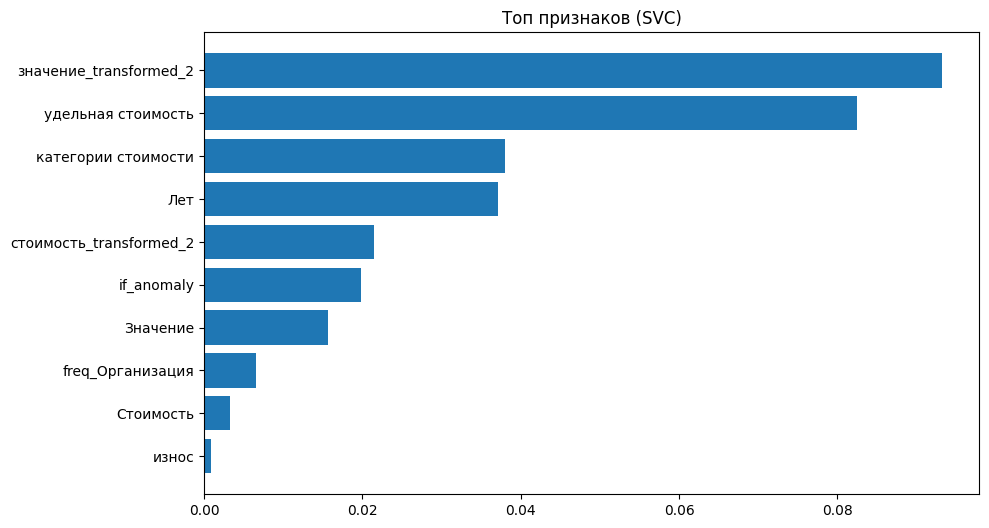

In [1001]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [335]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,knn,gaussian_noise,0.4537,0.003,0.0,0.002
2,knn,ros_shrinkage_01,0.4306,0.004,0.0,0.003
1,knn,ros_shrinkage_005,0.4259,0.004,0.0,0.003
3,knn,ros_shrinkage_02,0.4213,0.006,0.0,0.002
0,knn,ros,0.4074,0.002,0.0,0.006


In [1003]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [1004]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'distance'}
Лучшая CV accuracy: 0.46227861324216707
Test accuracy: 0.48514851485148514
Время: 1.2840359210968018


In [1005]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='distance',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(1, 31, 2),
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__leaf_size': np.arange(1, 31, 2)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 450 candidates, totalling 1350 fits


In [1006]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(1), 'clf__metric': 'manhattan', 'clf__n_neighbors': np.int64(7)}
Лучшая CV accuracy: 0.4845953480800147
Test accuracy: 0.5
Время: 48.78928303718567


In [1007]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
7,значение_transformed_2,0.075908
4,удельная стоимость,0.052805
13,категории стоимости,0.051155
0,Лет,0.032178
2,Значение,0.029703
6,стоимость_transformed_2,0.028053
9,freq_Организация,0.023927
14,категории возраста,0.022277
10,freq_Родитель,0.018152
3,if_anomaly,0.016502


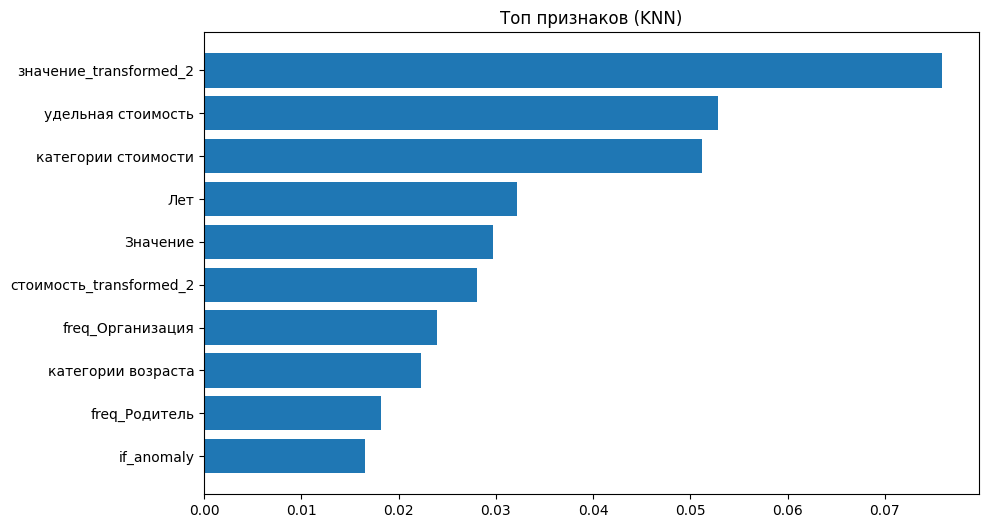

In [1008]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [336]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,tree,ros,0.5556,0.002,0.007,0.0
1,tree,ros_shrinkage_005,0.5417,0.002,0.041,0.0
4,tree,gaussian_noise,0.5278,0.001,0.020,0.0
2,tree,ros_shrinkage_01,0.5231,0.002,0.023,0.0
3,tree,ros_shrinkage_02,0.5046,0.002,0.023,0.0


In [1014]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [1015]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.46758594208790716
Test accuracy: 0.5346534653465347
Время: 0.20757603645324707


In [1022]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='gini',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': np.arange(1, 111, 10),
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_split': np.arange(2, 11, 1),
    'clf__min_samples_leaf': np.arange(1, 11, 1)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 9900 candidates, totalling 19800 fits


... (вывод сокращён: 46 строк) ...













In [1023]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': np.int64(31), 'clf__max_features': np.float64(0.7000000000000001), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.46864525455120387
Test accuracy: 0.5346534653465347
Время: 59.1416597366333


In [1024]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
7,num__значение_transformed_2,0.147664
1,num__Стоимость,0.142570
5,num__износ,0.114646
2,num__Значение,0.109111
6,num__стоимость_transformed_2,0.103225
4,num__удельная стоимость,0.098814
0,num__Лет,0.083271
10,num__freq_Родитель,0.052895
9,num__freq_Организация,0.038900
11,num__freq_Округ,0.030148


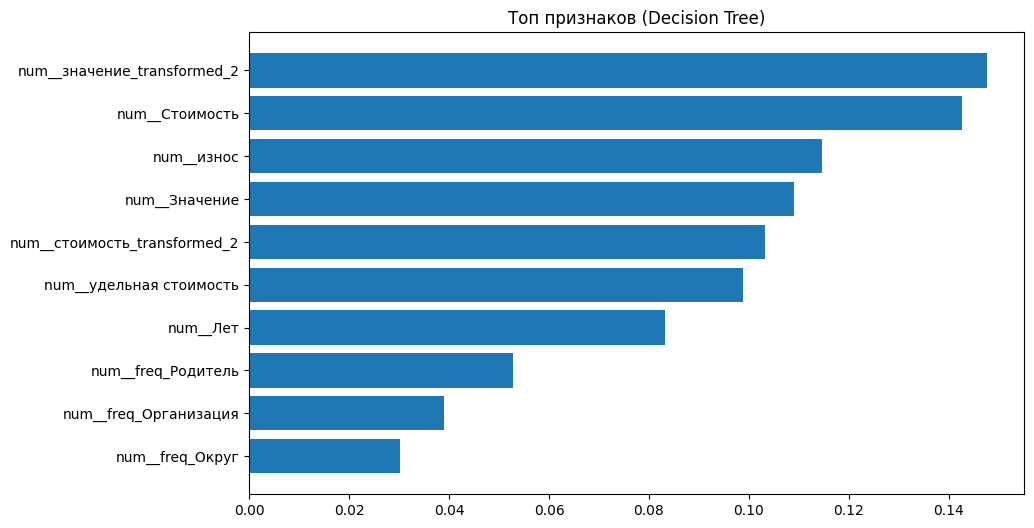

In [1025]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [337]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rf,ros,0.6019,0.002,0.079,0.014
4,rf,gaussian_noise,0.5972,0.002,0.086,0.014
3,rf,ros_shrinkage_02,0.5880,0.002,0.084,0.014
2,rf,ros_shrinkage_01,0.5833,0.002,0.087,0.014
1,rf,ros_shrinkage_005,0.5741,0.002,0.084,0.013


In [350]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 3 candidates, totalling 9 fits


In [351]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini'}
Лучшая CV accuracy: 0.6182515920539872
Test accuracy: 0.6018518518518519
Время: 2.5545289516448975


In [354]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': [250, 300, 350],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__max_samples': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 9, 2),
    'clf__min_samples_leaf': np.arange(1, 8, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 1200 candidates, totalling 3600 fits





In [355]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.2), 'clf__max_samples': np.float64(1.0), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(2), 'clf__n_estimators': 300}
Лучшая CV accuracy: 0.6262237429902101
Test accuracy: 0.6018518518518519
Время: 235.58466625213623


In [356]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
4,num__удельная стоимость,0.140238
5,num__износ,0.112756
1,num__Стоимость,0.111087
2,num__Значение,0.110342
6,num__значение_transformed_2,0.107983
0,num__Лет,0.078418
7,num__freq_Регион,0.048285
14,cat__Свойство,0.045369
9,num__freq_Свойство,0.042053
8,num__freq_Организация,0.041444


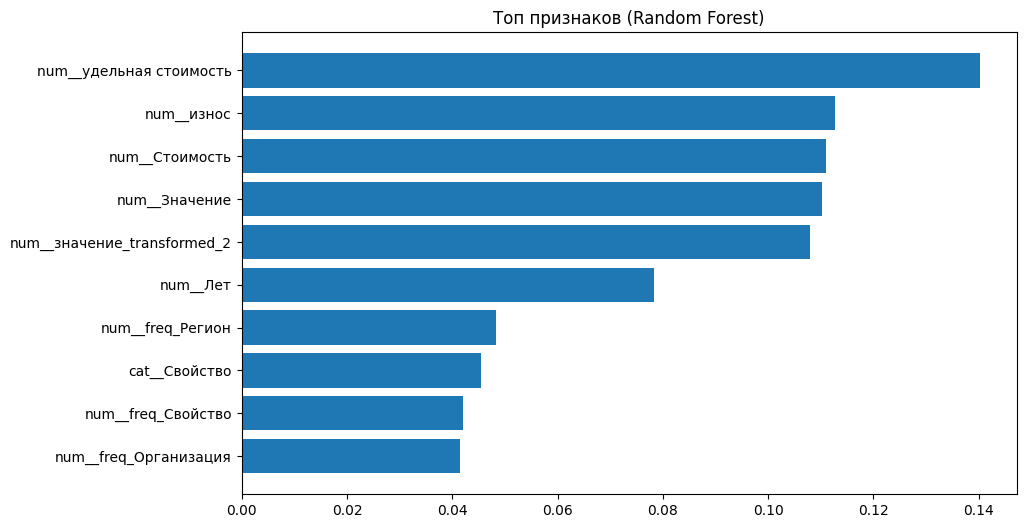

In [357]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [338]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rtf,ros,0.5880,0.002,0.670,0.100
4,rtf,gaussian_noise,0.5880,0.001,0.910,0.090
2,rtf,ros_shrinkage_01,0.5833,0.002,0.982,0.091
1,rtf,ros_shrinkage_005,0.5787,0.002,0.956,0.088
3,rtf,ros_shrinkage_02,0.5694,0.002,1.053,0.088


In [358]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best", "random"],
    "model__pca_solver": ["auto", "full", "randomized"],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 18 candidates, totalling 36 fits


In [359]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'gini', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'randomized'}
Лучшая CV accuracy: 0.5764956048820591
Test accuracy: 0.5925925925925926
Время: 9.0589120388031


In [368]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.2, 1.2, 0.2), 
    'model__base_estimator__min_samples_split': np.arange(2, 11, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 125 candidates, totalling 250 fits


In [369]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(1.0), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(8)}
Лучшая CV accuracy: 0.580487573515462
Test accuracy: 0.5833333333333334
Время: 46.262041091918945


In [370]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              max_features=1.0,
                                              max_depth=None,
                                              min_samples_leaf=1,
                                              min_samples_split=8,
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": np.arange(100, 600, 100),
    "model__min_group": [1, 2, 3],
    "model__max_group": [1, 2, 3],
    "model__remove_proportion": np.arange(0.1, 1.0, 0.1),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 405 candidates, totalling 810 fits


In [371]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 2, 'model__min_group': 2, 'model__n_estimators': np.int64(200), 'model__remove_proportion': np.float64(0.6000000000000001)}
Лучшая CV accuracy: 0.5824954151647379
Test accuracy: 0.5972222222222222
Время: 196.0001940727234


In [372]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=6
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
12,Свойство,0.163580
4,удельная стоимость,0.101852
9,freq_Свойство,0.077160
6,значение_transformed_2,0.043210
10,freq_Округ,0.023148
2,Значение,0.021605
0,Лет,0.010802
8,freq_Организация,0.000000
7,freq_Регион,-0.001543
14,категории возраста,-0.004630


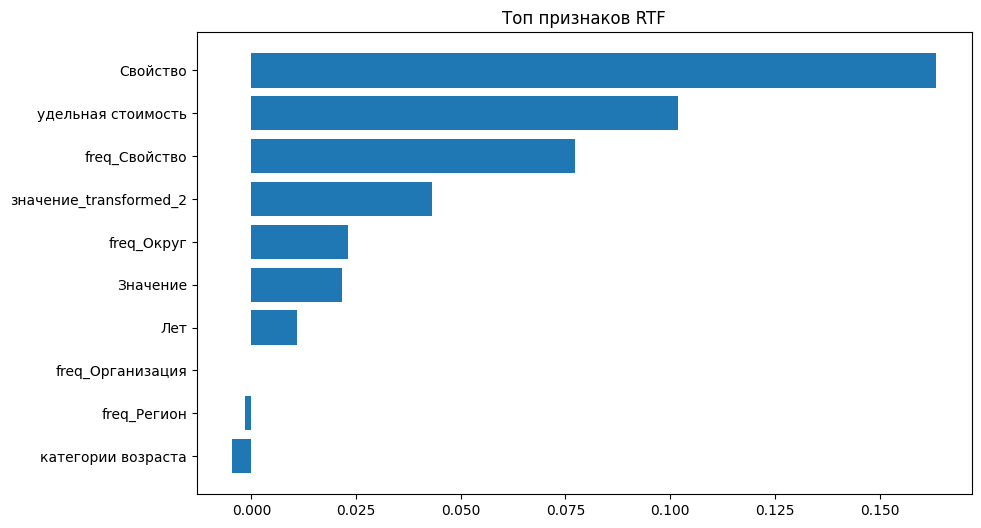

In [373]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [339]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,extra,ros_shrinkage_02,0.5694,0.002,0.059,0.013
0,extra,ros,0.5648,0.003,0.081,0.015
4,extra,gaussian_noise,0.5648,0.001,0.057,0.014
1,extra,ros_shrinkage_005,0.5509,0.002,0.058,0.014
2,extra,ros_shrinkage_01,0.5509,0.002,0.058,0.013


In [378]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.2)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 6 candidates, totalling 24 fits


In [379]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': False, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.6321746031746032
Test accuracy: 0.5694444444444444
Время: 0.6420478820800781


In [380]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.2)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=False,
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": [100, 200, 300, 400, 500],
    "model__max_depth": [None],
    'model__max_features': np.arange(0.1, 1.1, 0.1),
    'model__max_samples': [None],
    'model__min_samples_split': np.arange(2, 11, 2),
    'model__min_samples_leaf': np.arange(1, 10, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 1250 candidates, totalling 5000 fits





In [381]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(0.30000000000000004), 'model__max_samples': None, 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(2), 'model__n_estimators': 400}
Лучшая CV accuracy: 0.6400952380952382
Test accuracy: 0.5787037037037037
Время: 249.86896109580994


In [382]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
6,num__значение_transformed_2,0.114393
4,num__удельная стоимость,0.099305
2,num__Значение,0.086337
11,ord__категории стоимости,0.075373
0,num__Лет,0.075046
12,ord__категории возраста,0.069277
7,num__freq_Регион,0.063600
1,num__Стоимость,0.059167
5,num__износ,0.057895
14,cat__Свойство,0.055629


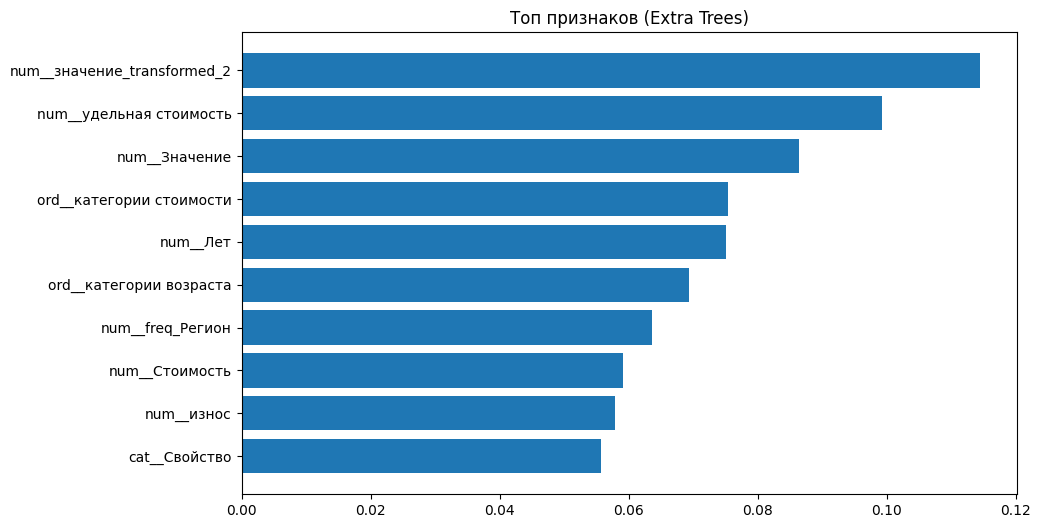

In [383]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [340]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,easy_ensemble,ros_shrinkage_005,0.5602,0.002,0.051,0.012
0,easy_ensemble,ros,0.5556,0.002,3.490,0.077
4,easy_ensemble,gaussian_noise,0.5509,0.001,0.048,0.013
3,easy_ensemble,ros_shrinkage_02,0.5324,0.002,0.059,0.011
2,easy_ensemble,ros_shrinkage_01,0.5278,0.002,0.061,0.013


In [385]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 12 candidates, totalling 24 fits


In [386]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'entropy', 'model__estimator__splitter': 'random', 'model__replacement': False}
Лучшая CV accuracy: 0.580495478403845
Test accuracy: 0.5648148148148148
Время: 1.251690149307251


In [391]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='entropy',
                                         splitter='random',
                                         random_state=123),
        replacement=False,
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": np.arange(5, 35, 5),
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.2, 1.2, 0.2),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 750 candidates, totalling 1500 fits



In [392]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(1.0), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(2), 'model__n_estimators': np.int64(15)}
Лучшая CV accuracy: 0.5983763359261367
Test accuracy: 0.5648148148148148
Время: 18.02046513557434


In [393]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
9,freq_Свойство,0.211420
6,значение_transformed_2,0.118827
2,Значение,0.087963
12,Свойство,0.074074
14,категории возраста,0.072531
7,freq_Регион,0.055556
10,freq_Округ,0.043210
4,удельная стоимость,0.024691
13,категории стоимости,0.021605
8,freq_Организация,0.018519


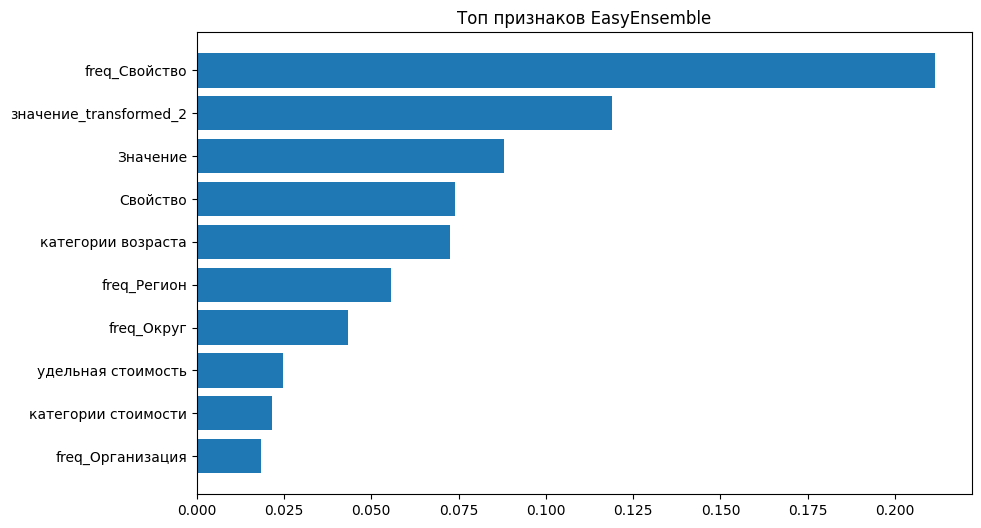

In [394]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [343]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,hgb,ros_shrinkage_005,0.5787,0.002,9.322,0.074
0,hgb,ros,0.5741,0.001,10.457,0.091
3,hgb,ros_shrinkage_02,0.5741,0.002,8.867,0.073
2,hgb,ros_shrinkage_01,0.5694,0.002,8.879,0.075
4,hgb,gaussian_noise,0.5694,0.001,9.012,0.093


In [399]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 3 candidates, totalling 9 fits


In [400]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.5586327345309381
Test accuracy: 0.5879629629629629
Время: 15.153729677200317


In [407]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': [100, 200, 300],
    'clf__learning_rate': [0.01, 0.1],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}

grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 90 candidates, totalling 270 fits


In [408]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__max_depth': None, 'clf__max_features': np.float64(0.2), 'clf__max_iter': 200, 'clf__min_samples_leaf': np.int64(3)}
Лучшая CV accuracy: 0.6063943541488451
Test accuracy: 0.5972222222222222
Время: 145.65432500839233


In [409]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
10,Свойство,1.604938e-01
4,удельная стоимость,1.141975e-01
2,Значение,5.092593e-02
12,категории возраста,3.086420e-02
6,значение_transformed_2,2.932099e-02
7,freq_Организация,1.080247e-02
8,freq_Округ,1.080247e-02
3,if_anomaly,6.172840e-03
0,Лет,3.086420e-03
1,Стоимость,-3.700743e-17


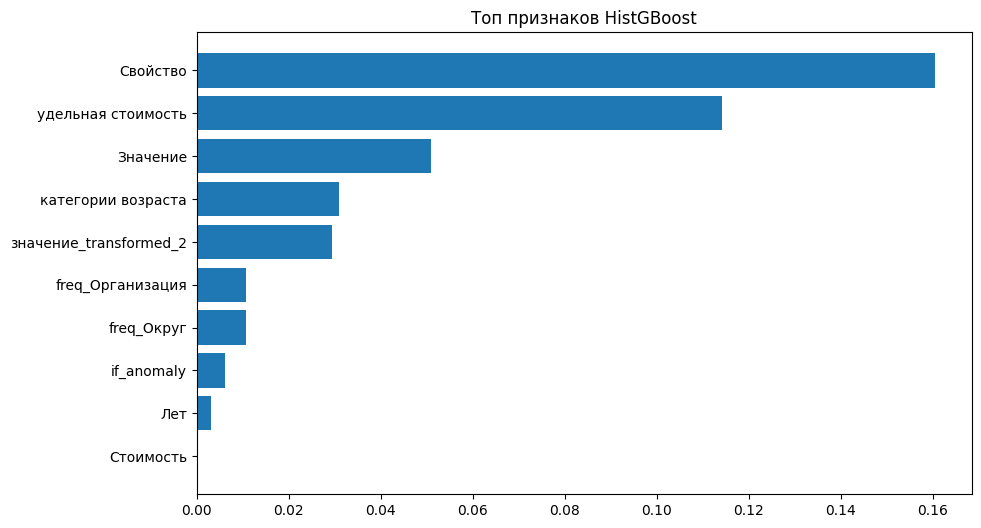

In [410]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [344]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,ada,ros_shrinkage_02,0.5370,0.002,0.025,0.0
0,ada,ros,0.5324,0.001,0.009,0.0
1,ada,ros_shrinkage_005,0.5139,0.002,0.027,0.0
2,ada,ros_shrinkage_01,0.5093,0.002,0.025,0.0
4,ada,gaussian_noise,0.5000,0.001,0.021,0.0


In [413]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.2)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best', 'random'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 6 candidates, totalling 18 fits


In [414]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'gini', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.5288351867693185
Test accuracy: 0.5509259259259259
Время: 0.153397798538208


In [417]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.2)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__estimator__min_samples_split': np.arange(2, 11, 1),
    'clf__estimator__min_samples_leaf': np.arange(1, 10, 1)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 810 candidates, totalling 1620 fits



In [418]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(0.7000000000000001), 'clf__estimator__min_samples_leaf': np.int64(3), 'clf__estimator__min_samples_split': np.int64(6)}
Лучшая CV accuracy: 0.5983684310377537
Test accuracy: 0.5740740740740741
Время: 57.09753179550171


In [421]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.2)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            max_features=0.7,
            max_depth=None,
            min_samples_leaf=3,
            min_samples_split=6,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(100, 600, 100),
    'clf__learning_rate': [0.001, 0.01, 0.1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 15 candidates, totalling 30 fits


In [422]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.1, 'clf__n_estimators': np.int64(300)}
Лучшая CV accuracy: 0.578495541642952
Test accuracy: 0.6203703703703703
Время: 16.619863033294678


In [423]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
12,cat__Свойство,0.138411
4,num__удельная стоимость,0.114189
11,cat__Регион,0.106924
6,num__значение_transformed_2,0.084909
0,num__Лет,0.084855
2,num__Значение,0.081435
1,num__Стоимость,0.071892
5,num__износ,0.063542
10,ord__категории возраста,0.061453
7,num__freq_Организация,0.058932


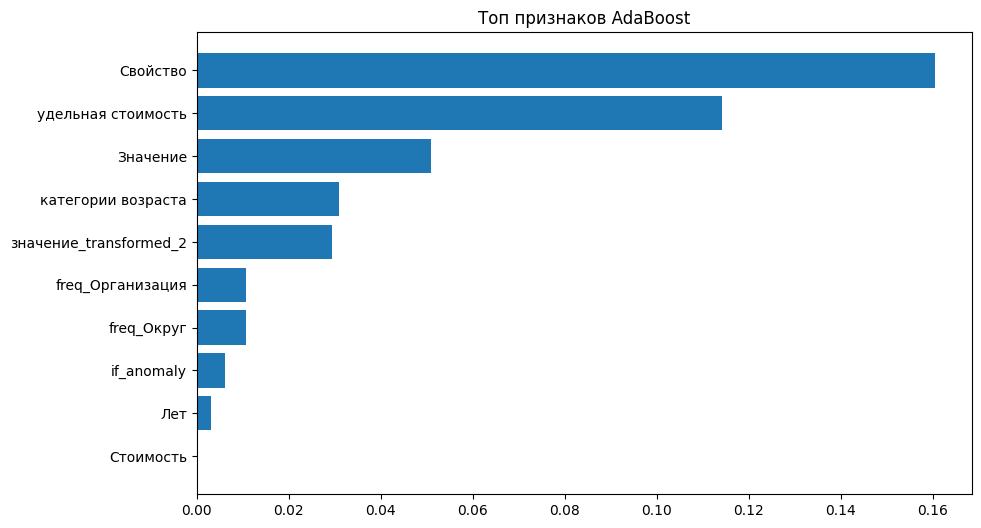

In [424]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков AdaBoost")
plt.show()

### Keras (MLP)

In [345]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [346]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [347]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
  acc=0.4954 | t=3.1s
... (вывод сокращён: 5 строк) ...
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
  acc=0.4954 | t=2.8s
keras+ros_shrinkage_02
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
  acc=0.4167 | t=2.8s
keras+gaussian_noise
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
  acc=0.5231 | t=2.8s

Лучшая балансировка: gaussian_noise


In [431]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [432]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'tanh', 'clf__model__optimizer': 'rmsprop'}
Лучшая CV accuracy: 0.5506138613861387
Test accuracy: 0.5324074074074074
Время: 16.619863033294678


In [433]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation='tanh',
        model__optimizer='rmsprop',
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [64, 128, 256],
    "clf__model__learning_rate": [0.001, 0.01, 0.1],
    "clf__batch_size":           [32, 64, 128],
    "clf__epochs":               [50, 100, 200],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 5 folds for each of 81 candidates, totalling 405 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [32, 64, ...], 'clf__epochs': [50, 100, ...], 'clf__model__learning_rate': [0.001, 0.01, ...], 'clf__model__n_size': [64, 128, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [434]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 32, 'clf__epochs': 200, 'clf__model__learning_rate': 0.001, 'clf__model__n_size': 128}
Лучшая CV accuracy: 0.6161584158415842
Test accuracy: 0.5324074074074074
Время: 16.619863033294678


In [435]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
6,значение_transformed_2,0.135802
4,удельная стоимость,0.132716
12,Свойство,0.097222
11,Регион,0.091049
9,freq_Свойство,0.078704
13,категории стоимости,0.043210
7,freq_Регион,0.043210
14,категории возраста,0.043210
8,freq_Организация,0.040123
2,Значение,0.038580


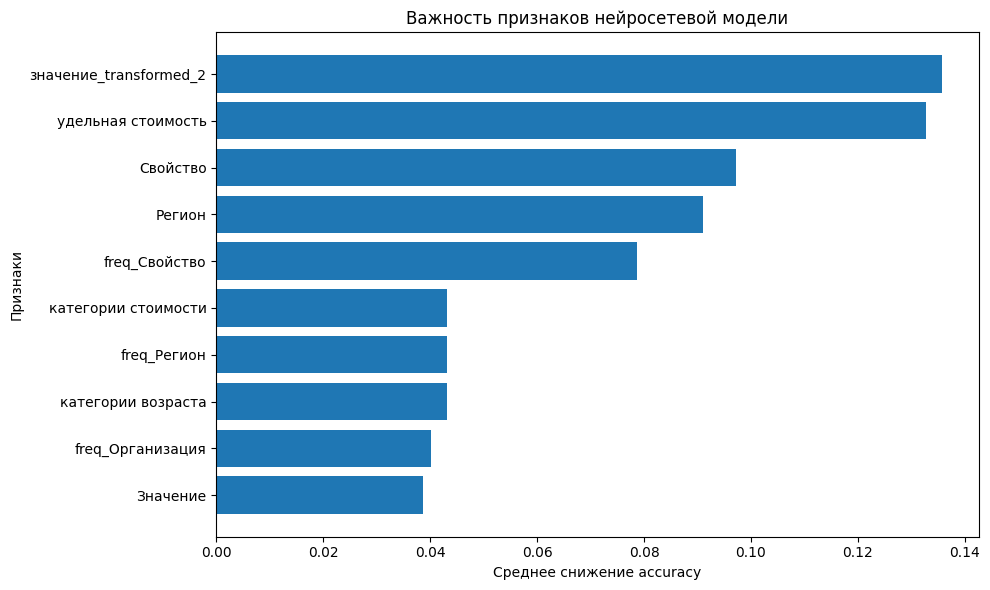

In [436]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

## Подвыборка «м³»: редкие классы

In [170]:
target_col = "Наименование"

class_counts = processed[('м3', 'rare')]['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
processed[('м3', 'rare')]['Наименование'] = processed[('м3', 'rare')]['Наименование'].where(
    ~processed[('м3', 'rare')]['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(processed[('м3', 'rare')]['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 7
Объектов с меткой 'редкий': 13


In [171]:
X = processed[('м3', 'rare')].drop(columns=[target_col])
y = processed[('м3', 'rare')][target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.33,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (85, 15) y_train: (85,)
X_test: (42, 15) y_test: (42,)


In [172]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [173]:
X_train.columns

Index(['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'значение_transformed_2', 'freq_Регион', 'freq_Организация',
       'freq_Родитель', 'freq_Свойство', 'Организация', 'Свойство',
       'категории стоимости', 'категории возраста'],
      dtype='object')

In [174]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'значение_transformed_2', 'freq_Регион',
       'freq_Родитель', 'Организация', 'Свойство',
       'категории стоимости', 'категории возраста']

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'значение_transformed_2', 'freq_Регион',
       'freq_Родитель']
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Организация', 'Свойство']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [1132]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,svm,ros,0.2857,0.003,0.008,0.002
4,svm,gaussian_noise,0.2619,0.001,0.003,0.001
1,svm,ros_shrinkage_005,0.1667,0.004,0.004,0.001
2,svm,ros_shrinkage_01,0.1667,0.002,0.004,0.001
3,svm,ros_shrinkage_02,0.1667,0.044,0.005,0.002


In [1134]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [ ]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'rbf'}
Лучшая CV accuracy: 0.2707641196013289
Время (сек): 0.1949770450592041
Test accuracy: 0.2857142857142857


In [1136]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123)),  
    ('clf', SVC(
        kernel='rbf',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': np.arange(1, 55, 5),
    'clf__gamma': [1e-1, 1e-2, 1e-3],
    'clf__tol': [1e-1, 1e-2, 1e-3, 1e-4],          
    'clf__max_iter': np.arange(1, 55, 5),
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1452 candidates, totalling 2904 fits


... (вывод сокращён: 5 строк) ...













In [1137]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)
y_pred_test = grid_svm2.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_acc)
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': np.int64(1), 'clf__gamma': 0.1, 'clf__max_iter': np.int64(6), 'clf__tol': 0.1}
Лучшая CV accuracy: 0.2353266888150609
Test accuracy: 0.2857142857142857
Время обучения (сек): 7.543350696563721


In [1138]:
pipe = grid_svm2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
})

feat_imp = feat_imp.sort_values(
    "importance",
    ascending=False
)

feat_imp.head(10)

,feature,importance
10,freq_Свойство,0.047619
2,Значение,0.039683
6,значение_transformed_2,0.039683
9,freq_Родитель,0.031746
7,freq_Регион,0.023810
4,удельная стоимость,0.023810
14,категории возраста,0.023810
0,Лет,0.015873
1,Стоимость,0.007937
3,if_anomaly,0.007937


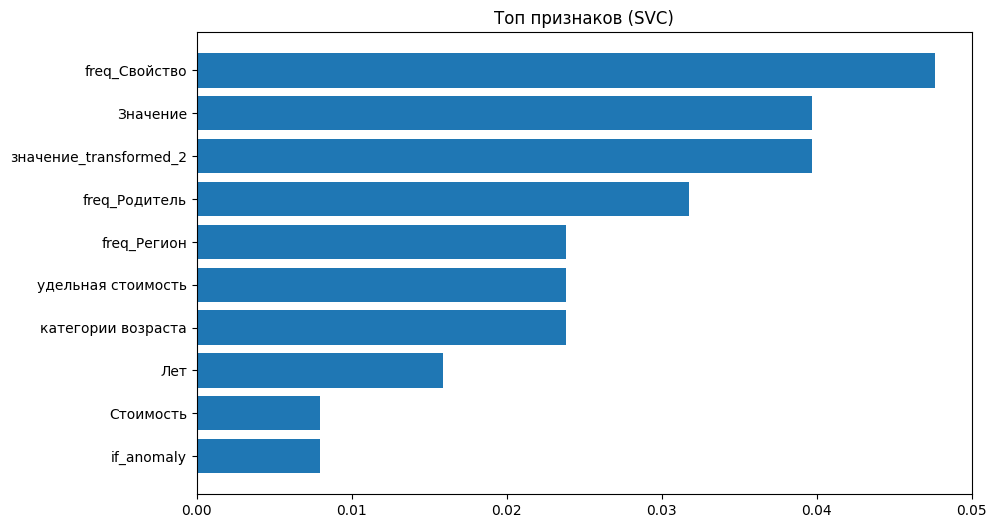

In [1139]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [1140]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,knn,ros,0.1905,0.002,0.0,0.013
4,knn,gaussian_noise,0.1190,0.001,0.0,0.001
1,knn,ros_shrinkage_005,0.0476,0.002,0.0,0.004
2,knn,ros_shrinkage_01,0.0476,0.002,0.0,0.002
3,knn,ros_shrinkage_02,0.0476,0.002,0.0,0.001


In [1141]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [1142]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'uniform'}
Лучшая CV accuracy: 0.15188834154351397
Test accuracy: 0.19047619047619047
Время: 0.19504213333129883


In [1145]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='uniform',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(1, 31, 2),
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__leaf_size': np.arange(1, 31, 2)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 450 candidates, totalling 900 fits







In [1146]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(1), 'clf__metric': 'euclidean', 'clf__n_neighbors': np.int64(1)}
Лучшая CV accuracy: 0.18826135105204872
Test accuracy: 0.21428571428571427
Время: 2.6187729835510254


In [1147]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
2,Значение,0.047619
14,категории возраста,0.031746
0,Лет,0.023810
6,значение_transformed_2,0.023810
4,удельная стоимость,0.015873
5,износ,0.015873
7,freq_Регион,0.007937
13,категории стоимости,0.007937
1,Стоимость,0.000000
3,if_anomaly,0.000000


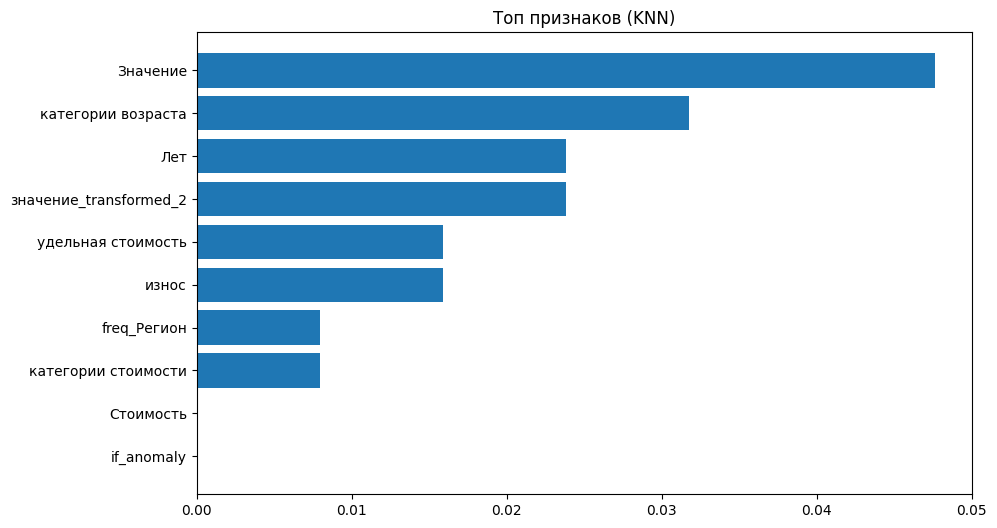

In [1148]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [1149]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,tree,ros_shrinkage_005,0.2857,0.001,0.002,0.0
0,tree,ros,0.2143,0.003,0.003,0.0
2,tree,ros_shrinkage_01,0.2143,0.002,0.002,0.0
3,tree,ros_shrinkage_02,0.2143,0.001,0.002,0.0
4,tree,gaussian_noise,0.2143,0.002,0.002,0.0


In [1167]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [1168]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'entropy', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.2707641196013289
Test accuracy: 0.23809523809523808
Время: 0.09492778778076172


In [1171]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='entropy',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': np.arange(5, 35, 5),
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_split': np.arange(2, 11, 1),
    'clf__min_samples_leaf': np.arange(1, 11, 1)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 5400 candidates, totalling 16200 fits


... (вывод сокращён: 71 строк) ...













In [1172]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': np.int64(10), 'clf__max_features': np.float64(0.6000000000000001), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4)}
Лучшая CV accuracy: 0.270935960591133
Test accuracy: 0.35714285714285715
Время: 13.568151950836182


In [1173]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
10,num__freq_Свойство,0.178698
2,num__Значение,0.174366
0,num__Лет,0.142492
6,num__значение_transformed_2,0.133286
7,num__freq_Регион,0.078132
4,num__удельная стоимость,0.063573
14,cat__Свойство,0.058469
1,num__Стоимость,0.047558
11,ord__категории стоимости,0.036076
5,num__износ,0.022993


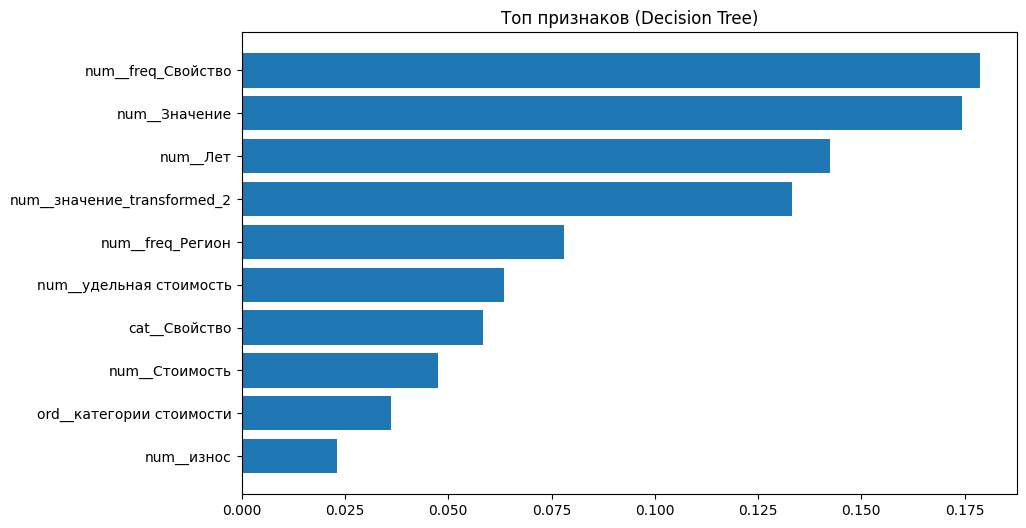

In [1174]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [1175]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rf,ros,0.3333,0.002,0.064,0.015
1,rf,ros_shrinkage_005,0.3095,0.002,0.061,0.013
2,rf,ros_shrinkage_01,0.3095,0.001,0.058,0.015
4,rf,gaussian_noise,0.3095,0.001,0.060,0.013
3,rf,ros_shrinkage_02,0.2381,0.002,0.059,0.013


In [1177]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 3 candidates, totalling 6 fits


In [1178]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini'}
Лучшая CV accuracy: 0.3059246954595792
Test accuracy: 0.3333333333333333
Время: 0.29210591316223145


In [1200]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': np.arange(100, 400, 100),
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__max_samples': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 7500 candidates, totalling 15000 fits















In [1201]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.5), 'clf__max_samples': np.float64(0.9), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(2), 'clf__n_estimators': np.int64(100)}
Лучшая CV accuracy: 0.32973421926910296
Test accuracy: 0.3333333333333333
Время: 275.3363747596741


In [1202]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
4,num__удельная стоимость,0.160164
2,num__Значение,0.146170
6,num__значение_transformed_2,0.124599
1,num__Стоимость,0.086165
5,num__износ,0.072799
7,num__freq_Регион,0.066903
0,num__Лет,0.055742
8,num__freq_Организация,0.055398
10,num__freq_Свойство,0.048864
14,cat__Свойство,0.045813


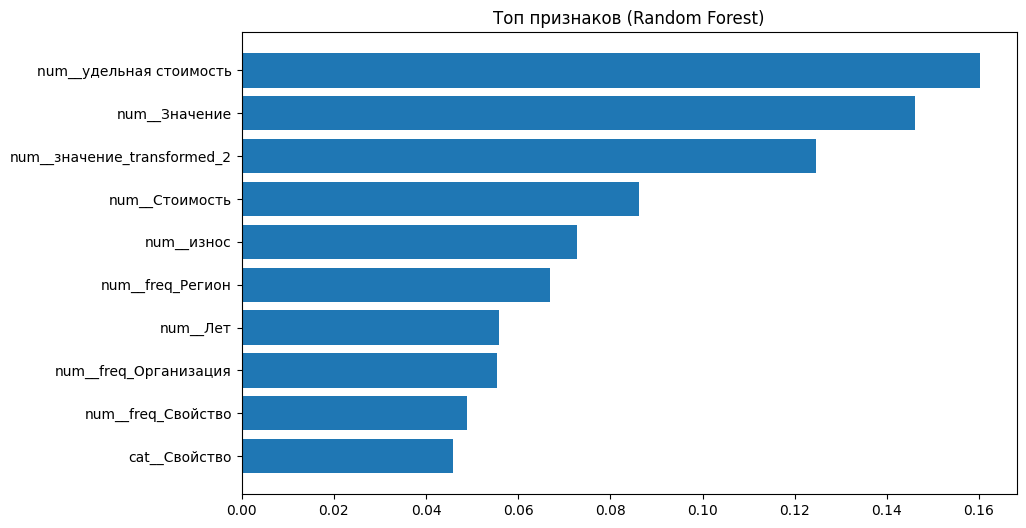

In [1203]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [1204]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,rtf,ros_shrinkage_005,0.3810,0.002,0.486,0.068
2,rtf,ros_shrinkage_01,0.3810,0.001,0.445,0.063
3,rtf,ros_shrinkage_02,0.3810,0.001,0.446,0.064
0,rtf,ros,0.3333,0.004,0.482,0.067
4,rtf,gaussian_noise,0.3095,0.002,0.451,0.063


In [1207]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best", "random"],
    "model__pca_solver": ["auto", "full", "randomized"],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 18 candidates, totalling 54 fits


In [1208]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'gini', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'randomized'}
Лучшая CV accuracy: 0.3522167487684729
Test accuracy: 0.35714285714285715
Время: 6.083966970443726


In [1211]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.1, 1.1, 0.1), 
    'model__base_estimator__min_samples_split': np.arange(2, 11, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 250 candidates, totalling 750 fits


In [1212]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(1.0), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.3522167487684729
Test accuracy: 0.35714285714285715
Время: 74.35400390625


In [1215]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              max_features=1.0,
                                              max_depth=None,
                                              min_samples_leaf=1,
                                              min_samples_split=2,
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": np.arange(100, 400, 100),
    "model__min_group": [1, 2, 3],
    "model__max_group": [1, 2, 3],
    "model__remove_proportion": np.arange(0.1, 1.0, 0.1),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 243 candidates, totalling 486 fits



In [1216]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 3, 'model__min_group': 2, 'model__n_estimators': np.int64(100), 'model__remove_proportion': np.float64(0.1)}
Лучшая CV accuracy: 0.3059246954595792
Test accuracy: 0.35714285714285715
Время: 52.099963903427124


In [1217]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=6
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
6,значение_transformed_2,0.142857
12,Свойство,0.087302
2,Значение,0.063492
9,freq_Родитель,0.055556
4,удельная стоимость,0.047619
10,freq_Свойство,0.031746
3,if_anomaly,0.015873
13,категории стоимости,0.007937
14,категории возраста,0.007937
7,freq_Регион,0.000000


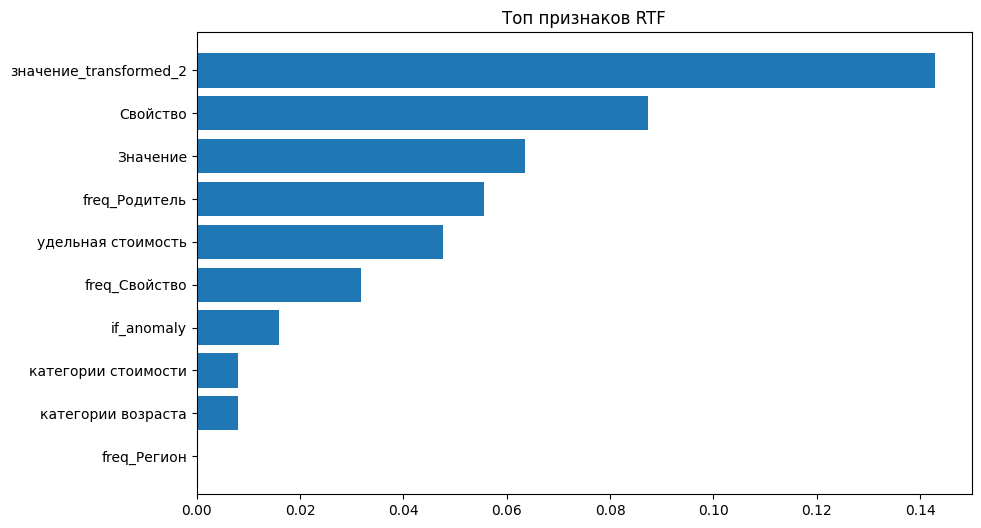

In [1218]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [175]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,extra,ros_shrinkage_005,0.3571,0.002,0.037,0.013
4,extra,gaussian_noise,0.3333,0.001,0.037,0.013
3,extra,ros_shrinkage_02,0.3095,0.001,0.036,0.013
0,extra,ros,0.2381,0.002,0.052,0.012
2,extra,ros_shrinkage_01,0.2381,0.001,0.035,0.012


In [186]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 6 candidates, totalling 24 fits


In [187]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': False, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.2824675324675324
Test accuracy: 0.35714285714285715
Время: 0.3488330841064453


In [206]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=False,
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": np.arange(300, 550, 50),
    "model__max_depth": [None, 10, 20],
    'model__max_features': np.arange(0.25, 1.25, 0.25),
    'model__max_samples': [None],
    'model__min_samples_split': np.arange(2, 9, 2),
    'model__min_samples_leaf': np.arange(1, 8, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 960 candidates, totalling 1920 fits


In [1236]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(0.30000000000000004), 'model__max_samples': None, 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(6), 'model__n_estimators': np.int64(100)}
Лучшая CV accuracy: 0.3059246954595792
Test accuracy: 0.38095238095238093
Время: 26.083954095840454


In [1237]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
6,num__значение_transformed_2,0.119967
4,num__удельная стоимость,0.117382
2,num__Значение,0.111333
11,ord__категории стоимости,0.079561
1,num__Стоимость,0.071073
7,num__freq_Регион,0.068106
9,num__freq_Родитель,0.057890
0,num__Лет,0.057126
10,num__freq_Свойство,0.053443
13,cat__Организация,0.052358


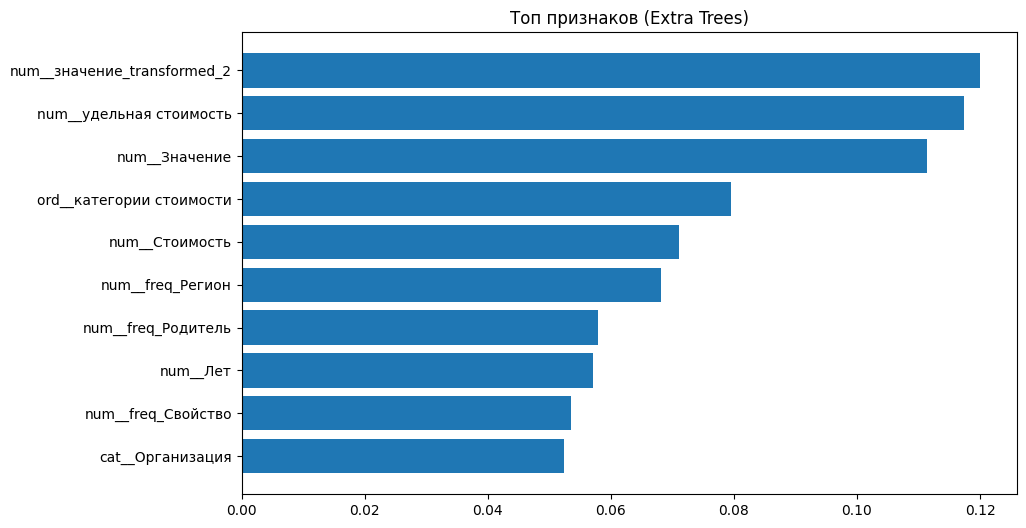

In [1238]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [1239]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,easy_ensemble,ros_shrinkage_005,0.2619,0.001,0.024,0.012
4,easy_ensemble,gaussian_noise,0.2381,0.001,0.023,0.013
0,easy_ensemble,ros,0.2143,0.003,0.733,0.012
2,easy_ensemble,ros_shrinkage_01,0.2143,0.001,0.025,0.012
3,easy_ensemble,ros_shrinkage_02,0.2143,0.001,0.026,0.013


In [1241]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 12 candidates, totalling 24 fits



In [1242]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'entropy', 'model__estimator__splitter': 'random', 'model__replacement': False}
Лучшая CV accuracy: 0.2707641196013289
Test accuracy: 0.35714285714285715
Время: 3.6730101108551025


In [1249]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='gini',
                                         splitter='random',
                                         random_state=123),
        replacement=False,
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": np.arange(25, 125, 25),
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.1, 1.1, 0.1),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1000 candidates, totalling 2000 fits


In [1250]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(0.7000000000000001), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(6), 'model__n_estimators': np.int64(25)}
Лучшая CV accuracy: 0.3062015503875969
Test accuracy: 0.35714285714285715
Время: 37.15854597091675


In [1251]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
10,freq_Свойство,0.119048
6,значение_transformed_2,0.111111
2,Значение,0.071429
7,freq_Регион,0.071429
12,Свойство,0.063492
3,if_anomaly,0.055556
0,Лет,0.055556
11,Организация,0.039683
5,износ,0.023810
4,удельная стоимость,0.015873


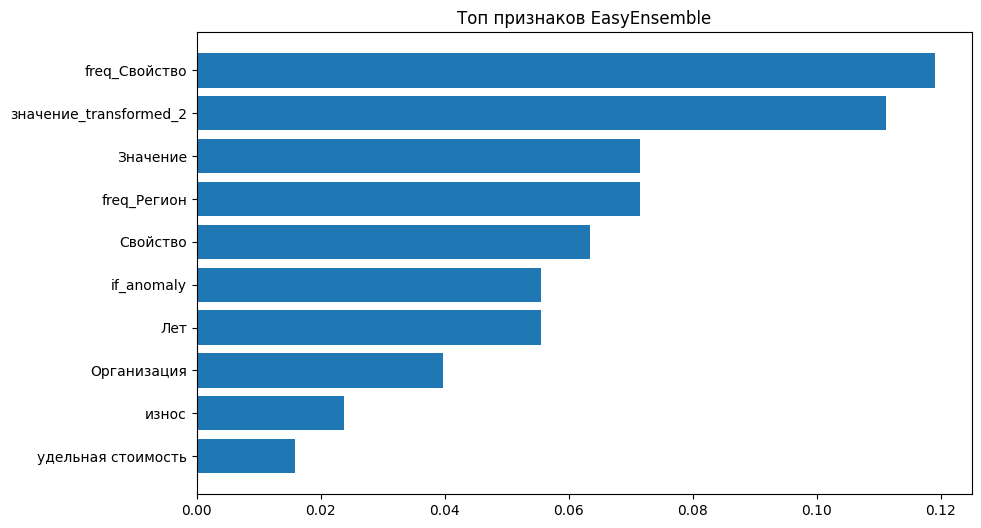

In [1252]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [1253]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,hgb,ros_shrinkage_005,0.3333,0.002,2.860,0.065
0,hgb,ros,0.2381,0.001,4.582,0.085
2,hgb,ros_shrinkage_01,0.2381,0.001,2.417,0.068
3,hgb,ros_shrinkage_02,0.2381,0.001,2.396,0.068
4,hgb,gaussian_noise,0.2381,0.001,2.498,0.066


In [1254]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 3 candidates, totalling 6 fits


In [1255]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.22314507198228128
Test accuracy: 0.3333333333333333
Время: 5.8489789962768555


In [1276]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': np.arange(50, 175, 25),
    'clf__learning_rate': [0.01, 0.1],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}

grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 300 candidates, totalling 900 fits


In [1277]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__max_depth': None, 'clf__max_features': np.float64(0.2), 'clf__max_iter': np.int64(50), 'clf__min_samples_leaf': np.int64(3)}
Лучшая CV accuracy: 0.3407224958949097
Test accuracy: 0.3333333333333333
Время: 90.77374267578125


In [1278]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
4,удельная стоимость,1.031746e-01
10,Свойство,7.142857e-02
2,Значение,6.349206e-02
8,freq_Родитель,4.761905e-02
6,значение_transformed_2,3.968254e-02
5,износ,3.174603e-02
1,Стоимость,2.380952e-02
7,freq_Регион,2.380952e-02
12,категории возраста,1.587302e-02
0,Лет,-1.850372e-17


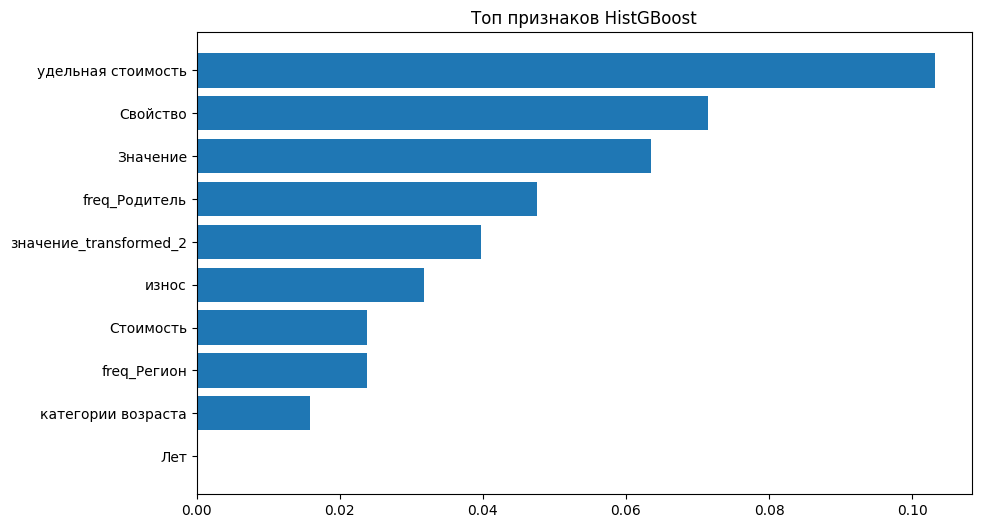

In [1279]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [1280]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,ada,gaussian_noise,0.2857,0.001,0.002,0.0
1,ada,ros_shrinkage_005,0.2143,0.003,0.003,0.0
3,ada,ros_shrinkage_02,0.2143,0.001,0.002,0.0
2,ada,ros_shrinkage_01,0.1905,0.001,0.002,0.0
0,ada,ros,0.0952,0.001,0.002,0.0


In [1286]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best', 'random'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 6 candidates, totalling 24 fits


In [1287]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'entropy', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.23430735930735927
Test accuracy: 0.30952380952380953
Время: 0.2826650142669678


In [1292]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='entropy',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__estimator__min_samples_split': np.arange(2, 11, 1),
    'clf__estimator__min_samples_leaf': np.arange(1, 10, 1)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 810 candidates, totalling 3240 fits










In [1293]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(0.5), 'clf__estimator__min_samples_leaf': np.int64(8), 'clf__estimator__min_samples_split': np.int64(6)}
Лучшая CV accuracy: 0.3398268398268398
Test accuracy: 0.30952380952380953
Время: 28.533381938934326


In [1316]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='entropy',
            splitter='best',
            max_features=0.5,
            max_depth=None,
            min_samples_leaf=8,
            min_samples_split=6,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(100, 410, 10),
    'clf__learning_rate': [0.01, 0.05, 0.1, 1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 124 candidates, totalling 496 fits


In [1317]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.1, 'clf__n_estimators': np.int64(330)}
Лучшая CV accuracy: 0.3046536796536797
Test accuracy: 0.30952380952380953
Время: 14.801047086715698


In [1318]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
2,num__Значение,0.203994
6,num__значение_transformed_2,0.157452
4,num__удельная стоимость,0.116089
12,cat__Свойство,0.115101
11,cat__Организация,0.088697
1,num__Стоимость,0.067016
7,num__freq_Регион,0.063108
0,num__Лет,0.058070
5,num__износ,0.038701
8,num__freq_Родитель,0.032925


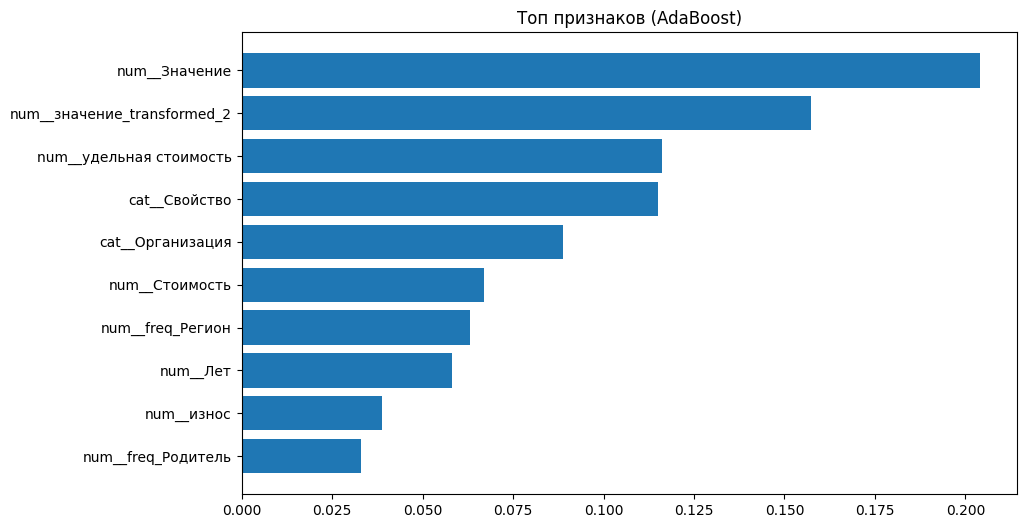

In [1319]:
top_n = 10
top_features = feat_imp_ada.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (AdaBoost)")
plt.show()

### Keras (MLP)

In [1320]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [1321]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [1324]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
  acc=0.1905 | t=2.1s
keras+ros_shrinkage_005
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
  acc=0.1905 | t=1.7s
keras+ros_shrinkage_01
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
  acc=0.1905 | t=1.6s
keras+ros_shrinkage_02
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
  acc=0.1905 | t=1.6s
keras+gaussian_noise
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
  acc=0.2381 | t=1.6s

Лучшая балансировка: gaussian_noise


In [1325]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 2 folds for each of 9 candidates, totalling 18 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [1326]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'relu', 'clf__model__optimizer': 'rmsprop'}
Лучшая CV accuracy: 0.1760797342192691
Test accuracy: 0.2619047619047619
Время: 14.801047086715698


In [1329]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation=best_activation,
        model__optimizer=best_optimizer,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [128, 256, 512],
    "clf__model__learning_rate": [0.001, 0.005, 0.01],
    "clf__batch_size":           [64, 128, 256],
    "clf__epochs":               [50, 100, 200],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 3 folds for each of 81 candidates, totalling 243 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [64, 128, ...], 'clf__epochs': [50, 100, ...], 'clf__model__learning_rate': [0.001, 0.005, ...], 'clf__model__n_size': [128, 256, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [1331]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 64, 'clf__epochs': 200, 'clf__model__learning_rate': 0.01, 'clf__model__n_size': 128}
Лучшая CV accuracy: 0.2582101806239738
Test accuracy: 0.30952380952380953
Время: 14.801047086715698


In [1332]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
6,значение_transformed_2,0.103175
4,удельная стоимость,0.079365
0,Лет,0.047619
2,Значение,0.047619
10,freq_Свойство,0.039683
12,Свойство,0.023810
9,freq_Родитель,0.015873
13,категории стоимости,0.015873
3,if_anomaly,0.007937
11,Организация,0.007937


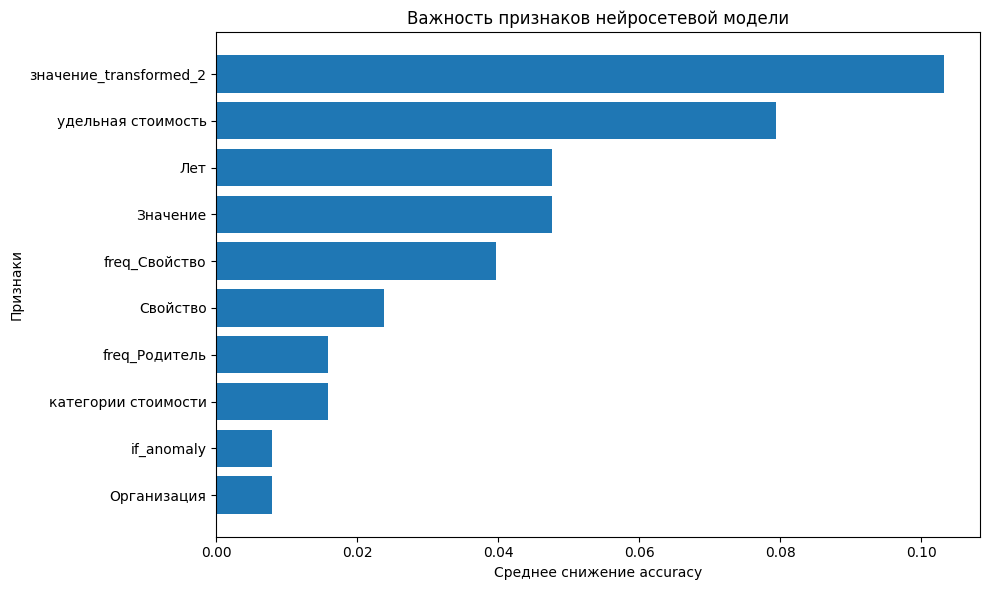

In [1333]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

## Подвыборка «шт»: нормальные классы

In [437]:
target_col = "Наименование"

class_counts = processed[('шт', 'normal')]['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
processed[('шт', 'normal')]['Наименование'] = processed[('шт', 'normal')]['Наименование'].where(
    ~processed[('шт', 'normal')]['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(processed[('шт', 'normal')]['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 2
Объектов с меткой 'редкий': 4


In [438]:
X = processed[('шт', 'normal')].drop(columns=[target_col])
y = processed[('шт', 'normal')][target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.3,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (884, 18) y_train: (884,)
X_test: (380, 18) y_test: (380,)


In [439]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [440]:
X_train.columns

Index(['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация', 'freq_Родитель', 'freq_Свойство',
       'freq_Округ', 'Регион', 'Организация', 'Свойство',
       'категории стоимости', 'категории возраста'],
      dtype='object')

In [441]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Родитель', 'freq_Округ', 'Регион', 'Организация', 'Свойство',
       'категории стоимости', 'категории возраста']

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Родитель', 'freq_Округ', ]
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Регион', 'Организация', 'Свойство']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [1338]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,svm,gaussian_noise,0.7921,0.014,0.156,0.043
0,svm,ros,0.7737,0.009,0.178,0.089
2,svm,ros_shrinkage_01,0.7553,0.010,0.206,0.250
3,svm,ros_shrinkage_02,0.7526,0.013,0.228,0.116
1,svm,ros_shrinkage_005,0.7500,0.015,0.199,0.110


In [1363]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [1364]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'linear'}
Лучшая CV accuracy: 0.7341628959276019
Время (сек): 0.6011316776275635
Test accuracy: 0.7789473684210526


In [1368]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(
        kernel='linear',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': [0.001, 0.01, 0.1, 1, 10, 100],    
    'clf__tol': [1e-1, 1e-2, 1e-3, 1e-4],          
    'clf__max_iter': np.arange(10, 110, 10),
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 240 candidates, totalling 480 fits


In [1369]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)
y_pred_test = grid_svm2.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_acc)
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': 1, 'clf__max_iter': np.int64(60), 'clf__tol': 0.01}
Лучшая CV accuracy: 0.7409502262443439
Test accuracy: 0.7789473684210526
Время обучения (сек): 6.4167320728302


In [1370]:
pipe = grid_svm2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

importances = np.abs(model.coef_).mean(axis=0)

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,num__freq_Свойство,0.335656
81,cat__Свойство_количество точек подключения,0.172471
7,num__значение_transformed_2,0.135667
10,num__freq_Родитель,0.115752
77,cat__Свойство_количество контролируемых параме...,0.112006
6,num__стоимость_transformed_2,0.111715
80,cat__Свойство_количество точек мониторинга,0.106090
0,num__Лет,0.097498
1,num__Стоимость,0.095775
85,cat__категории стоимости_очень низкая,0.091626


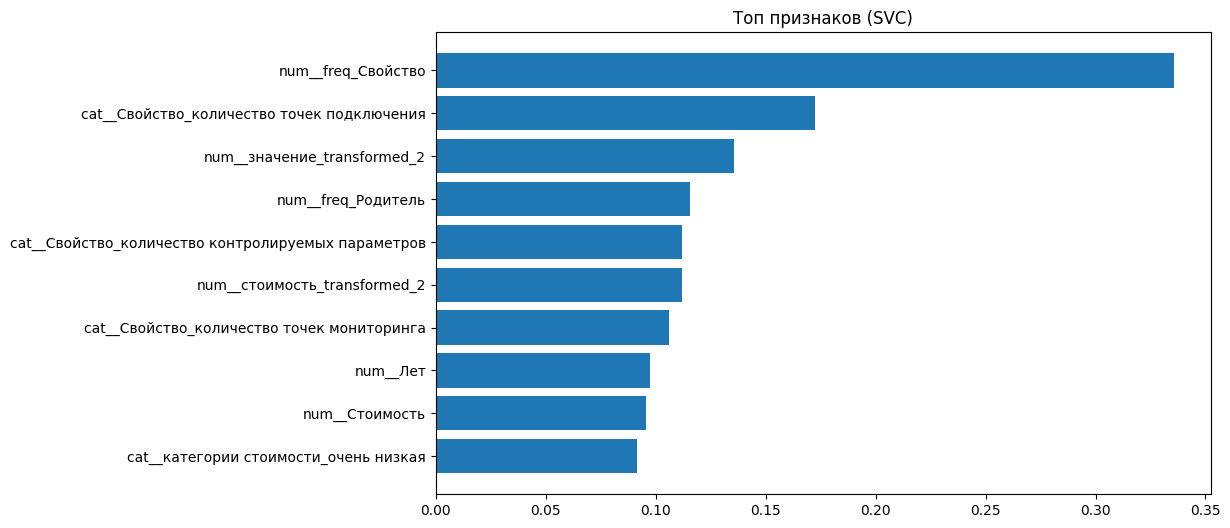

In [1371]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [1372]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,knn,gaussian_noise,0.6447,0.017,0.000,0.005
2,knn,ros_shrinkage_01,0.6395,0.009,0.001,0.004
3,knn,ros_shrinkage_02,0.6395,0.010,0.000,0.004
1,knn,ros_shrinkage_005,0.6342,0.011,0.001,0.004
0,knn,ros,0.6184,0.004,0.003,0.018


In [1375]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [1376]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'distance'}
Лучшая CV accuracy: 0.5938914027149321
Test accuracy: 0.7052631578947368
Время: 0.3535020351409912


In [1377]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='distance',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(1, 31, 2),
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__leaf_size': np.arange(1, 31, 2)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 450 candidates, totalling 1350 fits











In [1378]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(1), 'clf__metric': 'manhattan', 'clf__n_neighbors': np.int64(11)}
Лучшая CV accuracy: 0.6866136285022484
Test accuracy: 0.7236842105263158
Время: 9.798747777938843


In [1379]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
15,Свойство,0.191228
11,freq_Свойство,0.107018
7,значение_transformed_2,0.058772
16,категории стоимости,0.037719
1,Стоимость,0.028070
6,стоимость_transformed_2,0.022807
2,Значение,0.019298
9,freq_Организация,0.017544
10,freq_Родитель,0.015789
0,Лет,0.015789


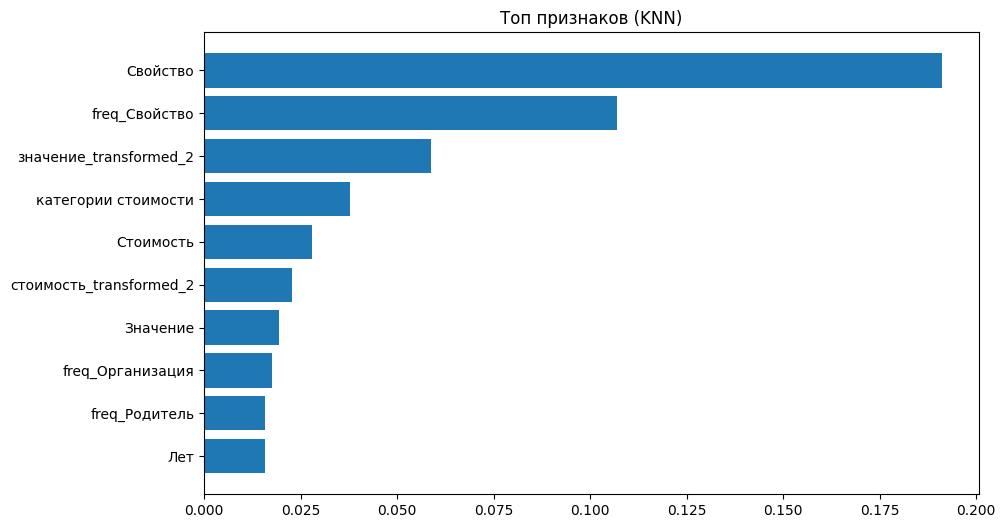

In [1380]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [1381]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,tree,ros_shrinkage_02,0.8158,0.004,0.098,0.0
2,tree,ros_shrinkage_01,0.8026,0.004,0.097,0.0
1,tree,ros_shrinkage_005,0.7816,0.005,0.097,0.0
4,tree,gaussian_noise,0.7632,0.003,0.084,0.0
0,tree,ros,0.7395,0.003,0.021,0.0


In [1386]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.2)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 6 candidates, totalling 24 fits


In [1387]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.7567873303167421
Test accuracy: 0.8157894736842105
Время: 0.2970597743988037


In [1412]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.2)),
    ('clf', DecisionTreeClassifier(
        criterion='gini',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': [None, 5, 10, 15, 20, 25],
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_split': np.arange(2, 11, 1),
    'clf__min_samples_leaf': np.arange(1, 11, 1)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 5400 candidates, totalling 21600 fits


... (вывод сокращён: 67 строк) ...













In [1413]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.7000000000000001), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(6)}
Лучшая CV accuracy: 0.7794117647058824
Test accuracy: 0.7973684210526316
Время: 109.71531701087952


In [1414]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,num__freq_Свойство,0.190067
17,cat__Свойство,0.100575
2,num__Значение,0.097428
0,num__Лет,0.083571
4,num__удельная стоимость,0.081786
1,num__Стоимость,0.063123
10,num__freq_Родитель,0.059000
6,num__стоимость_transformed_2,0.046264
12,num__freq_Округ,0.041869
7,num__значение_transformed_2,0.041535


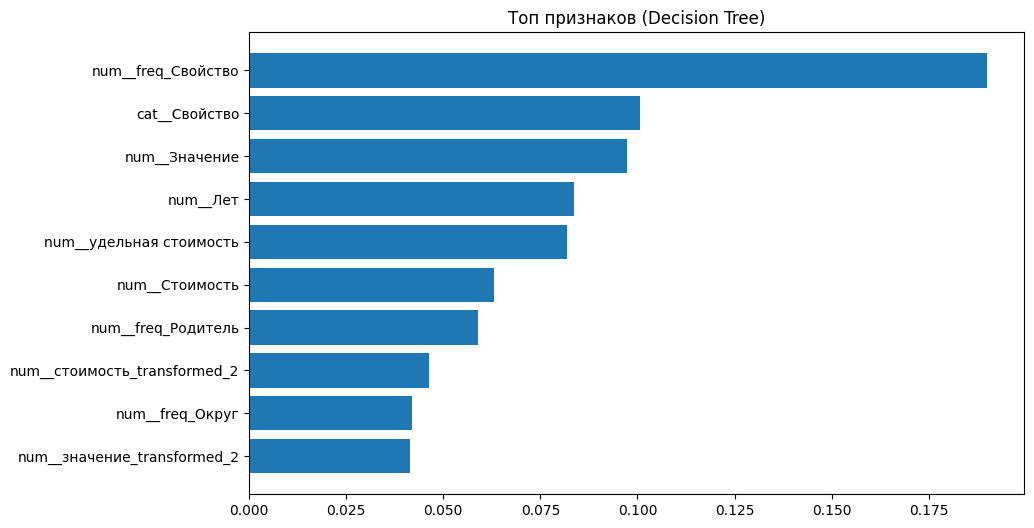

In [1415]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [442]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,rf,ros_shrinkage_005,0.8211,0.007,0.162,0.016
0,rf,ros,0.8158,0.004,0.088,0.014
3,rf,ros_shrinkage_02,0.8105,0.010,0.248,0.015
4,rf,gaussian_noise,0.8105,0.004,0.184,0.014
2,rf,ros_shrinkage_01,0.8079,0.003,0.179,0.015


In [445]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 3 candidates, totalling 9 fits


In [446]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini'}
Лучшая CV accuracy: 0.7861793304892579
Test accuracy: 0.8210526315789474
Время: 1.239058017730713


In [449]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': [25, 50, 75],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__max_samples': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 1875 candidates, totalling 5625 fits

















In [450]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.6000000000000001), 'clf__max_samples': np.float64(0.4), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(2), 'clf__n_estimators': 50}
Лучшая CV accuracy: 0.7975133556247358
Test accuracy: 0.8236842105263158
Время: 322.17371702194214


In [1423]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
11,num__freq_Свойство,0.143978
17,cat__Свойство,0.128944
2,num__Значение,0.079466
1,num__Стоимость,0.071484
4,num__удельная стоимость,0.068633
5,num__износ,0.061035
10,num__freq_Родитель,0.058556
6,num__стоимость_transformed_2,0.058398
9,num__freq_Организация,0.047322
12,num__freq_Округ,0.046371


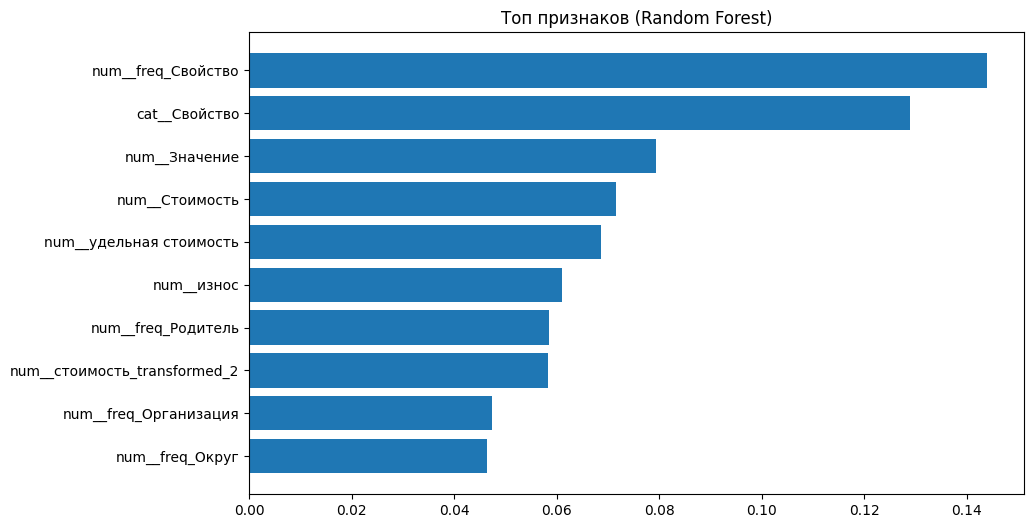

In [1424]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [451]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rtf,ros,0.8211,0.005,1.266,0.106
1,rtf,ros_shrinkage_005,0.8211,0.003,3.091,0.100
2,rtf,ros_shrinkage_01,0.8105,0.003,2.731,0.106
3,rtf,ros_shrinkage_02,0.7974,0.003,2.828,0.106
4,rtf,gaussian_noise,0.7974,0.002,2.451,0.100


In [454]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best", "random"],
    "model__pca_solver": ["auto", "full", "randomized"],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 18 candidates, totalling 54 fits


In [455]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'entropy', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'auto'}
Лучшая CV accuracy: 0.7929628348514547
Test accuracy: 0.8210526315789474
Время: 19.42470407485962


In [456]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='entropy',
                                              splitter='best',
                                              random_state=123),
        pca_solver='auto',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.2, 1.2, 0.2), 
    'model__base_estimator__min_samples_split': np.arange(2, 11, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 125 candidates, totalling 375 fits


In [457]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(0.4), 'model__base_estimator__min_samples_leaf': np.int64(3), 'model__base_estimator__min_samples_split': np.int64(8)}
Лучшая CV accuracy: 0.8020215996002921
Test accuracy: 0.8105263157894737
Время: 105.50712704658508


In [458]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='entropy',
                                              splitter='best',
                                              max_features=0.4,
                                              max_depth=None,
                                              min_samples_leaf=3,
                                              min_samples_split=8,
                                              random_state=123),
        pca_solver='auto',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": np.arange(100, 600, 100),
    "model__min_group": [1, 2, 3],
    "model__max_group": [1, 2, 3],
    "model__remove_proportion": np.arange(0.1, 1.0, 0.1),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 405 candidates, totalling 1215 fits





In [459]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 3, 'model__min_group': 2, 'model__n_estimators': np.int64(400), 'model__remove_proportion': np.float64(0.8)}
Лучшая CV accuracy: 0.8065452169568393
Test accuracy: 0.8105263157894737
Время: 319.10953187942505


In [1450]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=6
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,freq_Свойство,0.345614
15,Свойство,0.271930
10,freq_Родитель,0.034211
1,Стоимость,0.014035
13,Регион,0.012281
6,стоимость_transformed_2,0.012281
9,freq_Организация,0.010526
16,категории стоимости,0.008772
4,удельная стоимость,0.008772
0,Лет,0.007895


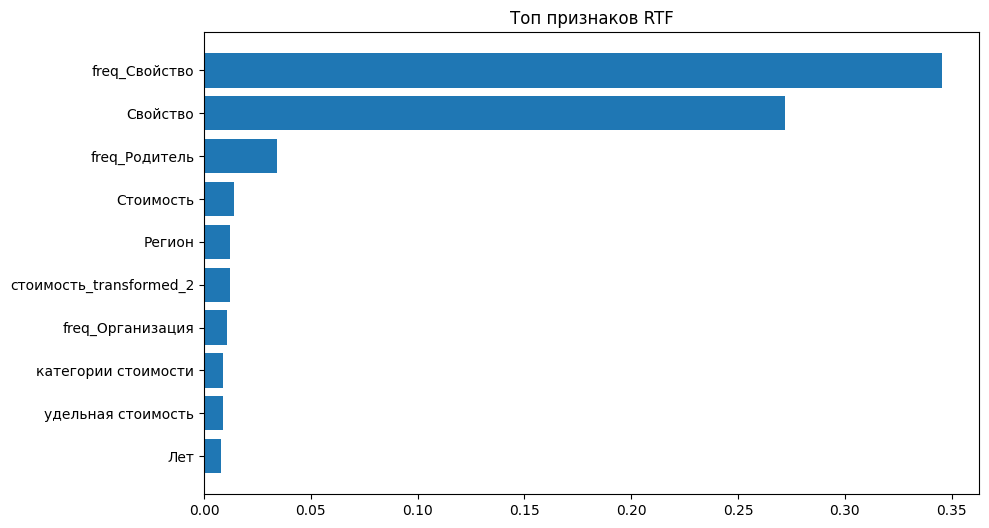

In [1451]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [460]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,extra,ros,0.8158,0.005,0.120,0.012
4,extra,gaussian_noise,0.8053,0.003,0.060,0.014
3,extra,ros_shrinkage_02,0.8026,0.006,0.061,0.014
1,extra,ros_shrinkage_005,0.8000,0.003,0.062,0.014
2,extra,ros_shrinkage_01,0.8000,0.005,0.063,0.014


In [468]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 6 candidates, totalling 24 fits


In [469]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': False, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.7873303167420814
Test accuracy: 0.8157894736842105
Время: 0.8742501735687256


In [471]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=False,
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": [100, 200, 300, 400, 500],
    "model__max_depth": [None],
    'model__max_features': np.arange(0.2, 1.2, 0.2),
    'model__max_samples': [None],
    'model__min_samples_split': np.arange(2, 11, 2),
    'model__min_samples_leaf': np.arange(1, 10, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 625 candidates, totalling 2500 fits





In [472]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(0.4), 'model__max_samples': None, 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(6), 'model__n_estimators': 200}
Лучшая CV accuracy: 0.7918552036199095
Test accuracy: 0.8105263157894737
Время: 190.98833394050598


In [1457]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
17,cat__Свойство,0.135071
11,num__freq_Свойство,0.134512
13,ord__категории стоимости,0.072319
2,num__Значение,0.071857
6,num__стоимость_transformed_2,0.062351
1,num__Стоимость,0.059157
10,num__freq_Родитель,0.054295
7,num__значение_transformed_2,0.051822
5,num__износ,0.049178
0,num__Лет,0.046968


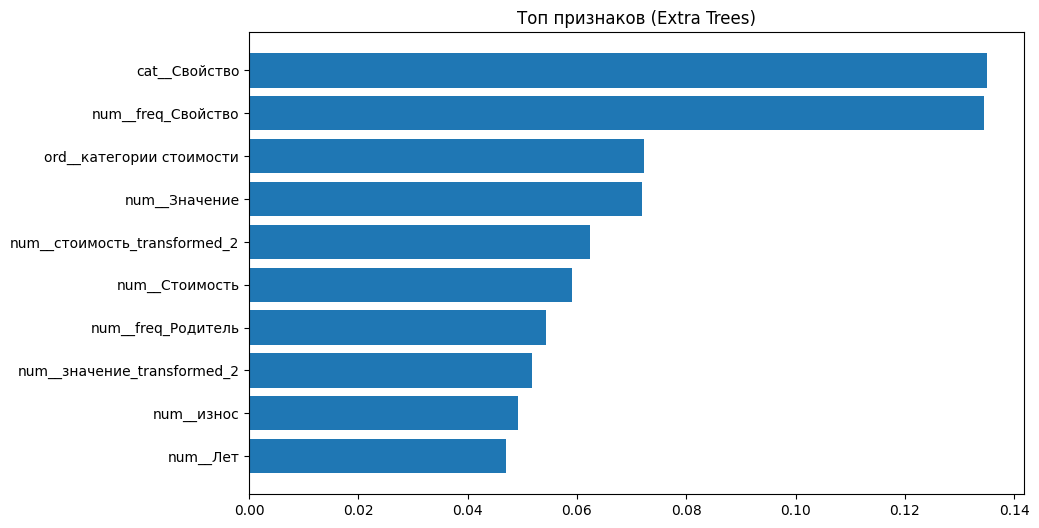

In [1458]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [473]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,easy_ensemble,ros_shrinkage_02,0.8132,0.004,0.153,0.013
2,easy_ensemble,ros_shrinkage_01,0.7974,0.003,0.160,0.013
4,easy_ensemble,gaussian_noise,0.7737,0.002,0.133,0.012
1,easy_ensemble,ros_shrinkage_005,0.7711,0.004,0.142,0.012
0,easy_ensemble,ros,0.7579,0.002,0.763,0.013


In [474]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.2, random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 12 candidates, totalling 24 fits


In [475]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'gini', 'model__estimator__splitter': 'random', 'model__replacement': False}
Лучшая CV accuracy: 0.7647058823529411
Test accuracy: 0.8157894736842105
Время: 3.1729211807250977


In [476]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='gini',
                                         splitter='random',
                                         random_state=123),
        replacement=False,
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": np.arange(50, 250, 50),
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.1, 1.1, 0.1),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 1000 candidates, totalling 3000 fits




In [477]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(0.5), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(4), 'model__n_estimators': np.int64(50)}
Лучшая CV accuracy: 0.8020292862907876
Test accuracy: 0.8157894736842105
Время: 191.73985600471497


In [1469]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,freq_Свойство,0.257018
15,Свойство,0.245614
16,категории стоимости,0.038596
10,freq_Родитель,0.023684
9,freq_Организация,0.021053
5,износ,0.014035
13,Регион,0.010526
12,freq_Округ,0.009649
0,Лет,0.009649
6,стоимость_transformed_2,0.008772


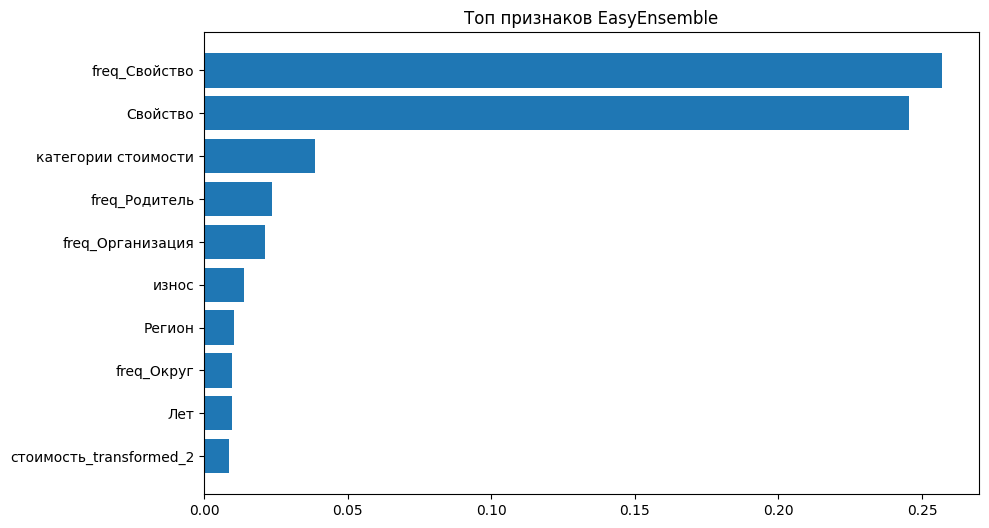

In [1470]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [1471]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,hgb,gaussian_noise,0.7500,0.003,25.115,0.228
0,hgb,ros,0.7421,0.002,28.206,0.285
3,hgb,ros_shrinkage_02,0.7289,0.004,31.502,0.208
1,hgb,ros_shrinkage_005,0.7263,0.010,24.913,0.194
2,hgb,ros_shrinkage_01,0.7158,0.004,27.038,0.190


In [1472]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 3 candidates, totalling 15 fits


In [1473]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.7115241397021058
Test accuracy: 0.7605263157894737
Время: 38.90052914619446


In [1523]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': [100, 200, 300],
    'clf__learning_rate': [0.01, 0.05],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}

grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 90 candidates, totalling 450 fits


In [1524]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.05, 'clf__max_depth': None, 'clf__max_features': np.float64(0.4), 'clf__max_iter': 200, 'clf__min_samples_leaf': np.int64(1)}
Лучшая CV accuracy: 0.732993066255778
Test accuracy: 0.7578947368421053
Время: 338.6316568851471


In [1525]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
12,Свойство,0.328070
2,Значение,0.192105
7,значение_transformed_2,0.053509
8,freq_Родитель,0.044737
5,износ,0.028070
0,Лет,0.013158
13,категории стоимости,0.011404
6,стоимость_transformed_2,0.007895
14,категории возраста,0.007018
3,if_anomaly,0.004386


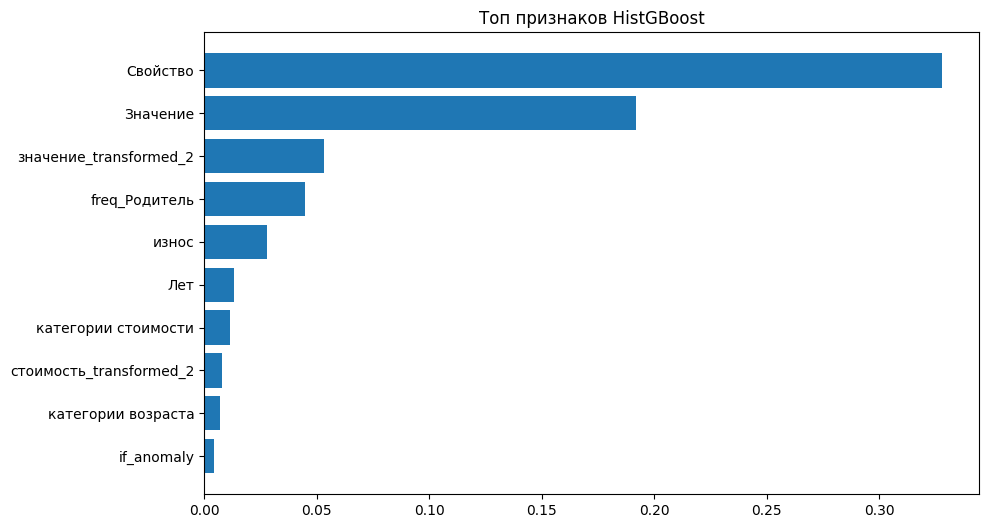

In [1526]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [1527]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,ada,ros_shrinkage_02,0.6737,0.004,0.083,0.0
2,ada,ros_shrinkage_01,0.6553,0.003,0.085,0.0
1,ada,ros_shrinkage_005,0.6342,0.006,0.079,0.0
4,ada,gaussian_noise,0.6342,0.003,0.071,0.0
0,ada,ros,0.5947,0.003,0.019,0.0


In [1538]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best', 'random'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=7, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 7 folds for each of 6 candidates, totalling 42 fits


In [1539]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'gini', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.6515881943328513
Test accuracy: 0.6842105263157895
Время: 0.6451468467712402


In [1541]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__estimator__min_samples_split': np.arange(2, 11, 1),
    'clf__estimator__min_samples_leaf': np.arange(1, 10, 1)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 810 candidates, totalling 1620 fits


In [1542]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(0.9), 'clf__estimator__min_samples_leaf': np.int64(6), 'clf__estimator__min_samples_split': np.int64(10)}
Лучшая CV accuracy: 0.7160633484162896
Test accuracy: 0.7342105263157894
Время: 223.9268078804016


In [1543]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            max_features=0.9,
            max_depth=None,
            min_samples_leaf=6,
            min_samples_split=10,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(100, 600, 100),
    'clf__learning_rate': [0.001, 0.05, 0.1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 15 candidates, totalling 30 fits


In [1544]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.1, 'clf__n_estimators': np.int64(400)}
Лучшая CV accuracy: 0.6911764705882353
Test accuracy: 0.7394736842105263
Время: 66.16304421424866


In [1545]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
14,cat__Свойство,0.183916
2,num__Значение,0.100026
8,num__freq_Родитель,0.079211
7,num__значение_transformed_2,0.072321
12,cat__Регион,0.070685
13,cat__Организация,0.065382
1,num__Стоимость,0.064519
0,num__Лет,0.064197
4,num__удельная стоимость,0.061853
6,num__стоимость_transformed_2,0.054209


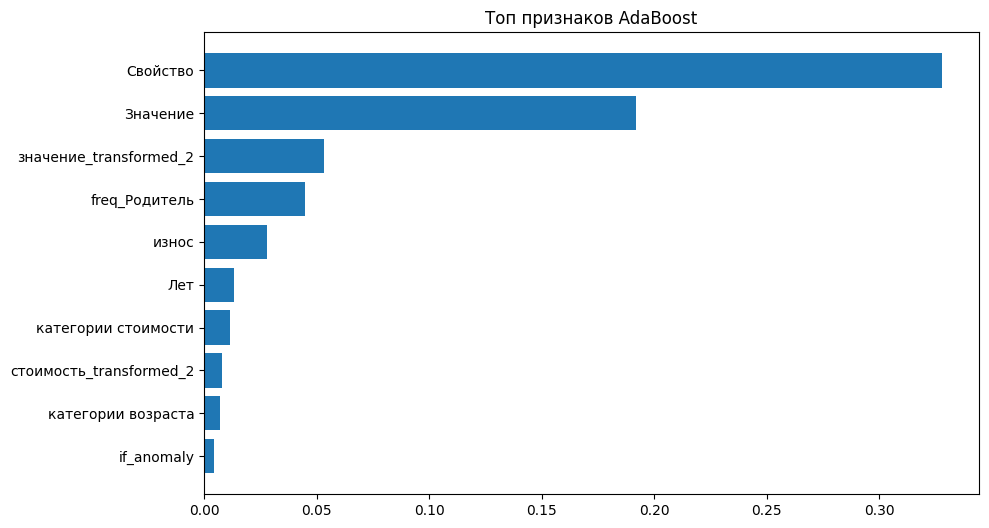

In [1546]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков AdaBoost")
plt.show()

### Keras (MLP)

In [1547]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [1548]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [1549]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
  acc=0.7895 | t=6.5s
keras+ros_shrinkage_005
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
  acc=0.7763 | t=6.2s
keras+ros_shrinkage_01
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
  acc=0.7737 | t=6.3s
keras+ros_shrinkage_02
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
  acc=0.7947 | t=5.9s
keras+gaussian_noise
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
  acc=0.7921 | t=6.3s

Лучшая балансировка: ros_shrinkage_02


In [1558]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(shrinkage=0.02, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=7, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 7 folds for each of 9 candidates, totalling 63 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [1559]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'relu', 'clf__model__optimizer': 'adam'}
Лучшая CV accuracy: 0.7443176745763923
Test accuracy: 0.7947368421052632
Время: 66.16304421424866


In [1573]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(shrinkage=0.2, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation=best_activation,
        model__optimizer=best_optimizer,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [128, 256, 512],
    "clf__model__learning_rate": [0.005, 0.01, 0.1],
    "clf__batch_size":           [128, 256, 512],
    "clf__epochs":               [100, 200, 300],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 3 folds for each of 81 candidates, totalling 243 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [128, 256, ...], 'clf__epochs': [100, 200, ...], 'clf__model__learning_rate': [0.005, 0.01, ...], 'clf__model__n_size': [128, 256, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [1574]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 256, 'clf__epochs': 300, 'clf__model__learning_rate': 0.01, 'clf__model__n_size': 128}
Лучшая CV accuracy: 0.7624313002036973
Test accuracy: 0.781578947368421
Время: 66.16304421424866


In [1575]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
15,Свойство,0.538596
11,freq_Свойство,0.107018
10,freq_Родитель,0.057018
16,категории стоимости,0.045614
6,стоимость_transformed_2,0.043860
7,значение_transformed_2,0.028947
13,Регион,0.021930
0,Лет,0.019298
1,Стоимость,0.018421
9,freq_Организация,0.016667


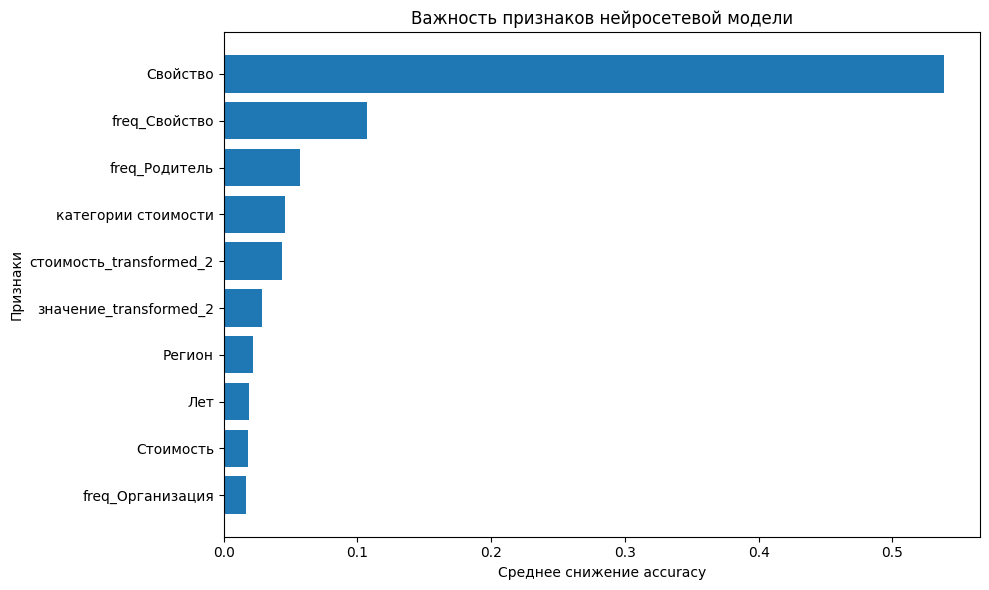

In [1576]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

## Подвыборка «шт»: редкие классы

In [100]:
target_col = "Наименование"

class_counts = processed[('шт', 'rare')]['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
processed[('шт', 'rare')]['Наименование'] = processed[('шт', 'rare')]['Наименование'].where(
    ~processed[('шт', 'rare')]['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(processed[('шт', 'rare')]['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 6
Объектов с меткой 'редкий': 6


In [101]:
X = processed[('шт', 'rare')].drop(columns=[target_col])
y = processed[('шт', 'rare')][target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.33,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (100, 17) y_train: (100,)
X_test: (50, 17) y_test: (50,)


In [102]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [103]:
X_test.columns

Index(['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация', 'freq_Родитель', 'freq_Свойство',
       'freq_Округ', 'Родитель', 'Свойство', 'категории стоимости',
       'категории возраста'],
      dtype='object')

In [104]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация', 'freq_Округ',
       'Родитель', 'Свойство', 'категории стоимости', 'категории возраста']

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация', 'freq_Округ']
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Родитель', 'Свойство']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [2137]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,svm,ros_shrinkage_005,0.46,0.004,0.008,0.002
2,svm,ros_shrinkage_01,0.46,0.002,0.006,0.002
0,svm,ros,0.44,0.002,0.007,0.001
3,svm,ros_shrinkage_02,0.44,0.003,0.007,0.002
4,svm,gaussian_noise,0.40,0.002,0.006,0.002


In [2138]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [2139]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'linear'}
Лучшая CV accuracy: 0.44
Время (сек): 0.13558220863342285
Test accuracy: 0.5


In [2140]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),  
    ('clf', SVC(
        kernel='rbf',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': np.arange(1, 55, 5),
    'clf__gamma': [1e-1, 1e-2, 1e-3],
    'clf__tol': [1e-1, 1e-2, 1e-3, 1e-4],          
    'clf__max_iter': np.arange(1, 55, 5),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 1452 candidates, totalling 4356 fits


















In [2141]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)
y_pred_test = grid_svm2.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_acc)
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': np.int64(51), 'clf__gamma': 0.001, 'clf__max_iter': np.int64(6), 'clf__tol': 0.1}
Лучшая CV accuracy: 0.5011883541295306
Test accuracy: 0.5
Время обучения (сек): 6.792696952819824


In [2142]:
pipe = grid_svm2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
})

feat_imp = feat_imp.sort_values(
    "importance",
    ascending=False
)

feat_imp.head(10)

,feature,importance
11,freq_Свойство,0.200000
14,Свойство,0.160000
7,значение_transformed_2,0.100000
2,Значение,0.060000
9,freq_Организация,0.060000
12,freq_Округ,0.033333
4,удельная стоимость,0.026667
10,freq_Родитель,0.026667
3,if_anomaly,0.020000
15,категории стоимости,0.020000


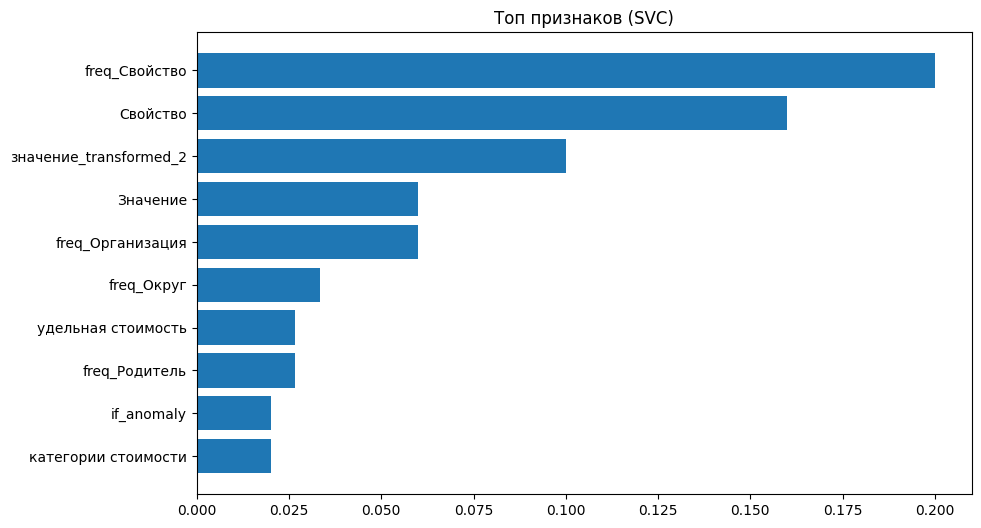

In [2143]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [1592]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,knn,gaussian_noise,0.36,0.002,0.000,0.001
0,knn,ros,0.32,0.001,0.002,0.010
1,knn,ros_shrinkage_005,0.30,0.002,0.000,0.001
2,knn,ros_shrinkage_01,0.30,0.002,0.000,0.002
3,knn,ros_shrinkage_02,0.30,0.003,0.000,0.002


In [1594]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [1595]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'uniform'}
Лучшая CV accuracy: 0.410873440285205
Test accuracy: 0.36
Время: 0.2632758617401123


In [1602]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='uniform',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(1, 11, 1),
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__leaf_size': np.arange(1, 11, 1)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 200 candidates, totalling 400 fits





In [1603]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(1), 'clf__metric': 'manhattan', 'clf__n_neighbors': np.int64(1)}
Лучшая CV accuracy: 0.41000000000000003
Test accuracy: 0.4
Время: 0.6056456565856934


In [1604]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
14,Свойство,1.133333e-01
11,freq_Свойство,7.333333e-02
5,износ,6.666667e-02
4,удельная стоимость,2.000000e-02
1,Стоимость,2.000000e-02
6,стоимость_transformed_2,2.000000e-02
7,значение_transformed_2,1.333333e-02
9,freq_Организация,1.850372e-17
2,Значение,0.000000e+00
0,Лет,-1.333333e-02


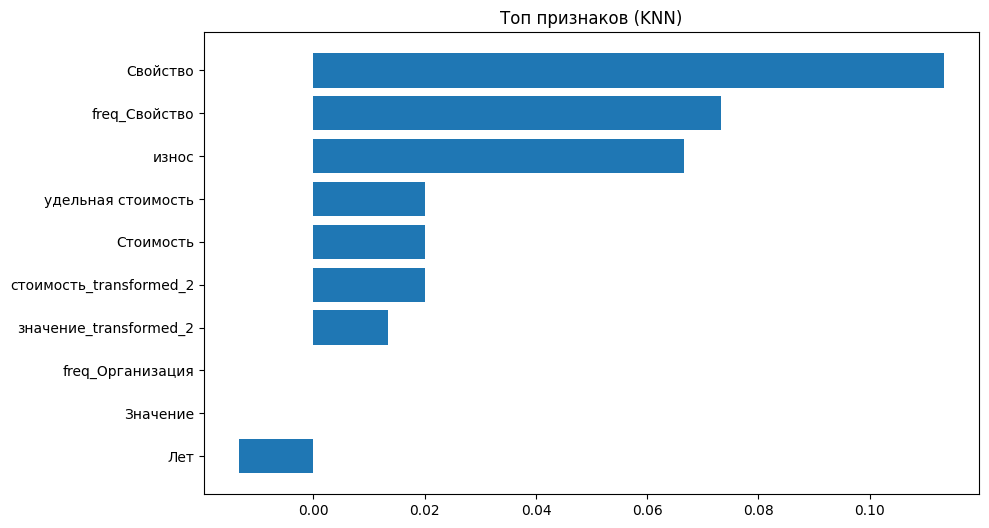

In [1609]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [1610]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,tree,ros_shrinkage_02,0.66,0.001,0.005,0.0
1,tree,ros_shrinkage_005,0.64,0.003,0.005,0.0
0,tree,ros,0.62,0.001,0.004,0.0
2,tree,ros_shrinkage_01,0.60,0.001,0.004,0.0
4,tree,gaussian_noise,0.60,0.001,0.005,0.0


In [1613]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 6 candidates, totalling 18 fits


In [1614]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.529708853238265
Test accuracy: 0.66
Время: 0.1755847930908203


In [1621]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='gini',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': np.arange(2, 22, 2),
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_split': np.arange(2, 11, 1),
    'clf__min_samples_leaf': np.arange(1, 11, 1)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 9000 candidates, totalling 18000 fits


... (вывод сокращён: 127 строк) ...













In [1622]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': np.int64(12), 'clf__max_features': np.float64(0.8), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.53
Test accuracy: 0.66
Время: 16.809925079345703


In [1623]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
16,cat__Свойство,0.356949
11,num__freq_Свойство,0.102802
2,num__Значение,0.087106
4,num__удельная стоимость,0.067613
0,num__Лет,0.063209
6,num__стоимость_transformed_2,0.051914
15,cat__Родитель,0.045202
10,num__freq_Родитель,0.042336
1,num__Стоимость,0.041705
13,ord__категории стоимости,0.040189


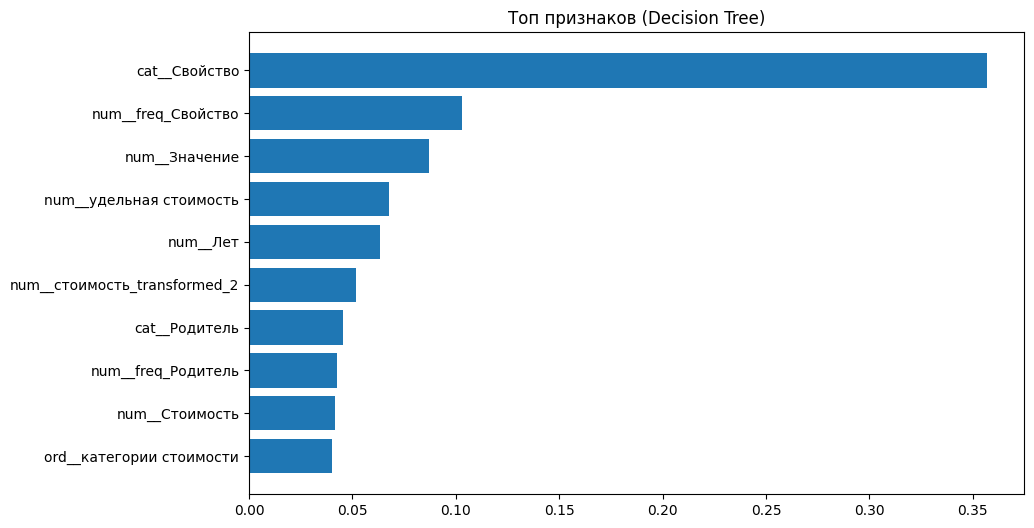

In [1624]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [105]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
2,rf,ros_shrinkage_01,0.68,0.001,0.059,0.014
3,rf,ros_shrinkage_02,0.68,0.001,0.061,0.012
4,rf,gaussian_noise,0.68,0.003,0.060,0.014
0,rf,ros,0.66,0.002,0.067,0.014
1,rf,ros_shrinkage_005,0.64,0.002,0.050,0.014


In [160]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 3 candidates, totalling 6 fits


In [161]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini'}
Лучшая CV accuracy: 0.54
Test accuracy: 0.68
Время: 0.20340800285339355


In [168]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': np.arange(50, 175, 25),
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__max_samples': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 9, 2),
    'clf__min_samples_leaf': np.arange(1, 8, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 2000 candidates, totalling 4000 fits











In [1651]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.4), 'clf__max_samples': np.float64(0.4), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4), 'clf__n_estimators': np.int64(200)}
Лучшая CV accuracy: 0.5900000000000001
Test accuracy: 0.72
Время: 211.54077100753784


In [1652]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
16,cat__Свойство,0.139099
11,num__freq_Свойство,0.138443
15,cat__Родитель,0.069937
2,num__Значение,0.069716
4,num__удельная стоимость,0.064768
1,num__Стоимость,0.063212
0,num__Лет,0.059629
6,num__стоимость_transformed_2,0.055150
7,num__значение_transformed_2,0.053340
12,num__freq_Округ,0.042767


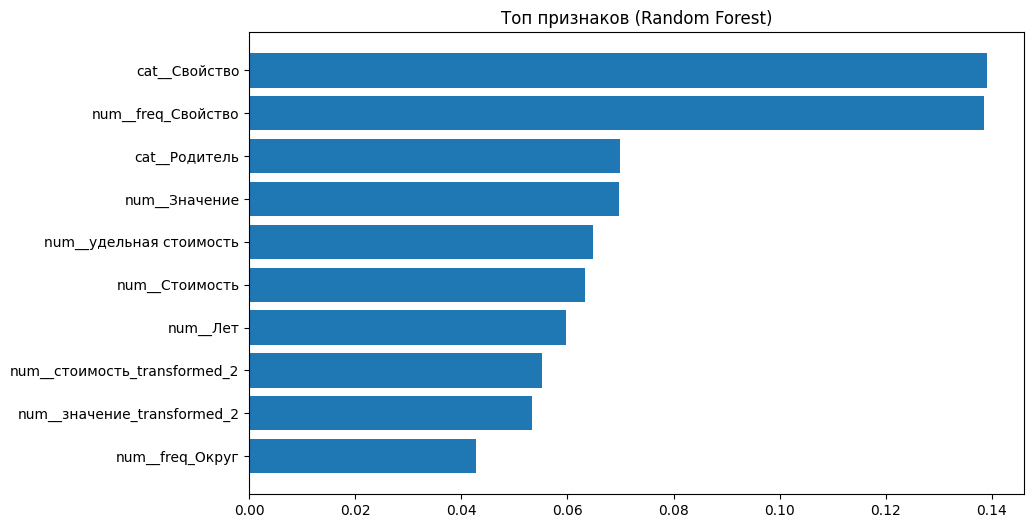

In [1653]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [1654]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rtf,ros,0.68,0.003,0.612,0.076
1,rtf,ros_shrinkage_005,0.66,0.002,1.367,0.069
2,rtf,ros_shrinkage_01,0.66,0.001,0.547,0.078
4,rtf,gaussian_noise,0.66,0.001,0.758,0.078
3,rtf,ros_shrinkage_02,0.64,0.001,0.651,0.096


In [1723]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best"],
    "model__pca_solver": ["auto", "full"],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [1724]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'gini', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'auto'}
Лучшая CV accuracy: 0.54
Test accuracy: 0.68
Время: 2.0958588123321533


In [1728]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              random_state=123),
        pca_solver='auto',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.2, 1.2, 0.2), 
    'model__base_estimator__min_samples_split': np.arange(2, 11, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 125 candidates, totalling 375 fits


In [1729]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(0.4), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.5998217468805703
Test accuracy: 0.68
Время: 37.68078589439392


In [1732]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              max_features=0.4,
                                              max_depth=None,
                                              min_samples_leaf=1,
                                              min_samples_split=2,
                                              random_state=123),
        pca_solver='auto',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": np.arange(50, 300, 50),
    "model__min_group": [1, 2, 3],
    "model__max_group": [1, 2, 3],
    "model__remove_proportion": np.arange(0.1, 1.0, 0.1),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 405 candidates, totalling 810 fits


In [1733]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 2, 'model__min_group': 2, 'model__n_estimators': np.int64(250), 'model__remove_proportion': np.float64(0.1)}
Лучшая CV accuracy: 0.5900000000000001
Test accuracy: 0.7
Время: 51.604265213012695


In [1734]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=6
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
14,Свойство,0.266667
11,freq_Свойство,0.146667
2,Значение,0.066667
15,категории стоимости,0.066667
1,Стоимость,0.053333
16,категории возраста,0.046667
9,freq_Организация,0.033333
0,Лет,0.033333
13,Родитель,0.026667
7,значение_transformed_2,0.020000


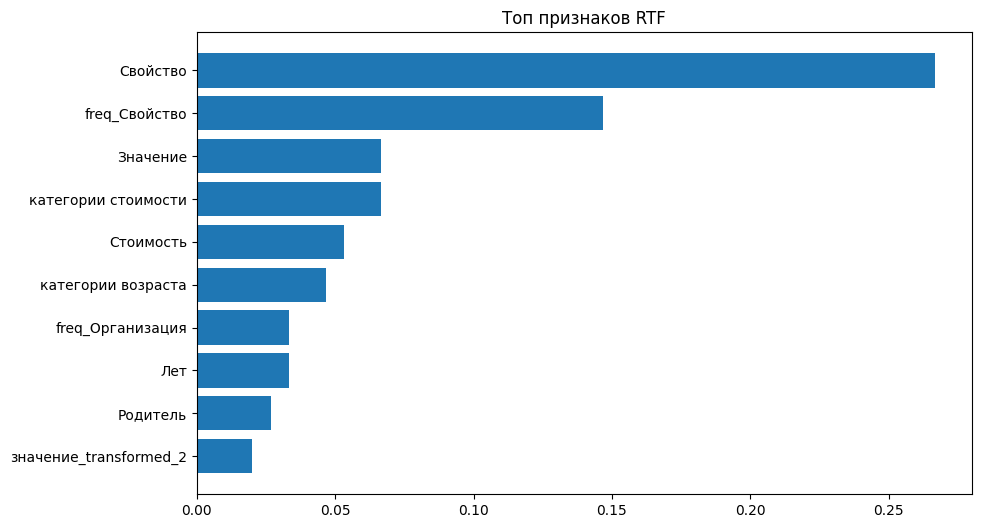

In [1735]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [1736]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,extra,ros_shrinkage_02,0.66,0.002,0.046,0.014
2,extra,ros_shrinkage_01,0.64,0.002,0.035,0.014
0,extra,ros,0.60,0.002,0.055,0.014
1,extra,ros_shrinkage_005,0.60,0.002,0.037,0.014
4,extra,gaussian_noise,0.60,0.001,0.048,0.014


In [1737]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.2)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [1738]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': False, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.58
Test accuracy: 0.66
Время: 5.937893867492676


In [1739]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.2)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=False,
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": np.arange(100, 400, 100),
    "model__max_depth": [None],
    'model__max_features': np.arange(0.2, 1.2, 0.2),
    'model__max_samples': [None],
    'model__min_samples_split': np.arange(2, 11, 2),
    'model__min_samples_leaf': np.arange(1, 10, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 375 candidates, totalling 750 fits




In [1740]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(0.6000000000000001), 'model__max_samples': None, 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(8), 'model__n_estimators': np.int64(100)}
Лучшая CV accuracy: 0.62
Test accuracy: 0.7
Время: 14.352654933929443


In [1741]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
16,cat__Свойство,0.195682
11,num__freq_Свойство,0.166610
2,num__Значение,0.067351
0,num__Лет,0.059769
15,cat__Родитель,0.058697
10,num__freq_Родитель,0.049260
13,ord__категории стоимости,0.046078
1,num__Стоимость,0.044280
14,ord__категории возраста,0.042781
8,num__freq_Регион,0.042608


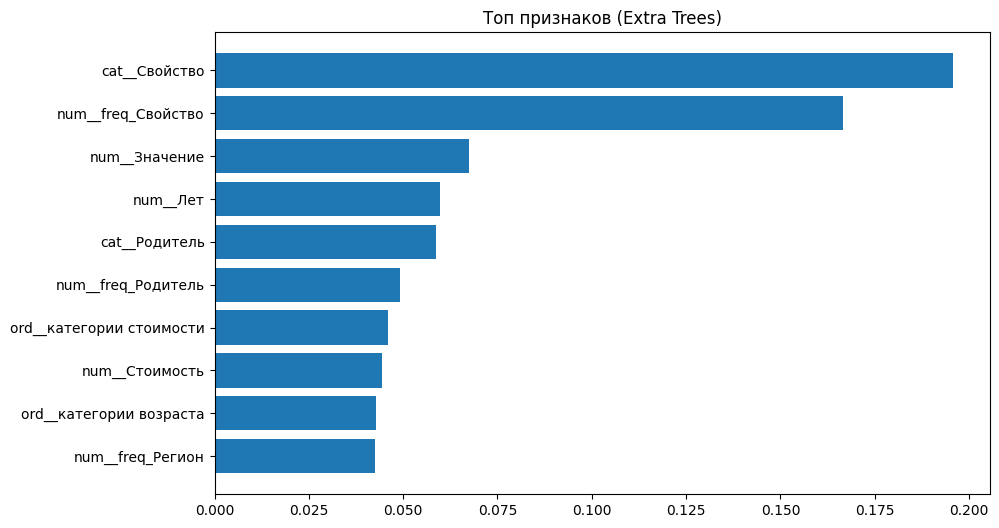

In [1742]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [1743]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,easy_ensemble,ros,0.66,0.002,0.817,0.013
3,easy_ensemble,ros_shrinkage_02,0.66,0.002,0.026,0.011
4,easy_ensemble,gaussian_noise,0.66,0.001,0.025,0.013
1,easy_ensemble,ros_shrinkage_005,0.62,0.002,0.034,0.012
2,easy_ensemble,ros_shrinkage_01,0.62,0.001,0.027,0.013


In [1748]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 12 candidates, totalling 36 fits


In [1749]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'gini', 'model__estimator__splitter': 'best', 'model__replacement': False}
Лучшая CV accuracy: 0.5707070707070706
Test accuracy: 0.66
Время: 3.978868007659912


In [1778]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='gini',
                                         splitter='best',
                                         random_state=123),
        replacement=False,
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": np.arange(100, 600, 100),
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.1, 1.1, 0.1),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 1250 candidates, totalling 3750 fits




In [1779]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(0.5), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(4), 'model__n_estimators': np.int64(400)}
Лучшая CV accuracy: 0.6007130124777184
Test accuracy: 0.64
Время: 258.7746820449829


In [1780]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
14,Свойство,0.220000
11,freq_Свойство,0.200000
2,Значение,0.106667
1,Стоимость,0.066667
0,Лет,0.020000
16,категории возраста,0.020000
5,износ,0.013333
4,удельная стоимость,0.013333
9,freq_Организация,0.006667
10,freq_Родитель,0.000000


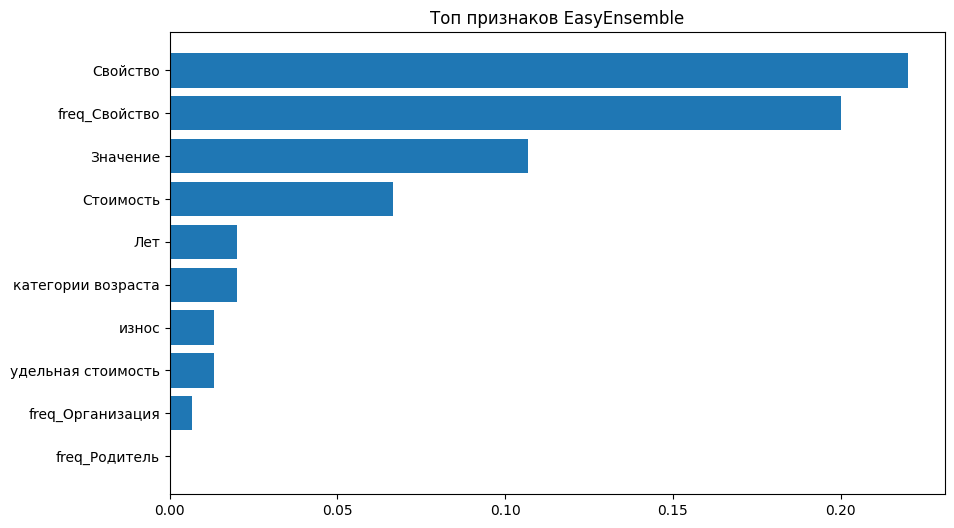

In [1781]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [1782]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,hgb,gaussian_noise,0.60,0.002,8.823,0.230
0,hgb,ros,0.56,0.002,8.330,0.192
3,hgb,ros_shrinkage_02,0.52,0.002,8.915,0.210
2,hgb,ros_shrinkage_01,0.50,0.002,8.630,0.234
1,hgb,ros_shrinkage_005,0.48,0.007,8.551,0.294


In [1805]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 3 candidates, totalling 30 fits


In [1806]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.35000000000000003
Test accuracy: 0.58
Время: 7.687666893005371


In [1839]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': [100, 200, 300],
    'clf__learning_rate': [0.01, 0.05],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}


grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 90 candidates, totalling 180 fits


In [1840]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.05, 'clf__max_depth': None, 'clf__max_features': np.float64(0.2), 'clf__max_iter': 100, 'clf__min_samples_leaf': np.int64(3)}
Лучшая CV accuracy: 0.5
Test accuracy: 0.56
Время: 51.04010605812073


In [1841]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
12,Свойство,0.140000
2,Значение,0.126667
4,удельная стоимость,0.033333
6,стоимость_transformed_2,0.020000
7,значение_transformed_2,0.020000
11,Родитель,0.020000
10,freq_Округ,0.013333
13,категории стоимости,0.006667
9,freq_Организация,0.000000
14,категории возраста,0.000000


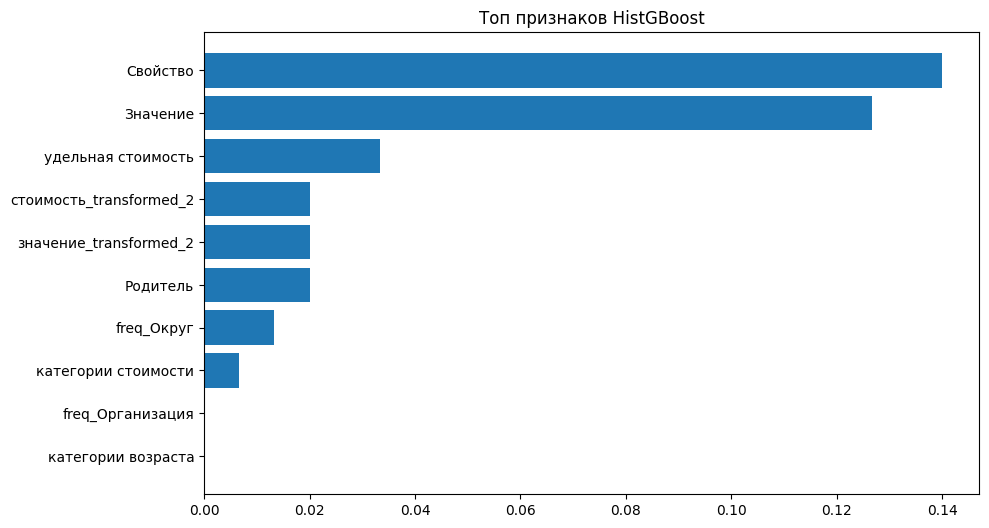

In [1842]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [1843]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
2,ada,ros_shrinkage_01,0.46,0.001,0.003,0.0
3,ada,ros_shrinkage_02,0.46,0.001,0.003,0.0
4,ada,gaussian_noise,0.46,0.001,0.004,0.0
0,ada,ros,0.44,0.002,0.002,0.0
1,ada,ros_shrinkage_005,0.36,0.002,0.003,0.0


In [1848]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.1, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best', 'random'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 6 candidates, totalling 18 fits


In [1849]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'gini', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.4090909090909091
Test accuracy: 0.46
Время: 0.17788124084472656


In [1858]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.1, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__estimator__min_samples_split': np.arange(2, 11, 2),
    'clf__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 250 candidates, totalling 1250 fits





In [1859]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(0.8), 'clf__estimator__min_samples_leaf': np.int64(5), 'clf__estimator__min_samples_split': np.int64(6)}
Лучшая CV accuracy: 0.55
Test accuracy: 0.54
Время: 18.782827138900757


In [1885]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.1, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            max_features=0.8,
            max_depth=None,
            min_samples_leaf=5,
            min_samples_split=6,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(100, 600, 100),
    'clf__learning_rate': [0.01, 0.1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 10 candidates, totalling 100 fits


In [1886]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.1, 'clf__n_estimators': np.int64(500)}
Лучшая CV accuracy: 0.48999999999999994
Test accuracy: 0.54
Время: 10.499465942382812


In [1887]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
14,cat__Свойство,0.204126
6,num__стоимость_transformed_2,0.113215
0,num__Лет,0.084501
2,num__Значение,0.074937
13,cat__Родитель,0.069393
4,num__удельная стоимость,0.060343
5,num__износ,0.058841
1,num__Стоимость,0.058652
9,num__freq_Организация,0.049769
8,num__freq_Регион,0.047931


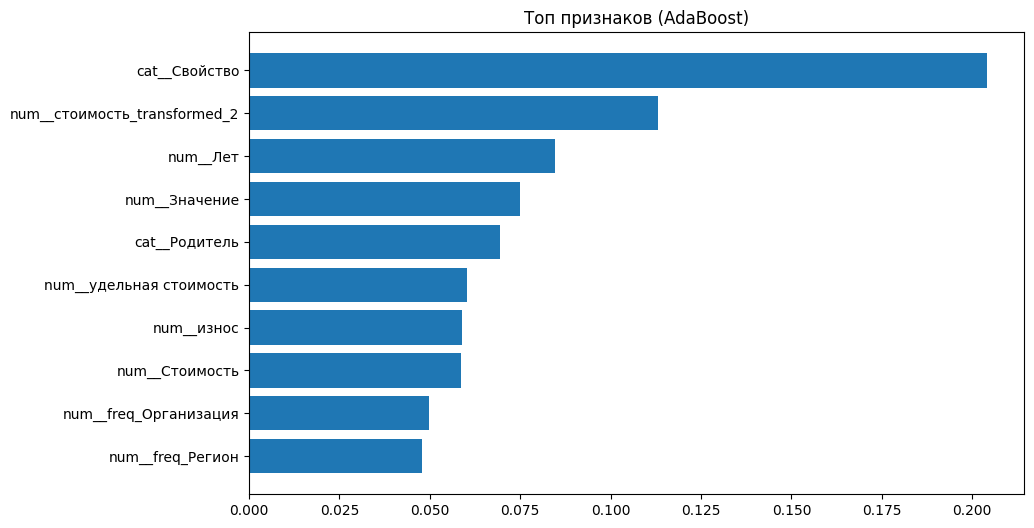

In [1888]:
top_n = 10
top_features = feat_imp_ada.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (AdaBoost)")
plt.show()

### Keras (MLP)

In [1889]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [1890]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [1891]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
  acc=0.5000 | t=2.5s
keras+ros_shrinkage_005
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
  acc=0.4600 | t=2.1s
keras+ros_shrinkage_01
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
  acc=0.5000 | t=1.9s
keras+ros_shrinkage_02
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
  acc=0.5000 | t=2.3s
keras+gaussian_noise
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
  acc=0.5000 | t=2.1s

Лучшая балансировка: ros


In [1892]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(shrinkage=0.1, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 2 folds for each of 9 candidates, totalling 18 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [1893]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'tanh', 'clf__model__optimizer': 'adam'}
Лучшая CV accuracy: 0.54
Test accuracy: 0.62
Время: 10.499465942382812


In [1910]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(shrinkage=0.1, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation=best_activation,
        model__optimizer=best_optimizer,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [32, 64, 128],
    "clf__model__learning_rate": [0.01, 0.1],
    "clf__batch_size":           [16, 32, 64],
    "clf__epochs":               [25, 50, 100],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 2 folds for each of 54 candidates, totalling 108 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [16, 32, ...], 'clf__epochs': [25, 50, ...], 'clf__model__learning_rate': [0.01, 0.1], 'clf__model__n_size': [32, 64, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [1911]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 16, 'clf__epochs': 25, 'clf__model__learning_rate': 0.01, 'clf__model__n_size': 64}
Лучшая CV accuracy: 0.55
Test accuracy: 0.64
Время: 10.499465942382812


In [1912]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
14,Свойство,0.413333
11,freq_Свойство,0.153333
2,Значение,0.113333
15,категории стоимости,0.086667
7,значение_transformed_2,0.073333
10,freq_Родитель,0.066667
5,износ,0.040000
1,Стоимость,0.040000
9,freq_Организация,0.033333
0,Лет,0.026667


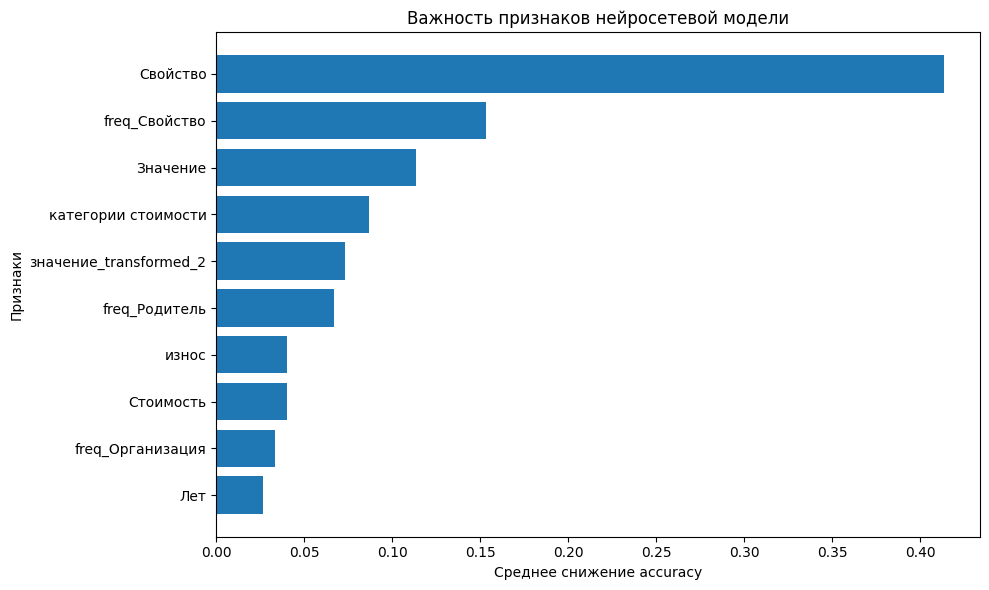

In [1913]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

## Подвыборка «прочие»: нормальные классы

In [487]:
target_col = "Наименование"

class_counts = processed[('прочие', 'normal')]['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
processed[('прочие', 'normal')]['Наименование'] = processed[('прочие', 'normal')]['Наименование'].where(
    ~processed[('прочие', 'normal')]['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(processed[('прочие', 'normal')]['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 0
Объектов с меткой 'редкий': 10


In [488]:
X = processed[('прочие', 'normal')].drop(columns=[target_col])
y = processed[('прочие', 'normal')][target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.3,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (1972, 16) y_train: (1972,)
X_test: (846, 16) y_test: (846,)


In [489]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [490]:
X_train.columns

Index(['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'значение_transformed_2', 'freq_Регион', 'freq_Организация',
       'freq_Родитель', 'freq_Свойство', 'freq_Округ', 'Родитель', 'Свойство',
       'категории стоимости', 'категории возраста'],
      dtype='object')

In [491]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'значение_transformed_2', 'freq_Регион', 'freq_Организация',
       'freq_Округ', 'Родитель', 'Свойство',
       'категории стоимости', 'категории возраста']

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'значение_transformed_2', 'freq_Регион', 'freq_Организация', 'freq_Округ']
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Родитель', 'Свойство']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [1918]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,svm,gaussian_noise,0.7813,0.333,2.399,0.659
3,svm,ros_shrinkage_02,0.7754,0.114,4.221,2.124
0,svm,ros,0.7683,0.047,3.086,1.388
1,svm,ros_shrinkage_005,0.7683,0.142,3.600,1.839
2,svm,ros_shrinkage_01,0.7671,0.124,4.005,1.890


In [1920]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [1921]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'linear'}
Лучшая CV accuracy: 0.7728194726166329
Время (сек): 11.526828050613403
Test accuracy: 0.7990543735224587


In [1928]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(
        kernel='linear',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': np.arange(1, 61, 10),
    'clf__tol': [1e-1, 1e-2, 1e-3],          
    'clf__max_iter': np.arange(1, 61, 10),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 108 candidates, totalling 324 fits


In [1929]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)
y_pred_test = grid_svm2.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_acc)
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': np.int64(21), 'clf__max_iter': np.int64(51), 'clf__tol': 0.01}
Лучшая CV accuracy: 0.7804232804232804
Test accuracy: 0.8049645390070922
Время обучения (сек): 44.51320219039917


In [1932]:
pipe = grid_svm2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

importances = np.abs(model.coef_).mean(axis=0)

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
10,num__freq_Свойство,0.243000
6,num__значение_transformed_2,0.158245
0,num__Лет,0.123882
215,cat__категории стоимости_очень низкая,0.101760
9,num__freq_Родитель,0.097202
213,cat__категории стоимости_низкая,0.088311
8,num__freq_Организация,0.083929
1,num__Стоимость,0.083531
200,cat__Свойство_производительность (объемная),0.081134
7,num__freq_Регион,0.074375


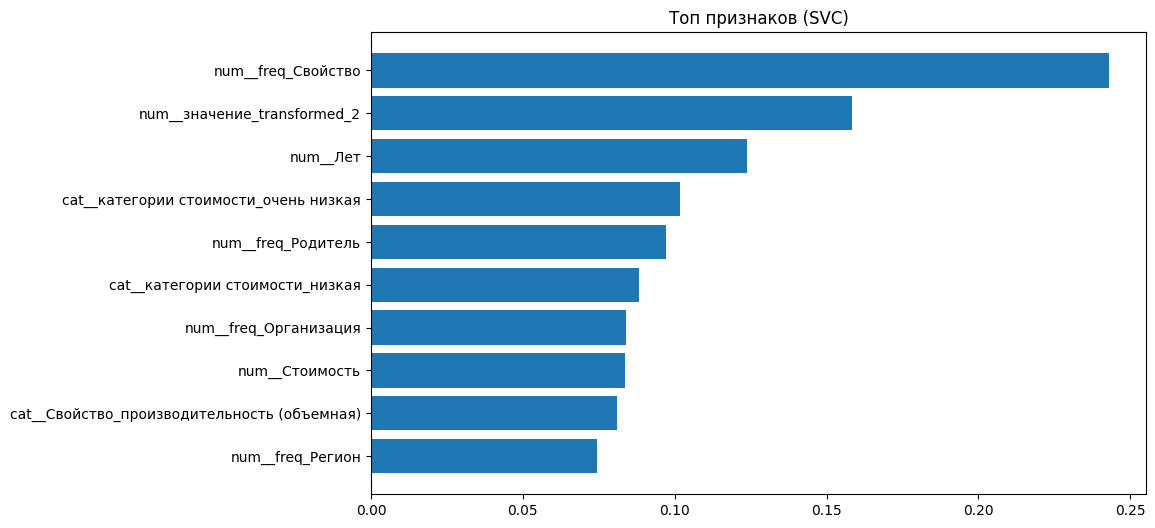

In [1933]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [1934]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,knn,gaussian_noise,0.7009,0.517,0.008,0.027
0,knn,ros,0.6998,0.026,0.009,0.044
1,knn,ros_shrinkage_005,0.6986,0.118,0.008,0.036
2,knn,ros_shrinkage_01,0.6974,0.104,0.003,0.030
3,knn,ros_shrinkage_02,0.6950,0.113,0.003,0.031


In [1937]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [1938]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'distance'}
Лучшая CV accuracy: 0.6790060851926978
Test accuracy: 0.7470449172576832
Время: 2.238042116165161


In [1946]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='distance',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(1, 31, 10),
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__leaf_size': np.arange(1, 31, 10)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 18 candidates, totalling 72 fits


In [1947]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(1), 'clf__metric': 'manhattan', 'clf__n_neighbors': np.int64(11)}
Лучшая CV accuracy: 0.7276876267748479
Test accuracy: 0.7505910165484634
Время: 14.454537868499756


In [1948]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
13,Свойство,0.219464
14,категории стоимости,0.112687
10,freq_Свойство,0.108353
6,значение_transformed_2,0.058708
1,Стоимость,0.029945
11,freq_Округ,0.019307
8,freq_Организация,0.018913
9,freq_Родитель,0.015366
15,категории возраста,0.013790
4,удельная стоимость,0.011820


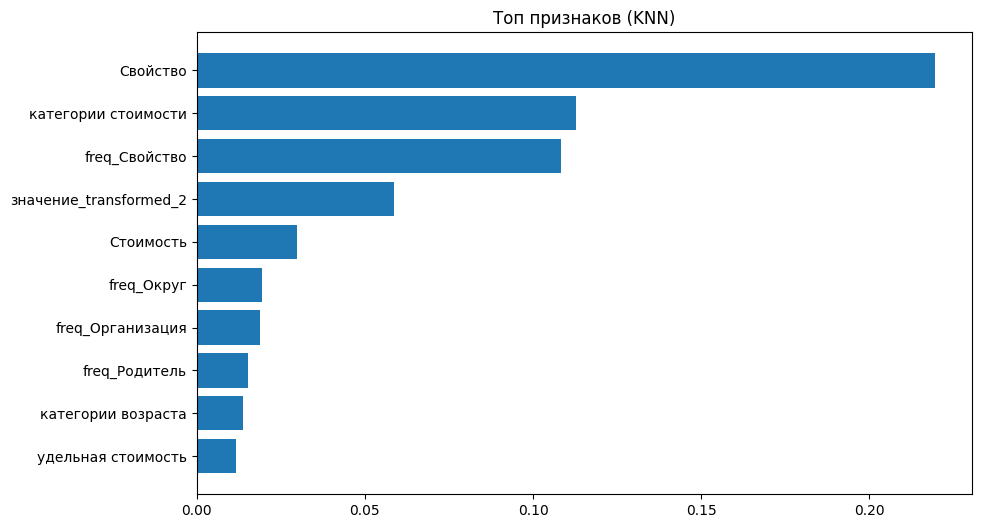

In [1949]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [1950]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,tree,ros,0.8310,0.006,0.104,0.000
3,tree,ros_shrinkage_02,0.8298,0.014,0.820,0.000
2,tree,ros_shrinkage_01,0.8251,0.011,0.926,0.000
4,tree,gaussian_noise,0.8215,0.019,1.058,0.001
1,tree,ros_shrinkage_005,0.8121,0.011,0.893,0.000


In [1951]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [1952]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.7961460446247464
Test accuracy: 0.8309692671394799
Время: 0.23023223876953125


In [1972]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='gini',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': np.arange(10, 101, 10),
    'clf__max_features': np.arange(0.1, 1.1, 0.1),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 2500 candidates, totalling 5000 fits














In [1973]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': np.int64(50), 'clf__max_features': np.float64(0.9), 'clf__min_samples_leaf': np.int64(3), 'clf__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.8017241379310345
Test accuracy: 0.8274231678486997
Время: 23.56042790412903


In [1974]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
10,num__freq_Свойство,0.150576
1,num__Стоимость,0.136568
4,num__удельная стоимость,0.101518
5,num__износ,0.101501
0,num__Лет,0.083642
15,cat__Свойство,0.082467
2,num__Значение,0.068822
14,cat__Родитель,0.063921
9,num__freq_Родитель,0.063517
6,num__значение_transformed_2,0.040388


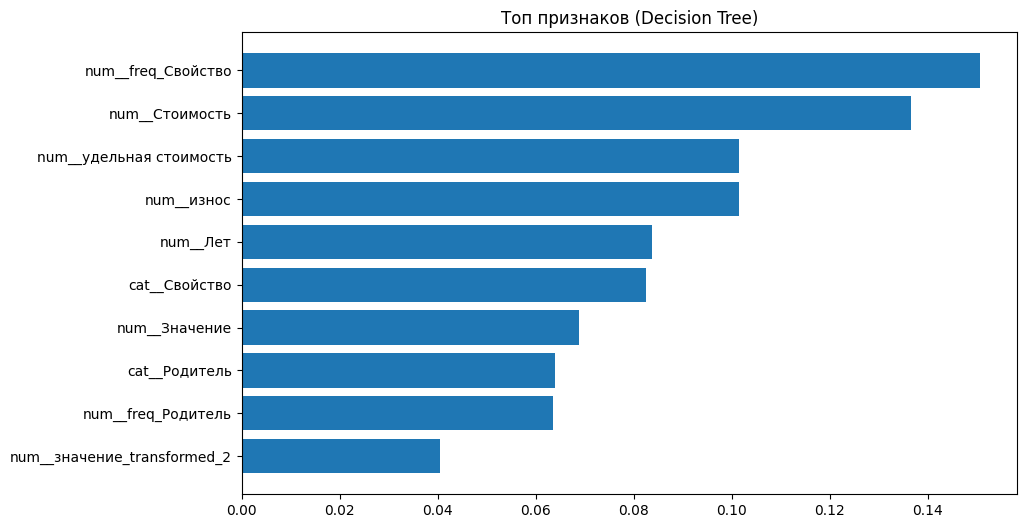

In [1975]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [492]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rf,ros,0.8605,0.005,0.250,0.017
1,rf,ros_shrinkage_005,0.8593,0.011,1.533,0.015
2,rf,ros_shrinkage_01,0.8534,0.010,1.440,0.014
3,rf,ros_shrinkage_02,0.8534,0.010,1.523,0.013
4,rf,gaussian_noise,0.8487,0.017,1.413,0.027


In [493]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 3 candidates, totalling 6 fits


In [494]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'entropy'}
Лучшая CV accuracy: 0.8356997971602435
Test accuracy: 0.8687943262411347
Время: 0.9967870712280273


In [495]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='entropy',
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': np.arange(50, 200, 25),
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__max_samples': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 3750 candidates, totalling 7500 fits





In [1986]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.4), 'clf__max_samples': np.float64(1.0), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4), 'clf__n_estimators': 150}
Лучшая CV accuracy: 0.8356997971602433
Test accuracy: 0.8676122931442081
Время: 390.80973196029663


In [1987]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
10,num__freq_Свойство,0.218647
15,cat__Свойство,0.199467
2,num__Значение,0.101187
4,num__удельная стоимость,0.093350
1,num__Стоимость,0.084805
5,num__износ,0.055423
6,num__значение_transformed_2,0.052130
0,num__Лет,0.040703
9,num__freq_Родитель,0.031816
12,ord__категории стоимости,0.027781


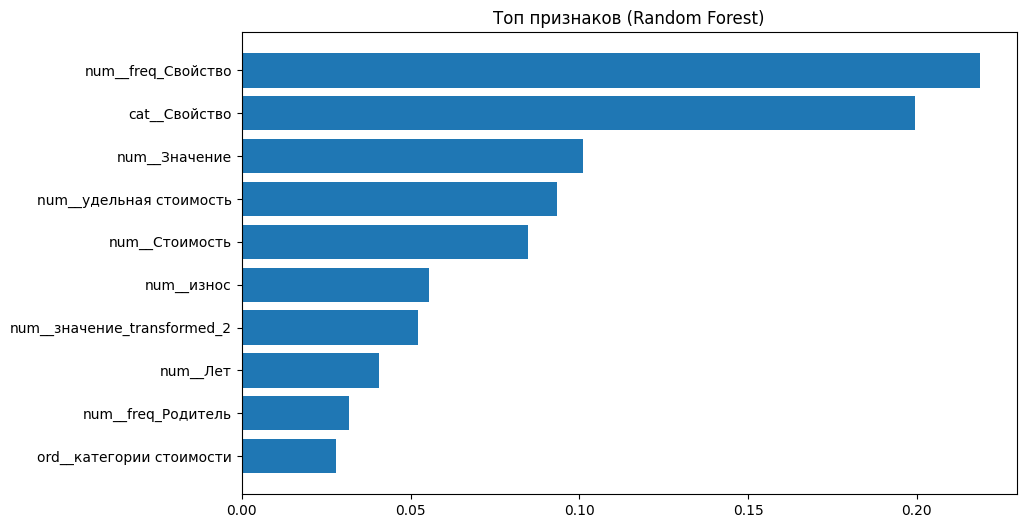

In [1988]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [1989]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rtf,ros,0.8605,0.007,8.564,0.196
1,rtf,ros_shrinkage_005,0.8522,0.025,31.417,0.166
4,rtf,gaussian_noise,0.8522,0.011,28.280,0.132
2,rtf,ros_shrinkage_01,0.8487,0.014,26.010,0.154
3,rtf,ros_shrinkage_02,0.8452,0.011,25.075,0.145


In [1996]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best"],
    "model__pca_solver": ["auto", "full"],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 6 candidates, totalling 18 fits


In [1997]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'entropy', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'full'}
Лучшая CV accuracy: 0.8362109246691002
Test accuracy: 0.8652482269503546
Время: 37.52967596054077


In [2000]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              random_state=123),
        pca_solver='full',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.2, 1.2, 0.2), 
    'model__base_estimator__min_samples_split': np.arange(2, 11, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 125 candidates, totalling 375 fits


In [2001]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(0.4), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(6)}
Лучшая CV accuracy: 0.8372217827187224
Test accuracy: 0.8617021276595744
Время: 607.6720631122589


In [2019]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              max_features=0.4,
                                              max_depth=None,
                                              min_samples_leaf=1,
                                              min_samples_split=6,
                                              random_state=123),
        pca_solver='full',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": [50, 100, 150],
    "model__min_group": [1, 2],
    "model__max_group": [1, 2, 3],
    "model__remove_proportion": np.arange(0.1, 1.0, 0.1),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 162 candidates, totalling 324 fits


In [2020]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 2, 'model__min_group': 2, 'model__n_estimators': 150, 'model__remove_proportion': np.float64(0.7000000000000001)}
Лучшая CV accuracy: 0.8301217038539555
Test accuracy: 0.8605200945626478
Время: 117.05777406692505


In [2021]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=6
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
10,freq_Свойство,0.291174
13,Свойство,0.243105
6,значение_transformed_2,0.022853
1,Стоимость,0.022853
4,удельная стоимость,0.016154
9,freq_Родитель,0.015760
11,freq_Округ,0.011820
7,freq_Регион,0.011032
0,Лет,0.009456
14,категории стоимости,0.009456


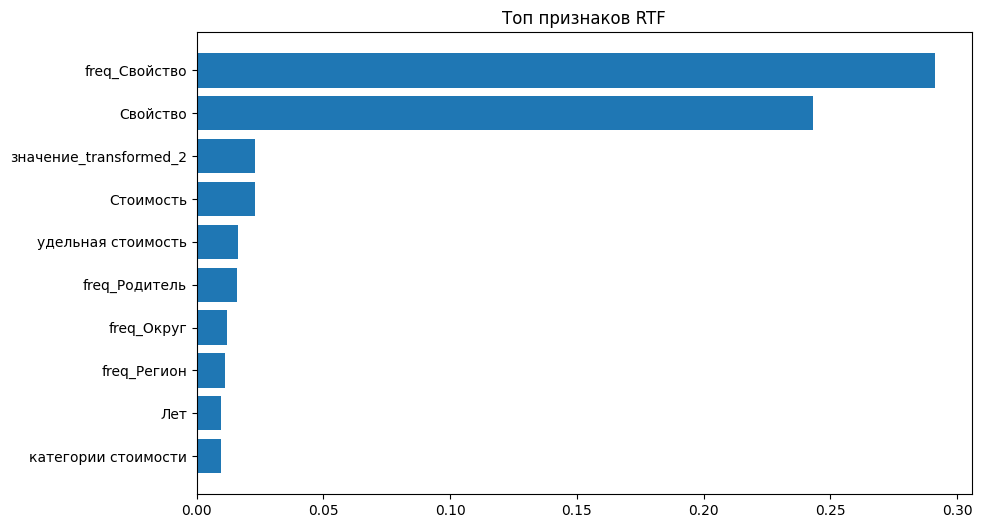

In [2022]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [2023]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,extra,gaussian_noise,0.8534,0.014,0.153,0.026
0,extra,ros,0.8475,0.006,0.172,0.013
1,extra,ros_shrinkage_005,0.8463,0.013,0.164,0.015
3,extra,ros_shrinkage_02,0.8452,0.012,0.200,0.015
2,extra,ros_shrinkage_01,0.8404,0.011,0.165,0.015


In [2024]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [2025]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': False, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.8240365111561866
Test accuracy: 0.8534278959810875
Время: 5.893648147583008


In [2027]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=False,
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": [100, 200, 300, 400, 500],
    "model__max_depth": [None],
    'model__max_features': np.arange(0.2, 1.2, 0.2),
    'model__max_samples': [None],
    'model__min_samples_split': np.arange(2, 11, 2),
    'model__min_samples_leaf': np.arange(1, 10, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 625 candidates, totalling 1250 fits


In [2028]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(0.8), 'model__max_samples': None, 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(4), 'model__n_estimators': 200}
Лучшая CV accuracy: 0.8286004056795132
Test accuracy: 0.8605200945626478
Время: 235.62244319915771


In [2029]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
15,cat__Свойство,0.128892
10,num__freq_Свойство,0.119783
12,ord__категории стоимости,0.098815
1,num__Стоимость,0.084358
0,num__Лет,0.070855
2,num__Значение,0.062295
13,ord__категории возраста,0.058119
4,num__удельная стоимость,0.053848
14,cat__Родитель,0.053696
6,num__значение_transformed_2,0.053394


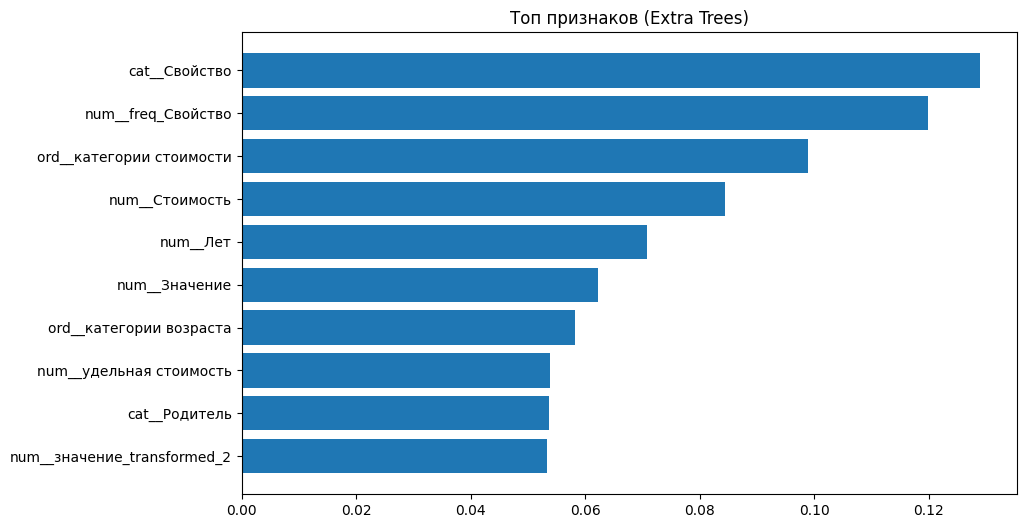

In [2030]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [2031]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,easy_ensemble,ros,0.8310,0.005,1.286,0.035
3,easy_ensemble,ros_shrinkage_02,0.8298,0.012,1.247,0.155
4,easy_ensemble,gaussian_noise,0.8298,0.015,1.691,0.026
2,easy_ensemble,ros_shrinkage_01,0.8180,0.012,1.355,0.039
1,easy_ensemble,ros_shrinkage_005,0.8168,0.012,1.429,0.036


In [2041]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 12 candidates, totalling 36 fits


In [2042]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'entropy', 'model__estimator__splitter': 'random', 'model__replacement': True}
Лучшая CV accuracy: 0.8331667846386588
Test accuracy: 0.8475177304964538
Время: 4.5395729541778564


In [2043]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='entropy',
                                         splitter='random',
                                         random_state=123),
        replacement=True,
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": np.arange(50, 300, 50),
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.2, 1.2, 0.2),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 625 candidates, totalling 1250 fits


In [2044]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(0.4), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(4), 'model__n_estimators': np.int64(200)}
Лучшая CV accuracy: 0.8250507099391481
Test accuracy: 0.8534278959810875
Время: 269.43275022506714


In [2045]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
10,freq_Свойство,0.404649
13,Свойство,0.174547
14,категории стоимости,0.111899
6,значение_transformed_2,0.016942
4,удельная стоимость,0.009850
2,Значение,0.009062
1,Стоимость,0.009062
8,freq_Организация,0.006304
9,freq_Родитель,0.003940
15,категории возраста,0.003546


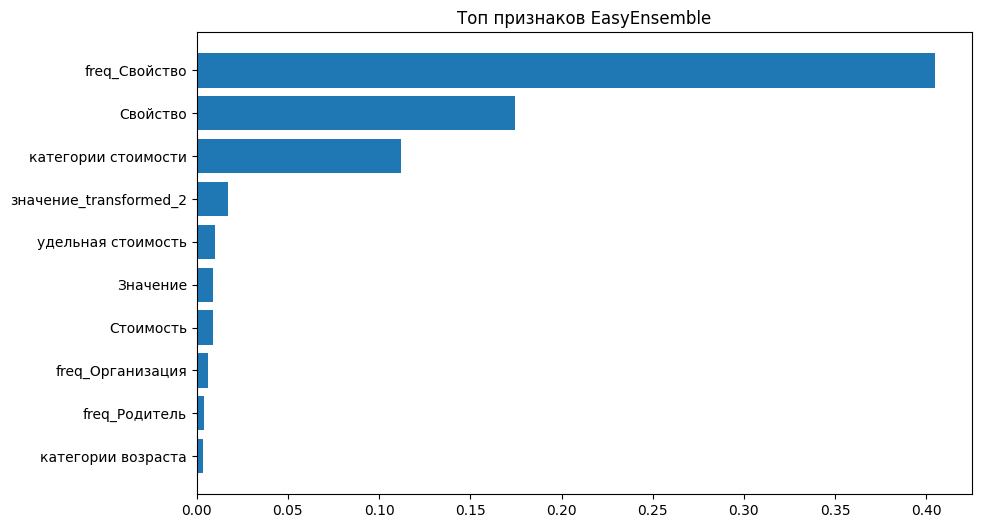

In [2046]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [2047]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,hgb,ros,0.6489,0.008,1.838,0.012
1,hgb,ros_shrinkage_005,0.6430,0.013,2.176,0.019
3,hgb,ros_shrinkage_02,0.6430,0.013,1.902,0.012
2,hgb,ros_shrinkage_01,0.6253,0.012,2.533,0.016
4,hgb,gaussian_noise,0.5875,0.037,2.219,0.015


In [2048]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 3 candidates, totalling 6 fits


In [2049]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.6460446247464503
Test accuracy: 0.6595744680851063
Время: 3.6782760620117188


In [2051]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': [100, 200, 300],
    'clf__learning_rate': [0.05, 0.1],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}

grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 90 candidates, totalling 180 fits


In [2052]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.05, 'clf__max_depth': None, 'clf__max_features': np.float64(0.4), 'clf__max_iter': 300, 'clf__min_samples_leaf': np.int64(5)}
Лучшая CV accuracy: 0.7616632860040569
Test accuracy: 0.7754137115839244
Время: 168.3277838230133


In [2053]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,Свойство,0.372340
4,удельная стоимость,0.214736
2,Значение,0.099291
1,Стоимость,0.095745
6,значение_transformed_2,0.044129
7,freq_Регион,0.028369
5,износ,0.022065
0,Лет,0.017730
8,freq_Организация,0.011820
12,категории стоимости,0.009456


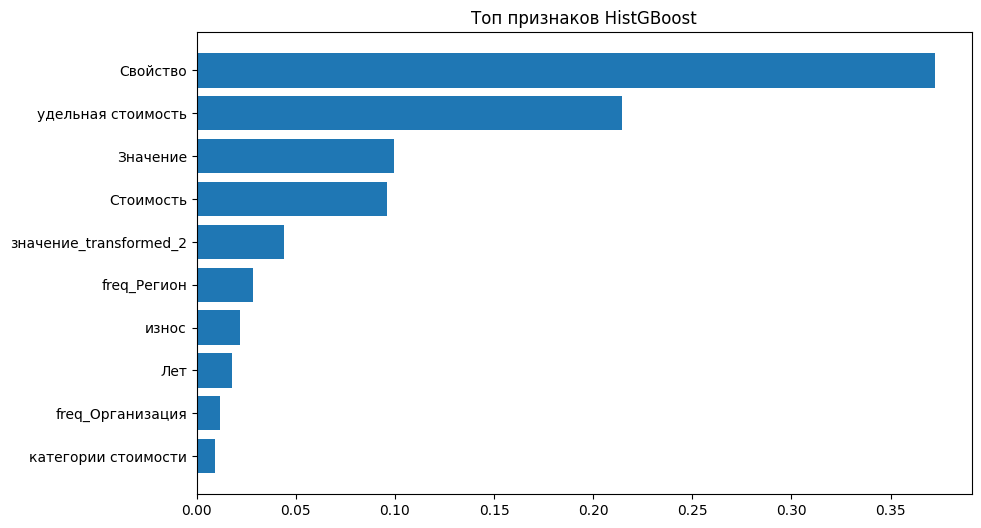

In [2054]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [2055]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,ada,ros_shrinkage_005,0.7411,0.014,0.818,0.001
4,ada,gaussian_noise,0.7388,0.016,0.932,0.001
3,ada,ros_shrinkage_02,0.7329,0.011,0.859,0.001
0,ada,ros,0.7246,0.006,0.097,0.001
2,ada,ros_shrinkage_01,0.7045,0.012,0.846,0.001


In [2076]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=6, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 6 folds for each of 3 candidates, totalling 18 fits


In [2077]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'gini', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.7312316208268466
Test accuracy: 0.7458628841607565
Время: 2.6938250064849854


In [2078]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__estimator__min_samples_split': np.arange(2, 11, 2),
    'clf__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 125 candidates, totalling 250 fits


In [2079]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(1.0), 'clf__estimator__min_samples_leaf': np.int64(3), 'clf__estimator__min_samples_split': np.int64(4)}
Лучшая CV accuracy: 0.7849898580121704
Test accuracy: 0.8037825059101655
Время: 333.8120217323303


In [2085]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            max_features=1.0,
            max_depth=None,
            min_samples_leaf=3,
            min_samples_split=4,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(100, 400, 100),
    'clf__learning_rate': [0.05, 0.1, 0.5]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 9 candidates, totalling 18 fits


In [2086]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.5, 'clf__n_estimators': np.int64(300)}
Лучшая CV accuracy: 0.7778904665314401
Test accuracy: 0.8085106382978723
Время: 419.8553218841553


In [2087]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
13,cat__Свойство,0.139368
12,cat__Родитель,0.138267
6,num__значение_transformed_2,0.109634
2,num__Значение,0.092088
4,num__удельная стоимость,0.083012
10,ord__категории стоимости,0.079092
11,ord__категории возраста,0.058092
7,num__freq_Регион,0.057352
1,num__Стоимость,0.052043
9,num__freq_Округ,0.048593


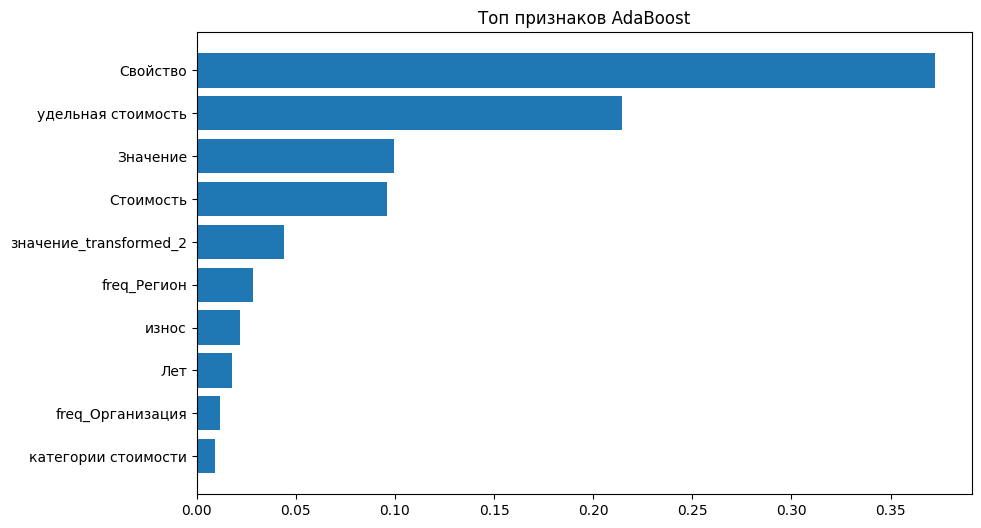

In [2088]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков AdaBoost")
plt.show()

### Keras (MLP)

In [2089]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [2090]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [2091]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
  acc=0.7967 | t=20.3s
keras+ros_shrinkage_005
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
  acc=0.8002 | t=20.3s
keras+ros_shrinkage_01
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
  acc=0.7730 | t=18.9s
keras+ros_shrinkage_02
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 998us/step
  acc=0.7837 | t=18.4s
keras+gaussian_noise
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
  acc=0.7825 | t=18.2s

Лучшая балансировка: ros_shrinkage_005


In [2106]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 2 folds for each of 9 candidates, totalling 18 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [2107]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'tanh', 'clf__model__optimizer': 'rmsprop'}
Лучшая CV accuracy: 0.7712981744421907
Test accuracy: 0.7884160756501182
Время: 419.8553218841553


In [2108]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation=best_activation,
        model__optimizer=best_optimizer,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [32, 64, 128],
    "clf__model__learning_rate": [0.01, 0.1],
    "clf__batch_size":           [16, 32, 64],
    "clf__epochs":               [25, 50, 100],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 2 folds for each of 54 candidates, totalling 108 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [16, 32, ...], 'clf__epochs': [25, 50, ...], 'clf__model__learning_rate': [0.01, 0.1], 'clf__model__n_size': [32, 64, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [2109]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 32, 'clf__epochs': 100, 'clf__model__learning_rate': 0.01, 'clf__model__n_size': 128}
Лучшая CV accuracy: 0.7778904665314401
Test accuracy: 0.8120567375886525
Время: 419.8553218841553


In [2110]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
13,Свойство,0.604807
14,категории стоимости,0.112687
6,значение_transformed_2,0.094563
10,freq_Свойство,0.088652
1,Стоимость,0.080772
12,Родитель,0.068164
0,Лет,0.028763
5,износ,0.019701
15,категории возраста,0.016548
9,freq_Родитель,0.013002


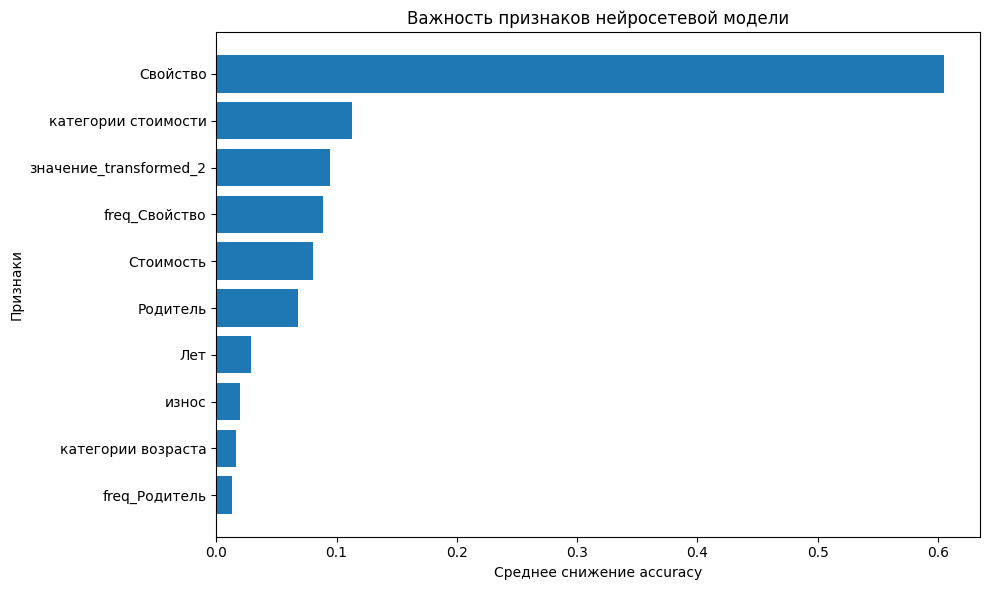

In [2111]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

## Подвыборка «прочие»: редкие классы

In [282]:
target_col = "Наименование"

class_counts = processed[('прочие', 'rare')]['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
processed[('прочие', 'rare')]['Наименование'] = processed[('прочие', 'rare')]['Наименование'].where(
    ~processed[('прочие', 'rare')]['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(processed[('прочие', 'rare')]['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 0
Объектов с меткой 'редкий': 31


In [283]:
X = processed[('прочие', 'rare')].drop(columns=[target_col])
y = processed[('прочие', 'rare')][target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.33,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (191, 17) y_train: (191,)
X_test: (95, 17) y_test: (95,)


In [284]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [285]:
X_train.columns

Index(['Лет', 'Стоимость', 'if_anomaly', 'удельная стоимость',
       'стоимость_transformed_2', 'значение_transformed_2', 'freq_Регион',
       'freq_Организация', 'freq_Родитель', 'freq_Свойство', 'freq_ед. изм.',
       'freq_Округ', 'Организация', 'Свойство', 'Округ', 'категории стоимости',
       'категории возраста'],
      dtype='object')

In [286]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = ['Лет', 'Стоимость', 'if_anomaly', 'удельная стоимость',
       'стоимость_transformed_2', 'значение_transformed_2', 'freq_Регион',
       'freq_Родитель', 'freq_ед. изм.',
       'Организация', 'Свойство', 'Округ', 'категории стоимости',
       'категории возраста']

num_cols_boost      = ['Лет', 'Стоимость', 'if_anomaly', 'удельная стоимость',
       'стоимость_transformed_2', 'значение_transformed_2', 'freq_Регион',
       'freq_Родитель', 'freq_ед. изм.']
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Организация', 'Свойство', 'Округ']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [2121]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,svm,ros,0.4211,0.004,0.024,0.006
3,svm,ros_shrinkage_02,0.4000,0.003,0.022,0.006
1,svm,ros_shrinkage_005,0.3789,0.005,0.021,0.007
2,svm,ros_shrinkage_01,0.3789,0.004,0.022,0.006
4,svm,gaussian_noise,0.3474,0.003,0.017,0.005


In [2122]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [2123]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'linear'}
Лучшая CV accuracy: 0.4921600877192982
Время (сек): 0.19841718673706055
Test accuracy: 0.5157894736842106


In [2126]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123)),  
    ('clf', SVC(
        kernel='linear',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': np.arange(1, 55, 5),
    'clf__tol': [1e-1, 1e-2, 1e-3, 1e-4],          
    'clf__max_iter': np.arange(1, 55, 5),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 484 candidates, totalling 1452 fits










In [2127]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)
y_pred_test = grid_svm2.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_acc)
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': np.int64(6), 'clf__max_iter': np.int64(16), 'clf__tol': 0.01}
Лучшая CV accuracy: 0.5286871693121693
Test accuracy: 0.5157894736842106
Время обучения (сек): 2.5347819328308105


In [2130]:
pipe = grid_svm2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

importances = np.abs(model.coef_).mean(axis=0)

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
10,num__freq_ед. изм.,0.143096
9,num__freq_Свойство,0.131576
5,num__значение_transformed_2,0.125089
0,num__Лет,0.111324
8,num__freq_Родитель,0.103059
4,num__стоимость_transformed_2,0.086674
6,num__freq_Регион,0.077551
11,num__freq_Округ,0.071368
57,cat__категории стоимости_низкая,0.066014
7,num__freq_Организация,0.063342


### KNN

In [2148]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,knn,ros,0.3684,0.003,0.001,0.007
4,knn,gaussian_noise,0.3368,0.003,0.000,0.001
3,knn,ros_shrinkage_02,0.3158,0.003,0.000,0.001
1,knn,ros_shrinkage_005,0.3053,0.004,0.000,0.001
2,knn,ros_shrinkage_01,0.3053,0.004,0.000,0.001


In [2149]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [2150]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'uniform'}
Лучшая CV accuracy: 0.35590277777777773
Test accuracy: 0.3684210526315789
Время: 0.22805118560791016


In [2151]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='uniform',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(1, 11, 1),
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__leaf_size': np.arange(1, 11, 1)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 200 candidates, totalling 400 fits



In [2152]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(1), 'clf__metric': 'manhattan', 'clf__n_neighbors': np.int64(1)}
Лучшая CV accuracy: 0.39786184210526315
Test accuracy: 0.37894736842105264
Время: 0.676419734954834


In [2153]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
13,Свойство,0.122807
5,значение_transformed_2,0.073684
15,категории стоимости,0.052632
10,freq_ед. изм.,0.052632
4,стоимость_transformed_2,0.042105
9,freq_Свойство,0.035088
8,freq_Родитель,0.031579
0,Лет,0.024561
2,if_anomaly,0.021053
16,категории возраста,0.017544


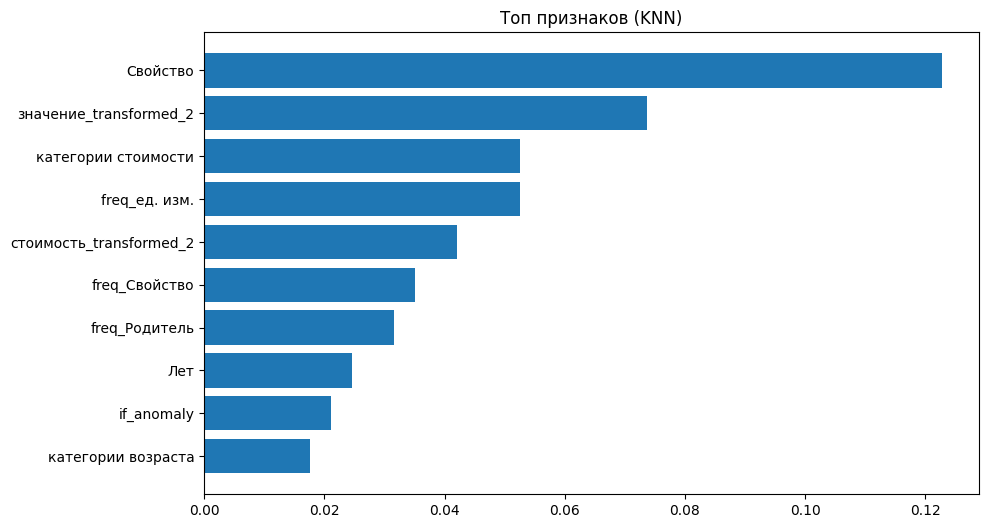

In [2154]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [2155]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,tree,ros,0.6000,0.006,0.004,0.0
2,tree,ros_shrinkage_01,0.5368,0.003,0.010,0.0
1,tree,ros_shrinkage_005,0.5053,0.003,0.012,0.0
4,tree,gaussian_noise,0.5053,0.002,0.014,0.0
3,tree,ros_shrinkage_02,0.4842,0.002,0.012,0.0


In [2162]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 3 candidates, totalling 9 fits


In [2163]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.5180224867724867
Test accuracy: 0.6
Время: 0.0964820384979248


In [2216]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='gini',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': np.arange(5, 31, 5),
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=6, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 6 folds for each of 750 candidates, totalling 4500 fits


... (вывод сокращён: 12 строк) ...













In [2217]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': np.int64(20), 'clf__max_features': np.float64(0.6000000000000001), 'clf__min_samples_leaf': np.int64(3), 'clf__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.5599798387096774
Test accuracy: 0.5894736842105263
Время: 5.270567178726196


In [2218]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
3,num__удельная стоимость,0.157671
9,num__freq_Свойство,0.114555
10,num__freq_ед. изм.,0.107937
0,num__Лет,0.097189
15,cat__Свойство,0.087632
1,num__Стоимость,0.086107
5,num__значение_transformed_2,0.063017
13,ord__категории возраста,0.051074
7,num__freq_Организация,0.045504
12,ord__категории стоимости,0.038749


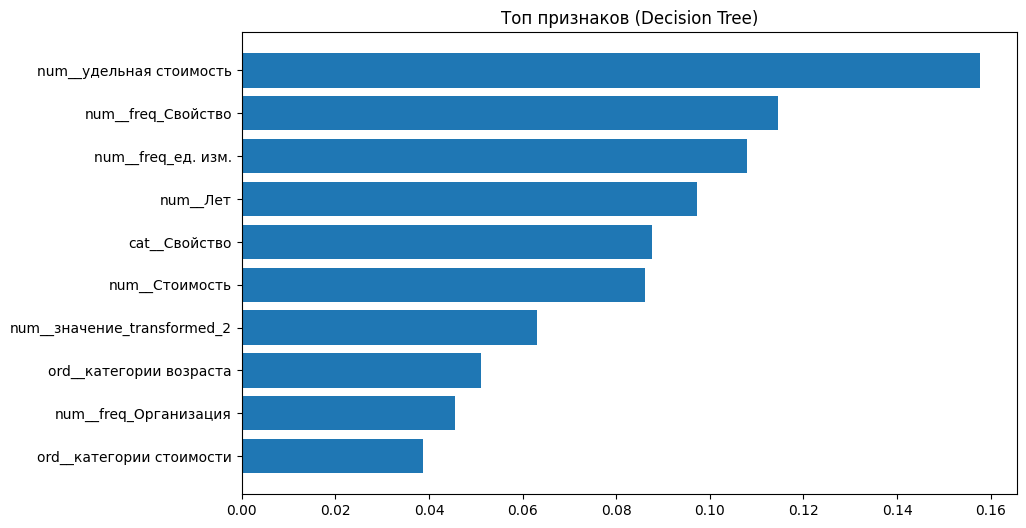

In [2219]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [2220]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
2,rf,ros_shrinkage_01,0.6000,0.003,0.073,0.015
3,rf,ros_shrinkage_02,0.6000,0.003,0.071,0.014
0,rf,ros,0.5895,0.004,0.103,0.014
1,rf,ros_shrinkage_005,0.5895,0.003,0.103,0.015
4,rf,gaussian_noise,0.5579,0.002,0.083,0.014


In [2221]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.1, random_state=123)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 3 candidates, totalling 6 fits


In [2222]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini'}
Лучшая CV accuracy: 0.6177083333333333
Test accuracy: 0.6
Время: 0.4022977352142334


In [2223]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(shrinkage=0.1, random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': np.arange(100, 400, 100),
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__max_samples': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1875 candidates, totalling 3750 fits



In [2224]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.4), 'clf__max_samples': np.float64(0.6000000000000001), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(2), 'clf__n_estimators': np.int64(100)}
Лучшая CV accuracy: 0.6333881578947369
Test accuracy: 0.6
Время: 144.65368795394897


In [2225]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
15,cat__Свойство,0.116191
3,num__удельная стоимость,0.112447
9,num__freq_Свойство,0.086166
5,num__значение_transformed_2,0.085487
1,num__Стоимость,0.083119
0,num__Лет,0.072898
10,num__freq_ед. изм.,0.066205
4,num__стоимость_transformed_2,0.064937
12,ord__категории стоимости,0.051892
7,num__freq_Организация,0.046954


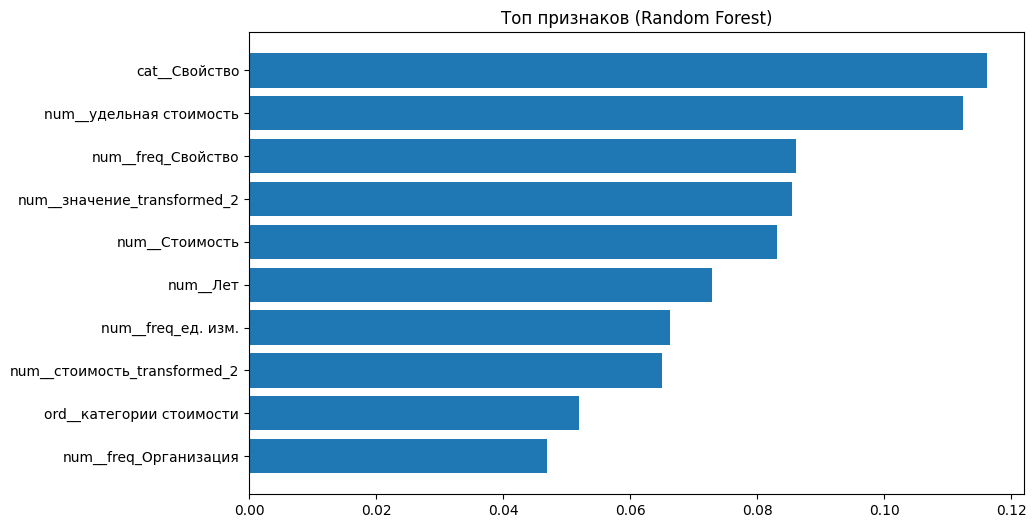

In [2226]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [229]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rtf,ros,0.6211,0.003,0.767,0.078
2,rtf,ros_shrinkage_01,0.5789,0.002,0.890,0.077
4,rtf,gaussian_noise,0.5789,0.001,1.122,0.080
1,rtf,ros_shrinkage_005,0.5579,0.002,0.899,0.081
3,rtf,ros_shrinkage_02,0.5579,0.003,0.866,0.079


In [238]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best", 'random'],
    "model__pca_solver": ["auto", "full", 'randomized'],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=7, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 7 folds for each of 18 candidates, totalling 126 fits


In [239]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'gini', 'model__base_estimator__splitter': 'random', 'model__pca_solver': 'randomized'}
Лучшая CV accuracy: 0.6328420256991685
Test accuracy: 0.5789473684210527
Время: 23.84622311592102


In [2239]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'entropy', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'full'}
Лучшая CV accuracy: 0.5966557017543859
Test accuracy: 0.6
Время: 2.5925281047821045


In [244]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='random',
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.25, 1.25, 0.25), 
    'model__base_estimator__min_samples_split': np.arange(2, 9, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 8, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=7, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 7 folds for each of 64 candidates, totalling 448 fits


In [245]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(1.0), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.6328420256991685
Test accuracy: 0.5789473684210527
Время: 81.78512406349182


In [2247]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(0.4), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(8)}
Лучшая CV accuracy: 0.6545209176788124
Test accuracy: 0.6210526315789474
Время: 117.22453808784485


In [251]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='random',
                                              max_features=1.0,
                                              max_depth=None,
                                              min_samples_leaf=1,
                                              min_samples_split=2,
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": np.arange(200, 350, 50),
    "model__min_group": [1, 2, 3],
    "model__max_group": [1, 2, 3],
    "model__remove_proportion": np.arange(0.1, 1.1, 0.1),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=7, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 7 folds for each of 270 candidates, totalling 1890 fits




In [2249]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 2, 'model__min_group': 1, 'model__n_estimators': np.int64(200), 'model__remove_proportion': np.float64(0.8)}
Лучшая CV accuracy: 0.6228618421052632
Test accuracy: 0.631578947368421
Время: 79.33830308914185


In [2250]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=6
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
9,freq_Свойство,0.119298
13,Свойство,0.108772
10,freq_ед. изм.,0.045614
3,удельная стоимость,0.035088
7,freq_Организация,0.028070
4,стоимость_transformed_2,0.014035
0,Лет,0.014035
11,freq_Округ,0.010526
6,freq_Регион,0.010526
1,Стоимость,0.007018


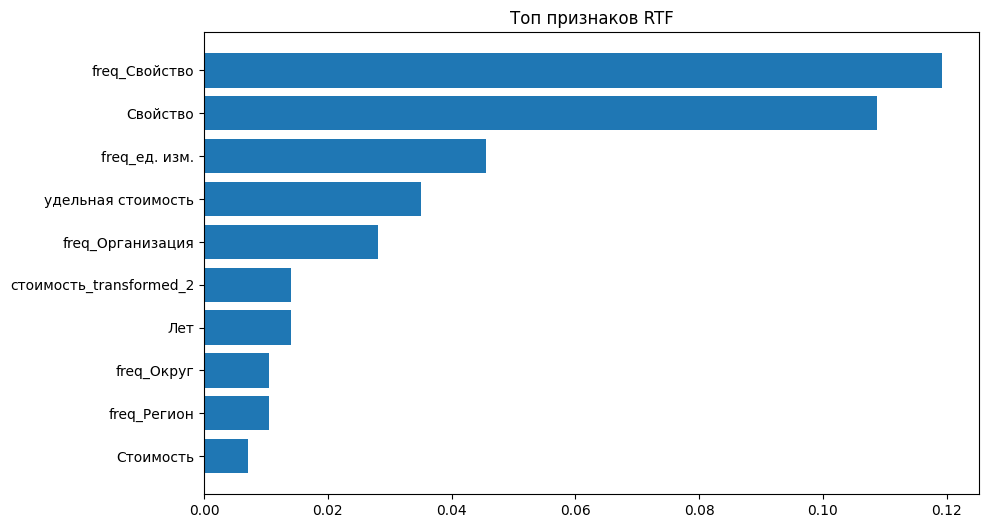

In [2251]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [287]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,extra,ros_shrinkage_005,0.6211,0.007,0.061,0.014
3,extra,ros_shrinkage_02,0.6211,0.002,0.047,0.012
4,extra,gaussian_noise,0.6105,0.004,0.048,0.014
2,extra,ros_shrinkage_01,0.5895,0.003,0.049,0.014
0,extra,ros,0.5579,0.003,0.067,0.052


In [ ]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [291]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': False, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.6123355263157895
Test accuracy: 0.6210526315789474
Время: 0.3215017318725586


In [ ]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=True,
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": np.arange(200, 600, 100),
    "model__max_depth": [None],
    'model__max_features': np.arange(0.2, 1.2, 0.2),
    'model__max_samples': np.arange(0.2, 1.2, 0.2),
    'model__min_samples_split': np.arange(2, 11, 2),
    'model__min_samples_leaf': np.arange(1, 10, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 2500 candidates, totalling 5000 fits




In [2256]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(0.8), 'model__max_samples': np.float64(0.8), 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(8), 'model__n_estimators': np.int64(300)}
Лучшая CV accuracy: 0.6595394736842105
Test accuracy: 0.6526315789473685
Время: 91.46121788024902


In [2257]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
15,cat__Свойство,0.125926
9,num__freq_Свойство,0.104358
5,num__значение_transformed_2,0.095849
3,num__удельная стоимость,0.093655
10,num__freq_ед. изм.,0.084078
12,ord__категории стоимости,0.074423
4,num__стоимость_transformed_2,0.059429
13,ord__категории возраста,0.059267
1,num__Стоимость,0.058144
0,num__Лет,0.052325


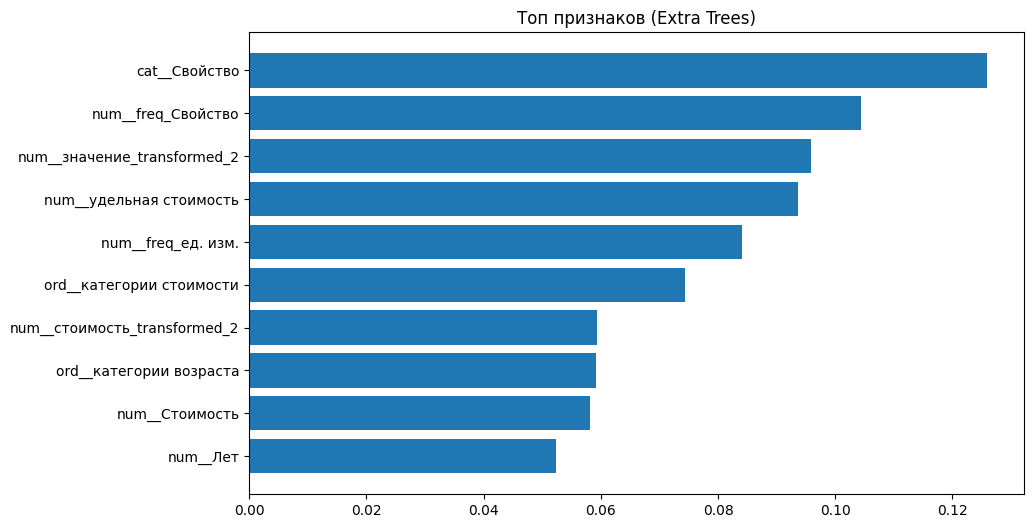

In [2258]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [2259]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
2,easy_ensemble,ros_shrinkage_01,0.5789,0.002,0.036,0.013
1,easy_ensemble,ros_shrinkage_005,0.5579,0.003,0.050,0.011
3,easy_ensemble,ros_shrinkage_02,0.5579,0.002,0.037,0.013
0,easy_ensemble,ros,0.5158,0.002,0.834,0.011
4,easy_ensemble,gaussian_noise,0.5053,0.002,0.048,0.013


In [2266]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.1, random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 12 candidates, totalling 24 fits


In [2267]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'entropy', 'model__estimator__splitter': 'random', 'model__replacement': False}
Лучшая CV accuracy: 0.6019736842105263
Test accuracy: 0.631578947368421
Время: 2.6729280948638916


In [2269]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.1, random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='entropy',
                                         splitter='random',
                                         random_state=123),
        replacement=False,
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": np.arange(100, 400, 100),
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.2, 1.2, 0.2),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 375 candidates, totalling 750 fits


In [2270]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(0.8), 'model__estimator__min_samples_leaf': np.int64(3), 'model__estimator__min_samples_split': np.int64(10), 'model__n_estimators': np.int64(200)}
Лучшая CV accuracy: 0.643969298245614
Test accuracy: 0.6421052631578947
Время: 42.902116775512695


In [2271]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
9,freq_Свойство,0.277193
10,freq_ед. изм.,0.249123
13,Свойство,0.098246
16,категории возраста,0.066667
15,категории стоимости,0.056140
3,удельная стоимость,0.045614
5,значение_transformed_2,0.042105
7,freq_Организация,0.017544
0,Лет,0.014035
8,freq_Родитель,0.010526


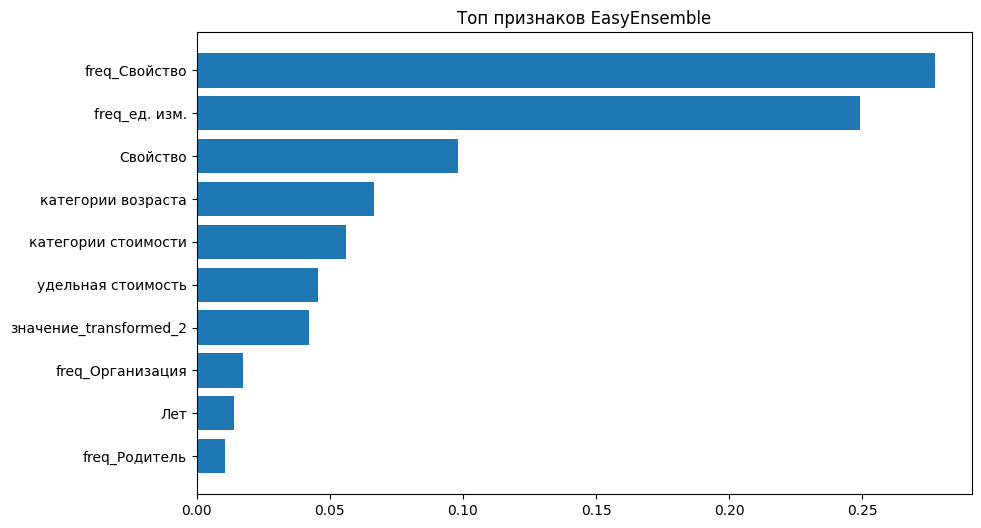

In [2272]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [2273]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,hgb,ros_shrinkage_005,0.4842,0.005,11.097,0.124
3,hgb,ros_shrinkage_02,0.4737,0.002,9.149,0.123
2,hgb,ros_shrinkage_01,0.4632,0.002,8.986,0.122
0,hgb,ros,0.4526,0.002,11.557,0.127
4,hgb,gaussian_noise,0.4526,0.002,8.909,0.122


In [2278]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.05)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 3 candidates, totalling 12 fits


In [2279]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.47617464539007087
Test accuracy: 0.49473684210526314
Время: 11.275271892547607


In [2280]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.05)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': [100, 200, 300],
    'clf__learning_rate': [0.01, 0.05],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}


grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 90 candidates, totalling 180 fits


In [2281]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__max_depth': None, 'clf__max_features': np.float64(0.2), 'clf__max_iter': 300, 'clf__min_samples_leaf': np.int64(1)}
Лучшая CV accuracy: 0.48174342105263157
Test accuracy: 0.49473684210526314
Время: 145.4914848804474


In [2282]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
8,freq_ед. изм.,0.129825
3,удельная стоимость,0.087719
10,Свойство,0.084211
5,значение_transformed_2,0.080702
1,Стоимость,0.021053
4,стоимость_transformed_2,0.021053
11,Округ,0.021053
6,freq_Регион,0.010526
7,freq_Родитель,0.007018
13,категории возраста,0.003509


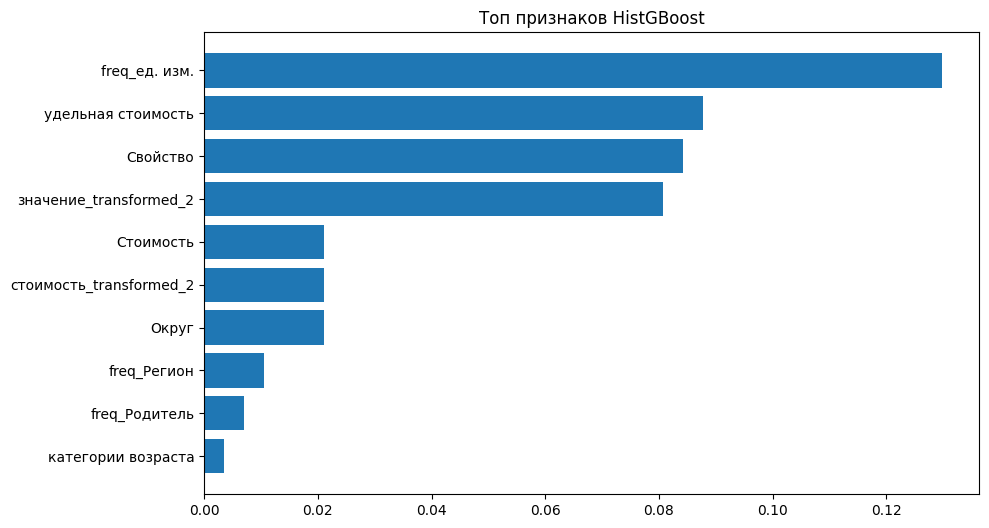

In [2283]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [2284]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,ada,ros_shrinkage_02,0.4632,0.003,0.012,0.0
2,ada,ros_shrinkage_01,0.4316,0.003,0.012,0.0
0,ada,ros,0.4211,0.002,0.005,0.0
4,ada,gaussian_noise,0.4105,0.002,0.014,0.0
1,ada,ros_shrinkage_005,0.3579,0.003,0.011,0.0


In [2319]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=7, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 7 folds for each of 3 candidates, totalling 21 fits


In [2320]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'log_loss', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.512660619803477
Test accuracy: 0.4631578947368421
Время: 0.25093984603881836


In [2329]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='log_loss',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__estimator__min_samples_split': np.arange(2, 11, 2),
    'clf__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 125 candidates, totalling 375 fits



In [2330]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(0.8), 'clf__estimator__min_samples_leaf': np.int64(5), 'clf__estimator__min_samples_split': np.int64(6)}
Лучшая CV accuracy: 0.5806878306878307
Test accuracy: 0.5789473684210527
Время: 11.482649087905884


In [2411]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='log_loss',
            splitter='best',
            max_features=0.8,
            max_depth=None,
            min_samples_leaf=5,
            min_samples_split=6,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(600, 1100, 100),
    'clf__learning_rate': [0.01, 0.1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 10 candidates, totalling 20 fits


In [2412]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.1, 'clf__n_estimators': np.int64(1000)}
Лучшая CV accuracy: 0.5340460526315789
Test accuracy: 0.5789473684210527
Время: 17.263545036315918


In [2413]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
8,num__freq_ед. изм.,0.300018
5,num__значение_transformed_2,0.108065
1,num__Стоимость,0.107826
3,num__удельная стоимость,0.103179
12,cat__Свойство,0.080475
0,num__Лет,0.060954
13,cat__Округ,0.048837
11,cat__Организация,0.044696
7,num__freq_Родитель,0.037542
4,num__стоимость_transformed_2,0.035362


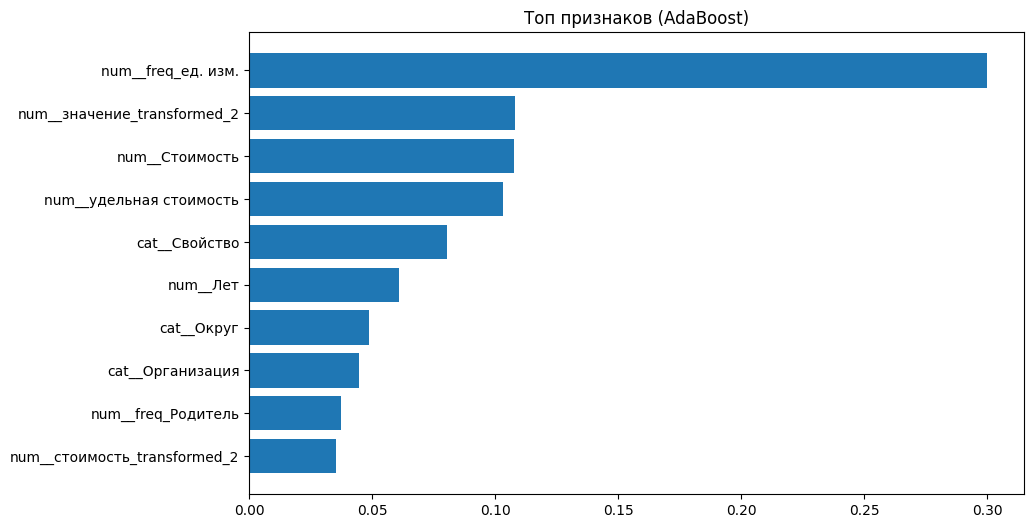

In [2414]:
top_n = 10
top_features = feat_imp_ada.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (AdaBoost)")
plt.show()

### Keras (MLP)

In [2415]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [2416]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [2417]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
  acc=0.5263 | t=3.0s
keras+ros_shrinkage_005
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
  acc=0.5053 | t=2.2s
keras+ros_shrinkage_01
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
  acc=0.4842 | t=2.3s
keras+ros_shrinkage_02
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
  acc=0.5053 | t=3.1s
keras+gaussian_noise
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
  acc=0.4737 | t=2.4s

Лучшая балансировка: ros


In [2418]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 2 folds for each of 9 candidates, totalling 18 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [2419]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'tanh', 'clf__model__optimizer': 'rmsprop'}
Лучшая CV accuracy: 0.5496710526315789
Test accuracy: 0.5263157894736842
Время: 17.263545036315918


In [2420]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation=best_activation,
        model__optimizer=best_optimizer,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [32, 64, 128],
    "clf__model__learning_rate": [0.01, 0.1],
    "clf__batch_size":           [16, 32, 64],
    "clf__epochs":               [25, 50, 100],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 2 folds for each of 54 candidates, totalling 108 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [16, 32, ...], 'clf__epochs': [25, 50, ...], 'clf__model__learning_rate': [0.01, 0.1], 'clf__model__n_size': [32, 64, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [2421]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 16, 'clf__epochs': 100, 'clf__model__learning_rate': 0.01, 'clf__model__n_size': 64}
Лучшая CV accuracy: 0.5339912280701754
Test accuracy: 0.5368421052631579
Время: 17.263545036315918


In [2422]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
13,Свойство,0.364912
5,значение_transformed_2,0.112281
15,категории стоимости,0.073684
4,стоимость_transformed_2,0.021053
10,freq_ед. изм.,0.021053
0,Лет,0.017544
8,freq_Родитель,0.017544
9,freq_Свойство,0.014035
12,Организация,0.003509
1,Стоимость,0.000000


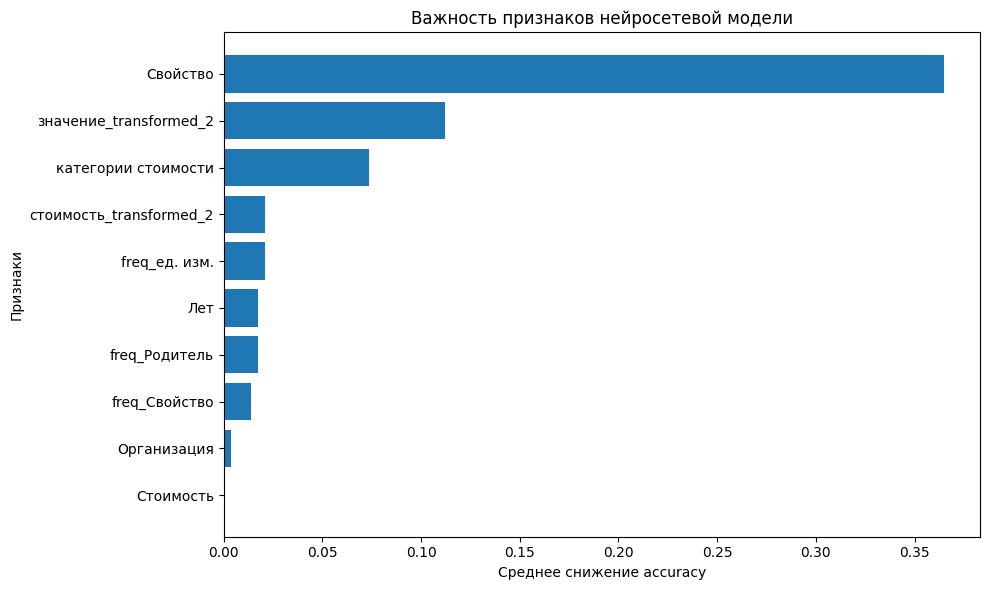

In [2423]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

# Сценарий 1: классификация без разделения

## кластеризация, детектирование, преобразование и отбор

In [2429]:
RANDOM_STATE = 123

print(f'Датасет: {len(df)} объектов')

feature_cols_hdbscan = [
    'Регион', 'Организация', 'Родитель',
    'Наименование', 'Свойство', 'Лет',
    'Стоимость', 'Значение', 'Округ', 'ед. изм.'
]

X_hdbscan = df[feature_cols_hdbscan].copy()

print('Расчет матрицы Гауэра')
gower_matrix = gower.gower_matrix(X_hdbscan)
gower_matrix = np.asarray(gower_matrix, dtype=np.float64)
print('Матрица Гауэра расчитана')

best_score_hdb  = -np.inf
best_params_hdb = None
best_labels_hdb = None

for min_cluster_size, min_samples in product(
    np.arange(2, 21, 1),
    np.arange(1, 21, 1)
):
    try:
        clusterer = hdbscan.HDBSCAN(
            metric='precomputed',
            min_cluster_size=int(min_cluster_size),
            min_samples=int(min_samples)
        )
        labels = clusterer.fit_predict(gower_matrix)
        cluster_mask = labels != -1

        if cluster_mask.sum() < 2:
            continue
        if len(np.unique(labels[cluster_mask])) < 2:
            continue

        score = silhouette_score(
            gower_matrix[np.ix_(cluster_mask, cluster_mask)],
            labels[cluster_mask],
            metric='precomputed'
        )

        if score > best_score_hdb:
            best_score_hdb  = score
            best_params_hdb = {
                'min_cluster_size': min_cluster_size,
                'min_samples': min_samples
            }
            best_labels_hdb = labels

    except Exception:
        pass

n_clusters   = len(np.unique(best_labels_hdb[best_labels_hdb != -1]))
noise_count  = (best_labels_hdb == -1).sum()
normal_count = (best_labels_hdb != -1).sum()
noise_share  = noise_count / len(best_labels_hdb) * 100

df_work = df.copy()
df_work['hdbscan_label'] = best_labels_hdb

df_normal = (
    df_work[df_work['hdbscan_label'] != -1]
    .drop(columns='hdbscan_label')
    .reset_index(drop=True)
)
df_rare = (
    df_work[df_work['hdbscan_label'] == -1]
    .drop(columns='hdbscan_label')
    .reset_index(drop=True)
)

print(
    f'  Лучший силуэт: '
    f'{best_score_hdb:.4f}'
)
print(
    f'  Лучшие параметры: '
    f'{best_params_hdb}'
)
print(
    f'  Количество кластеров: '
    f'{n_clusters}'
)
print(
    f'  Шумовых объектов: '
    f'{noise_count}'
)
print(
    f'  Доля шума: '
    f'{noise_share:.2f}%'
)
print(
    f'  Нормальных объектов: '
    f'{normal_count}'
)
print(
    f'  Классов в нормальных: '
    f'{df_normal["Наименование"].nunique()}'
)
print(
    f'  Классов в редких: '
    f'{df_rare["Наименование"].nunique()}'
)

Датасет: 12608 объектов
Расчет матрицы Гауэра
Матрица Гауэра расчитана
  Лучший силуэт: 0.6906
  Лучшие параметры: {'min_cluster_size': np.int64(2), 'min_samples': np.int64(1)}
  Количество кластеров: 3705
  Шумовых объектов: 1587
  Доля шума: 12.59%
  Нормальных объектов: 11021
  Классов в нормальных: 305
  Классов в редких: 257


In [2430]:
def prepare_for_if_full(df_input):

    X = df_input.copy()

    categorical_cols = [
        'Регион', 'Организация', 'Родитель',
        'Свойство', 'Округ', 'ед. изм.'
    ]
    numeric_cols = ['Лет', 'Стоимость', 'Значение']

    encoder = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )
    X[categorical_cols] = encoder.fit_transform(X[categorical_cols])

    return X[categorical_cols + numeric_cols]


results_if_full = {}

for split_name, subset in [('normal', df_normal), ('rare', df_rare)]:

    print(
        f'\nПодвыборка: {split_name} | '
        f'объектов: {len(subset)}'
    )

    df_sub = subset.copy()
    X_if   = prepare_for_if_full(df_sub)

    best_score_if  = -np.inf
    best_params_if = None
    best_labels_if = None

    for n_est, cont, max_f, max_s, b in product(
        np.arange(1, 6, 1),
        ['auto'],
        np.arange(0.1, 1.1, 0.1),
        np.arange(0.1, 1.1, 0.1),
        [True, False]
    ):
        try:
            iso = IsolationForest(
                n_estimators=int(n_est),
                contamination=cont,
                max_features=float(max_f),
                max_samples=float(max_s),
                bootstrap=b,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
            labels = iso.fit_predict(X_if)

            if (labels == -1).sum() < 2 or (labels == 1).sum() < 2:
                continue

            score = silhouette_score(X_if, labels)

            if score > best_score_if:
                best_score_if  = score
                best_params_if = {
                    'n_estimators': n_est,
                    'contamination': cont,
                    'max_features': max_f,
                    'max_samples': max_s,
                    'bootstrap': b
                }
                best_labels_if = labels

        except Exception:
            pass

    if best_labels_if is None:

        print('Подходящая конфигурация не найдена')
        df_sub['if_anomaly'] = 0

    else:

        df_sub['if_anomaly'] = (best_labels_if == -1).astype(int)

        anomaly_count = (df_sub['if_anomaly'] == 1).sum()
        normal_count  = (df_sub['if_anomaly'] == 0).sum()
        anomaly_share = anomaly_count / len(df_sub)

        print(
            f'  Лучший силуэт: '
            f'{best_score_if:.4f}'
        )
        print(
            f'  Лучшие параметры: '
            f'{best_params_if}'
        )
        print(
            f'  Аномальных объектов: '
            f'{anomaly_count}'
        )
        print(
            f'  Доля аномалий: '
            f'{anomaly_share:.2%}'
        )
        print(
            f'  Нормальных объектов: '
            f'{normal_count}'
        )

    results_if_full[split_name] = df_sub


Подвыборка: normal | объектов: 11021
  Лучший силуэт: 0.7052
  Лучшие параметры: {'n_estimators': np.int64(1), 'contamination': 'auto', 'max_features': np.float64(0.1), 'max_samples': np.float64(1.0), 'bootstrap': False}
  Аномальных объектов: 109
  Доля аномалий: 0.99%
  Нормальных объектов: 10912

Подвыборка: rare | объектов: 1587
  Лучший силуэт: 0.8623
  Лучшие параметры: {'n_estimators': np.int64(1), 'contamination': 'auto', 'max_features': np.float64(0.1), 'max_samples': np.float64(1.0), 'bootstrap': False}
  Аномальных объектов: 26
  Доля аномалий: 1.64%
  Нормальных объектов: 1561


In [2432]:
processed_full = {}

for split_name in ['normal', 'rare']:

    raw = results_if_full[split_name].copy()

    if len(raw) < 10:
        print(
            f'\n[{split_name}] слишком мало объектов '
            f'({len(raw)}), пропускаем'
        )
        processed_full[split_name] = raw.copy()
        continue

    print(
        f'\n[{split_name}] '
        f'объектов: {len(raw)}, '
        f'классов: {raw["Наименование"].nunique()}'
    )

    try:
        df_proc, sel_num, sel_cat = build_features(raw)
        processed_full[split_name] = df_proc

        print(
            f'  Числовых признаков после отбора: '
            f'{len(sel_num)}'
        )
        print(
            f'  Категориальных признаков после отбора: '
            f'{len(sel_cat)}'
        )
        print(
            f'  Итоговых признаков: '
            f'{len(sel_num) + len(sel_cat)}'
        )

    except Exception as e:
        print(f'  ОШИБКА: {e}')
        processed_full[split_name] = raw.copy()


[normal] объектов: 11021, классов: 305


[NUM step 1] drop=Лет_2 | VIF=147.01 | max_corr=1.000 | MI=0.3986 | F=11.05 | prio=2
[NUM step 2] drop=freq_категории стоимости | VIF=111.11 | max_corr=0.693 | MI=0.3176 | F=13.00 | prio=3
[NUM step 3] drop=freq_категории возраста | VIF=11.39 | max_corr=0.702 | MI=0.3356 | F=7.68 | prio=3
... (вывод сокращён: 19 строк) ...
[NUM step 6] drop=Лет_3 | VIF=2.22 | max_corr=1.000 | MI=0.2853 | F=4.41 | prio=2
[NUM step 7] drop=стоимость_transformed | VIF=1.97 | max_corr=1.000 | MI=0.4734 | F=5.50 | prio=1
[NUM step 8] drop=freq_ед. изм. | VIF=10.34 | max_corr=0.812 | MI=2.6823 | F=530.70 | prio=2
[NUM step 9] drop=значение_transformed | VIF=1.94 | max_corr=1.000 | MI=1.3448 | F=18.80 | prio=1
[CAT step 1] drop=Регион | pair=Регион vs Округ | CV=1.000 | MI=0.1812 | chi_score=0.00 | prio=1
[CAT step 2] drop=Организация | pair=Организация vs Родитель | CV=1.000 | MI=0.3956 | chi_score=0.21 | prio=2
[CAT step 3] drop=Родитель | pair=Родитель vs Округ | CV=0.987 | MI=0.2723 | chi_score=-0.00 | pr

In [2440]:
import pickle

with open('processed_full.pkl', 'wb') as f:
    pickle.dump(processed_full, f)

with open('results_if_full.pkl', 'wb') as f:
    pickle.dump(results_if_full, f)

print('Сохранено')

Сохранено


In [26]:
import pickle

with open('processed_full.pkl', 'rb') as f:
    processed_full = pickle.load(f)

with open('results_if_full.pkl', 'rb') as f:
    results_if_full = pickle.load(f)

print('Загружено')

Загружено


In [27]:
def run_experiment(model, model_name, preprocessor, balancers_dict,
                   X_train, X_test, y_train, y_test):
    
    results = []

    for bal_name, bal_func in balancers_dict.items():
        print(f"Запуск: {model_name} + {bal_name}")
        
        try:
            if preprocessor is not None:
                X_train_prep = preprocessor.fit_transform(X_train, y_train)
                X_test_prep = preprocessor.transform(X_test)

                if hasattr(X_train_prep, "toarray"):
                    X_train_prep = X_train_prep.toarray()
                    X_test_prep = X_test_prep.toarray()
            else:
                X_train_prep = X_train.copy()
                X_test_prep = X_test.copy()

            start_bal = time.time()
            X_train_bal, y_train_bal = bal_func.fit_resample(X_train_prep, y_train)
            bal_time = time.time() - start_bal

            start_train = time.time()
            model.fit(X_train_bal, y_train_bal)
            train_time = time.time() - start_train

            start_pred = time.time()
            y_pred = model.predict(X_test_prep)
            pred_time = time.time() - start_pred

            acc = accuracy_score(y_test, y_pred)

            results.append({
                "model": model_name,
                "balancing": bal_name,
                "accuracy": round(acc, 4),
                "balancing_time_sec": round(bal_time, 3),
                "train_time_sec": round(train_time, 3),
                "predict_time_sec": round(pred_time, 3)
            })

        except Exception as e:
            print(f"Ошибка в {model_name} + {bal_name}: {e}")
            continue

    return pd.DataFrame(results).sort_values(by="accuracy", ascending=False)

In [28]:
class GaussianNoiseSampler(BaseEstimator):
    def __init__(self, noise_level=0.05, random_state=123):
        self.noise_level = noise_level
        self.random_state = random_state

    def fit_resample(self, X, y):
        rng = np.random.default_rng(self.random_state)

        X = np.asarray(X)
        y = np.asarray(y)

        X_res = X.copy()
        y_res = y.copy()

        classes, counts = np.unique(y, return_counts=True)
        max_count = counts.max()

        for cls, count in zip(classes, counts):
            X_cls = X[y == cls]
            n_to_add = max_count - count

            if n_to_add <= 0:
                continue

            mean = X_cls.mean(axis=0)
            std = X_cls.std(axis=0)
            std = np.where(std == 0, 1e-8, std)

            X_new = rng.normal(
                loc=mean,
                scale=std * self.noise_level,
                size=(n_to_add, X.shape[1])
            )

            y_new = np.full(n_to_add, cls)

            X_res = np.vstack([X_res, X_new])
            y_res = np.concatenate([y_res, y_new])

        return X_res, y_res

In [29]:
balancers = {
    "ros": RandomOverSampler(random_state=123),
    "ros_shrinkage_005": RandomOverSampler(random_state=123, shrinkage=0.05),
    "ros_shrinkage_01": RandomOverSampler(random_state=123, shrinkage=0.1),
    "ros_shrinkage_02": RandomOverSampler(random_state=123, shrinkage=0.2),
    "gaussian_noise": GaussianNoiseSampler(noise_level=0.05, random_state=123),
}

## Нормальные классы

In [30]:
target_col = "Наименование"

class_counts = processed_full['normal']['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
processed_full['normal']['Наименование'] = processed_full['normal']['Наименование'].where(
    ~processed_full['normal']['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(processed_full['normal']['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 0
Объектов с меткой 'редкий': 66


In [31]:
X = processed_full['normal'].drop(columns=[target_col])
y = processed_full['normal'][target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.3,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (7714, 18) y_train: (7714,)
X_test: (3307, 18) y_test: (3307,)


In [32]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [33]:
X_test.columns

Index(['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация', 'freq_Родитель', 'freq_Свойство',
       'freq_ед. изм.', 'freq_Округ', 'Родитель', 'Свойство',
       'категории стоимости', 'категории возраста'],
      dtype='object')

In [34]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация',
       'freq_ед. изм.', 'freq_Округ', 'Родитель', 'Свойство',
       'категории стоимости', 'категории возраста']

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация',
       'freq_ед. изм.', 'freq_Округ']
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Родитель', 'Свойство']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [2464]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,svm,gaussian_noise,0.5464,6.040,43.400,30.410
2,svm,ros_shrinkage_01,0.5177,0.520,68.909,91.719
1,svm,ros_shrinkage_005,0.5171,0.566,65.527,90.928
3,svm,ros_shrinkage_02,0.5168,0.542,76.951,93.019
0,svm,ros,0.5165,0.118,59.651,70.574


In [2467]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [2468]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'rbf'}
Лучшая CV accuracy: 0.5327975793327457
Время (сек): 296.71415996551514
Test accuracy: 0.5464166918657394


In [2472]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(
        kernel='rbf',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': [1, 10, 100],
    'clf__gamma': [1e-1, 1e-2, 1e-3],
    'clf__tol': [1e-1, 1e-2, 1e-3],          
    'clf__max_iter': np.arange(100, 300, 100)
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=10,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 54 candidates, totalling 108 fits


In [2473]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)
y_pred_test = grid_svm2.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print("Test accuracy:", test_acc)
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': 100, 'clf__gamma': 0.1, 'clf__max_iter': np.int64(100), 'clf__tol': 0.001}
Лучшая CV accuracy: 0.5372050816696915
Test accuracy: 0.5639552464469307
Время обучения (сек): 938.5662689208984


In [2474]:
pipe = grid_svm2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
})

feat_imp = feat_imp.sort_values(
    "importance",
    ascending=False
)

feat_imp.head(10)

,feature,importance
15,Свойство,0.208648
12,freq_ед. изм.,0.183248
11,freq_Свойство,0.150388
7,значение_transformed_2,0.120855
16,категории стоимости,0.064006
6,стоимость_transformed_2,0.057555
0,Лет,0.041528
10,freq_Родитель,0.041024
1,Стоимость,0.035984
17,категории возраста,0.023990


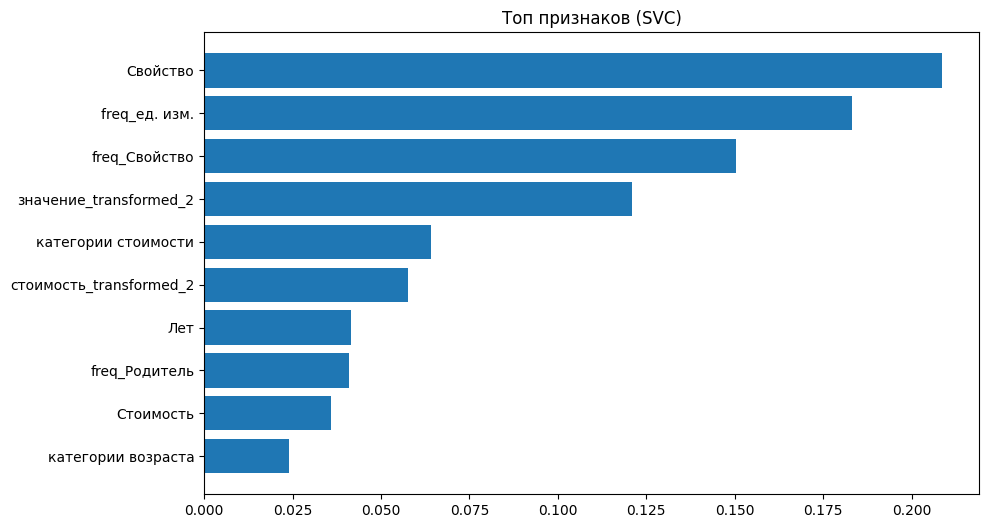

In [2475]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [2476]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,knn,gaussian_noise,0.4490,7.620,0.031,0.621
0,knn,ros,0.4454,0.148,0.040,0.529
2,knn,ros_shrinkage_01,0.4454,0.646,0.041,0.452
1,knn,ros_shrinkage_005,0.4439,0.621,0.039,0.477
3,knn,ros_shrinkage_02,0.4394,0.563,0.043,0.449


In [2477]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [2478]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'distance'}
Лучшая CV accuracy: 0.4533316048742546
Test accuracy: 0.4998488055639552
Время: 111.75235414505005


In [2479]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='distance',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(1, 36, 5),
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__leaf_size': np.arange(1, 36, 5)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 98 candidates, totalling 196 fits


In [2480]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(1), 'clf__metric': 'manhattan', 'clf__n_neighbors': np.int64(11)}
Лучшая CV accuracy: 0.46331345605392793
Test accuracy: 0.5164801935288781
Время: 854.5654172897339


In [2481]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=10
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
15,Свойство,0.172261
7,значение_transformed_2,0.071969
16,категории стоимости,0.061284
11,freq_Свойство,0.061083
12,freq_ед. изм.,0.059571
6,стоимость_transformed_2,0.029130
1,Стоимость,0.016833
10,freq_Родитель,0.015926
17,категории возраста,0.011692
9,freq_Организация,0.011592


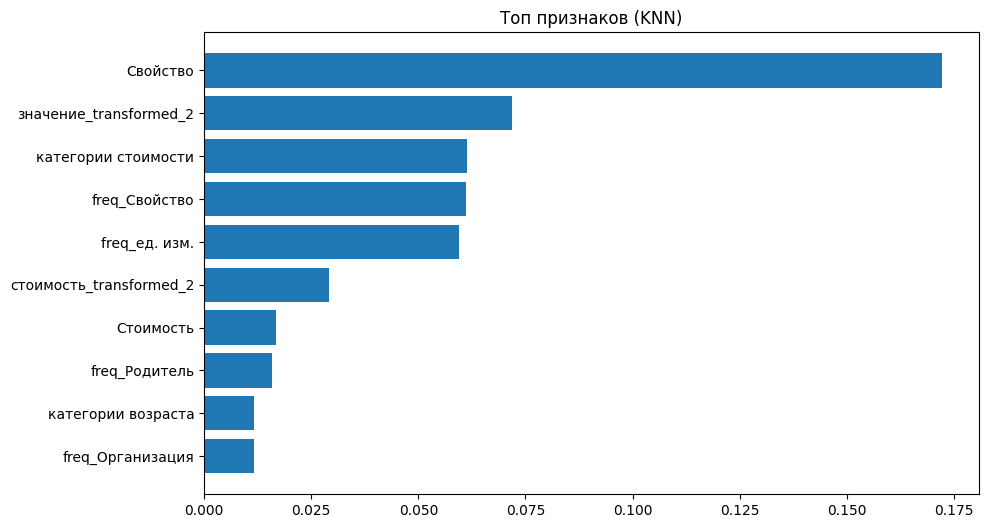

In [2482]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [2483]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,tree,gaussian_noise,0.5975,0.260,17.690,0.003
2,tree,ros_shrinkage_01,0.5963,0.050,14.146,0.004
1,tree,ros_shrinkage_005,0.5939,0.055,13.971,0.003
0,tree,ros,0.5936,0.026,1.133,0.003
3,tree,ros_shrinkage_02,0.5912,0.049,12.788,0.003


In [ ]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [282]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'entropy', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.5705211304122375
Test accuracy: 0.5972180223767766
Время: 5.68700909614563


In [ ]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='gini',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': np.arange(40, 90, 5),
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1250 candidates, totalling 2500 fits


In [2495]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': np.int64(65), 'clf__max_features': np.float64(1.0), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.5540575576873217
Test accuracy: 0.597520411248866
Время: 1369.994719028473


In [2496]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
4,num__удельная стоимость,0.118706
0,num__Лет,0.091847
2,num__Значение,0.086576
10,num__freq_Родитель,0.079917
5,num__износ,0.076060
11,num__freq_Свойство,0.066863
7,num__значение_transformed_2,0.064105
17,cat__Свойство,0.059842
1,num__Стоимость,0.049980
6,num__стоимость_transformed_2,0.048215


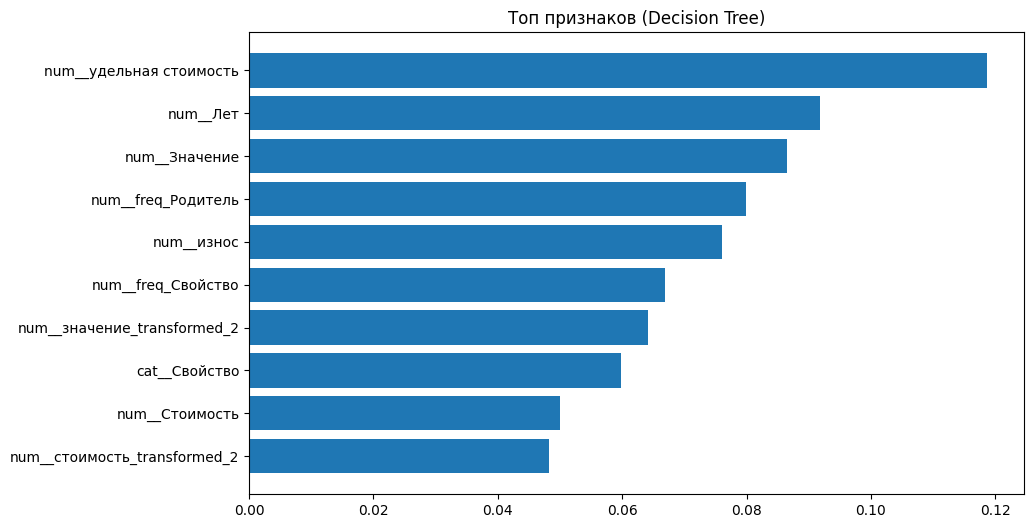

In [2497]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [2498]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,rf,gaussian_noise,0.6495,1.060,27.433,0.258
1,rf,ros_shrinkage_005,0.6465,0.058,27.563,0.502
3,rf,ros_shrinkage_02,0.6459,0.093,26.468,0.407
0,rf,ros,0.6441,0.030,2.701,0.115
2,rf,ros_shrinkage_01,0.6441,0.071,27.537,0.462


In [102]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=8
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 3 candidates, totalling 6 fits


In [103]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'entropy'}
Лучшая CV accuracy: 0.6135597614726471
Test accuracy: 0.6428787420622921
Время: 6.6072328090667725


In [233]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='entropy',
        random_state=123,
        n_jobs=8
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': [50, 100, 200, 300],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__max_samples': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 2500 candidates, totalling 5000 fits


In [234]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.4), 'clf__max_samples': np.float64(1.0), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(6), 'clf__n_estimators': 100}
Лучшая CV accuracy: 0.6160228156598393
Test accuracy: 0.6449954641669187
Время: 8632.004814863205


In [235]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
12,num__freq_ед. изм.,0.159267
11,num__freq_Свойство,0.137716
17,cat__Свойство,0.136964
2,num__Значение,0.097877
4,num__удельная стоимость,0.070906
7,num__значение_transformed_2,0.061410
1,num__Стоимость,0.051917
0,num__Лет,0.049140
5,num__износ,0.044023
10,num__freq_Родитель,0.042943


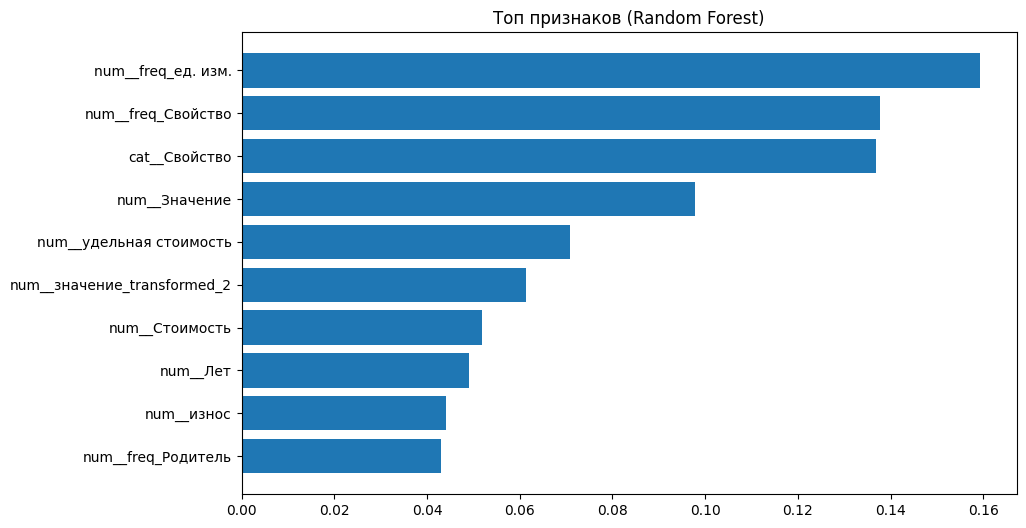

In [236]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [2499]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,rtf,gaussian_noise,0.6359,0.344,399.988,1.370
0,rtf,ros,0.6344,0.056,40.333,1.425
2,rtf,ros_shrinkage_01,0.6284,0.054,387.063,2.211
1,rtf,ros_shrinkage_005,0.6272,0.053,373.211,1.539
3,rtf,ros_shrinkage_02,0.6229,0.063,376.421,2.166


In [35]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=8,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best", 'random'],
    "model__pca_solver": ["auto", "full", 'randomized'],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 18 candidates, totalling 36 fits


In [36]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'entropy', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'randomized'}
Лучшая CV accuracy: 0.6031890070002592
Test accuracy: 0.6389476867251285
Время: 345.84494376182556


In [40]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='entropy',
                                              splitter='best',
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=8,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.25, 1.25, 0.25), 
    'model__base_estimator__min_samples_split': np.arange(2, 9, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 8, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 64 candidates, totalling 192 fits


In [41]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(0.5), 'model__base_estimator__min_samples_leaf': np.int64(3), 'model__base_estimator__min_samples_split': np.int64(8)}
Лучшая CV accuracy: 0.6143363116823831
Test accuracy: 0.6389476867251285
Время: 2046.9946269989014


In [42]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='entropy',
                                              splitter='best',
                                              max_features=0.5,
                                              max_depth=None,
                                              min_samples_leaf=3,
                                              min_samples_split=8,
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=8,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": np.arange(100, 400, 100),
    "model__min_group": [1, 2],
    "model__max_group": [1, 2, 3],
    "model__remove_proportion": np.arange(0.25, 1.25, 0.25),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 72 candidates, totalling 144 fits


In [43]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 2, 'model__min_group': 1, 'model__n_estimators': np.int64(300), 'model__remove_proportion': np.float64(0.25)}
Лучшая CV accuracy: 0.6131708581799327
Test accuracy: 0.6452978530390082
Время: 773.0033330917358


In [44]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=8
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
12,freq_ед. изм.,0.150388
15,Свойство,0.130531
11,freq_Свойство,0.109364
7,значение_transformed_2,0.040218
10,freq_Родитель,0.021268
4,удельная стоимость,0.021066
0,Лет,0.011793
2,Значение,0.004435
13,freq_Округ,0.004133
8,freq_Регион,0.003024


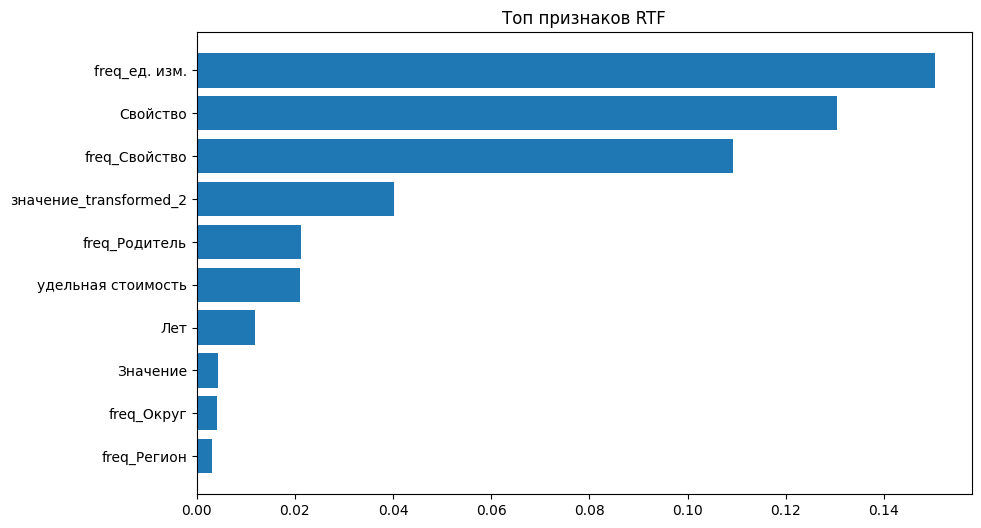

In [45]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [2500]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,extra,ros,0.6329,0.019,0.800,0.117
4,extra,gaussian_noise,0.6299,0.430,0.806,0.090
1,extra,ros_shrinkage_005,0.6238,0.061,1.217,0.212
2,extra,ros_shrinkage_01,0.6172,0.063,1.403,0.216
3,extra,ros_shrinkage_02,0.6129,0.061,1.856,0.344


In [ ]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [14]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': False, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.5925589836660616
Test accuracy: 0.6328999092833384
Время: 13.744303703308105


In [15]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=False,
        n_jobs=8,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None],
    'model__max_features': np.arange(0.2, 1.2, 0.2),
    'model__max_samples': [None],
    'model__min_samples_split': np.arange(2, 11, 2),
    'model__min_samples_leaf': np.arange(1, 10, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 375 candidates, totalling 750 fits


In [16]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(0.6000000000000001), 'model__max_samples': None, 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(6), 'model__n_estimators': 300}
Лучшая CV accuracy: 0.6052631578947368
Test accuracy: 0.638645297853039
Время: 829.4961569309235


In [17]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
7,num__значение_transformed_2,0.088951
4,num__удельная стоимость,0.080532
1,num__Стоимость,0.071404
2,num__Значение,0.070643
0,num__Лет,0.069205
10,num__freq_Родитель,0.065169
6,num__стоимость_transformed_2,0.063998
14,ord__категории стоимости,0.062371
17,cat__Свойство,0.057146
5,num__износ,0.056479


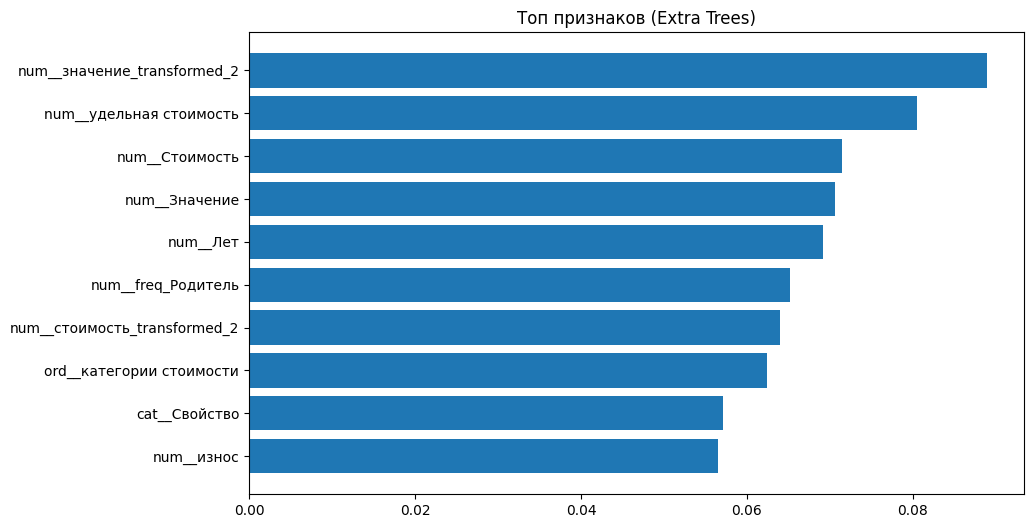

In [18]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [2501]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,easy_ensemble,gaussian_noise,0.6054,0.273,21.587,0.280
2,easy_ensemble,ros_shrinkage_01,0.5975,0.054,17.170,0.352
0,easy_ensemble,ros,0.5954,0.026,5.719,0.443
3,easy_ensemble,ros_shrinkage_02,0.5954,0.054,15.557,0.352
1,easy_ensemble,ros_shrinkage_005,0.5948,0.062,17.299,0.348


In [25]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=8
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 12 candidates, totalling 24 fits


In [26]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'gini', 'model__estimator__splitter': 'random', 'model__replacement': True}
Лучшая CV accuracy: 0.5881514130152968
Test accuracy: 0.6262473540973692
Время: 8.309976816177368


In [28]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='gini',
                                         splitter='random',
                                         random_state=123),
        replacement=True,
        random_state=123,
        n_jobs=8
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": [25, 50, 75, 100],
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.2, 1.2, 0.2),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 500 candidates, totalling 1000 fits


In [29]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(0.8), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(2), 'model__n_estimators': 75}
Лучшая CV accuracy: 0.6029297381384495
Test accuracy: 0.6383429089809495
Время: 659.0307738780975


In [30]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=8
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
12,freq_ед. изм.,0.365487
15,Свойство,0.313779
11,freq_Свойство,0.207237
16,категории стоимости,0.068441
7,значение_transformed_2,0.045459
4,удельная стоимость,0.031348
2,Значение,0.026308
17,категории возраста,0.021369
10,freq_Родитель,0.020058
9,freq_Организация,0.015119


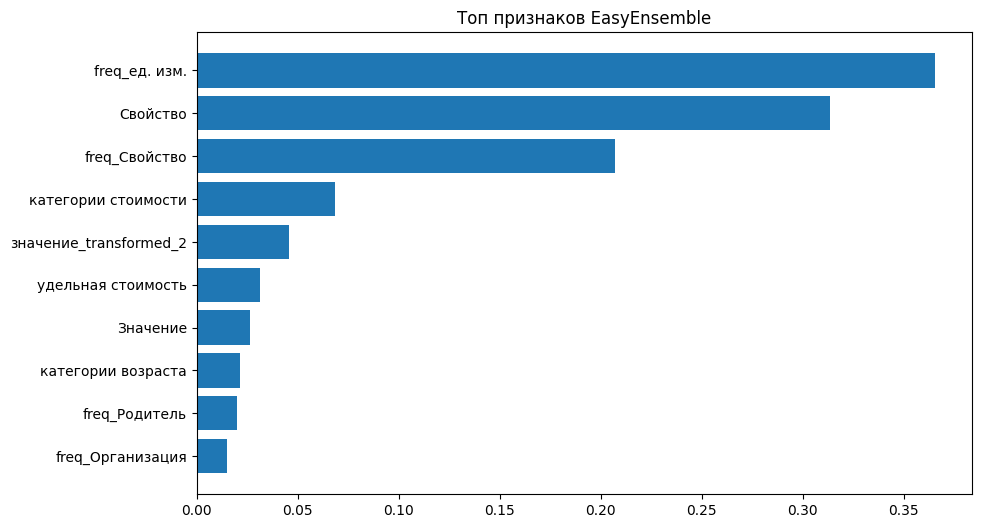

In [31]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [2502]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,hgb,ros_shrinkage_02,0.3375,0.047,5.318,0.027
2,hgb,ros_shrinkage_01,0.3323,0.047,5.961,0.050
1,hgb,ros_shrinkage_005,0.2951,0.049,9.906,0.068
0,hgb,ros,0.2691,0.021,5.645,0.118
4,hgb,gaussian_noise,0.1733,0.177,3.209,0.026


In [54]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 3 candidates, totalling 12 fits


In [55]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.29945616050282975
Test accuracy: 0.3356516480193529
Время: 7.449816942214966


In [57]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(shrinkage=0.2, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': [50, 100, 200],
    'clf__learning_rate': [0.01, 0.1],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.3, 1.2, 0.3),
    'clf__min_samples_leaf': np.arange(1, 8, 3)
}

grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 54 candidates, totalling 108 fits


In [58]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__max_depth': None, 'clf__max_features': np.float64(0.3), 'clf__max_iter': 200, 'clf__min_samples_leaf': np.int64(7)}
Лучшая CV accuracy: 0.557298418459943
Test accuracy: 0.5938917447837919
Время: 1213.8067607879639


In [59]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=8
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
10,freq_ед. изм.,0.377180
13,Свойство,0.179317
2,Значение,0.150388
4,удельная стоимость,0.111985
7,значение_transformed_2,0.087693
1,Стоимость,0.041125
14,категории стоимости,0.033868
0,Лет,0.033464
8,freq_Регион,0.031348
5,износ,0.029533


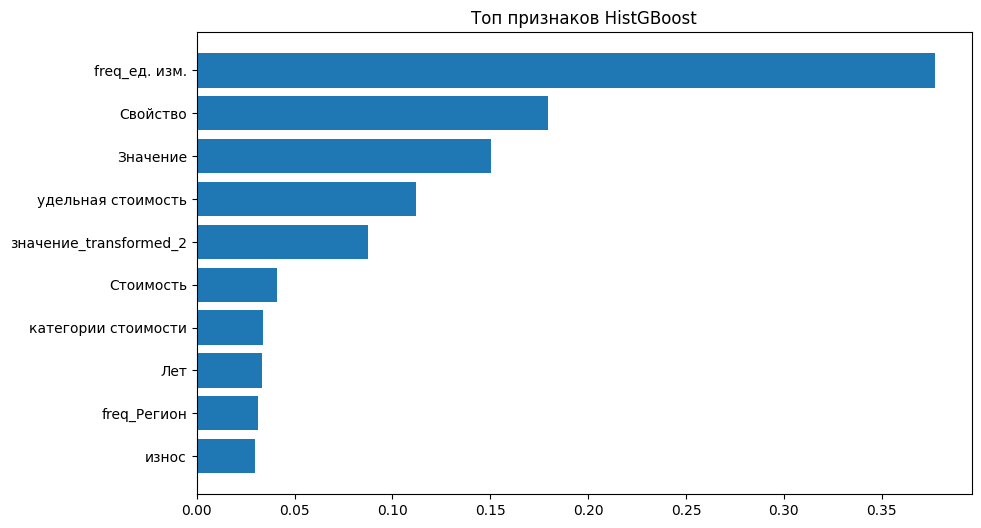

In [60]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [2503]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,ada,gaussian_noise,0.5389,0.155,13.216,0.004
0,ada,ros,0.5274,0.014,1.032,0.005
1,ada,ros_shrinkage_005,0.5274,0.044,11.079,0.005
2,ada,ros_shrinkage_01,0.5237,0.044,11.892,0.005
3,ada,ros_shrinkage_02,0.5198,0.044,12.641,0.005


In [75]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=6, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 6 folds for each of 3 candidates, totalling 18 fits


In [76]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'gini', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.5225543768771949
Test accuracy: 0.5367402479588751
Время: 38.32822108268738


In [77]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.3, 1.2, 0.3),
    'clf__estimator__min_samples_split': np.arange(2, 9, 3),
    'clf__estimator__min_samples_leaf': np.arange(1, 8, 3)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 27 candidates, totalling 54 fits


In [78]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(0.8999999999999999), 'clf__estimator__min_samples_leaf': np.int64(1), 'clf__estimator__min_samples_split': np.int64(5)}
Лучшая CV accuracy: 0.5571687840290381
Test accuracy: 0.6050801330511038
Время: 1952.6472449302673


In [92]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            max_features=0.9,
            max_depth=None,
            min_samples_leaf=1,
            min_samples_split=5,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': [50, 100, 200, 300],
    'clf__learning_rate': [0.01, 0.05, 0.1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 12 candidates, totalling 24 fits


In [93]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.1, 'clf__n_estimators': 300}
Лучшая CV accuracy: 0.5789473684210527
Test accuracy: 0.6208043543997581
Время: 8293.961477041245


In [94]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
15,cat__Свойство,0.142105
7,num__значение_transformed_2,0.136806
4,num__удельная стоимость,0.108349
5,num__износ,0.094484
14,cat__Родитель,0.086847
2,num__Значение,0.079785
0,num__Лет,0.075662
9,num__freq_Организация,0.065812
6,num__стоимость_transformed_2,0.050997
8,num__freq_Регион,0.046321


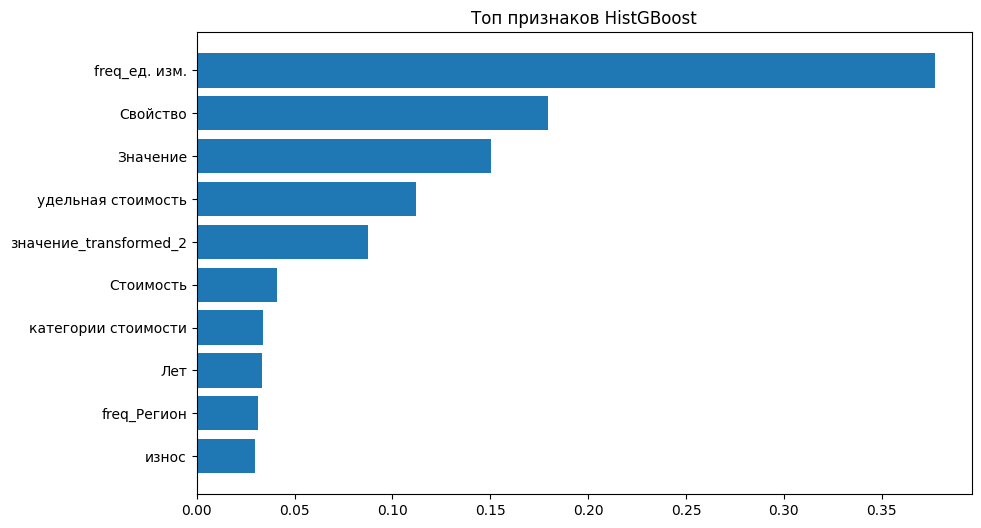

In [95]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### Keras (MLP)

In [80]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [81]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [82]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [2507]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 496us/step
  acc=0.5186 | t=91.8s
keras+ros_shrinkage_005
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 472us/step
  acc=0.5204 | t=91.1s
keras+ros_shrinkage_01
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 442us/step
  acc=0.5210 | t=91.6s
keras+ros_shrinkage_02
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 433us/step
  acc=0.5138 | t=90.9s
keras+gaussian_noise
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 429us/step
  acc=0.5280 | t=89.8s

Лучшая балансировка: gaussian_noise


In [89]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 5 folds for each of 9 candidates, totalling 45 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,8
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [90]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'sigmoid', 'clf__model__optimizer': 'adam'}
Лучшая CV accuracy: 0.49520154196223604
Test accuracy: 0.5022679165406713
Время: 1952.6472449302673


In [98]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation='sigmoid',
        model__optimizer='adam',
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [64, 128, 256],
    "clf__model__learning_rate": [0.001, 0.01, 0.1],
    "clf__batch_size":           [32, 64, 128],
    "clf__epochs":               [50, 100, 200],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 2 folds for each of 81 candidates, totalling 162 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [32, 64, ...], 'clf__epochs': [50, 100, ...], 'clf__model__learning_rate': [0.001, 0.01, ...], 'clf__model__n_size': [64, 128, ...]}"
,scoring,'accuracy'
,n_jobs,8
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [99]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 64, 'clf__epochs': 200, 'clf__model__learning_rate': 0.001, 'clf__model__n_size': 256}
Лучшая CV accuracy: 0.535908737360643
Test accuracy: 0.5681886906561838
Время: 8293.961477041245


In [100]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=8
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
15,Свойство,0.413063
7,значение_transformed_2,0.148775
11,freq_Свойство,0.092833
16,категории стоимости,0.065417
12,freq_ед. изм.,0.065215
14,Родитель,0.056345
6,стоимость_transformed_2,0.047072
0,Лет,0.038403
1,Стоимость,0.033061
10,freq_Родитель,0.022881


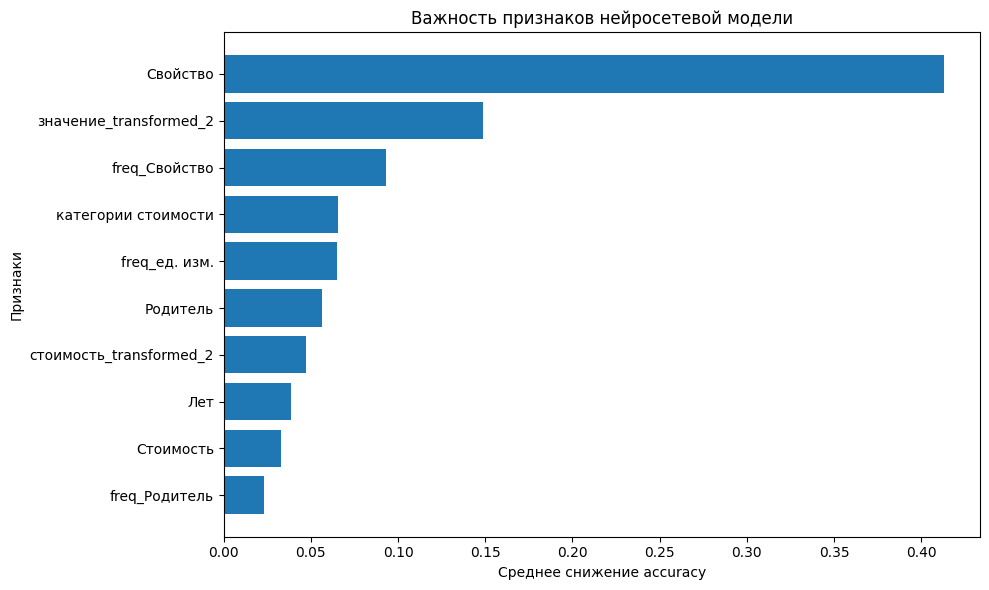

In [101]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

## Редкие классы

In [237]:
target_col = "Наименование"

class_counts = processed_full['rare']['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
processed_full['rare']['Наименование'] = processed_full['rare']['Наименование'].where(
    ~processed_full['rare']['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(processed_full['rare']['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 0
Объектов с меткой 'редкий': 87


In [238]:
X = processed_full['rare'].drop(columns=[target_col])
y = processed_full['rare'][target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.33,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (1063, 17) y_train: (1063,)
X_test: (524, 17) y_test: (524,)


In [239]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [240]:
X_test.columns

Index(['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация', 'freq_Родитель', 'freq_Свойство',
       'freq_Округ', 'Свойство', 'Округ', 'категории стоимости',
       'категории возраста'],
      dtype='object')

In [241]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация', 'freq_Родитель',
       'Свойство', 'Округ', 'категории стоимости',
       'категории возраста']

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация', 'freq_Родитель']
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Свойство', 'Округ']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [113]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,svm,ros_shrinkage_005,0.2576,0.025,1.054,0.938
2,svm,ros_shrinkage_01,0.2557,0.024,1.138,0.928
0,svm,ros,0.2538,0.006,0.907,0.687
3,svm,ros_shrinkage_02,0.2538,0.022,1.143,0.885
4,svm,gaussian_noise,0.2462,0.042,0.757,0.553


In [ ]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.05)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [126]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'linear'}
Лучшая CV accuracy: 0.22671615479376406
Время (сек): 3.9724960327148438
Test accuracy: 0.2652671755725191


In [133]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.05)),  
    ('clf', SVC(
        kernel='linear',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': np.arange(5, 105, 5),    
    'clf__tol': [1e-1, 1e-2, 1e-3],          
    'clf__max_iter': np.arange(5, 105, 5),
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 1200 candidates, totalling 2400 fits


In [134]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)

y_pred_test = grid_svm2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred_test))
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': np.int64(15), 'clf__max_iter': np.int64(40), 'clf__tol': 0.01}
Лучшая CV accuracy: 0.23142248276057376
Test accuracy: 0.28435114503816794
Время обучения (сек): 89.49587512016296


In [135]:
pipe = grid_svm2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

importances = np.abs(model.coef_).mean(axis=0)

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,num__freq_Свойство,0.228713
7,num__значение_transformed_2,0.180611
10,num__freq_Родитель,0.145297
0,num__Лет,0.134853
6,num__стоимость_transformed_2,0.126657
43,cat__Свойство_площадь общая,0.116724
9,num__freq_Организация,0.109363
8,num__freq_Регион,0.108548
12,num__freq_Округ,0.090126
64,cat__категории стоимости_высокая,0.090025


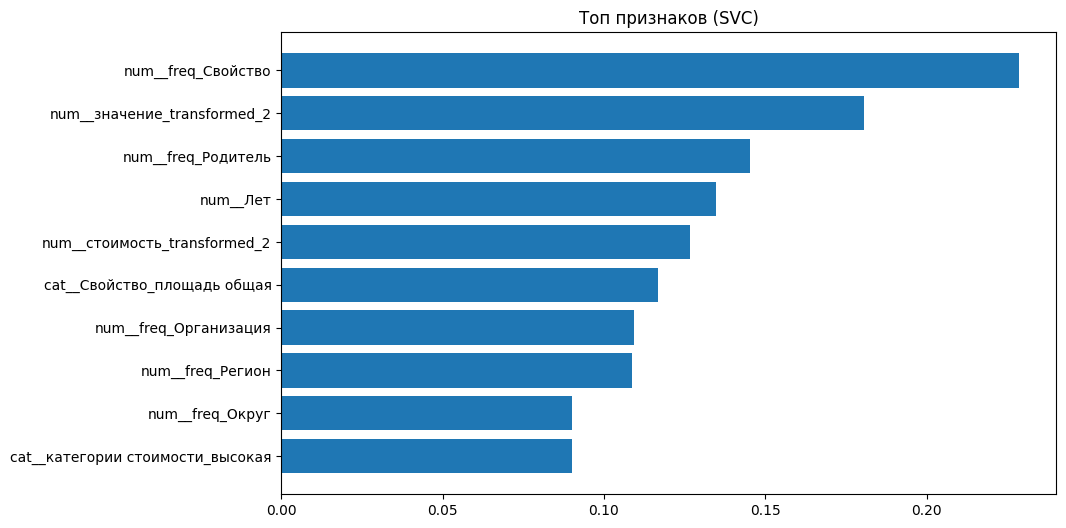

In [136]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [114]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,knn,gaussian_noise,0.1813,0.051,0.001,0.005
2,knn,ros_shrinkage_01,0.1698,0.023,0.001,0.008
3,knn,ros_shrinkage_02,0.1698,0.022,0.001,0.006
1,knn,ros_shrinkage_005,0.1622,0.022,0.001,0.007
0,knn,ros,0.1603,0.007,0.002,0.080


In [ ]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits



In [138]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'distance'}
Лучшая CV accuracy: 0.1730898574118913
Test accuracy: 0.18893129770992367
Время: 0.5194759368896484


In [139]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='distance',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(2, 32, 2),
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__leaf_size': np.arange(2, 32, 2)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 450 candidates, totalling 900 fits


In [140]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(2), 'clf__metric': 'manhattan', 'clf__n_neighbors': np.int64(4)}
Лучшая CV accuracy: 0.19284616909505403
Test accuracy: 0.2099236641221374
Время: 13.922985076904297


In [141]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
13,Свойство,0.097328
11,freq_Свойство,0.061705
15,категории стоимости,0.037532
7,значение_transformed_2,0.035623
10,freq_Родитель,0.019084
6,стоимость_transformed_2,0.011450
0,Лет,0.010814
3,if_anomaly,0.006997
9,freq_Организация,0.005725
14,Округ,0.003181


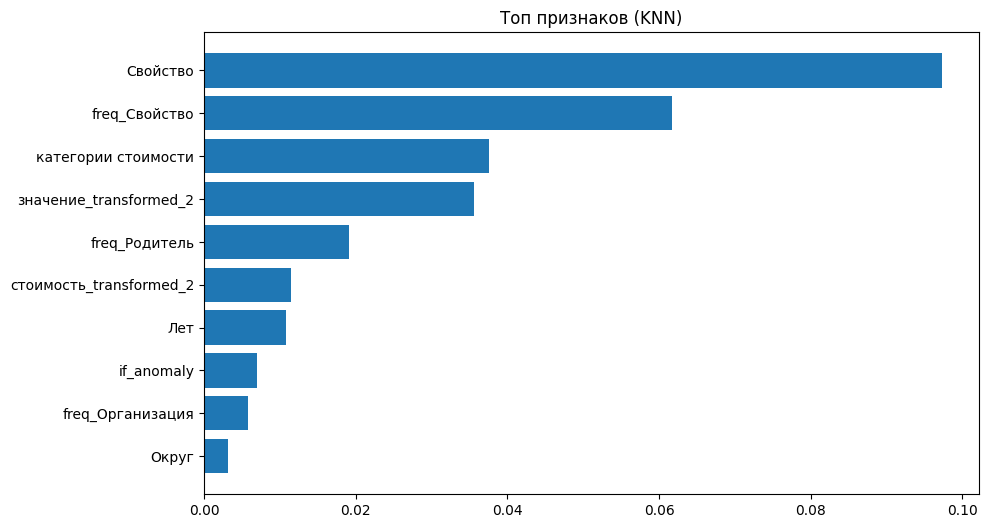

In [142]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [115]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,tree,gaussian_noise,0.3511,0.013,0.592,0.0
2,tree,ros_shrinkage_01,0.3454,0.011,0.555,0.0
1,tree,ros_shrinkage_005,0.3359,0.012,0.573,0.0
0,tree,ros,0.3187,0.004,0.063,0.0
3,tree,ros_shrinkage_02,0.3034,0.011,0.551,0.0


In [146]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 3 candidates, totalling 9 fits


In [147]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.3160579294978913
Test accuracy: 0.3511450381679389
Время: 1.0261330604553223


In [150]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='gini',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': [5, 10, 20, 30, 40, 50],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 11, 2)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 750 candidates, totalling 1500 fits



In [151]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': 40, 'clf__max_features': np.float64(1.0), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4)}
Лучшая CV accuracy: 0.28976395791739235
Test accuracy: 0.3530534351145038
Время: 22.85410475730896


In [152]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
4,num__удельная стоимость,0.135386
2,num__Значение,0.108037
15,cat__Свойство,0.100949
0,num__Лет,0.092475
7,num__значение_transformed_2,0.073589
10,num__freq_Родитель,0.066912
1,num__Стоимость,0.066748
11,num__freq_Свойство,0.053102
5,num__износ,0.052950
9,num__freq_Организация,0.050366


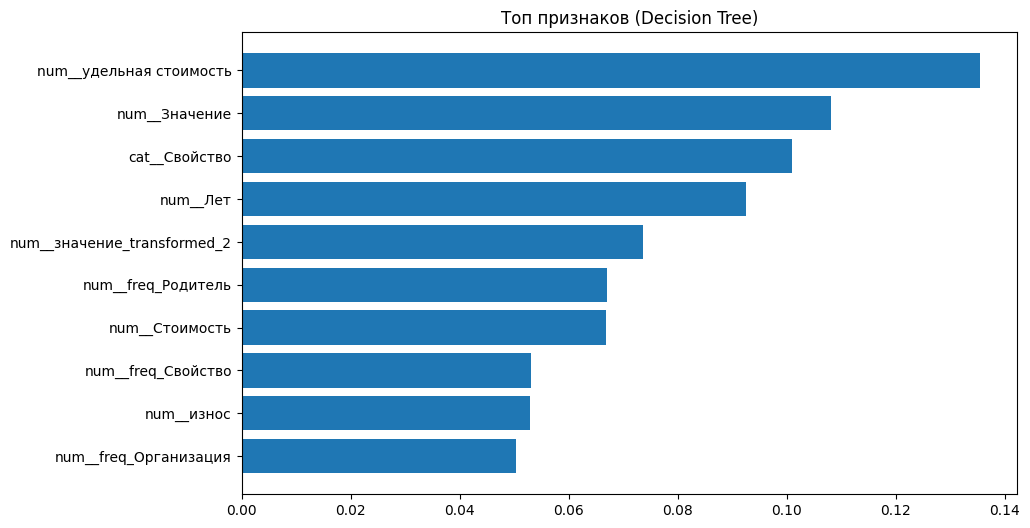

In [153]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [116]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rf,ros,0.4065,0.004,0.251,0.026
2,rf,ros_shrinkage_01,0.3893,0.011,1.018,0.025
1,rf,ros_shrinkage_005,0.3874,0.011,1.061,0.014
3,rf,ros_shrinkage_02,0.3817,0.011,1.104,0.024
4,rf,gaussian_noise,0.3798,0.012,1.375,0.027


In [154]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 3 candidates, totalling 6 fits


In [155]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini'}
Лучшая CV accuracy: 0.3537144414709089
Test accuracy: 0.4064885496183206
Время: 1.0246171951293945


In [296]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': np.arange(200, 375, 25),
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__max_samples': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 4375 candidates, totalling 8750 fits



In [297]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.4), 'clf__max_samples': np.float64(1.0), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4), 'clf__n_estimators': np.int64(350)}
Лучшая CV accuracy: 0.3706529742435184
Test accuracy: 0.41412213740458015
Время: 3124.4484021663666


In [298]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
2,num__Значение,0.107106
4,num__удельная стоимость,0.104469
7,num__значение_transformed_2,0.092951
1,num__Стоимость,0.080543
15,cat__Свойство,0.077804
10,num__freq_Родитель,0.073553
5,num__износ,0.072566
11,num__freq_Свойство,0.072399
6,num__стоимость_transformed_2,0.068663
0,num__Лет,0.067899


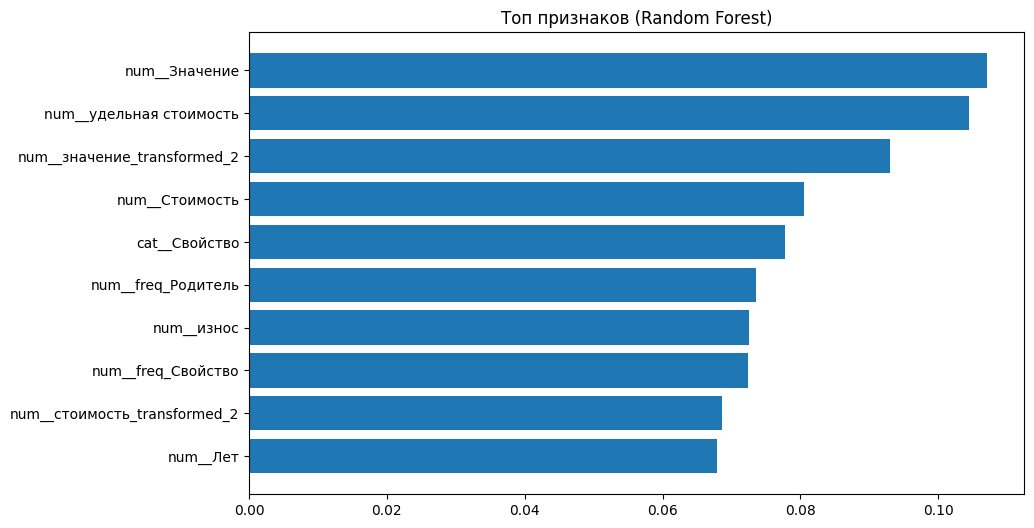

In [299]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [ ]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,rtf,gaussian_noise,0.3760,0.010,24.443,0.154
0,rtf,ros,0.3740,0.005,4.222,0.149
1,rtf,ros_shrinkage_005,0.3607,0.011,22.110,0.135
3,rtf,ros_shrinkage_02,0.3607,0.011,21.215,0.125
2,rtf,ros_shrinkage_01,0.3454,0.011,21.150,0.143


In [171]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=8,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best"],
    "model__pca_solver": ["auto", "full"],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 6 candidates, totalling 18 fits


In [172]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'gini', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'full'}
Лучшая CV accuracy: 0.3706214689265537
Test accuracy: 0.37213740458015265
Время: 181.271418094635


In [173]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              random_state=123),
        pca_solver='full',
        n_jobs=8,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.2, 1.2, 0.2), 
    'model__base_estimator__min_samples_split': np.arange(2, 11, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 125 candidates, totalling 250 fits


In [174]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(0.4), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(4)}
Лучшая CV accuracy: 0.3499550429746683
Test accuracy: 0.37786259541984735
Время: 1105.4211659431458


In [204]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              max_features=0.4,
                                              max_depth=None,
                                              min_samples_leaf=1,
                                              min_samples_split=4,
                                              random_state=123),
        pca_solver='full',
        n_jobs=-1,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": np.arange(100, 225, 25),
    "model__min_group": [1, 2, 3],
    "model__max_group": [1, 2, 3],
    "model__remove_proportion": np.arange(0.1, 1.0, 0.1),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 405 candidates, totalling 810 fits



In [205]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 3, 'model__min_group': 1, 'model__n_estimators': np.int64(100), 'model__remove_proportion': np.float64(0.7000000000000001)}
Лучшая CV accuracy: 0.3603110884556023
Test accuracy: 0.3931297709923664
Время: 964.0246798992157


In [206]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=8
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,freq_Свойство,0.239822
13,Свойство,0.148219
7,значение_transformed_2,0.064249
10,freq_Родитель,0.030534
2,Значение,0.027990
4,удельная стоимость,0.021628
0,Лет,0.012723
1,Стоимость,0.010814
16,категории возраста,0.009542
15,категории стоимости,0.005725


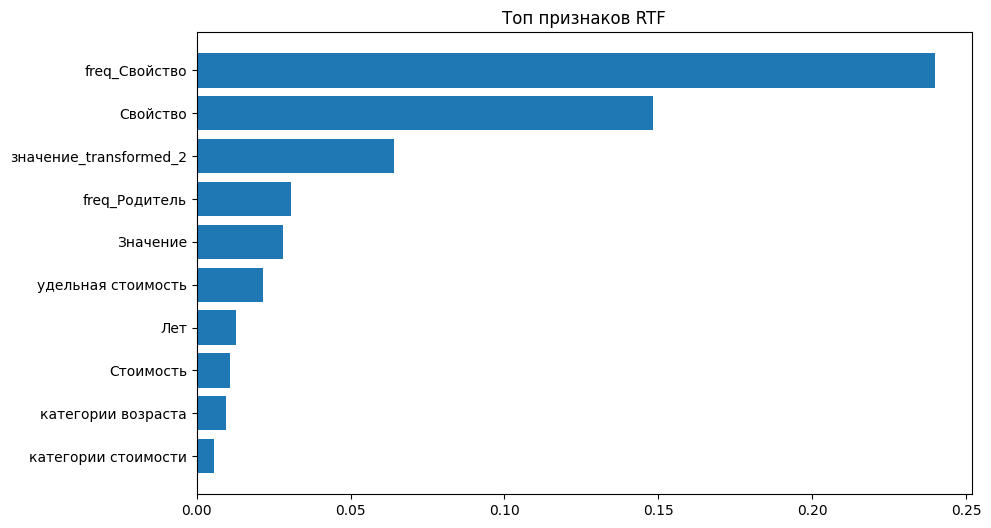

In [207]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [118]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,extra,ros,0.3473,0.007,0.132,0.015
1,extra,ros_shrinkage_005,0.3416,0.011,0.120,0.015
4,extra,gaussian_noise,0.3416,0.010,0.102,0.014
2,extra,ros_shrinkage_01,0.3321,0.011,0.121,0.014
3,extra,ros_shrinkage_02,0.3321,0.011,0.136,0.014


In [177]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 6 candidates, totalling 18 fits


In [178]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': False, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.3470915890825177
Test accuracy: 0.3473282442748092
Время: 1.7501230239868164


In [190]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=False,
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": [225, 250, 275, 300, 325],
    "model__max_depth": [None],
    'model__max_features': np.arange(0.1, 1.1, 0.1),
    'model__max_samples': [None],
    'model__min_samples_split': np.arange(2, 11, 1),
    'model__min_samples_leaf': np.arange(1, 10, 1)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 4050 candidates, totalling 8100 fits





In [191]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(0.6000000000000001), 'model__max_samples': None, 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(2), 'model__n_estimators': 225}
Лучшая CV accuracy: 0.36970250484969486
Test accuracy: 0.3969465648854962
Время: 1134.8222053050995


In [192]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
4,num__удельная стоимость,0.093773
7,num__значение_transformed_2,0.092364
15,cat__Свойство,0.078426
11,num__freq_Свойство,0.077999
2,num__Значение,0.073507
6,num__стоимость_transformed_2,0.066314
10,num__freq_Родитель,0.065831
1,num__Стоимость,0.062841
0,num__Лет,0.061893
13,ord__категории стоимости,0.058923


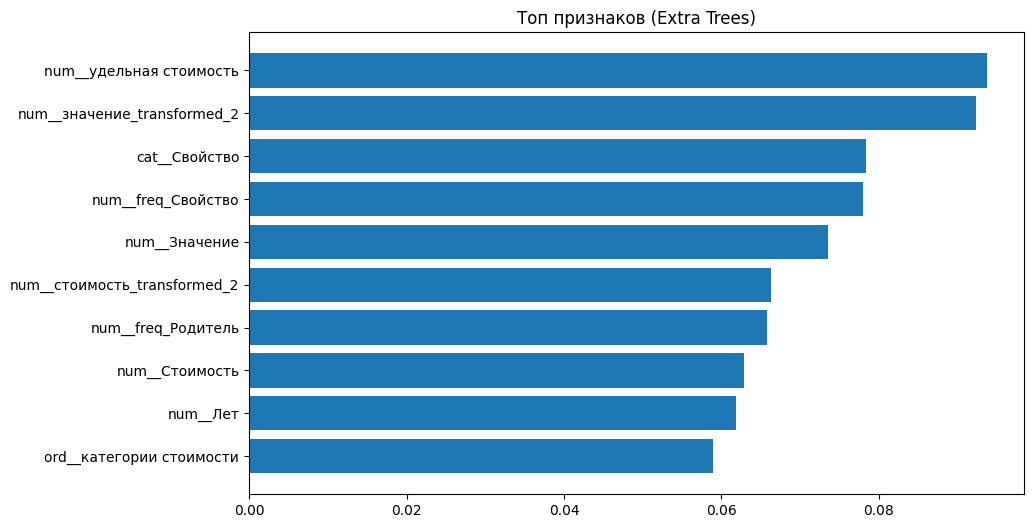

In [193]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [119]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,easy_ensemble,gaussian_noise,0.3645,0.015,0.840,0.155
1,easy_ensemble,ros_shrinkage_005,0.3492,0.015,0.790,0.154
0,easy_ensemble,ros,0.3416,0.006,3.802,0.155
3,easy_ensemble,ros_shrinkage_02,0.3340,0.011,0.795,0.151
2,easy_ensemble,ros_shrinkage_01,0.3321,0.017,0.784,0.154


In [283]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 12 candidates, totalling 24 fits


In [282]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'gini', 'model__estimator__splitter': 'best', 'model__replacement': True}
Лучшая CV accuracy: 0.36126785399400463
Test accuracy: 0.3530534351145038
Время: 29.72300696372986


In [ ]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='gini',
                                         splitter='random',
                                         random_state=123),
        replacement=False,
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": np.arange(50, 110, 10),
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.2, 1.2, 0.2),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 750 candidates, totalling 1500 fits


In [288]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(0.6000000000000001), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(8), 'model__n_estimators': np.int64(90)}
Лучшая CV accuracy: 0.36783165540971074
Test accuracy: 0.40458015267175573
Время: 154.158766746521


In [200]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,freq_Свойство,0.262087
13,Свойство,0.171756
2,Значение,0.034351
4,удельная стоимость,0.032443
7,значение_transformed_2,0.028626
10,freq_Родитель,0.020356
8,freq_Регион,0.015267
15,категории стоимости,0.014631
3,if_anomaly,0.011450
0,Лет,0.008906


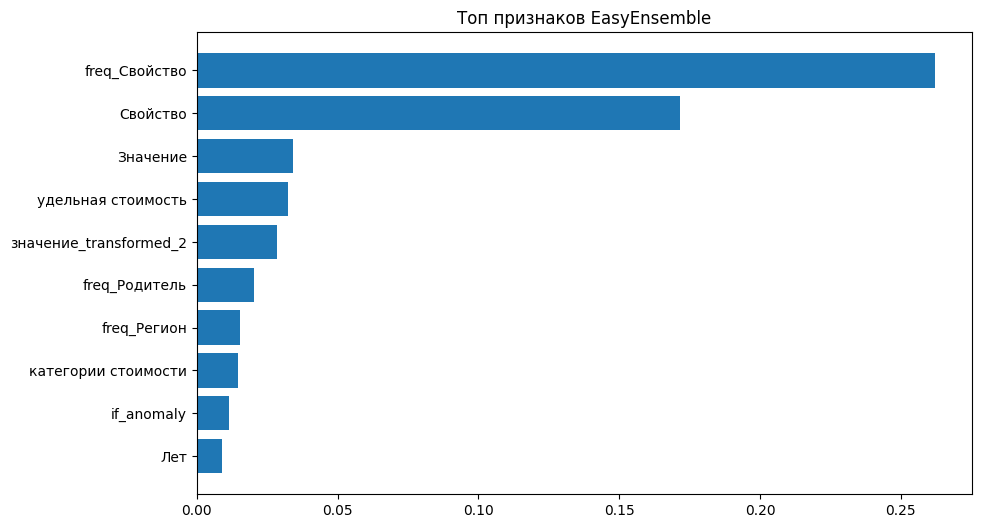

In [201]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [120]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,hgb,gaussian_noise,0.0935,0.010,1.263,0.012
2,hgb,ros_shrinkage_01,0.0916,0.011,1.444,0.013
1,hgb,ros_shrinkage_005,0.0878,0.011,1.410,0.011
0,hgb,ros,0.0859,0.006,1.421,0.013
3,hgb,ros_shrinkage_02,0.0821,0.011,1.402,0.012


In [216]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 3 candidates, totalling 15 fits


In [217]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.060204623970236515
Test accuracy: 0.08778625954198473
Время: 11.530162811279297


In [223]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': [100, 200, 300, 400, 500],
    'clf__learning_rate': [0.01, 0.1],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}

grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 150 candidates, totalling 300 fits


In [224]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__max_depth': None, 'clf__max_features': np.float64(0.2), 'clf__max_iter': 400, 'clf__min_samples_leaf': np.int64(5)}
Лучшая CV accuracy: 0.25965160075329563
Test accuracy: 0.26145038167938933
Время: 1547.569663286209


In [225]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,Свойство,0.077608
2,Значение,0.047710
4,удельная стоимость,0.036896
7,значение_transformed_2,0.031807
10,freq_Родитель,0.020992
1,Стоимость,0.009542
5,износ,0.008906
6,стоимость_transformed_2,0.006361
0,Лет,0.004453
8,freq_Регион,0.003817


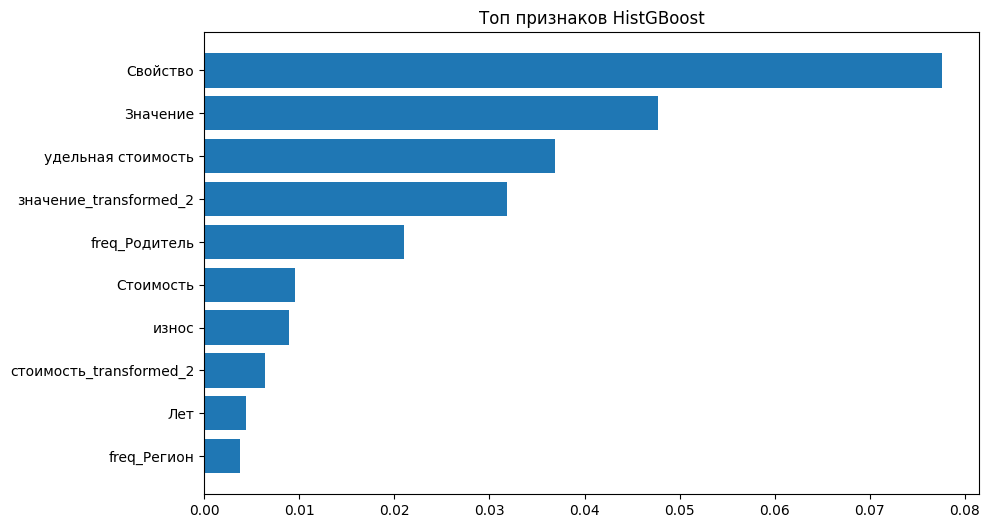

In [226]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [121]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,ada,ros_shrinkage_005,0.2176,0.011,0.681,0.001
3,ada,ros_shrinkage_02,0.2137,0.010,0.681,0.001
4,ada,gaussian_noise,0.2061,0.010,0.775,0.001
0,ada,ros,0.2004,0.005,0.108,0.001
2,ada,ros_shrinkage_01,0.1908,0.011,0.681,0.001


In [242]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.05)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 3 candidates, totalling 6 fits


In [243]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'gini', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.16651798988997918
Test accuracy: 0.22519083969465647
Время: 3.7325000762939453


In [244]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.05)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__estimator__min_samples_split': np.arange(2, 11, 2),
    'clf__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 125 candidates, totalling 250 fits


In [245]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(0.8), 'clf__estimator__min_samples_leaf': np.int64(7), 'clf__estimator__min_samples_split': np.int64(8)}
Лучшая CV accuracy: 0.25963213117539613
Test accuracy: 0.3053435114503817
Время: 184.22048592567444


In [255]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.05)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            max_features=0.8,
            max_depth=None,
            min_samples_leaf=7,
            min_samples_split=8,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(800, 1050, 50),
    'clf__learning_rate': [0.01, 0.1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 10 candidates, totalling 20 fits


In [256]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__n_estimators': np.int64(800)}
Лучшая CV accuracy: 0.25776305169703917
Test accuracy: 0.30916030534351147
Время: 886.5704801082611


In [257]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
13,cat__Свойство,0.123934
2,num__Значение,0.096299
10,num__freq_Родитель,0.095605
4,num__удельная стоимость,0.092721
14,cat__Округ,0.092037
0,num__Лет,0.084333
6,num__стоимость_transformed_2,0.078454
7,num__значение_transformed_2,0.073865
8,num__freq_Регион,0.060836
9,num__freq_Организация,0.053786


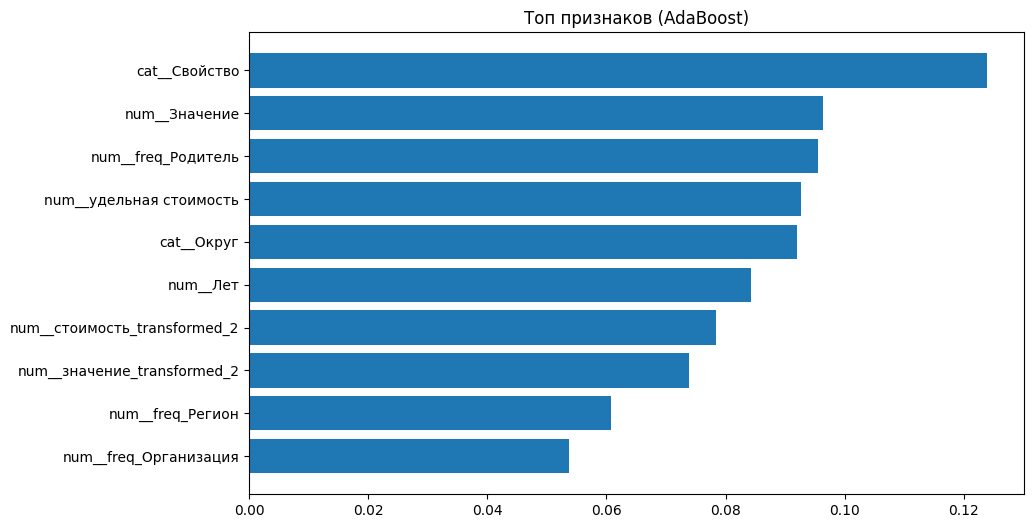

In [258]:
top_n = 10
top_features = feat_imp_ada.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (AdaBoost)")
plt.show()

### Keras (MLP)

In [122]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [123]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [124]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
  acc=0.2958 | t=9.4s
keras+ros_shrinkage_005
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
  acc=0.2748 | t=9.5s
keras+ros_shrinkage_01
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
  acc=0.2920 | t=9.9s
keras+ros_shrinkage_02
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
  acc=0.2882 | t=9.4s
keras+gaussian_noise
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
  acc=0.3073 | t=10.3s

Лучшая балансировка: gaussian_noise


In [267]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 3 folds for each of 9 candidates, totalling 27 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [268]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'relu', 'clf__model__optimizer': 'rmsprop'}
Лучшая CV accuracy: 0.2709238481737885
Test accuracy: 0.2748091603053435
Время: 886.5704801082611


In [269]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation='relu',
        model__optimizer='rmsprop',
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [128, 256, 512],
    "clf__model__learning_rate": [0.001, 0.005, 0.01],
    "clf__batch_size":           [64, 128, 256],
    "clf__epochs":               [50, 100, 200],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 2 folds for each of 81 candidates, totalling 162 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [64, 128, ...], 'clf__epochs': [50, 100, ...], 'clf__model__learning_rate': [0.001, 0.005, ...], 'clf__model__n_size': [128, 256, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [270]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 64, 'clf__epochs': 200, 'clf__model__learning_rate': 0.005, 'clf__model__n_size': 128}
Лучшая CV accuracy: 0.28692493946731235
Test accuracy: 0.3320610687022901
Время: 886.5704801082611


In [271]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
13,Свойство,0.226463
11,freq_Свойство,0.162214
7,значение_transformed_2,0.097964
15,категории стоимости,0.082697
14,Округ,0.077608
0,Лет,0.059796
10,freq_Родитель,0.059160
16,категории возраста,0.055344
12,freq_Округ,0.052799
8,freq_Регион,0.046438


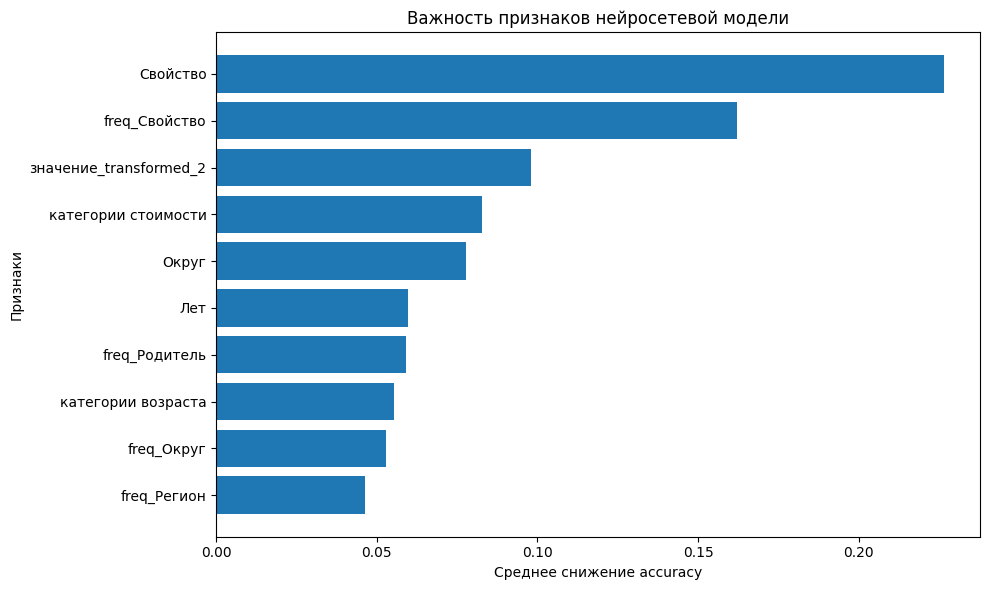

In [272]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

# Сценарий 2: предсказания первого этапа как новый признак

## Загрузка результатов предыдущего этапа

In [46]:
import pickle

with open('processed_full.pkl', 'rb') as f:
    processed_full = pickle.load(f)

with open('results_if_full.pkl', 'rb') as f:
    results_if_full = pickle.load(f)

print('Загружено')

Загружено


In [47]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

df_normal_enriched = processed_full['normal'].copy()

feature_cols_normal = [c for c in df_normal_enriched.columns if c != 'Наименование']
X_normal = df_normal_enriched[feature_cols_normal]
y_normal = df_normal_enriched['Наименование']

num_cols_n     = X_normal.select_dtypes(exclude=['object', 'category']).columns.tolist()
ordinal_cols_n = [c for c in ['категории стоимости', 'категории возраста'] if c in X_normal.columns]
nominal_cols_n = [c for c in X_normal.select_dtypes(include=['object', 'category']).columns
                  if c not in ordinal_cols_n]

preprocessor_normal = ColumnTransformer([
    ('num', 'passthrough', num_cols_n),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_n),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols_n)
])

In [48]:
from imblearn.pipeline import Pipeline

pipe_rf_normal = Pipeline([
    ('preprocessor', preprocessor_normal),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='entropy',
        n_estimators=100,
        max_depth=None,
        max_features=0.4,
        max_samples=1.0,
        min_samples_leaf=1,
        min_samples_split=6,
        random_state=123,
        n_jobs=-1
    ))
])

print('[normal] Генерация OOF предсказаний...')
oof_preds_normal = cross_val_predict(
    pipe_rf_normal,
    X_normal,
    y_normal,
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

df_normal_enriched['pred_Наименование'] = oof_preds_normal

print(
    f'[normal] OOF accuracy: '
    f'{accuracy_score(y_normal, oof_preds_normal):.4f}'
)

[normal] Генерация OOF предсказаний...


[normal] OOF accuracy: 0.6597


In [49]:
df_rare_enriched = processed_full['rare'].copy()

feature_cols_rare = [c for c in df_rare_enriched.columns if c != 'Наименование']
X_rare = df_rare_enriched[feature_cols_rare]
y_rare = df_rare_enriched['Наименование']

num_cols_r     = X_rare.select_dtypes(exclude=['object', 'category']).columns.tolist()
ordinal_cols_r = [c for c in ['категории стоимости', 'категории возраста'] if c in X_rare.columns]
nominal_cols_r = [c for c in X_rare.select_dtypes(include=['object', 'category']).columns
                  if c not in ordinal_cols_r]

preprocessor_rare = ColumnTransformer([
    ('num', 'passthrough', num_cols_r),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_r),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols_r)
])

In [50]:
from imblearn.pipeline import Pipeline

pipe_rf_rare = Pipeline([
    ('preprocessor', preprocessor_rare),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', RandomForestClassifier(
        criterion='gini',
        n_estimators=350,
        max_depth=None,
        max_features=0.4,
        max_samples=1.0,
        min_samples_leaf=1,
        min_samples_split=4,
        random_state=123,
        n_jobs=-1
    ))
])

print('[rare] Генерация OOF предсказаний...')
oof_preds_rare = cross_val_predict(
    pipe_rf_rare,
    X_rare,
    y_rare,
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

df_rare_enriched['pred_Наименование'] = oof_preds_rare

print(
    f'[rare] OOF accuracy: '
    f'{accuracy_score(y_rare, oof_preds_rare):.4f}'
)

[rare] Генерация OOF предсказаний...


[rare] OOF accuracy: 0.4152


In [51]:
print('\nИтого')
print(f'  normal | OOF accuracy: {accuracy_score(y_normal, oof_preds_normal):.4f}')
print(f'  rare   | OOF accuracy: {accuracy_score(y_rare,   oof_preds_rare):.4f}')


Итого
  normal | OOF accuracy: 0.6597
  rare   | OOF accuracy: 0.4152


In [52]:
for split_name, y_true, y_pred in [
    ('normal', y_normal, oof_preds_normal),
    ('rare',   y_rare,   oof_preds_rare)
]:
    matched = (y_true.values == y_pred).sum()
    total   = len(y_true)

    print(
        f'\n[{split_name}]'
    )
    print(
        f'  Всего наблюдений:          '
        f'{total}'
    )
    print(
        f'  Совпавших наблюдений:      '
        f'{matched}'
    )
    print(
        f'  Несовпавших наблюдений:    '
        f'{total - matched}'
    )
    print(
        f'  Доля совпадений:           '
        f'{matched / total:.2%}'
    )


[normal]
  Всего наблюдений:          11021
  Совпавших наблюдений:      7271
  Несовпавших наблюдений:    3750
  Доля совпадений:           65.97%

[rare]
  Всего наблюдений:          1587
  Совпавших наблюдений:      659
  Несовпавших наблюдений:    928
  Доля совпадений:           41.52%


In [53]:
def run_experiment(model, model_name, preprocessor, balancers_dict,
                   X_train, X_test, y_train, y_test):
    
    results = []

    for bal_name, bal_func in balancers_dict.items():
        print(f"Запуск: {model_name} + {bal_name}")
        
        try:
            if preprocessor is not None:
                X_train_prep = preprocessor.fit_transform(X_train, y_train)
                X_test_prep = preprocessor.transform(X_test)

                if hasattr(X_train_prep, "toarray"):
                    X_train_prep = X_train_prep.toarray()
                    X_test_prep = X_test_prep.toarray()
            else:
                X_train_prep = X_train.copy()
                X_test_prep = X_test.copy()

            start_bal = time.time()
            X_train_bal, y_train_bal = bal_func.fit_resample(X_train_prep, y_train)
            bal_time = time.time() - start_bal

            start_train = time.time()
            model.fit(X_train_bal, y_train_bal)
            train_time = time.time() - start_train

            start_pred = time.time()
            y_pred = model.predict(X_test_prep)
            pred_time = time.time() - start_pred

            acc = accuracy_score(y_test, y_pred)

            results.append({
                "model": model_name,
                "balancing": bal_name,
                "accuracy": round(acc, 4),
                "balancing_time_sec": round(bal_time, 3),
                "train_time_sec": round(train_time, 3),
                "predict_time_sec": round(pred_time, 3)
            })

        except Exception as e:
            print(f"Ошибка в {model_name} + {bal_name}: {e}")
            continue

    return pd.DataFrame(results).sort_values(by="accuracy", ascending=False)

In [54]:
class GaussianNoiseSampler(BaseEstimator):
    def __init__(self, noise_level=0.05, random_state=123):
        self.noise_level = noise_level
        self.random_state = random_state

    def fit_resample(self, X, y):
        rng = np.random.default_rng(self.random_state)

        X = np.asarray(X)
        y = np.asarray(y)

        X_res = X.copy()
        y_res = y.copy()

        classes, counts = np.unique(y, return_counts=True)
        max_count = counts.max()

        for cls, count in zip(classes, counts):
            X_cls = X[y == cls]
            n_to_add = max_count - count

            if n_to_add <= 0:
                continue

            mean = X_cls.mean(axis=0)
            std = X_cls.std(axis=0)
            std = np.where(std == 0, 1e-8, std)

            X_new = rng.normal(
                loc=mean,
                scale=std * self.noise_level,
                size=(n_to_add, X.shape[1])
            )

            y_new = np.full(n_to_add, cls)

            X_res = np.vstack([X_res, X_new])
            y_res = np.concatenate([y_res, y_new])

        return X_res, y_res

In [55]:
balancers = {
    "ros": RandomOverSampler(random_state=123),
    "ros_shrinkage_005": RandomOverSampler(random_state=123, shrinkage=0.05),
    "ros_shrinkage_01": RandomOverSampler(random_state=123, shrinkage=0.1),
    "ros_shrinkage_02": RandomOverSampler(random_state=123, shrinkage=0.2),
    "gaussian_noise": GaussianNoiseSampler(noise_level=0.05, random_state=123),
}

## Нормальные классы

In [68]:
target_col = "Наименование"

class_counts = df_normal_enriched['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
df_normal_enriched['Наименование'] = df_normal_enriched['Наименование'].where(
    ~df_normal_enriched['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(df_normal_enriched['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 0
Объектов с меткой 'редкий': 66


In [69]:
X = df_normal_enriched.drop(columns=[target_col])
y = df_normal_enriched[target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.3,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (7714, 19) y_train: (7714,)
X_test: (3307, 19) y_test: (3307,)


In [70]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [71]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация',
       'freq_ед. изм.', 'freq_Округ', 'Родитель', 'Свойство',
       'категории стоимости', 'категории возраста', 'pred_Наименование']

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация',
       'freq_ед. изм.', 'freq_Округ']
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Родитель', 'Свойство', 'pred_Наименование']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [37]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,svm,gaussian_noise,0.6299,12.317,78.804,26.958
1,svm,ros_shrinkage_005,0.6030,1.238,109.579,87.217
0,svm,ros,0.6018,0.426,88.648,54.033
2,svm,ros_shrinkage_01,0.5999,1.134,115.491,88.821
3,svm,ros_shrinkage_02,0.5981,1.148,129.649,91.671


In [214]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 8 candidates, totalling 32 fits


In [215]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'rbf'}
Лучшая CV accuracy: 0.6199120246983689
Время (сек): 506.9819972515106
Test accuracy: 0.6298760205624433


In [266]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),  
    ('clf', SVC(
        kernel='rbf',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': [1, 10, 100],
    'clf__gamma': [1e-1, 1e-2, 1e-3],
    'clf__tol': [1e-1, 1e-2, 1e-3],          
    'clf__max_iter': np.arange(100, 300, 100)
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 54 candidates, totalling 108 fits


In [270]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)

y_pred_test = grid_svm2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred_test))
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': 10, 'clf__gamma': 0.01, 'clf__max_iter': np.int64(100), 'clf__tol': 0.01}
Лучшая CV accuracy: 0.6096707285455016
Test accuracy: 0.6277592984578168
Время обучения (сек): 1635.7793910503387


In [271]:
pipe = grid_svm2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=8
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
})

feat_imp = feat_imp.sort_values(
    "importance",
    ascending=False
)

feat_imp.head(10)

,feature,importance
12,freq_ед. изм.,0.168229
11,freq_Свойство,0.154622
15,Свойство,0.128011
18,pred_Наименование,0.125592
7,значение_transformed_2,0.052716
0,Лет,0.018446
16,категории стоимости,0.016934
10,freq_Родитель,0.016430
6,стоимость_transformed_2,0.014011
1,Стоимость,0.011894


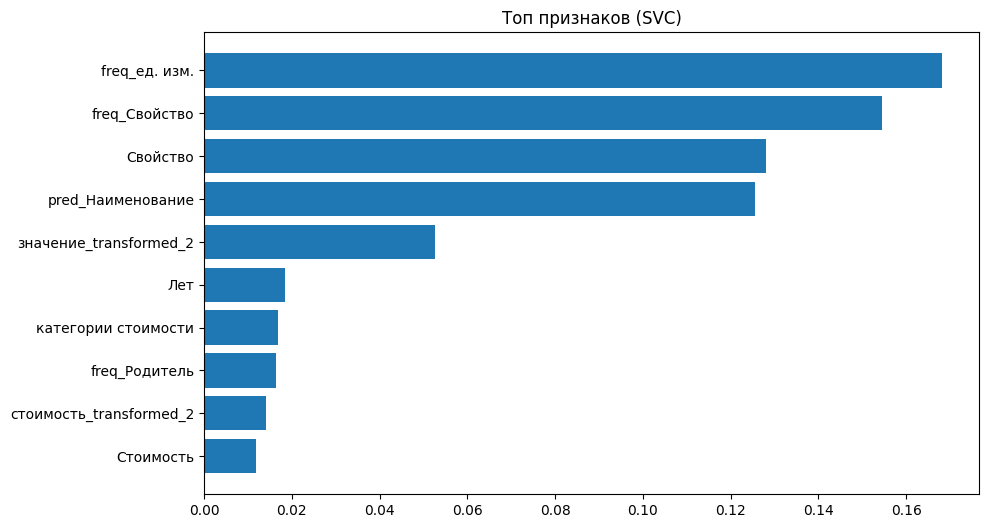

In [272]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [22]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,knn,gaussian_noise,0.5458,13.197,0.058,0.777
0,knn,ros,0.5379,0.211,0.078,0.824
1,knn,ros_shrinkage_005,0.5259,1.303,0.069,0.824
3,knn,ros_shrinkage_02,0.5252,1.188,0.063,0.851
2,knn,ros_shrinkage_01,0.5228,1.232,0.060,0.783


In [274]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=6))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [275]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'distance'}
Лучшая CV accuracy: 0.5304640912626393
Test accuracy: 0.5703054127608104
Время: 93.80732369422913


In [277]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='distance',
        algorithm='auto',
        n_jobs=6
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(5, 35, 5),
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__leaf_size': np.arange(5, 35, 5)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 72 candidates, totalling 144 fits


In [278]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(5), 'clf__metric': 'manhattan', 'clf__n_neighbors': np.int64(5)}
Лучшая CV accuracy: 0.54705729841846
Test accuracy: 0.5878439673420018
Время: 854.5404870510101


In [279]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=6
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
18,pred_Наименование,0.098982
15,Свойство,0.066022
7,значение_transformed_2,0.032658
16,категории стоимости,0.019655
11,freq_Свойство,0.015825
12,freq_ед. изм.,0.015422
6,стоимость_transformed_2,0.007862
1,Стоимость,0.005040
3,if_anomaly,0.003024
5,износ,0.002016


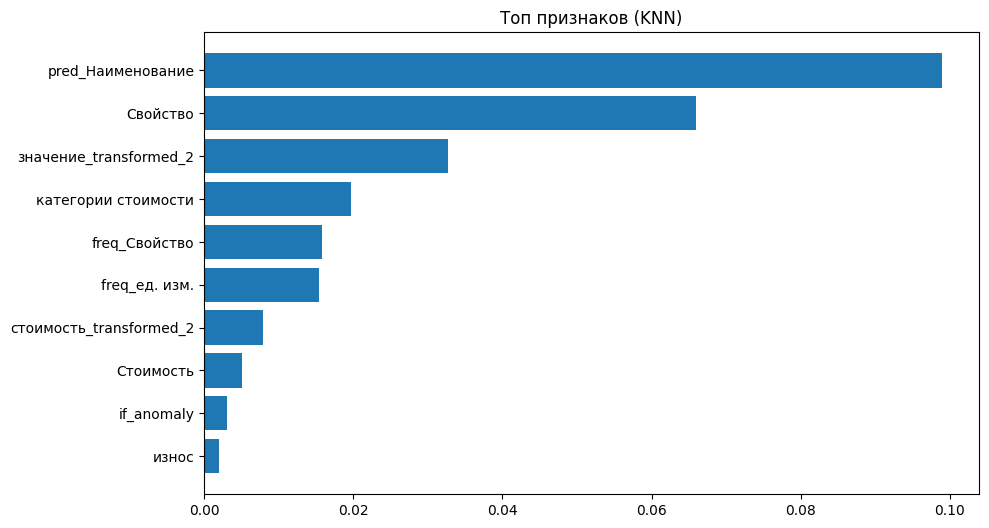

In [280]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [23]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,tree,ros_shrinkage_02,0.6021,0.070,12.681,0.003
0,tree,ros,0.6015,0.021,1.158,0.002
4,tree,gaussian_noise,0.5981,0.403,18.894,0.003
1,tree,ros_shrinkage_005,0.5897,0.060,13.210,0.003
2,tree,ros_shrinkage_01,0.5872,0.059,13.459,0.003


In [289]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 6 candidates, totalling 30 fits


In [290]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.5837425703125196
Test accuracy: 0.6014514665860297
Время: 3.17331600189209


In [299]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123)),
    ('clf', DecisionTreeClassifier(
        criterion='gini',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': np.arange(50, 72, 2),
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 10, 2)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 1375 candidates, totalling 6875 fits




In [300]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': np.int64(60), 'clf__max_features': np.float64(0.8), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4)}
Лучшая CV accuracy: 0.584002057742888
Test accuracy: 0.5947989114000605
Время: 515.6306819915771


In [301]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
18,cat__pred_Наименование,0.131142
4,num__удельная стоимость,0.113388
7,num__значение_transformed_2,0.087758
1,num__Стоимость,0.077987
6,num__стоимость_transformed_2,0.063639
5,num__износ,0.063041
10,num__freq_Родитель,0.061866
0,num__Лет,0.060028
2,num__Значение,0.059115
17,cat__Свойство,0.056255


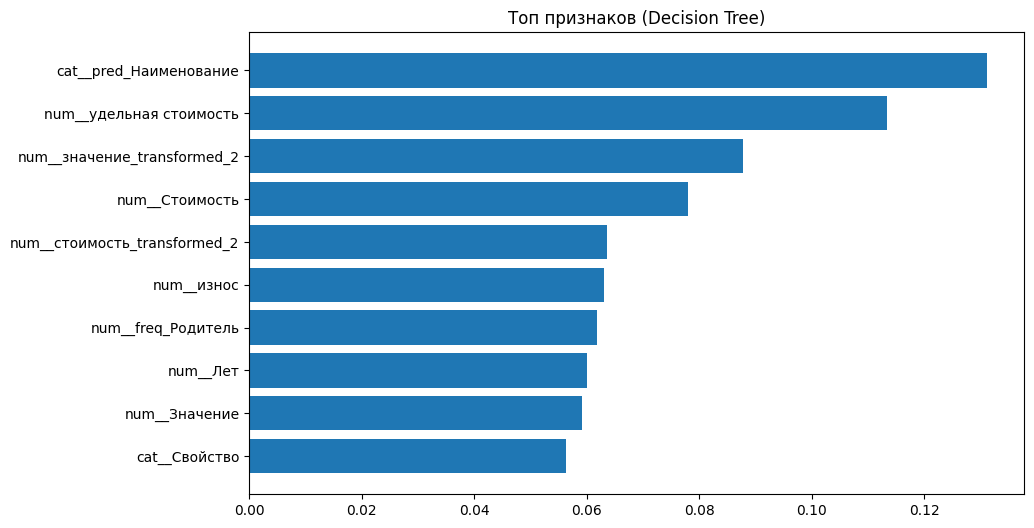

In [302]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [24]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
2,rf,ros_shrinkage_01,0.6571,0.059,19.089,0.173
1,rf,ros_shrinkage_005,0.6568,0.057,19.229,0.190
4,rf,gaussian_noise,0.6562,0.450,20.356,0.076
3,rf,ros_shrinkage_02,0.6538,0.059,19.547,0.273
0,rf,ros,0.6489,0.024,2.775,0.138


In [135]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.1)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=8
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 3 candidates, totalling 9 fits


In [136]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'entropy'}
Лучшая CV accuracy: 0.6302808935410092
Test accuracy: 0.6483217417599032
Время: 115.97198987007141


In [72]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.1)),
    ('clf', RandomForestClassifier(
        criterion='entropy',
        random_state=123,
        n_jobs=8
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': [50, 100, 200],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.25, 1.25, 0.25),
    'clf__max_samples': np.arange(0.25, 1.25, 0.25),
    'clf__min_samples_split': np.arange(2, 9, 2),
    'clf__min_samples_leaf': np.arange(1, 8, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 768 candidates, totalling 2304 fits


In [73]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.25), 'clf__max_samples': np.float64(0.5), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4), 'clf__n_estimators': 200}
Лучшая CV accuracy: 0.6326143133757128
Test accuracy: 0.6510432416087087
Время: 50922.821521282196


In [74]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
11,num__freq_Свойство,0.125189
12,num__freq_ед. изм.,0.114816
17,cat__Свойство,0.107568
18,cat__pred_Наименование,0.105584
2,num__Значение,0.075294
7,num__значение_transformed_2,0.061296
4,num__удельная стоимость,0.058074
0,num__Лет,0.049982
1,num__Стоимость,0.043311
10,num__freq_Родитель,0.040776


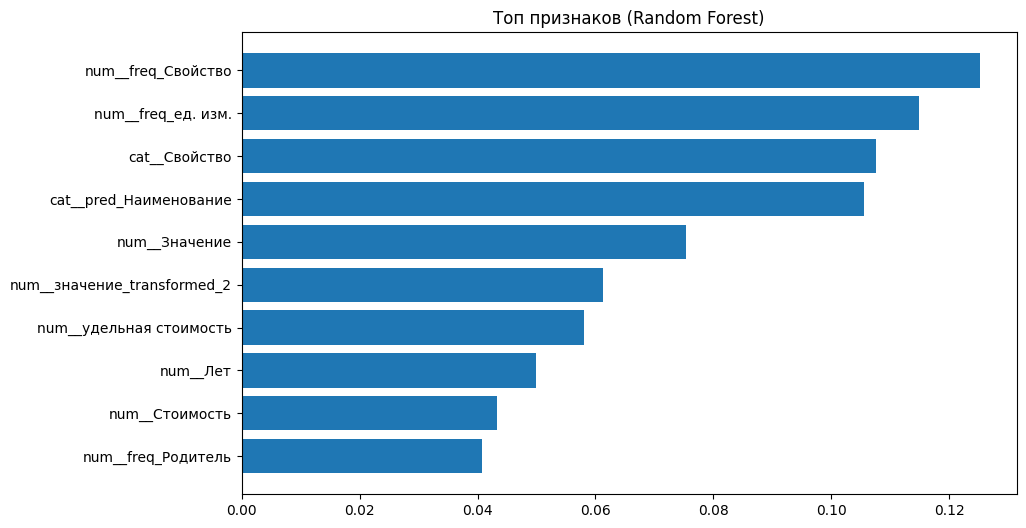

In [75]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [36]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rtf,ros,0.6501,0.054,51.535,1.414
4,rtf,gaussian_noise,0.6477,0.279,510.409,1.479
1,rtf,ros_shrinkage_005,0.6362,0.060,452.010,2.160
2,rtf,ros_shrinkage_01,0.6347,0.067,458.994,1.794
3,rtf,ros_shrinkage_02,0.6320,0.058,444.776,1.995


In [252]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=6,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best", 'random'],
    "model__pca_solver": ["auto", "full", 'randomized'],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 18 candidates, totalling 54 fits


In [264]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'gini', 'model__base_estimator__splitter': 'best', 'model__pca_solver': 'randomized'}
Лучшая CV accuracy: 0.6258738604351806
Test accuracy: 0.6452978530390082
Время: 5776.444843053818


In [320]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=6,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.25, 1.25, 0.25), 
    'model__base_estimator__min_samples_split': np.arange(2, 9, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 8, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 64 candidates, totalling 192 fits


In [321]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(0.5), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(4)}
Лучшая CV accuracy: 0.6271706248604939
Test accuracy: 0.6456002419110977
Время: 4130.1132180690765


In [322]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='best',
                                              max_features=0.5,
                                              max_depth=None,
                                              min_samples_leaf=1,
                                              min_samples_split=4,
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=6,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": [50, 100, 200, 300],
    "model__min_group": [1, 2, 3],
    "model__max_group": [1, 2, 3],
    "model__remove_proportion": np.arange(0.25, 1.25, 0.25),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 144 candidates, totalling 432 fits


In [ ]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 2, 'model__min_group': 1, 'model__n_estimators': 300, 'model__remove_proportion': np.float64(1.0)}
Лучшая CV accuracy: 0.6313189099859481
Test accuracy: 0.6543695192016934
Время: 3653.390116930008


In [22]:
pipe = pipe_rtf3

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=6
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
15,Свойство,0.273964
12,freq_ед. изм.,0.189598
18,pred_Наименование,0.074488
11,freq_Свойство,0.067130
4,удельная стоимость,0.026711
7,значение_transformed_2,0.023183
10,freq_Родитель,0.018043
2,Значение,0.009374
0,Лет,0.007862
1,Стоимость,0.007157


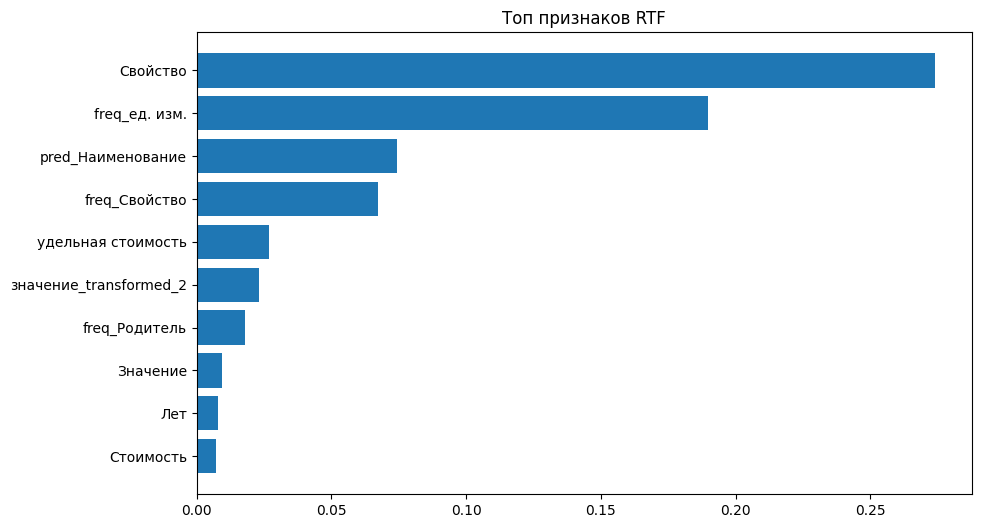

In [23]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [25]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,extra,ros,0.6456,0.023,0.866,0.111
4,extra,gaussian_noise,0.6453,0.683,1.243,0.241
1,extra,ros_shrinkage_005,0.6377,0.060,0.941,0.215
2,extra,ros_shrinkage_01,0.6332,0.063,1.288,0.262
3,extra,ros_shrinkage_02,0.6329,0.058,2.219,0.840


In [305]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 6 candidates, totalling 18 fits


In [306]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': False, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.6222444827147476
Test accuracy: 0.6456002419110977
Время: 16.148417949676514


In [307]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=False,
        n_jobs=8,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None],
    'model__max_features': np.arange(0.25, 1.25, 0.25),
    'model__max_samples': [None],
    'model__min_samples_split': np.arange(2, 9, 2),
    'model__min_samples_leaf': np.arange(1, 8, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 192 candidates, totalling 576 fits


In [308]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(1.0), 'model__max_samples': None, 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(2), 'model__n_estimators': 200}
Лучшая CV accuracy: 0.6289853389250722
Test accuracy: 0.6486241306319928
Время: 900.5549771785736


In [309]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
18,cat__pred_Наименование,0.142872
7,num__значение_transformed_2,0.076016
4,num__удельная стоимость,0.066855
0,num__Лет,0.064973
2,num__Значение,0.060737
1,num__Стоимость,0.055116
14,ord__категории стоимости,0.055095
10,num__freq_Родитель,0.054381
6,num__стоимость_transformed_2,0.051612
17,cat__Свойство,0.050999


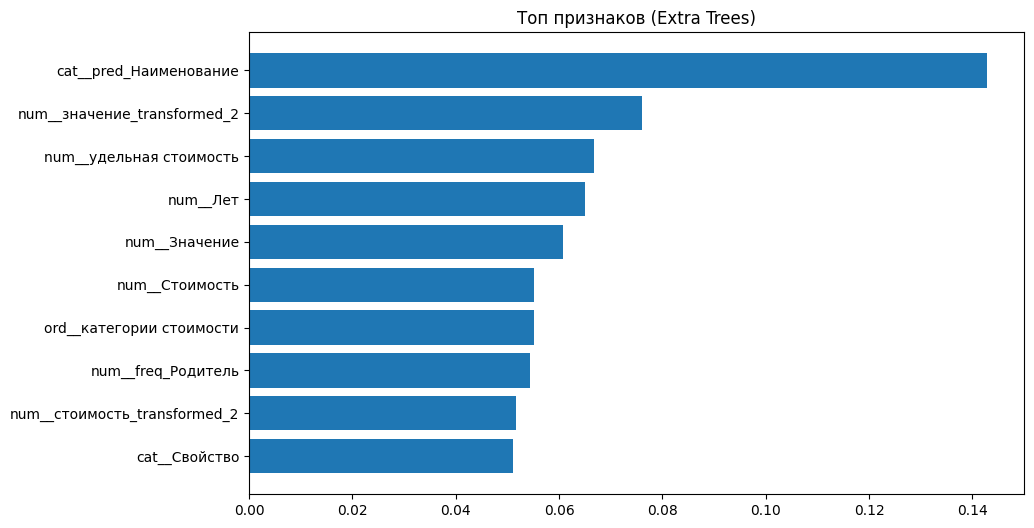

In [310]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [26]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,easy_ensemble,ros_shrinkage_02,0.6051,0.060,15.193,0.389
0,easy_ensemble,ros,0.6021,0.023,3.921,0.349
4,easy_ensemble,gaussian_noise,0.6005,0.287,22.897,0.341
1,easy_ensemble,ros_shrinkage_005,0.5930,0.059,15.649,0.373
2,easy_ensemble,ros_shrinkage_01,0.5872,0.060,15.982,0.386


In [311]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.2)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=8
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 12 candidates, totalling 24 fits


In [312]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'entropy', 'model__estimator__splitter': 'random', 'model__replacement': False}
Лучшая CV accuracy: 0.5995592429349235
Test accuracy: 0.6335046870275174
Время: 65.05453109741211


In [316]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.2)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='entropy',
                                         splitter='random',
                                         random_state=123),
        replacement=False,
        random_state=123,
        n_jobs=6
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": [150, 200, 250],
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.25, 1.25, 0.25),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 8, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 240 candidates, totalling 480 fits


In [317]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(1.0), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(8), 'model__n_estimators': 250}
Лучшая CV accuracy: 0.6092818252527872
Test accuracy: 0.6292712428182643
Время: 998.5730650424957


In [318]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=6
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,freq_Свойство,0.190606
15,Свойство,0.113497
18,pred_Наименование,0.101703
12,freq_ед. изм.,0.077714
16,категории стоимости,0.064207
7,значение_transformed_2,0.044350
10,freq_Родитель,0.015220
17,категории возраста,0.013305
9,freq_Организация,0.012297
4,удельная стоимость,0.009072


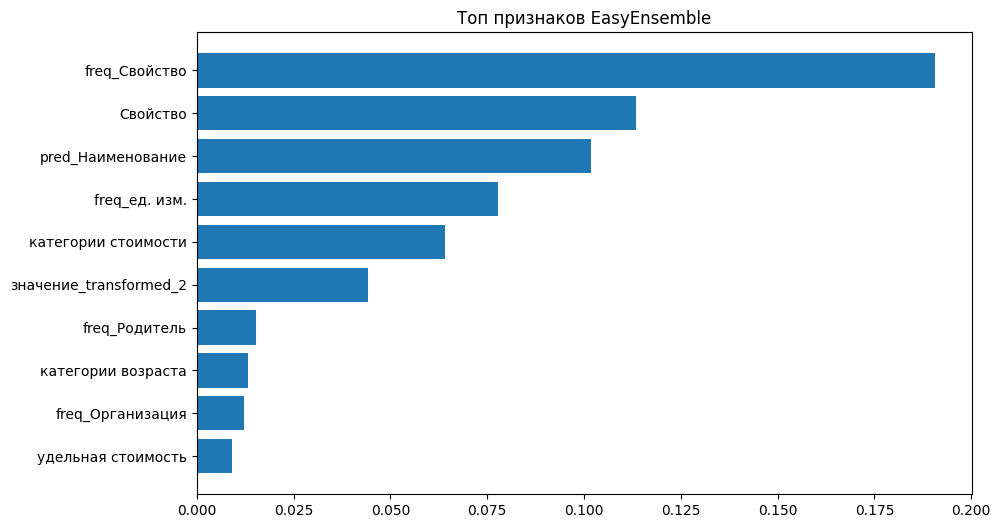

In [319]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [31]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,hgb,ros_shrinkage_005,0.3450,0.058,9.523,0.069
3,hgb,ros_shrinkage_02,0.3012,0.056,8.297,0.068
2,hgb,ros_shrinkage_01,0.3000,0.057,8.310,0.046
0,hgb,ros,0.2731,0.019,7.537,0.047
4,hgb,gaussian_noise,0.1388,0.204,3.265,0.027


In [222]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.05)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 3 candidates, totalling 15 fits


In [223]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.2873998552519096
Test accuracy: 0.3274871484729362
Время: 13.320917844772339


In [ ]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.05)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': [100, 200, 300, 400, 500],
    'clf__learning_rate': [0.01, 0.1],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}

grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 150 candidates, totalling 300 fits


In [259]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__max_depth': None, 'clf__max_features': np.float64(0.2), 'clf__max_iter': 500, 'clf__min_samples_leaf': np.int64(1)}
Лучшая CV accuracy: 0.5688358828104745
Test accuracy: 0.6053825219231932
Время: 5776.444843053818


In [261]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=6
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
10,freq_ед. изм.,0.316500
13,Свойство,0.111682
2,Значение,0.105231
4,удельная стоимость,0.089608
16,pred_Наименование,0.086282
7,значение_transformed_2,0.064006
8,freq_Регион,0.031549
1,Стоимость,0.029332
0,Лет,0.027820
5,износ,0.024897


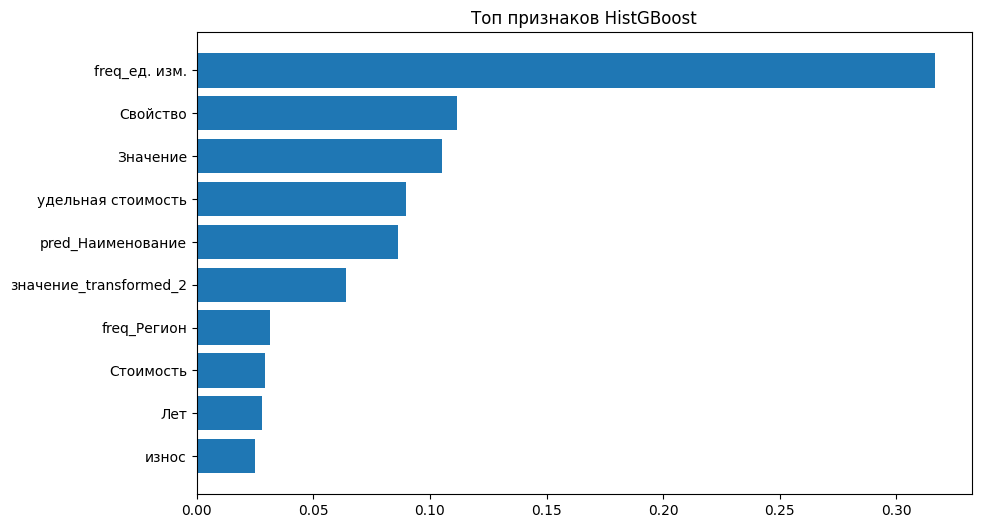

In [262]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [32]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,ada,gaussian_noise,0.5337,0.232,14.184,0.006
2,ada,ros_shrinkage_01,0.5252,0.053,11.816,0.006
0,ada,ros,0.5228,0.021,1.212,0.006
1,ada,ros_shrinkage_005,0.5222,0.050,12.614,0.006
3,ada,ros_shrinkage_02,0.5207,0.051,12.842,0.006


In [242]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best', 'random'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 6 candidates, totalling 18 fits


In [243]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'log_loss', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.5128354221700391
Test accuracy: 0.5340187481100696
Время: 22.73473286628723


In [254]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='log_loss',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.25, 1.25, 0.25),
    'clf__estimator__min_samples_split': np.arange(2, 9, 2),
    'clf__estimator__min_samples_leaf': np.arange(1, 8, 2)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 64 candidates, totalling 128 fits


In [263]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(1.0), 'clf__estimator__min_samples_leaf': np.int64(1), 'clf__estimator__min_samples_split': np.int64(4)}
Лучшая CV accuracy: 0.5788177339901477
Test accuracy: 0.6123374659812519
Время: 5776.444843053818


In [24]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='log_loss',
            splitter='best',
            max_features=1.0,
            max_depth=None,
            min_samples_leaf=1,
            min_samples_split=4,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(100, 400, 100),
    'clf__learning_rate': [0.01, 0.1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [25]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.1, 'clf__n_estimators': np.int64(300)}
Лучшая CV accuracy: 0.5885403163080114
Test accuracy: 0.6241306319927427
Время: 7582.6039481163025


### Keras (MLP)

In [33]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [34]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [35]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 478us/step
  acc=0.5975 | t=101.9s
keras+ros_shrinkage_005
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 478us/step
  acc=0.5993 | t=102.8s
keras+ros_shrinkage_01
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 475us/step
  acc=0.5878 | t=101.6s
keras+ros_shrinkage_02
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 481us/step
  acc=0.5984 | t=101.2s
keras+gaussian_noise
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 475us/step
  acc=0.6135 | t=100.3s

Лучшая балансировка: gaussian_noise


In [247]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)

Fitting 2 folds for each of 9 candidates, totalling 18 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__model__activation': ['relu', 'tanh', ...], 'clf__model__optimizer': ['adam', 'sgd', ...]}"
,scoring,'accuracy'
,n_jobs,6
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [248]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'tanh', 'clf__model__optimizer': 'rmsprop'}
Лучшая CV accuracy: 0.591521908218823
Test accuracy: 0.6235258542485637
Время: 22.73473286628723


In [255]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation='tanh',
        model__optimizer='rmsprop',
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [64, 128, 256],
    "clf__model__learning_rate": [0.01, 0.2],
    "clf__batch_size":           [32, 64, 128],
    "clf__epochs":               [50, 100, 200],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)

Fitting 2 folds for each of 54 candidates, totalling 108 fits


,estimator,Pipeline(step... verbose=0))])
,param_grid,"{'clf__batch_size': [32, 64, ...], 'clf__epochs': [50, 100, ...], 'clf__model__learning_rate': [0.01, 0.2], 'clf__model__n_size': [64, 128, ...]}"
,scoring,'accuracy'
,n_jobs,6
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [256]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 32, 'clf__epochs': 200, 'clf__model__learning_rate': 0.01, 'clf__model__n_size': 64}
Лучшая CV accuracy: 0.6007259528130671
Test accuracy: 0.6274569095857272
Время: 5776.444843053818


In [257]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
18,pred_Наименование,0.429695
15,Свойство,0.250176
12,freq_ед. изм.,0.201391
11,freq_Свойство,0.157746
14,Родитель,0.037597
1,Стоимость,0.018547
10,freq_Родитель,0.015825
16,категории стоимости,0.015523
0,Лет,0.014212
7,значение_transformed_2,0.012096


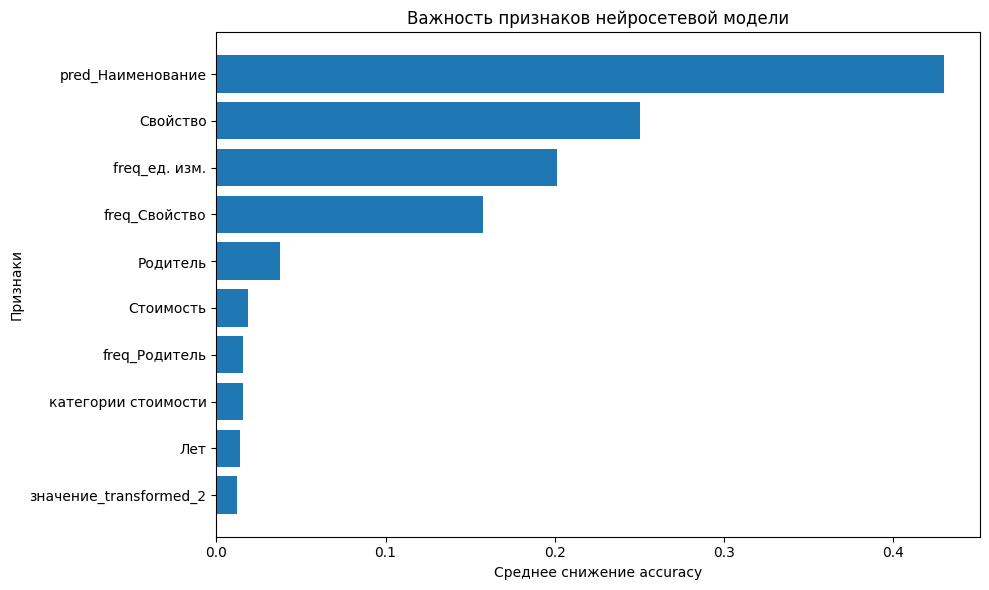

In [258]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

## Редкие классы

In [76]:
target_col = "Наименование"

class_counts = df_rare_enriched['Наименование'].value_counts()
singleton_classes = class_counts[class_counts == 1].index
df_rare_enriched['Наименование'] = df_rare_enriched['Наименование'].where(
    ~df_rare_enriched['Наименование'].isin(singleton_classes), other='редкий'
)

print(f"Единичных классов заменено: {len(singleton_classes)}")
print(f"Объектов с меткой 'редкий': {(df_rare_enriched['Наименование'] == 'редкий').sum()}")

Единичных классов заменено: 0
Объектов с меткой 'редкий': 87


In [77]:
X = df_rare_enriched.drop(columns=[target_col])
y = df_rare_enriched[target_col]

cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.33,
    stratify=y_encoded,
    random_state=123
)

print("Размеры выборок:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Размеры выборок:
X_train: (1063, 18) y_train: (1063,)
X_test: (524, 18) y_test: (524,)


In [78]:
missing_in_test = set(y_train) - set(y_test)
missing_in_train = set(y_test) - set(y_train)

print("Нет в test:", missing_in_test)
print("Нет в train:", missing_in_train)

Нет в test: set()
Нет в train: set()


In [80]:
X_test.columns

Index(['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация', 'freq_Родитель', 'freq_Свойство',
       'freq_Округ', 'Свойство', 'Округ', 'категории стоимости',
       'категории возраста', 'pred_Наименование'],
      dtype='object')

In [81]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cols = ["категории стоимости", "категории возраста"]
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]

preprocessor_linear = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
        ), cat_cols)
    ])

preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('ord', OrdinalEncoder(
        categories=[
            ["очень низкая", "низкая", "средняя", "высокая", "очень высокая"],
            ["новое", "среднее", "старое", "очень старое"]
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols),
    ('cat', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), nominal_cols)
])

feature_cols = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация', 'freq_Родитель',
       'Свойство', 'Округ', 'категории стоимости',
       'категории возраста', 'pred_Наименование']

num_cols_boost      = ['Лет', 'Стоимость', 'Значение', 'if_anomaly', 'удельная стоимость',
       'износ', 'стоимость_transformed_2', 'значение_transformed_2',
       'freq_Регион', 'freq_Организация', 'freq_Родитель']
ordinal_cols_boost  = ['категории стоимости', 'категории возраста']
nominal_cols_boost  = ['Свойство', 'Округ', 'pred_Наименование']

preprocessor_boost = ColumnTransformer([
    ('num', 'passthrough', num_cols_boost),
    ('ord', OrdinalEncoder(
        categories=[
            ['очень низкая', 'низкая', 'средняя', 'высокая', 'очень высокая'],
            ['новое', 'среднее', 'старое', 'очень старое']
        ],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_cols_boost),
    ('cat', CatBoostEncoder(sigma=0.1), nominal_cols_boost)
])

### SVC

In [22]:
svm_model = SVC(random_state=123)

svm_results = run_experiment(
    svm_model,
    "svm",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

svm_results

Запуск: svm + ros
Запуск: svm + ros_shrinkage_005
Запуск: svm + ros_shrinkage_01
Запуск: svm + ros_shrinkage_02
Запуск: svm + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,svm,ros,0.3168,0.010,1.943,0.617
3,svm,ros_shrinkage_02,0.3130,0.061,2.674,0.933
1,svm,ros_shrinkage_005,0.3111,0.065,2.362,0.938
2,svm,ros_shrinkage_01,0.3092,0.062,2.444,0.927
4,svm,gaussian_noise,0.3092,0.342,1.758,0.569


In [17]:
from imblearn.pipeline import Pipeline

pipe_svm1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123)),  
    ('clf', SVC(random_state=123))
])

param_svm_grid1 = {
    'clf__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'clf__decision_function_shape': ['ovo', 'ovr']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm1 = GridSearchCV(
    pipe_svm1,
    param_grid=param_svm_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [18]:
print("Лучшие параметры:", grid_svm1.best_params_)
print("Лучшая CV accuracy:", grid_svm1.best_score_)
print("Время (сек):", elapsed_time)

test_acc = grid_svm1.score(X_test, y_test)
print("Test accuracy:", test_acc)

Лучшие параметры: {'clf__decision_function_shape': 'ovo', 'clf__kernel': 'linear'}
Лучшая CV accuracy: 0.28504170029593756
Время (сек): 7.09767484664917
Test accuracy: 0.3377862595419847


In [29]:
from imblearn.pipeline import Pipeline

pipe_svm2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', RandomOverSampler(random_state=123)),  
    ('clf', SVC(
        kernel='linear',
        decision_function_shape='ovo',
        random_state=123
    ))
])

param_svm2 = {
    'clf__C': [0.1, 1, 10],    
    'clf__tol': [1e-1, 1e-2, 1e-3],          
    'clf__max_iter': np.arange(45, 60, 5),
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_svm2 = GridSearchCV(
    pipe_svm2,
    param_grid=param_svm2,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_svm2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 27 candidates, totalling 54 fits


In [30]:
print("Лучшие параметры:", grid_svm2.best_params_)
print("Лучшая CV accuracy:", grid_svm2.best_score_)

y_pred_test = grid_svm2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred_test))
print("Время обучения (сек):", elapsed_time)

Лучшие параметры: {'clf__C': 1, 'clf__max_iter': np.int64(50), 'clf__tol': 0.01}
Лучшая CV accuracy: 0.28598154991999775
Test accuracy: 0.33587786259541985
Время обучения (сек): 3.861258029937744


In [31]:
pipe = grid_svm2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

importances = np.abs(model.coef_).mean(axis=0)

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,num__freq_Свойство,0.189260
7,num__значение_transformed_2,0.121568
10,num__freq_Родитель,0.111114
0,num__Лет,0.104292
43,cat__Свойство_площадь общая,0.093782
9,num__freq_Организация,0.090306
6,num__стоимость_transformed_2,0.089248
8,num__freq_Регион,0.086965
12,num__freq_Округ,0.076492
64,cat__категории стоимости_высокая,0.066582


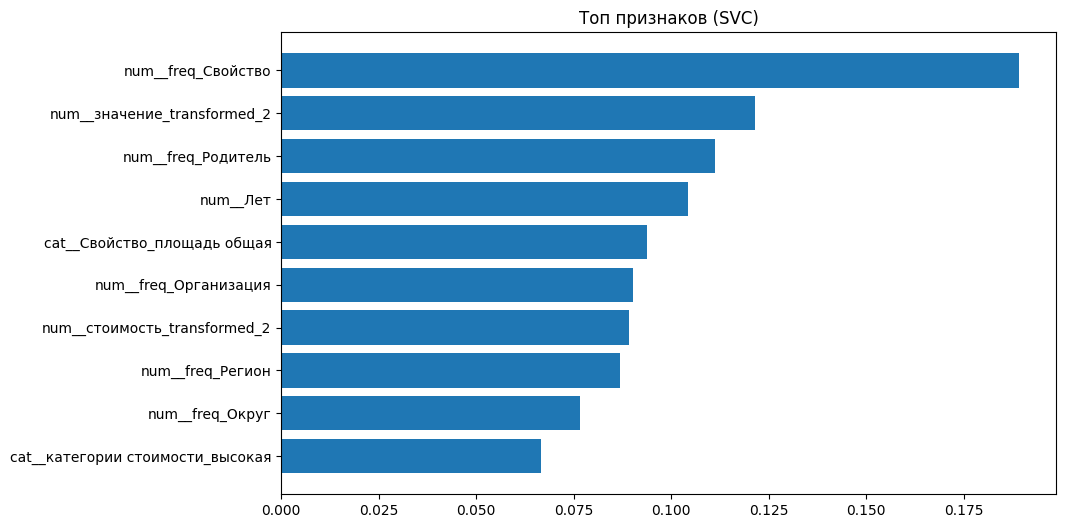

In [32]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (SVC)")
plt.show()

### KNN

In [23]:
knn_model = KNeighborsClassifier(n_jobs=-1)

knn_results = run_experiment(
    knn_model,
    "knn",
    preprocessor_linear,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

knn_results

Запуск: knn + ros
Запуск: knn + ros_shrinkage_005
Запуск: knn + ros_shrinkage_01
Запуск: knn + ros_shrinkage_02
Запуск: knn + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,knn,gaussian_noise,0.2538,0.541,0.004,0.011
3,knn,ros_shrinkage_02,0.2290,0.064,0.002,0.012
2,knn,ros_shrinkage_01,0.2252,0.071,0.002,0.011
1,knn,ros_shrinkage_005,0.2195,0.071,0.002,0.011
0,knn,ros,0.2099,0.012,0.002,0.098


In [33]:
pipe_knn1 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(n_jobs=-1))
])

param_knn_grid1 = {
    'clf__weights': ['uniform', 'distance'],
    'clf__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute']
}

cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=123)

grid_knn1 = GridSearchCV(
    pipe_knn1,
    param_grid=param_knn_grid1,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 8 candidates, totalling 16 fits


In [34]:
print("Лучшие параметры:", grid_knn1.best_params_)
print("Лучшая CV accuracy:", grid_knn1.best_score_)

y_pred = grid_knn1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__algorithm': 'auto', 'clf__weights': 'distance'}
Лучшая CV accuracy: 0.21447864010308257
Test accuracy: 0.28435114503816794
Время: 1.3955588340759277


In [42]:
pipe_knn2 = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', KNeighborsClassifier(
        weights='distance',
        algorithm='auto',
        n_jobs=-1
    ))
])

param_knn2 = {
    'clf__n_neighbors': np.arange(5, 35, 5),
    'clf__metric': ['euclidean', 'manhattan'],
    'clf__leaf_size': np.arange(10, 40, 10)
    }

grid_knn2 = GridSearchCV(
    pipe_knn2,
    param_grid=param_knn2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_knn2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 36 candidates, totalling 360 fits


In [43]:
print("Лучшие параметры:", grid_knn2.best_params_)
print("Лучшая CV accuracy:", grid_knn2.best_score_)

y_pred = grid_knn2.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__leaf_size': np.int64(10), 'clf__metric': 'manhattan', 'clf__n_neighbors': np.int64(5)}
Лучшая CV accuracy: 0.2850290953976371
Test accuracy: 0.26908396946564883
Время: 54.659915924072266


In [37]:
pipe = grid_knn2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
17,pred_Наименование,0.078880
13,Свойство,0.076972
11,freq_Свойство,0.040712
7,значение_transformed_2,0.026081
15,категории стоимости,0.019720
10,freq_Родитель,0.008270
3,if_anomaly,0.007634
6,стоимость_transformed_2,0.005725
2,Значение,0.000000
4,удельная стоимость,0.000000


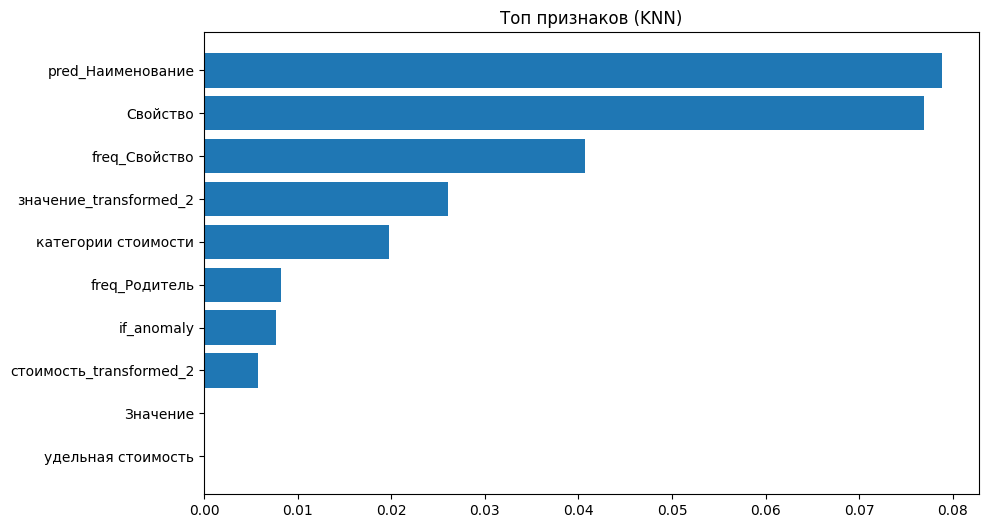

In [44]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (KNN)")
plt.show()

### Decision Tree

In [24]:
tree_model = DecisionTreeClassifier(random_state=123)

tree_results = run_experiment(
    tree_model,
    "tree",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

tree_results

Запуск: tree + ros
Запуск: tree + ros_shrinkage_005
Запуск: tree + ros_shrinkage_01
Запуск: tree + ros_shrinkage_02
Запуск: tree + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
2,tree,ros_shrinkage_01,0.3378,0.011,0.598,0.0
3,tree,ros_shrinkage_02,0.3302,0.012,0.601,0.0
4,tree,gaussian_noise,0.3282,0.018,0.649,0.0
0,tree,ros,0.3244,0.005,0.066,0.0
1,tree,ros_shrinkage_005,0.3206,0.012,0.590,0.0


In [53]:
pipe_tree1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.1)),
    ('clf', DecisionTreeClassifier(
        random_state=123
    ))
])

param_tree_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__splitter': ['best', 'random'],
}

grid_tree1 = GridSearchCV(
    pipe_tree1,
    param_grid=param_tree_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 10 folds for each of 6 candidates, totalling 60 fits


In [54]:
print("Лучшие параметры:", grid_tree1.best_params_)
print("Лучшая CV accuracy:", grid_tree1.best_score_)

y_pred = grid_tree1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'entropy', 'clf__splitter': 'best'}
Лучшая CV accuracy: 0.34150943396226413
Test accuracy: 0.33587786259541985
Время: 2.471721887588501


In [60]:
pipe_tree2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.1)),
    ('clf', DecisionTreeClassifier(
        criterion='entropy',
        splitter='best',
        random_state=123
    ))
])

param_tree_grid2 = {
    'clf__max_depth': [None, 5, 10, 20, 30],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 11, 2),
    'clf__min_samples_leaf': np.arange(1, 11, 2)
}

grid_tree2 = GridSearchCV(
    pipe_tree2,
    param_grid=param_tree_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_tree2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 625 candidates, totalling 1250 fits



In [61]:
print("Лучшие параметры:", grid_tree2.best_params_)
print("Лучшая CV accuracy:", grid_tree2.best_score_)

y_pred = grid_tree2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.8), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.2963446752474407
Test accuracy: 0.32251908396946566
Время: 13.954686880111694


In [62]:
pipe = grid_tree2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
15,cat__Свойство,0.294314
11,num__freq_Свойство,0.185359
2,num__Значение,0.100726
7,num__значение_transformed_2,0.058288
4,num__удельная стоимость,0.046935
6,num__стоимость_transformed_2,0.043288
10,num__freq_Родитель,0.040085
5,num__износ,0.030931
17,cat__pred_Наименование,0.030302
1,num__Стоимость,0.029850


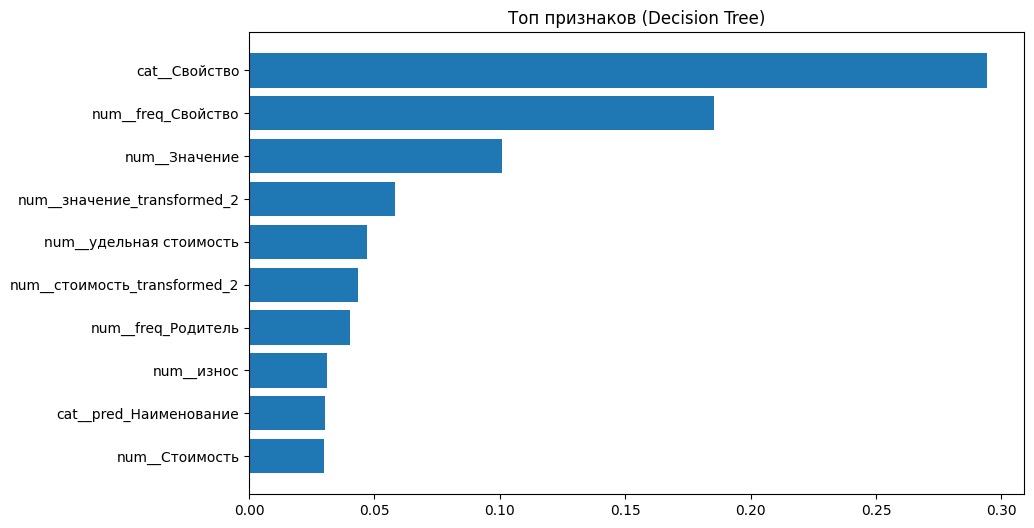

In [63]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Decision Tree)")
plt.show()

### Random Forest

In [25]:
rf_model = RandomForestClassifier(
        n_jobs=-1,
        random_state=123
    )

rf_results1 = run_experiment(
    rf_model,
    "rf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rf_results1

Запуск: rf + ros
Запуск: rf + ros_shrinkage_005
Запуск: rf + ros_shrinkage_01
Запуск: rf + ros_shrinkage_02
Запуск: rf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
0,rf,ros,0.3989,0.006,0.336,0.026
2,rf,ros_shrinkage_01,0.3989,0.012,1.164,0.012
1,rf,ros_shrinkage_005,0.3912,0.012,1.228,0.028
3,rf,ros_shrinkage_02,0.3874,0.011,1.160,0.013
4,rf,gaussian_noise,0.3874,0.012,1.353,0.026


In [182]:
pipe_rf1 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.1)),
    ('clf', RandomForestClassifier(
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid1 = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
}

grid_rf1 = GridSearchCV(
    pipe_rf1,
    param_grid=param_rf_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 3 candidates, totalling 12 fits


In [183]:
print("Лучшие параметры:", grid_rf1.best_params_)
print("Лучшая CV accuracy:", grid_rf1.best_score_)

y_pred = grid_rf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__criterion': 'gini'}
Лучшая CV accuracy: 0.3885125549723365
Test accuracy: 0.3988549618320611
Время: 8.334524154663086


In [82]:
pipe_rf2 = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.1)),
    ('clf', RandomForestClassifier(
        criterion='gini',
        random_state=123,
        n_jobs=-1
    ))
])

param_rf_grid2 = {
    'clf__n_estimators': [50, 100, 150],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__max_samples': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_split': np.arange(2, 9, 2),
    'clf__min_samples_leaf': np.arange(1, 8, 2)
}

grid_rf2 = GridSearchCV(
    pipe_rf2,
    param_grid=param_rf_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_rf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 4 folds for each of 1200 candidates, totalling 4800 fits


In [63]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.5), 'clf__max_samples': np.float64(1.0), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4), 'clf__n_estimators': 100}
Лучшая CV accuracy: 0.39603489856717267
Test accuracy: 0.41412213740458015
Время: 6340.638226032257


In [83]:
print("Лучшие параметры:", grid_rf2.best_params_)
print("Лучшая CV accuracy:", grid_rf2.best_score_)

y_pred = grid_rf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__max_depth': None, 'clf__max_features': np.float64(0.4), 'clf__max_samples': np.float64(1.0), 'clf__min_samples_leaf': np.int64(1), 'clf__min_samples_split': np.int64(4), 'clf__n_estimators': 50}
Лучшая CV accuracy: 0.3922861398779969
Test accuracy: 0.4255725190839695
Время: 4316.905029773712


In [64]:
pipe = grid_rf2.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_rf.head(10)

,feature,importance
2,num__Значение,0.087622
7,num__значение_transformed_2,0.085914
4,num__удельная стоимость,0.080802
17,cat__pred_Наименование,0.077952
10,num__freq_Родитель,0.076203
15,cat__Свойство,0.075448
0,num__Лет,0.069273
1,num__Стоимость,0.063044
11,num__freq_Свойство,0.062741
6,num__стоимость_transformed_2,0.055891


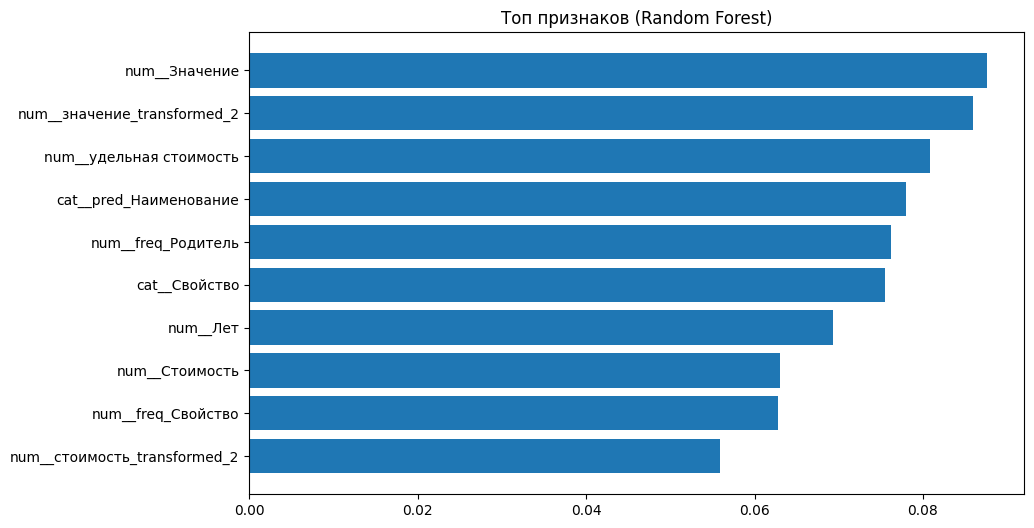

In [65]:
top_n = 10
top_features = feat_imp_rf.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Random Forest)")
plt.show()

### Rotation Forest

In [26]:
rtf_model = RotationForestClassifier(
    base_estimator=DecisionTreeClassifier(random_state=123),
    n_jobs=-1,
    random_state=123
)

rtf_results = run_experiment(
    rtf_model,
    "rtf",
    preprocessor_tree,
    balancers,
    X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

rtf_results

Запуск: rtf + ros
Запуск: rtf + ros_shrinkage_005
Запуск: rtf + ros_shrinkage_01
Запуск: rtf + ros_shrinkage_02
Запуск: rtf + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
2,rtf,ros_shrinkage_01,0.3645,0.012,23.882,0.198
3,rtf,ros_shrinkage_02,0.3645,0.012,23.739,0.222
1,rtf,ros_shrinkage_005,0.3588,0.011,23.554,0.170
4,rtf,gaussian_noise,0.3550,0.013,28.555,0.142
0,rtf,ros,0.3454,0.004,4.810,0.219


In [190]:
pipe_rtf1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.2)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(random_state=123),
        n_jobs=6,
        random_state=123
    ))
])

param_rtf_grid1 = {
    "model__base_estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__base_estimator__splitter": ["best", 'random'],
    "model__pca_solver": ["auto", "full", 'randomized'],
}

grid_rtf1 = GridSearchCV(
    pipe_rtf1,
    param_grid=param_rtf_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_rtf1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 18 candidates, totalling 36 fits


In [191]:
print("Лучшие параметры:", grid_rtf1.best_params_)
print("Лучшая CV accuracy:", grid_rtf1.best_score_)

y_pred = grid_rtf1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__criterion': 'gini', 'model__base_estimator__splitter': 'random', 'model__pca_solver': 'randomized'}
Лучшая CV accuracy: 0.36124739815640794
Test accuracy: 0.366412213740458
Время: 103.50153088569641


In [196]:
pipe_rtf2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.2)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='random',
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=6,
        random_state=123
    ))
])

param_rtf_grid2 = {
    'model__base_estimator__max_depth': [None],
    'model__base_estimator__max_features':np.arange(0.25, 1.25, 0.25), 
    'model__base_estimator__min_samples_split': np.arange(2, 9, 2), 
    'model__base_estimator__min_samples_leaf': np.arange(1, 8, 2)
}

grid_rtf2 = GridSearchCV(
    pipe_rtf2,
    param_grid=param_rtf_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_rtf2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 64 candidates, totalling 128 fits


In [197]:
print("Лучшие параметры:", grid_rtf2.best_params_)
print("Лучшая CV accuracy:", grid_rtf2.best_score_)

y_pred = grid_rtf2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__base_estimator__max_depth': None, 'model__base_estimator__max_features': np.float64(1.0), 'model__base_estimator__min_samples_leaf': np.int64(1), 'model__base_estimator__min_samples_split': np.int64(2)}
Лучшая CV accuracy: 0.36124739815640794
Test accuracy: 0.366412213740458
Время: 119.54758596420288


In [202]:
from imblearn.pipeline import Pipeline

pipe_rtf3 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.2)),
    ("model", RotationForestClassifier(
        base_estimator=DecisionTreeClassifier(criterion='gini',
                                              splitter='random',
                                              max_features=1.0,
                                              max_depth=None,
                                              min_samples_leaf=1,
                                              min_samples_split=2,
                                              random_state=123),
        pca_solver='randomized',
        n_jobs=6,
        random_state=123
    ))
])

param_rtf_grid3 = {
    "model__n_estimators": [50, 100, 200, 300],
    "model__min_group": [1, 2, 3],
    "model__max_group": [1, 2, 3, 4],
    "model__remove_proportion": np.arange(0.2, 1.2, 0.2),
}

grid_rtf3 = GridSearchCV(
    pipe_rtf3,
    param_grid=param_rtf_grid3,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=6,
    verbose=2
)

start_time = time.time()
grid_rtf3.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 240 candidates, totalling 480 fits


In [203]:
print("Лучшие параметры:", grid_rtf3.best_params_)
print("Лучшая CV accuracy:", grid_rtf3.best_score_)

y_pred = grid_rtf3.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_group': 3, 'model__min_group': 1, 'model__n_estimators': 200, 'model__remove_proportion': np.float64(1.0)}
Лучшая CV accuracy: 0.36124208827152626
Test accuracy: 0.3797709923664122
Время: 352.46411395072937


In [204]:
pipe = grid_rtf3.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=8
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,freq_Свойство,0.225191
13,Свойство,0.117048
7,значение_transformed_2,0.050891
15,категории стоимости,0.026718
10,freq_Родитель,0.022901
17,pred_Наименование,0.017812
4,удельная стоимость,0.015267
3,if_anomaly,0.008906
2,Значение,0.008270
9,freq_Организация,0.006997


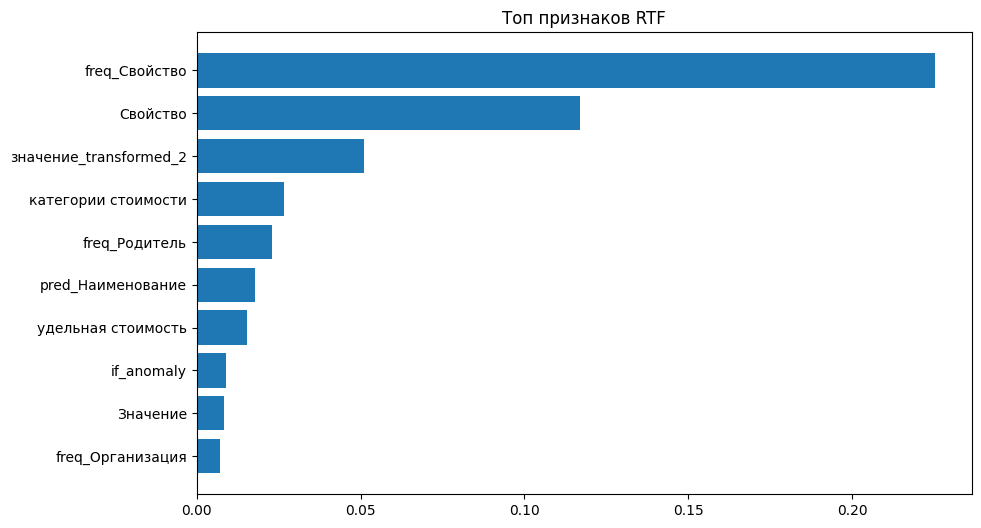

In [205]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков RTF")
plt.show()

### Extra Trees

In [27]:
extra_model = ExtraTreesClassifier(
    n_jobs=-1,
    random_state=123
)

extra_results = run_experiment(
    extra_model,
    "extra",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

extra_results

Запуск: extra + ros
Запуск: extra + ros_shrinkage_005
Запуск: extra + ros_shrinkage_01
Запуск: extra + ros_shrinkage_02
Запуск: extra + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
1,extra,ros_shrinkage_005,0.3721,0.011,0.303,0.015
0,extra,ros,0.3683,0.005,0.115,0.027
4,extra,gaussian_noise,0.3626,0.011,0.140,0.012
2,extra,ros_shrinkage_01,0.3607,0.011,0.271,0.014
3,extra,ros_shrinkage_02,0.3588,0.011,0.220,0.027


In [64]:
from imblearn.pipeline import Pipeline

pipe_extra1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("model", ExtraTreesClassifier(
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid1 = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__bootstrap": [True, False]
}

grid_extra1 = GridSearchCV(
    pipe_extra1,
    param_grid=param_extra_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [65]:
print("Лучшие параметры:", grid_extra1.best_params_)
print("Лучшая CV accuracy:", grid_extra1.best_score_)

y_pred = grid_extra1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__bootstrap': False, 'model__criterion': 'gini'}
Лучшая CV accuracy: 0.34429647565240784
Test accuracy: 0.37213740458015265
Время: 1.2132079601287842


In [72]:
from imblearn.pipeline import Pipeline

pipe_extra2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(shrinkage=0.05, random_state=123)),
    ("model", ExtraTreesClassifier(
        criterion='gini',
        bootstrap=False,
        n_jobs=-1,
        random_state=123
        ))
])

param_extra_grid2 = {
    "model__n_estimators": np.arange(100, 600, 100),
    "model__max_depth": [None],
    'model__max_features': np.arange(0.2, 1.2, 0.2),
    'model__max_samples': [None],
    'model__min_samples_split': np.arange(2, 11, 2),
    'model__min_samples_leaf': np.arange(1, 10, 2)
}

grid_extra2 = GridSearchCV(
    pipe_extra2,
    param_grid=param_extra_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_extra2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 625 candidates, totalling 1250 fits


In [73]:
print("Лучшие параметры:", grid_extra2.best_params_)
print("Лучшая CV accuracy:", grid_extra2.best_score_)

y_pred = grid_extra2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__max_depth': None, 'model__max_features': np.float64(0.4), 'model__max_samples': None, 'model__min_samples_leaf': np.int64(1), 'model__min_samples_split': np.int64(2), 'model__n_estimators': np.int64(300)}
Лучшая CV accuracy: 0.36217485804907745
Test accuracy: 0.38549618320610685
Время: 217.28236603736877


In [74]:
pipe = grid_extra2.best_estimator_

model = pipe.named_steps['model']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_extra = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_extra.head(10)

,feature,importance
17,cat__pred_Наименование,0.091729
7,num__значение_transformed_2,0.084314
4,num__удельная стоимость,0.078445
15,cat__Свойство,0.072005
11,num__freq_Свойство,0.069341
10,num__freq_Родитель,0.062478
6,num__стоимость_transformed_2,0.061041
2,num__Значение,0.060244
13,ord__категории стоимости,0.059118
0,num__Лет,0.057249


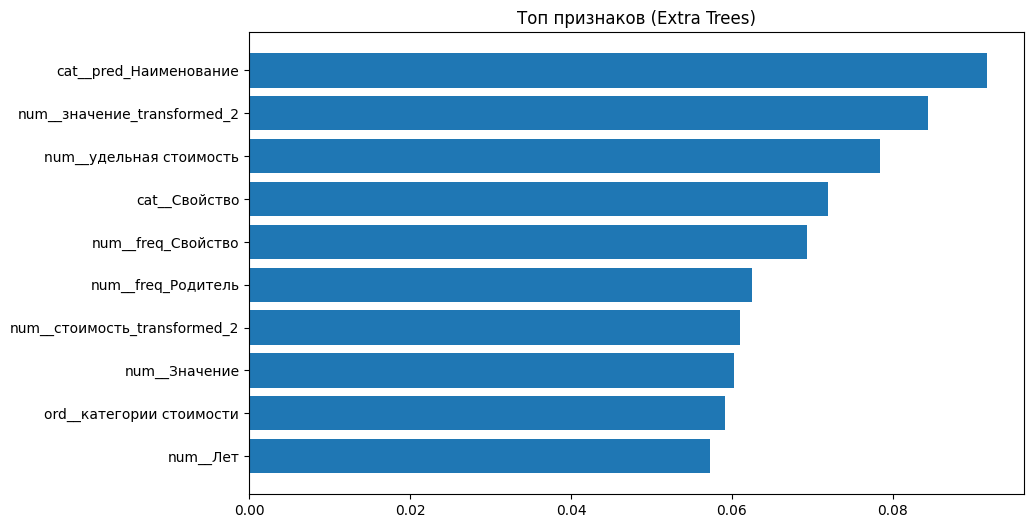

In [75]:
top_n = 10
top_features = feat_imp_extra.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (Extra Trees)")
plt.show()

### Easy Ensemble

In [28]:
easy_model = EasyEnsembleClassifier(
    estimator=DecisionTreeClassifier(random_state=123),
    random_state=123,
    n_jobs=-1
)

easy_results = run_experiment(
    easy_model,
    "easy_ensemble",
    preprocessor_tree,
    balancers,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

easy_results

Запуск: easy_ensemble + ros
Запуск: easy_ensemble + ros_shrinkage_005
Запуск: easy_ensemble + ros_shrinkage_01
Запуск: easy_ensemble + ros_shrinkage_02
Запуск: easy_ensemble + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,easy_ensemble,ros_shrinkage_02,0.3473,0.012,0.903,0.155
4,easy_ensemble,gaussian_noise,0.3397,0.011,0.876,0.142
2,easy_ensemble,ros_shrinkage_01,0.3378,0.012,0.900,0.152
0,easy_ensemble,ros,0.3187,0.004,4.810,0.151
1,easy_ensemble,ros_shrinkage_005,0.3187,0.013,0.878,0.149


In [76]:
from imblearn.pipeline import Pipeline

pipe_easy1 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.2)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid1 = {
    "model__estimator__criterion": ["gini", "entropy", "log_loss"],
    "model__estimator__splitter": ["best", "random"],
    'model__replacement':[True, False]
}

grid_easy1 = GridSearchCV(
    pipe_easy1,
    param_grid=param_easy_grid1,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy1.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 12 candidates, totalling 24 fits


In [77]:
print("Лучшие параметры:", grid_easy1.best_params_)
print("Лучшая CV accuracy:", grid_easy1.best_score_)

y_pred = grid_easy1.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__criterion': 'gini', 'model__estimator__splitter': 'random', 'model__replacement': False}
Лучшая CV accuracy: 0.32831726208175804
Test accuracy: 0.37213740458015265
Время: 3.777501106262207


In [81]:
from imblearn.pipeline import Pipeline

pipe_easy2 = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("balancer", RandomOverSampler(random_state=123, shrinkage=0.2)),
    ("model", EasyEnsembleClassifier(
        estimator=DecisionTreeClassifier(criterion='gini',
                                         splitter='random',
                                         random_state=123),
        replacement=False,
        random_state=123,
        n_jobs=-1
        ))
    ])

param_easy_grid2 = {
    "model__n_estimators": np.arange(100, 600, 100),
    "model__estimator__max_depth": [None],
    'model__estimator__max_features':np.arange(0.2, 1.2, 0.2),
    'model__estimator__min_samples_split': np.arange(2, 11, 2),
    'model__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_easy2 = GridSearchCV(
    pipe_easy2,
    param_grid=param_easy_grid2,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_easy2.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 625 candidates, totalling 1250 fits


In [82]:
print("Лучшие параметры:", grid_easy2.best_params_)
print("Лучшая CV accuracy:", grid_easy2.best_score_)

y_pred = grid_easy2.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'model__estimator__max_depth': None, 'model__estimator__max_features': np.float64(0.4), 'model__estimator__min_samples_leaf': np.int64(1), 'model__estimator__min_samples_split': np.int64(4), 'model__n_estimators': np.int64(500)}
Лучшая CV accuracy: 0.36405809722045224
Test accuracy: 0.37786259541984735
Время: 481.5416820049286


In [83]:
pipe = grid_easy2.best_estimator_

result = permutation_importance(
    pipe,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test.columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,freq_Свойство,0.169211
13,Свойство,0.131679
7,значение_transformed_2,0.031170
10,freq_Родитель,0.019084
4,удельная стоимость,0.018448
17,pred_Наименование,0.015267
15,категории стоимости,0.010178
2,Значение,0.003817
0,Лет,0.003181
3,if_anomaly,0.003181


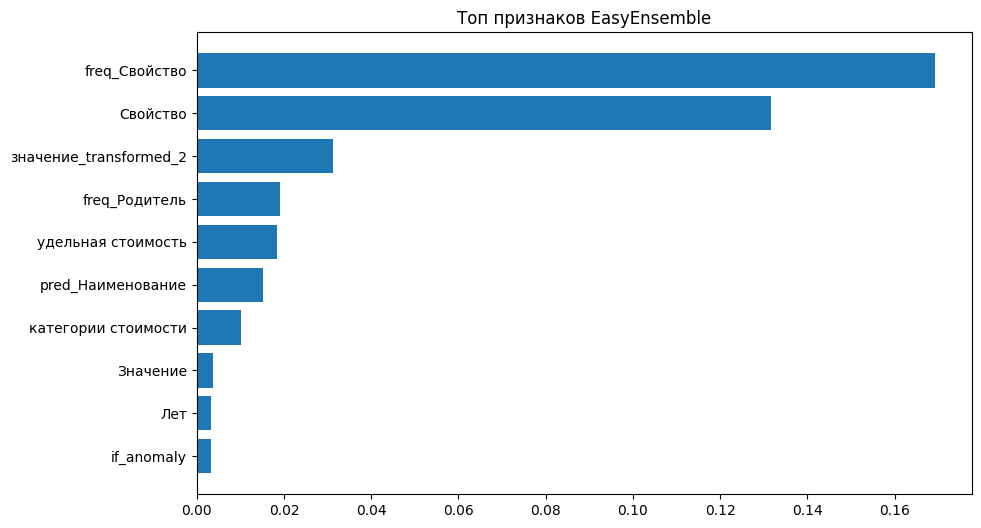

In [84]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков EasyEnsemble")
plt.show()

### HistGradientBoosting

In [29]:
hgb_model = HistGradientBoostingClassifier(        
    n_iter_no_change=1,                
    random_state=123
)

hgb_results = run_experiment(
    hgb_model,
    "hgb",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

hgb_results 

Запуск: hgb + ros
Запуск: hgb + ros_shrinkage_005
Запуск: hgb + ros_shrinkage_01
Запуск: hgb + ros_shrinkage_02
Запуск: hgb + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
3,hgb,ros_shrinkage_02,0.1107,0.012,1.986,0.013
2,hgb,ros_shrinkage_01,0.1050,0.012,2.283,0.027
0,hgb,ros,0.0973,0.005,3.117,0.029
1,hgb,ros_shrinkage_005,0.0897,0.012,2.057,0.013
4,hgb,gaussian_noise,0.0706,0.010,2.048,0.018


In [87]:
pipe_hgb1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.2)),
    ('clf', HistGradientBoostingClassifier(
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid1 = {
    'clf__loss': ['log_loss', 'exponential', 'auto'],
}

grid_hgb1 = GridSearchCV(
    pipe_hgb1,
    param_grid=param_hgb_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_hgb1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 3 folds for each of 3 candidates, totalling 9 fits


In [88]:
print("Лучшие параметры:", grid_hgb1.best_params_)
print("Лучшая CV accuracy:", grid_hgb1.best_score_)

y_pred = grid_hgb1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__loss': 'log_loss'}
Лучшая CV accuracy: 0.0583300177714119
Test accuracy: 0.10877862595419847
Время: 11.482725143432617


In [89]:
pipe_hgb2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', RandomOverSampler(random_state=123, shrinkage=0.2)),
    ('clf', HistGradientBoostingClassifier(
        loss='log_loss',
        n_iter_no_change=1,
        random_state=123
    ))
])

param_hgb_grid2 = {
    'clf__max_iter': [100, 200, 300, 400, 500],
    'clf__learning_rate': [0.01, 0.1],
    'clf__max_depth': [None],
    'clf__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__min_samples_leaf': np.arange(1, 6, 2)
}

grid_hgb2 = GridSearchCV(
    pipe_hgb2,
    param_grid=param_hgb_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_hgb2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 150 candidates, totalling 300 fits


In [90]:
print("Лучшие параметры:", grid_hgb2.best_params_)
print("Лучшая CV accuracy:", grid_hgb2.best_score_)

y_pred = grid_hgb2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__max_depth': None, 'clf__max_features': np.float64(0.2), 'clf__max_iter': 300, 'clf__min_samples_leaf': np.int64(3)}
Лучшая CV accuracy: 0.2474087761777325
Test accuracy: 0.29389312977099236
Время: 1784.9938509464264


In [91]:
pipe = grid_hgb2.best_estimator_

result = permutation_importance(
    pipe,
    X_test[feature_cols],
    y_test,
    n_repeats=3,
    random_state=123,
    n_jobs=-1
)

feature_names = X_test[feature_cols].columns

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

feat_imp.head(10)

,feature,importance
11,Свойство,0.100509
2,Значение,0.075064
4,удельная стоимость,0.067430
7,значение_transformed_2,0.057888
15,pred_Наименование,0.047074
1,Стоимость,0.026718
10,freq_Родитель,0.025445
6,стоимость_transformed_2,0.019720
8,freq_Регион,0.015903
0,Лет,0.009542


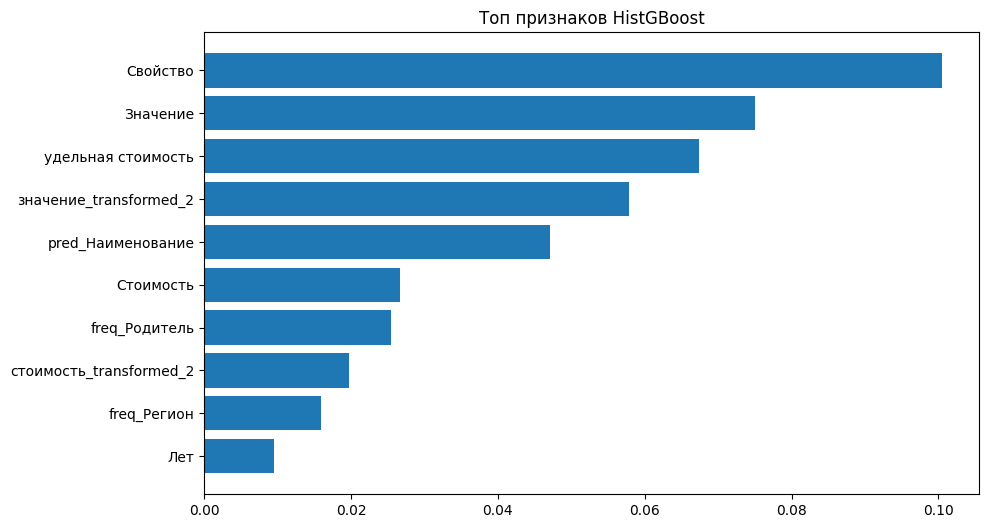

In [92]:
top_n = 10
top_features = feat_imp.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков HistGBoost")
plt.show()

### AdaBoost

In [30]:
ada_model = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    )

ada_results = run_experiment(
    ada_model,
    "ada",
    preprocessor_boost,
    balancers,
    X_train=X_train[feature_cols], X_test=X_test[feature_cols], y_train=y_train, y_test=y_test)

ada_results

Запуск: ada + ros
Запуск: ada + ros_shrinkage_005
Запуск: ada + ros_shrinkage_01
Запуск: ada + ros_shrinkage_02
Запуск: ada + gaussian_noise


,model,balancing,accuracy,balancing_time_sec,train_time_sec,predict_time_sec
4,ada,gaussian_noise,0.2195,0.009,0.861,0.001
0,ada,ros,0.2156,0.005,0.115,0.001
1,ada,ros_shrinkage_005,0.2004,0.011,0.786,0.001
2,ada,ros_shrinkage_01,0.1870,0.011,0.801,0.001
3,ada,ros_shrinkage_02,0.1775,0.011,0.769,0.001


In [105]:
from imblearn.pipeline import Pipeline

pipe_ada1 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=123),
        random_state=123
    ))
])

param_ada_grid1 = {
    'clf__estimator__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__estimator__splitter': ['best', 'random'],
}

grid_ada1 = GridSearchCV(
    pipe_ada1,
    param_grid=param_ada_grid1,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    error_score='raise'
)

start_time = time.time()
grid_ada1.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 6 candidates, totalling 12 fits


In [106]:
print("Лучшие параметры:", grid_ada1.best_params_)
print("Лучшая CV accuracy:", grid_ada1.best_score_)

y_pred = grid_ada1.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__criterion': 'gini', 'clf__estimator__splitter': 'best'}
Лучшая CV accuracy: 0.17873249507950667
Test accuracy: 0.23091603053435114
Время: 1.2076749801635742


In [107]:
pipe_ada2 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid2 = {
    'clf__estimator__max_depth': [None],
    'clf__estimator__max_features': np.arange(0.2, 1.2, 0.2),
    'clf__estimator__min_samples_split': np.arange(2, 11, 2),
    'clf__estimator__min_samples_leaf': np.arange(1, 10, 2)
}

grid_ada2 = GridSearchCV(
    pipe_ada2,
    param_grid=param_ada_grid2,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2
)

start_time = time.time()
grid_ada2.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 125 candidates, totalling 250 fits


In [108]:
print("Лучшие параметры:", grid_ada2.best_params_)
print("Лучшая CV accuracy:", grid_ada2.best_score_)

y_pred = grid_ada2.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__estimator__max_depth': None, 'clf__estimator__max_features': np.float64(0.8), 'clf__estimator__min_samples_leaf': np.int64(3), 'clf__estimator__min_samples_split': np.int64(10)}
Лучшая CV accuracy: 0.2671668578225224
Test accuracy: 0.29961832061068705
Время: 244.45884680747986


In [109]:
from imblearn.pipeline import Pipeline

pipe_ada3 = Pipeline([
    ('preprocessor', preprocessor_boost),
    ('balancer', GaussianNoiseSampler(noise_level=0.05, random_state=123)),
    ('clf', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            criterion='gini',
            splitter='best',
            max_features=0.8,
            max_depth=None,
            min_samples_leaf=3,
            min_samples_split=10,
            random_state=123
        ),
        random_state=123
    ))
])

param_ada_grid3 = {
    'clf__n_estimators': np.arange(100, 600, 100),
    'clf__learning_rate': [0.01, 0.1]
}

grid_ada3 = GridSearchCV(
    pipe_ada3,
    param_grid=param_ada_grid3,
    scoring='accuracy',
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=8,
    verbose=2
)

start_time = time.time()
grid_ada3.fit(X_train[feature_cols], y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 10 candidates, totalling 20 fits


In [110]:
print("Лучшие параметры:", grid_ada3.best_params_)
print("Лучшая CV accuracy:", grid_ada3.best_score_)

y_pred = grid_ada3.predict(X_test[feature_cols])
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__learning_rate': 0.01, 'clf__n_estimators': np.int64(300)}
Лучшая CV accuracy: 0.277512283533693
Test accuracy: 0.3110687022900763
Время: 382.2167148590088


In [111]:
pipe = grid_ada3.best_estimator_

model = pipe.named_steps['clf']
preprocessor = pipe.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

feat_imp_ada = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_ada.head(10)

,feature,importance
13,cat__Свойство,0.105323
4,num__удельная стоимость,0.098140
15,cat__pred_Наименование,0.083596
10,num__freq_Родитель,0.081982
7,num__значение_transformed_2,0.078939
2,num__Значение,0.078226
14,cat__Округ,0.068049
5,num__износ,0.066858
0,num__Лет,0.065438
6,num__стоимость_transformed_2,0.061931


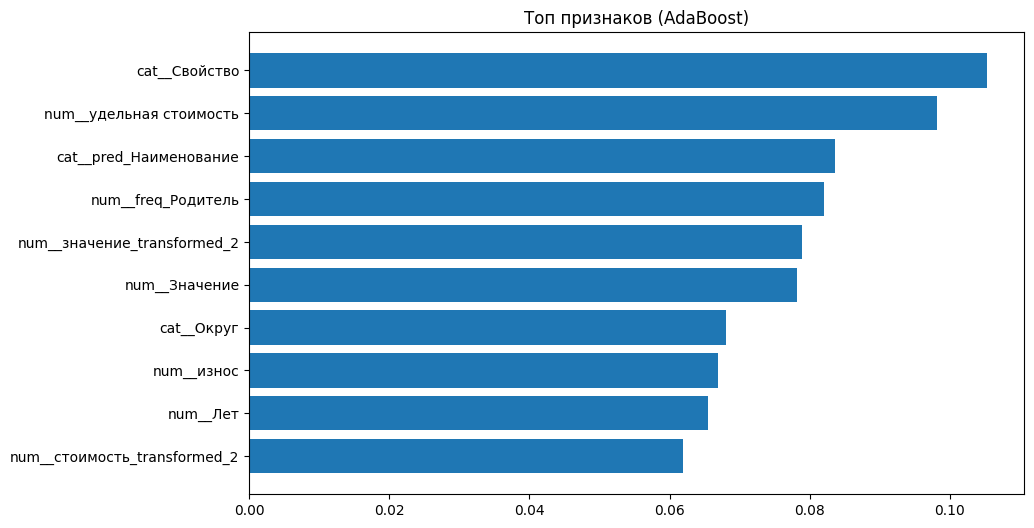

In [112]:
top_n = 10
top_features = feat_imp_ada.head(top_n)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Топ признаков (AdaBoost)")
plt.show()

### Keras (MLP)

In [114]:
def build_keras_model(meta, activation="relu", optimizer="adam",
                      n_size=64, learning_rate=0.01):
    input_dim = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    opt_map = {
        "adam":    Adam(learning_rate=learning_rate),
        "sgd":     SGD(learning_rate=learning_rate),
        "rmsprop": RMSprop(learning_rate=learning_rate),
    }

    model = Sequential([
        Dense(n_size,       activation=activation, input_shape=(input_dim,)),
        Dropout(0.3),
        Dense(n_size // 2,  activation=activation),
        Dense(n_classes,    activation="softmax")
    ])
    model.compile(
        optimizer=opt_map.get(optimizer, Adam(learning_rate)),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [115]:
def run_experiment_keras(
    balancers_dict,
    X_train, y_train,
    X_test,  y_test,
    preprocessor,
    epochs=50,
    batch_size=32
):
    X_train_proc = preprocessor.fit_transform(X_train)
    X_test_proc  = preprocessor.transform(X_test)
    if hasattr(X_train_proc, "toarray"): X_train_proc = X_train_proc.toarray()
    if hasattr(X_test_proc,  "toarray"): X_test_proc  = X_test_proc.toarray()

    results = []

    for bal_name, sampler in balancers_dict.items():
        print(f"keras+{bal_name}")
        try:
            X_bal, y_bal = sampler.fit_resample(X_train_proc, y_train)

            classes = np.unique(y_bal)
            cw      = compute_class_weight("balanced", classes=classes, y=y_bal)
            cw_dict = dict(zip(classes, cw))
            n_classes = len(classes)
            input_dim  = X_bal.shape[1]

            model = Sequential([
                Dense(64,        activation="relu", input_shape=(input_dim,)),
                Dropout(0.3),
                Dense(32,        activation="relu"),
                Dense(n_classes, activation="softmax")
            ])
            model.compile(
                optimizer=Adam(),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"]
            )

            start = time.time()
            model.fit(
                X_bal, y_bal,
                epochs=epochs,
                batch_size=batch_size,
                class_weight=cw_dict,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
                verbose=0
            )
            elapsed = time.time() - start

            y_probs = model.predict(X_test_proc)
            y_pred  = np.argmax(y_probs, axis=1)

            results.append({
                "balancing":      bal_name,
                "accuracy":       accuracy_score(y_test, y_pred),
                "train_time_sec": elapsed
            })
            print(f"  acc={results[-1]['accuracy']:.4f} | t={elapsed:.1f}s")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    if not results:
        print("Все эксперименты вылетели.")
        return pd.DataFrame()

    return pd.DataFrame(results).sort_values("accuracy", ascending=False).reset_index(drop=True)

In [33]:
keras_results = run_experiment_keras(
    balancers_dict=balancers,
    X_train=X_train, y_train=y_train,
    X_test=X_test,   y_test=y_test,
    preprocessor=preprocessor_linear,
    epochs=50,
    batch_size=32
)

keras_results
best_balancer_name = keras_results.iloc[0]["balancing"]
best_sampler       = balancers[best_balancer_name]
print(f"\nЛучшая балансировка: {best_balancer_name}")

keras+ros
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
  acc=0.3569 | t=11.4s
keras+ros_shrinkage_005
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
  acc=0.3683 | t=9.9s
keras+ros_shrinkage_01
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
  acc=0.3664 | t=10.7s
keras+ros_shrinkage_02
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
  acc=0.3664 | t=11.3s
keras+gaussian_noise
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
  acc=0.3664 | t=11.6s

Лучшая балансировка: ros_shrinkage_005


In [123]:
pipe_strings = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        epochs=50,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_strings = {
    "clf__model__activation": ["relu", "tanh", "sigmoid"],
    "clf__model__optimizer":  ["adam", "sgd", "rmsprop"],
}

grid_strings = GridSearchCV(
    pipe_strings,
    param_grid=param_grid_strings,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=1,
    refit=True
)

start = time.time()
grid_strings.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 5 folds for each of 9 candidates, totalling 45 fits


In [124]:
print("Лучшие параметры:", grid_strings.best_params_)
print("Лучшая CV accuracy:", grid_strings.best_score_)

y_pred = grid_strings.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__model__activation': 'sigmoid', 'clf__model__optimizer': 'rmsprop'}
Лучшая CV accuracy: 0.3113650456196297
Test accuracy: 0.34541984732824427
Время: 855.7386109828949


In [149]:
pipe_numeric = ImbPipeline([
    ("prep", preprocessor_linear),
    ("bal",  RandomOverSampler(random_state=123, shrinkage=0.05)),
    ("clf",  KerasClassifier(
        model=build_keras_model,
        model__activation='sigmoid',
        model__optimizer='rmsprop',
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0
    ))
])

param_grid_numeric = {
    "clf__model__n_size":        [64, 128, 256],
    "clf__model__learning_rate": [0.01, 0.1],
    "clf__batch_size":           [32, 64, 128],
    "clf__epochs":               [100, 200, 300],
}

grid_numeric = GridSearchCV(
    pipe_numeric,
    param_grid=param_grid_numeric,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=123),
    n_jobs=-1,
    verbose=2,
    refit=True
)

start = time.time()
grid_numeric.fit(X_train, y_train)
elapsed_time = time.time() - start_time

Fitting 2 folds for each of 54 candidates, totalling 108 fits


In [150]:
print("Лучшие параметры:", grid_numeric.best_params_)
print("Лучшая CV accuracy:", grid_numeric.best_score_)

y_pred = grid_numeric.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Время:", elapsed_time)

Лучшие параметры: {'clf__batch_size': 32, 'clf__epochs': 300, 'clf__model__learning_rate': 0.01, 'clf__model__n_size': 64}
Лучшая CV accuracy: 0.30292008269260723
Test accuracy: 0.3377862595419847
Время: 34524.03656291962


In [151]:
best_model = grid_numeric.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=123,
    scoring='accuracy',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
13,Свойство,0.173664
17,pred_Наименование,0.162214
11,freq_Свойство,0.130407
7,значение_transformed_2,0.066794
10,freq_Родитель,0.054707
14,Округ,0.048346
16,категории возраста,0.047710
15,категории стоимости,0.045802
12,freq_Округ,0.036896
9,freq_Организация,0.035623


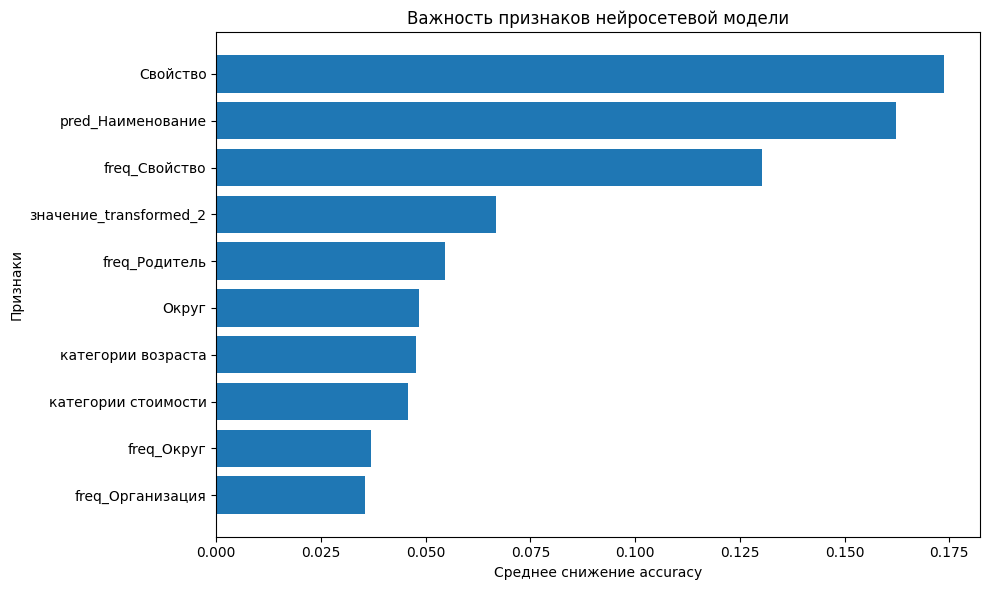

In [152]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"].head(10)[::-1],
    importance_df["importance"].head(10)[::-1]
)

plt.xlabel("Среднее снижение accuracy")
plt.ylabel("Признаки")
plt.title("Важность признаков нейросетевой модели")

plt.tight_layout()
plt.show()

# Экономический эффект

In [3]:
plt.rcParams["figure.figsize"] = (9, 5)

subset_data = pd.DataFrame({
    "Подвыборка": ["м норм", "м редк", "м2 норм", "м2 редк", "м3 норм", "м3 редк", "шт норм", "шт редк", "прочие норм", "прочие редк"],
    "Число объектов": [4684, 673, 1345, 542, 719, 127, 1264, 150, 2818, 286],
    "accuracy": [0.5239, 0.3267, 0.5941, 0.5196, 0.6204, 0.381, 0.8239, 0.72, 0.8676, 0.6526]
})

age_distribution = {
    1: 484, 2: 963, 3: 754, 4: 587, 5: 371, 6: 133, 7: 415, 8: 223, 9: 1069, 10: 967,
    11: 1047, 12: 1120, 13: 1273, 14: 588, 15: 59, 16: 355, 17: 251, 18: 292, 19: 435, 20: 309,
    21: 150, 22: 279, 23: 200, 24: 12, 25: 0, 26: 0, 27: 1, 28: 5, 29: 7, 30: 16,
    31: 21, 32: 0, 33: 4, 34: 2, 35: 1, 36: 4, 37: 1, 38: 2, 39: 2, 40: 3,
    41: 26, 42: 17, 43: 18, 44: 86, 45: 53, 46: 7, 47: 1, 48: 16, 49: 3, 50: 1,
    51: 0, 52: 1, 53: 0, 54: 2, 55: 4, 56: 0, 57: 1, 58: 1, 59: 2, 60: 3,
    61: 0, 62: 0, 63: 3, 64: 4, 65: 4, 66: 1
}

employees = 5
avg_salary = 80_000
months = 1
hours_per_month = 8 * 21

In [4]:
total_objects = int(subset_data["Число объектов"].sum())

manual_hours_total = employees * hours_per_month * months
manual_cost_total = employees * avg_salary * months
cost_per_hour = manual_cost_total / manual_hours_total
manual_minutes_per_object = manual_hours_total * 60 / total_objects

alpha = 1/5  # t_v = alpha * t_m

# t_ai = a_i * t_v + (1 - a_i) * (t_m - t_v)
# делим на t_m чтобы получить долю:
# d_i = a_i * alpha + (1 - a_i) * (1 - alpha)
subset_data["Доля времени после внедрения"] = (
    subset_data["accuracy"] * alpha +
    (1 - subset_data["accuracy"]) * (1 - alpha)
)
subset_data["Доля экономии"] = 1 - subset_data["Доля времени после внедрения"]

subset_data["Ручные чел.-ч"] = (
    manual_hours_total * subset_data["Число объектов"] / total_objects
)
subset_data["Чел.-ч после внедрения"] = (
    subset_data["Ручные чел.-ч"] * subset_data["Доля времени после внедрения"]
)
subset_data["Экономия чел.-ч"] = (
    subset_data["Ручные чел.-ч"] - subset_data["Чел.-ч после внедрения"]
)

subset_data["Ручная стоимость, руб."] = (
    manual_cost_total * subset_data["Число объектов"] / total_objects
)
subset_data["Стоимость после внедрения, руб."] = (
    subset_data["Ручная стоимость, руб."] * subset_data["Доля времени после внедрения"]
)
subset_data["Экономия, руб."] = (
    subset_data["Ручная стоимость, руб."] - subset_data["Стоимость после внедрения, руб."]
)

weighted_accuracy = (
    subset_data["Число объектов"] * subset_data["accuracy"]
).sum() / total_objects

weighted_post_share = (
    subset_data["Число объектов"] * subset_data["Доля времени после внедрения"]
).sum() / total_objects

saved_share = 1 - weighted_post_share
saved_hours_total = manual_hours_total * saved_share
saved_cost_total = manual_cost_total * saved_share

In [5]:
age_df = pd.DataFrame({
    "Лет": list(age_distribution.keys()),
    "Число объектов": list(age_distribution.values())
}).sort_values("Лет")

annual_windows = []
for window in [5, 10, 15, 20, 25, 30]:
    annual_windows.append({
        "Окно, лет": window,
        "Среднее объектов в год": age_df.loc[age_df["Лет"] <= window, "Число объектов"].mean()
    })
annual_windows_df = pd.DataFrame(annual_windows)

annual_scenarios = pd.DataFrame({
    "Сценарий": annual_windows_df["Среднее объектов в год"].round().astype(int).astype(str) + " об/год",
    "Объектов в год": annual_windows_df["Среднее объектов в год"].round().astype(int)
})
annual_scenarios["Ручные чел.-ч"] = (
    manual_hours_total * annual_scenarios["Объектов в год"] / total_objects
)
annual_scenarios["Экономия чел.-ч"] = (
    annual_scenarios["Ручные чел.-ч"] * saved_share
)
annual_scenarios["Экономия, руб."] = (
    annual_scenarios["Экономия чел.-ч"] * cost_per_hour
)

summary_df = pd.DataFrame({
    "Показатель": [
        "Число сотрудников",
        "Средняя зарплата, руб./мес.",
        "Период расчета, мес.",
        "Трудозатраты вручную, чел.-ч",
        "Совокупные затраты вручную, руб.",
        "Число объектов",
        "Среднее время вручную на 1 объект, мин",
        "Время проверки результата модели на 1 объект, мин",
        "Средневзвешенная accuracy",
        "Средняя доля времени после внедрения",
        "Средняя доля экономии",
        "Экономия трудозатрат, чел.-ч",
        "Экономия денежных средств, руб."
    ],
    "Значение": [
        employees, avg_salary, months,
        manual_hours_total, manual_cost_total, total_objects,
        manual_minutes_per_object,
        round(manual_minutes_per_object * alpha, 3),
        weighted_accuracy, weighted_post_share,
        saved_share, saved_hours_total, saved_cost_total
    ]
})

In [6]:
summary_df

,Показатель,Значение
0,Число сотрудников,5.000000
1,"Средняя зарплата, руб./мес.",80000.000000
2,"Период расчета, мес.",1.000000
3,"Трудозатраты вручную, чел.-ч",840.000000
4,"Совокупные затраты вручную, руб.",400000.000000
5,Число объектов,12608.000000
6,"Среднее время вручную на 1 объект, мин",3.997462
7,"Время проверки результата модели на 1 объект, мин",0.799000
8,Средневзвешенная accuracy,0.636890
9,Средняя доля времени после внедрения,0.417866


In [7]:
annual_windows_df

,"Окно, лет",Среднее объектов в год
0,5,631.800000
1,10,596.600000
2,15,670.200000
3,20,584.750000
4,25,493.440000
5,30,412.166667


In [8]:
annual_scenarios

,Сценарий,Объектов в год,Ручные чел.-ч,Экономия чел.-ч,"Экономия, руб."
0,632 об/год,632,42.106599,24.511683,11672.229835
1,597 об/год,597,39.774746,23.154232,11025.824701
2,670 об/год,670,44.638325,25.985486,12374.041122
3,585 об/год,585,38.975254,22.688820,10804.200084
4,493 об/год,493,32.845812,19.120664,9105.078020
5,412 об/год,412,27.449239,15.979135,7609.111854


In [9]:
def rub_formatter(x, pos):
    return f'{int(x):,}'.replace(',', ' ')

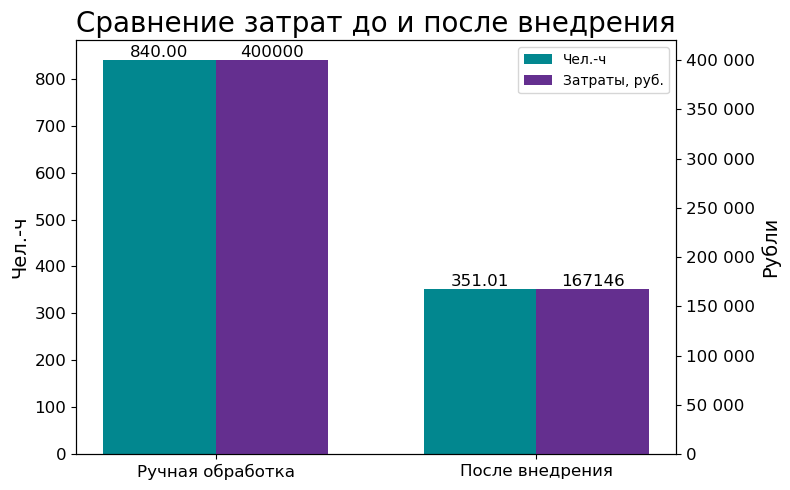

In [10]:
compare_df = pd.DataFrame({
    "Этап": ["Ручная обработка", "После внедрения"],
    "Стоимость, руб.": [manual_cost_total, manual_cost_total - saved_cost_total],
    "Чел.-ч": [manual_hours_total, manual_hours_total - saved_hours_total]
})

fig, ax1 = plt.subplots(figsize=(8, 5))
x = range(len(compare_df))
width = 0.35

bars1 = ax1.bar([i - width/2 for i in x], compare_df["Чел.-ч"],
                width=width, color='#02878F', label='Чел.-ч')
ax1.bar_label(bars1, fmt="%.2f", fontsize=12, color='black')
ax1.set_ylabel("Чел.-ч", color='black', fontsize=14)
ax1.tick_params(axis='x', labelsize=12)
ax1.tick_params(axis='y', labelsize=12)
ax1.set_xticks(list(x))
ax1.set_xticklabels(compare_df["Этап"])

ax2 = ax1.twinx()
bars2 = ax2.bar([i + width/2 for i in x], compare_df["Стоимость, руб."],
                width=width, color='#642F8F', label='Затраты, руб.')
ax2.bar_label(bars2, fmt="%.0f", fontsize=12, color='black')
ax2.set_ylabel("Рубли", color='black', fontsize=14)

ax2.yaxis.set_major_formatter(FuncFormatter(rub_formatter))

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
ax1.set_title("Сравнение затрат до и после внедрения", color='black', fontsize=20)
ax1.set_xlabel("")
ax1.set_ylabel("Чел.-ч", color='black', fontsize=14)
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)
plt.tight_layout()
plt.show()


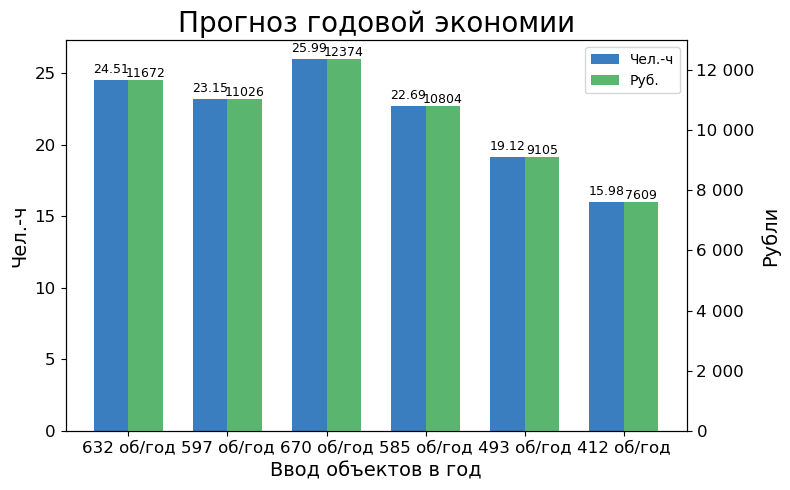

In [11]:
fig, ax1 = plt.subplots(figsize=(8, 5))
x = range(len(annual_scenarios))
width = 0.35

bars1 = ax1.bar([i - width/2 for i in x], annual_scenarios["Экономия чел.-ч"],
                width=width, color='#3a7ebf', label='Чел.-ч')
ax1.bar_label(bars1, fmt="%.2f", padding=3, fontsize=9, color='black')
ax1.set_ylabel("Чел.-ч", color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.tick_params(axis='x', labelcolor='black')
ax1.set_xticks(list(x))
ax1.set_xticklabels(annual_scenarios["Сценарий"], ha='right')

ax2 = ax1.twinx()
bars2 = ax2.bar([i + width/2 for i in x], annual_scenarios["Экономия, руб."],
                width=width, color='#5ab56e', label='Руб.')
ax2.bar_label(bars2, fmt="%.0f", fontsize=9, color='black')
ax2.set_ylabel("Рубли", color='black', fontsize=14)
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)
ax2.yaxis.set_major_formatter(FuncFormatter(rub_formatter))

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)
ax1.set_title("Прогноз годовой экономии", color='black', fontsize=20)
ax1.set_xlabel("Ввод объектов в год", color='black', fontsize=14)
ax1.set_ylabel("Чел.-ч", color='black', fontsize=14)
ax1.tick_params(axis='x', labelsize=12)
ax1.tick_params(axis='y', labelsize=12)
ax1.set_xticklabels(annual_scenarios["Сценарий"], ha='center', rotation=0)
plt.tight_layout()
plt.show()
